# Task 5 — Account Security Monitoring

## 0. Problem and Approach

### 0.1 Business Problem

Karena Thailand faces over 5,000 confirmed account thefts monthly (actual number likely 2x higher), making it the #1 customer support issue consuming 60% of team resources. Beyond theft, sophisticated account selling rings destroy competitive integrity, bot farms operate 24/7 causing game economy inflation, and players exploit VPNs for regional pricing (70% discounts), costing millions of baht annually. The current rule-based security system has 60% false positive rate—flagging legitimate travelers while missing smart attackers who wait 24 hours between actions. Simple thresholds flag players who legitimately improve while missing gradual botting patterns. The security team drowns in alerts while real threats slip through. The company needs an intelligent unsupervised anomaly detection system that learns normal behavior patterns and flags truly unusual activities without rigid rules or labeled data.

### 0.2 Task, Data, and Metric

Task 5 asks for one binary prediction per player: `1` marks an anomalous account (for example a stolen, resold, botted, or abused account) and `0` a normal one. The competition supplies a single unlabeled file, `test.csv`, with **25,889 players** and **122 numeric features**. Most features are measured over four consecutive periods (`_1` to `_4`), so every player has a short behavior history. No `is_anomaly` column exists anywhere, which makes this a genuinely unsupervised problem.

Kaggle scores Task 5 with **macro F₃**. F₃ treats recall as three times as important as precision within a class, and the macro average gives the anomaly class and the normal class equal weight. Missing true anomalies is therefore expensive, while flagging too many normal players also lowers the normal-class score. Kaggle reports only one overall score for all five tasks, never a separate Task 5 F₃.

### 0.3 Rules and Constraints

- Only competition data is used. Task 5 models are trained from scratch; no pre-trained model, external data, or AutoML framework is used.
- The written competition rules reserve Test for prediction. For Task 5, however, the unlabeled Test file is the only data supplied, and the lecturer clarified that fitting unsupervised models on it is permitted. Both statements are recorded here so the choice is explicit.
- The lecturer also warned against using repeated leaderboard submissions to harvest label information. Submissions are therefore treated as a scarce resource: a candidate is submitted only when its alert set differs enough from earlier submissions to test a distinct idea, and a public score is never used to fit a model, select features, or tune an alert cutoff.

### 0.4 How Models Are Judged Without Labels

Without labels, no offline F₃, precision, or recall can be computed. The notebook uses three kinds of evidence, each introduced where it is first needed:

1. **Internal ranking diagnostics** on a fixed held-out player split (Section 6): how strongly two models' top-ranked players overlap, how stable a ranking is when the fit rows change, and which behavior groups and data-quality flags the top players come from. These describe how a model behaves, not whether it is right.
2. **Swap analysis against earlier submissions** (from Round 3 onward): how many alerts a new candidate adds or removes, and what kind of players move. This decides whether a candidate tests a new idea and is worth a submission slot.
3. **Public leaderboard results** for the few submitted candidates, followed by an error analysis that asks why the score moved.

Every submitted file shares the same Tasks 1–4 answers (the team's base submission, loaded in Section 9.4.3) and flags the same budget of **2,046** players (7.9%), so a change in public score comes only from which players Task 5 selects. From Round 9 on, the comparison tables use a *reference panel* of earlier selections, so a candidate is described by what it adds.

### 0.5 Notebook Roadmap

Sections 1–5 load, audit, explore, and prepare the data. Section 3 ends with the hypotheses that drive the experiments. Section 6 fixes the evaluation method. Sections 7–24 are eighteen experiment rounds in the order they were run. Every round uses the same five steps: **Hypothesis → Model → Analysis → Submission and Result → Findings and Next Hypothesis**, so each result motivates the next idea. Section 25 is the final summary: the experiment path, key findings, and the final submission choice.

| Round | Section | Question | Submitted |
| --- | --- | --- | --- |
| 1 | 7 | Does the feature representation change what Isolation Forest flags? | No |
| 2 | 8 | Do security flags, quality flags, or fewer temporal features change it further? | No |
| 3 | 9 | Which detector family gives a stable, distinct ranking? | Yes (Empirical Tail) |
| 4 | 10 | Do players break cross-period patterns that a masked model can learn? | Yes |
| 5 | 11 | Do predicted security events identify anomalies? | Yes |
| 6 | 12 | Does removing extreme players from the Tail reference sharpen it? | Yes (5% trim) |
| 7 | 13 | Does missing-value handling change the trimmed Tail ranking? | No |
| 8 | 14 | Do separate boundaries for different player cohorts help One-Class SVM? | Yes |
| 9 | 15 | Do non-linear multi-feature relationships expose anomalies that are not extreme? | No |
| 10 | 16 | Do joint Period-4 jumps inside data-discovered feature modules add new anomalies? | No |
| 11 | 17 | Free-slot probes: does a new direction or a global trimmed boundary beat the cohort model? | Yes (both) |
| 12 | 18 | Does a second detector for persistently low engagement catch a different anomaly mechanism? | Yes |
| 13 | 19 | Do label-free mechanism populations, each sized by its own evidence, beat equal-weight experts? | Yes |
| 14 | 20 | Do latent directions of moderate, coordinated shifts reveal mechanisms that no tail rule sees? | Yes |
| 15 | 21 | Does one model of dependence between behavior families see every mechanism at once? | Yes (both) |
| 16 | 22 | Is any label-free signal left outside the alerts, or does the alert budget limit the score? | Yes (budget test) |
| 17 | 23 | Do focused, fine-scale, takeover, or cohort-conditional models find a population the ratio model misses? | Yes |
| 18 | 24 | Which groups of players separate good models from weaker ones? | Yes |

## 1. Data Import and Verification

The competition supplies only an unlabeled `test.csv` for Task 5. This section loads the file and checks its structure and basic data quality. No fitting, feature engineering, or predictions are performed here.

### 1.1 Setup and Import

Find the project root by searching upward for the raw Task 5 file, fix one random seed for the whole notebook, and load the data. Every random operation below receives `SEED` explicitly.

In [1]:
import random
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

RAW_RELATIVE = Path("src") / "task5" / "data" / "raw"
ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents)
             if (path / RAW_RELATIVE / "test.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook inside the project folder: "
                            "src/task5/data/raw/test.csv was not found here or in any parent folder.")
RAW = ROOT / RAW_RELATIVE
ID = "player_id"
TARGET = "is_anomaly"
print(f"Project root found | raw data folder: {RAW.relative_to(ROOT)} | seed: {SEED}")

Project root found | raw data folder: src\task5\data\raw | seed: 42


In [2]:
test_path = RAW / "test.csv"
datacard_path = RAW / "datacard.txt"
assert test_path.is_file() and datacard_path.is_file()

test_raw = pd.read_csv(test_path)
feature_cols = [column for column in test_raw.columns if column != ID]

print("Source:", test_path.relative_to(ROOT))
print("Data card:", datacard_path.relative_to(ROOT))
print("Shape:", test_raw.shape)
display(test_raw.head())

Source: src\task5\data\raw\test.csv
Data card: src\task5\data\raw\datacard.txt
Shape: (25889, 123)


,player_id,login_count_1,login_count_2,login_count_3,login_count_4,login_lat_1,login_lon_1,login_lat_2,login_lon_2,login_lat_3,...,guild_changes_1,guild_changes_2,guild_changes_3,guild_changes_4,account_age_days,behavior_stability,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,P024743,67.238336,27.598368,38.114171,45.320790,-55.660805,47.357425,-55.442687,46.861868,-55.882950,...,1.0,1.0,2.0,1.0,1027.683779,0.232040,0.0,0.0,0.0,1.0
1,P005319,21.039249,28.153000,20.788758,20.483913,44.210837,26.034926,43.930301,26.515108,43.442722,...,1.0,NaN,2.0,1.0,1450.873210,0.918705,0.0,1.0,0.0,0.0
2,P014970,90.268461,109.156193,96.764974,96.542496,37.371864,33.819993,37.351600,33.503336,37.044372,...,0.0,-1.0,-1.0,0.0,611.275151,0.764911,0.0,0.0,0.0,0.0
3,P003275,29.880876,28.448716,24.296107,24.403403,48.026437,-119.863672,47.992586,-118.485494,48.123361,...,2.0,1.0,2.0,2.0,404.103143,0.712205,0.0,0.0,0.0,0.0
4,P009022,62.283808,73.703985,48.331688,71.803417,39.647200,154.007807,39.675523,154.225136,38.851983,...,0.0,0.0,0.0,1.0,1091.671684,0.896939,0.0,0.0,0.0,0.0


### 1.2 Basic Verification

The data card lists 122 numeric predictors plus `player_id`, and the target must be absent. The checks below confirm the shape, ID uniqueness, numeric types, finite values, and overall missingness. Detailed missing-value and range audits follow in Section 2.

In [3]:
assert len(test_raw) == 25_889
assert test_raw.shape[1] == 123
assert test_raw.columns[0] == ID
assert len(feature_cols) == 122
assert TARGET not in test_raw.columns
assert test_raw[ID].notna().all() and test_raw[ID].is_unique
assert all(pd.api.types.is_numeric_dtype(test_raw[column]) for column in feature_cols)
assert not np.isinf(test_raw[feature_cols].to_numpy()).any()

missing_per_row = test_raw[feature_cols].isna().sum(axis=1)
summary = pd.DataFrame([{
    "rows": len(test_raw),
    "numeric_features": len(feature_cols),
    "duplicate_rows": int(test_raw.duplicated().sum()),
    "duplicate_player_ids": int(test_raw[ID].duplicated().sum()),
    "missing_feature_cells": int(test_raw[feature_cols].isna().sum().sum()),
    "rows_with_missing_features": int((missing_per_row > 0).sum()),
    "fully_missing_feature_rows": int((missing_per_row == len(feature_cols)).sum()),
    "infinite_feature_cells": int(np.isinf(test_raw[feature_cols].to_numpy()).sum()),
    "target_present": TARGET in test_raw.columns,
}])
display(summary)

,rows,numeric_features,duplicate_rows,duplicate_player_ids,missing_feature_cells,rows_with_missing_features,fully_missing_feature_rows,infinite_feature_cells,target_present
0,25889,122,0,0,154112,25830,0,0,False


## 2. Data Quality Check

The sections below audit data quality, summarize findings, and apply a documented cleaning step. The raw dataset remains unchanged, and no account is identified as an anomaly.

### 2.1 Feature Summary

Show the observed minimum, maximum, and average of every numeric predictor. Missing values are excluded from these summaries; extreme values are retained for inspection.

In [4]:
feature_describe = test_raw[feature_cols].agg(["min", "max", "mean"]).T
feature_describe = feature_describe.rename(columns={"mean": "avg"})
print(feature_describe.to_string(float_format=lambda value: f"{value:,.4g}"))

                                 min    max      avg
login_count_1                  8.035  118.7     59.3
login_count_2                  7.751  128.3     59.4
login_count_3                  7.631  123.6    59.29
login_count_4                  9.149  113.7    59.26
login_lat_1                   -61.04  61.09  -0.3283
login_lon_1                   -180.6  181.8  -0.3347
login_lat_2                   -61.04  61.01  -0.2362
login_lon_2                   -181.9  180.7  -0.4949
login_lat_3                   -85.39  89.82  -0.1201
login_lon_3                   -237.3    225  -0.4482
login_lat_4                   -106.1  139.7   0.4257
login_lon_4                   -222.6  273.8   0.5124
location_changes_1         0.0001492  4.447    1.495
location_changes_2         0.0001023   4.18    1.492
location_changes_3         0.0001022  3.891    1.493
location_changes_4         0.0001231  19.91    1.696
device_count_1                     1      2    1.493
device_count_2                     0      3   

### 2.2 Structural Integrity

Check the dataset grain, duplicate feature rows, binary encoding, and low-variation features. This is an audit only; no rows or values are changed. A conflicting-label check is not applicable because `is_anomaly` is absent from the file.

In [5]:
security_flags = ["password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale"]
binary_check_rows = []
for column in security_flags:
    observed = sorted(test_raw[column].dropna().unique().tolist())
    invalid = int((test_raw[column].notna() & ~test_raw[column].isin([0, 1])).sum())
    binary_check_rows.append({"feature": column, "observed_values": observed, "invalid_values": invalid})
binary_check = pd.DataFrame(binary_check_rows)
assert all(pd.api.types.is_numeric_dtype(test_raw[column]) for column in feature_cols)
print(f"ID dtype: {test_raw[ID].dtype} | numeric predictors: {len(feature_cols)}\n{binary_check.to_string(index=False)}")

ID dtype: object | numeric predictors: 122
              feature observed_values  invalid_values
     password_changed      [0.0, 1.0]               0
            vpn_usage      [0.0, 1.0]               0
suspicious_login_time      [0.0, 1.0]               0
       mass_item_sale      [0.0, 1.0]               0


In [6]:
id_missing = int(test_raw[ID].isna().sum())
id_duplicates = int(test_raw[ID].duplicated().sum())
print(f"Rows: {len(test_raw):,} | unique player_id: {test_raw[ID].nunique():,} | missing IDs: {id_missing} | duplicate IDs: {id_duplicates}. Observed grain: one row per unique player_id, with four-period measurements in its columns.")

Rows: 25,889 | unique player_id: 25,889 | missing IDs: 0 | duplicate IDs: 0. Observed grain: one row per unique player_id, with four-period measurements in its columns.


In [7]:
predictor_cols = [column for column in test_raw.columns if column not in {ID, TARGET}]
duplicate_feature_rows = int(test_raw.duplicated(subset=predictor_cols, keep=False).sum())
extra_duplicate_rows = int(test_raw.duplicated(subset=predictor_cols).sum())
print(f"Identical predictor rows across different IDs: {duplicate_feature_rows:,} rows in duplicate groups; {extra_duplicate_rows:,} rows beyond the first in each group.")

Identical predictor rows across different IDs: 0 rows in duplicate groups; 0 rows beyond the first in each group.

In [8]:
variation_rows = []
for column in feature_cols:
    observed = test_raw[column].dropna()
    counts = observed.value_counts(normalize=True)
    dominant_share = float(counts.iloc[0]) if len(counts) else np.nan
    unique_values = int(observed.nunique())
    if unique_values <= 1 or dominant_share >= 0.99:
        variation_rows.append({"feature": column, "unique_nonmissing": unique_values,
                               "dominant_share_pct": round(100 * dominant_share, 2),
                               "status": "constant" if unique_values <= 1 else "near-constant"})
variation_check = pd.DataFrame(variation_rows)
print(f"Constant / near-constant features (>=99% same value among observed rows): {len(variation_check)}\n{variation_check.to_string(index=False) if len(variation_check) else 'None'}")

Constant / near-constant features (>=99% same value among observed rows): 0
None


### 2.3 Missing Value Integrity

Inspect how missing values are distributed across features and periods. Candidate sentinel values are reported for review, not automatically converted to missing.

In [9]:
missing = test_raw[feature_cols].isna().sum().sort_values(ascending=False)
missing_table = pd.DataFrame({"missing_rows": missing, "missing_pct": 100 * missing / len(test_raw)})
row_missing = test_raw[feature_cols].isna().sum(axis=1)
print(f"Missing cells: {int(missing.sum()):,} | rows with any missing: {int((row_missing > 0).sum()):,} | median missing per row: {row_missing.median():.0f}\nAll features:\n{missing_table.round(2).to_string()}")

Missing cells: 154,112 | rows with any missing: 25,830 | median missing per row: 6
All features:
                            missing_rows  missing_pct
password_changed                    1363         5.26
communication_frequency_2           1353         5.23
purchase_amount_std_2               1326         5.12
session_duration_mean_1             1324         5.11
reaction_time_std_2                 1319         5.09
login_lon_1                         1319         5.09
login_time_variance_2               1314         5.08
performance_stability_4             1312         5.07
currency_transfers_2                1312         5.07
ip_hash_entropy_4                   1311         5.06
accuracy_std_4                      1310         5.06
mass_item_sale                      1308         5.05
skill_trajectory_4                  1308         5.05
login_lon_4                         1308         5.05
play_pattern_consistency_4          1302         5.03
play_pattern_consistency_2          130

In [10]:
temporal_families = [
    column[:-2] for column in feature_cols
    if column.endswith("_1") and all(f"{column[:-2]}_{period}" in feature_cols for period in range(1, 5))
]
missing_pattern_rows = []
for family in temporal_families:
    mask = test_raw[[f"{family}_{period}" for period in range(1, 5)]].isna()
    count = mask.sum(axis=1)
    missing_pattern_rows.append({"family": family, "all_4_missing": int((count == 4).sum()),
                                 "some_missing": int(count.between(1, 3).sum()),
                                 "none_missing": int((count == 0).sum())})
missing_patterns = pd.DataFrame(missing_pattern_rows)
print(f"Four-period families: {len(missing_patterns)}\n{missing_patterns.to_string(index=False)}")

Four-period families: 29
                  family  all_4_missing  some_missing  none_missing
             login_count              0          4650         21239
               login_lat              0          4617         21272
               login_lon              0          4793         21096
        location_changes              0          4694         21195
            device_count              0          4622         21267
         ip_hash_entropy              0          4758         21131
     login_time_variance              1          4737         21151
   session_duration_mean              0          4757         21132
    session_duration_std              0          4715         21174
            skill_rating              0          4710         21179
        skill_trajectory              1          4805         21083
play_pattern_consistency              0          4744         21145
          activity_level              1          4711         21177
                kda_mea

In [11]:
sentinel_rows = []
for value in [-999, -1, 999, 9999]:
    counts = test_raw[feature_cols].eq(value).sum()
    for column, count in counts[counts > 0].items():
        sentinel_rows.append({"feature": column, "candidate_value": value, "rows": int(count)})
sentinel_table = pd.DataFrame(sentinel_rows)
unknown_columns = [column for column in feature_cols if not pd.api.types.is_numeric_dtype(test_raw[column])]
print(f"Candidate sentinel occurrences: {sum(row['rows'] for row in sentinel_rows):,} | nonnumeric predictor columns (possible text placeholders): {unknown_columns}\n{sentinel_table.sort_values('rows', ascending=False).head(15).to_string(index=False) if len(sentinel_table) else 'No -999, -1, 999, or 9999 values found.'}")

Candidate sentinel occurrences: 13,605 | nonnumeric predictor columns (possible text placeholders): []
        feature  candidate_value  rows
 refund_count_3               -1  4141
 refund_count_2               -1  4044
guild_changes_3               -1  2722
guild_changes_2               -1  2698

### 2.4 Temporal Integrity

The `_1`–`_4` columns are consecutive periods according to the data card. A flatline may be real stable behavior; the file contains no timestamps establishing which endpoint is newest.

In [12]:
flatline_rows = []
for family in temporal_families:
    values = test_raw[[f"{family}_{period}" for period in range(1, 5)]]
    complete = values.notna().all(axis=1)
    flatline = complete & values.nunique(axis=1).eq(1)
    flatline_rows.append({"family": family, "fully_observed": int(complete.sum()),
                          "flatline_rows": int(flatline.sum()),
                          "flatline_pct_of_observed": round(100 * flatline.sum() / max(int(complete.sum()), 1), 2)})
flatline_table = pd.DataFrame(flatline_rows).sort_values("flatline_rows", ascending=False)
print(f"Top 12 four-period flatlines (descriptive, not errors):\n{flatline_table.head(12).to_string(index=False)}")

Top 12 four-period flatlines (descriptive, not errors):
               family  fully_observed  flatline_rows  flatline_pct_of_observed
       friend_removes           21257           4217                     19.84
         device_count           21267           1302                      6.12
         refund_count           21238           1200                      5.65
        guild_changes           21197           1153                      5.44
          friend_adds           21207           1043                      4.92
      ip_hash_entropy           21131              0                      0.00
  login_time_variance           21151              0                      0.00
session_duration_mean           21132              0                      0.00
 session_duration_std           21174              0                      0.00
          login_count           21239              0                      0.00
            login_lat           21272              0                      0

In [13]:
period_counts = {period: sum(f"{family}_{period}" in test_raw.columns for family in temporal_families)
                 for period in range(1, 5)}
complete_families = sum(all(f"{family}_{period}" in test_raw.columns for period in range(1, 5))
                        for family in temporal_families)
dtype_mismatches = [family for family in temporal_families
                    if len({str(test_raw[f"{family}_{period}"].dtype) for period in range(1, 5)}) > 1]
print(f"Temporal columns by period: {period_counts} | complete four-period families: {complete_families}/{len(temporal_families)} | families with inconsistent period dtypes: {dtype_mismatches}. The data card says periods are consecutive but provides no timestamps or newest-endpoint direction; chronological ordering cannot be independently verified.")

Temporal columns by period: {1: 29, 2: 29, 3: 29, 4: 29} | complete four-period families: 29/29 | families with inconsistent period dtypes: []. The data card says periods are consecutive but provides no timestamps or newest-endpoint direction; chronological ordering cannot be independently verified.


### 2.5 Value & Logical Integrity

Use only defensible domain bounds as range checks. Cross-feature mismatches, zeros, repeated values, and extreme values are descriptive flags; they are not removed here. Geographic coordinates are checked twice: per cell against the valid latitude/longitude ranges, then per period as coordinate pairs, because a pair with one invalid value cannot be used for distance calculations.

In [14]:
range_rows = []
for period in range(1, 5):
    for family, lower, upper in [("login_lat", -90, 90), ("login_lon", -180, 180),
                                 ("ip_hash_entropy", 0, 1), ("accuracy_mean", 0, 100)]:
        column = f"{family}_{period}"
        values = test_raw[column]
        invalid = values.notna() & ~values.between(lower, upper)
        range_rows.append({"feature": column, "expected_range": f"[{lower}, {upper}]",
                           "out_of_range": int(invalid.sum())})
range_table = pd.DataFrame(range_rows)
print(f"Range checks: {len(range_table)} features | out-of-range cells: {int(range_table.out_of_range.sum())}\n{range_table.loc[range_table.out_of_range > 0].to_string(index=False) if range_table.out_of_range.any() else 'No out-of-range values found.'}")

Range checks: 16 features | out-of-range cells: 279
    feature expected_range  out_of_range
login_lon_1    [-180, 180]            30
login_lon_2    [-180, 180]            36
login_lon_3    [-180, 180]            41
login_lat_4      [-90, 90]            71
login_lon_4    [-180, 180]           101


In [15]:
coordinate_rows = []
for period in range(1, 5):
    lat = test_raw[f"login_lat_{period}"]
    lon = test_raw[f"login_lon_{period}"]
    observed = lat.notna() & lon.notna()
    invalid_lat = lat.notna() & ~lat.between(-90, 90)
    invalid_lon = lon.notna() & ~lon.between(-180, 180)
    invalid_pair = invalid_lat | invalid_lon
    coordinate_rows.append({
        "period": period,
        "observed_pairs": int(observed.sum()),
        "invalid_lat_values": int(invalid_lat.sum()),
        "invalid_lon_values": int(invalid_lon.sum()),
        "pairs_with_out_of_range_value": int(invalid_pair.sum()),
    })
coordinate_check = pd.DataFrame(coordinate_rows)
display(coordinate_check)
print("Total pairs with an out-of-range value:", int(coordinate_check["pairs_with_out_of_range_value"].sum()))

,period,observed_pairs,invalid_lat_values,invalid_lon_values,pairs_with_out_of_range_value
0,1,23406,0,30,30
1,2,23448,0,36,36
2,3,23462,0,41,41
3,4,23393,71,101,158


Total pairs with an out-of-range value: 265


In [16]:
nonnegative_families = ["login_count", "location_changes", "device_count", "session_duration_mean",
                        "session_duration_std", "kda_mean", "kda_std", "accuracy_std",
                        "reaction_time_mean", "reaction_time_std", "purchase_frequency",
                        "purchase_amount_mean", "purchase_amount_std", "refund_count",
                        "currency_transfers", "friend_adds", "friend_removes", "guild_changes"]
nonnegative_cols = [f"{family}_{period}" for family in nonnegative_families for period in range(1, 5)]
nonnegative_cols.append("account_age_days")
negative_counts = test_raw[nonnegative_cols].lt(0).sum()
negative_table = negative_counts[negative_counts > 0].rename("negative_rows").to_frame()
print(f"Nonnegative-semantic features checked: {len(nonnegative_cols)} | negative cells: {int(negative_counts.sum())}\n{negative_table.to_string() if len(negative_table) else 'None'}")

Nonnegative-semantic features checked: 73 | negative cells: 13605
                 negative_rows
refund_count_2            4044
refund_count_3            4141
guild_changes_2           2698
guild_changes_3           2722


In [17]:
logical_rows = []
for period in range(1, 5):
    no_purchase_positive_amount = (test_raw[f"purchase_frequency_{period}"].eq(0)
                                   & test_raw[f"purchase_amount_mean_{period}"].gt(0))
    no_login_positive_session = (test_raw[f"login_count_{period}"].eq(0)
                                 & test_raw[f"session_duration_mean_{period}"].gt(0))
    logical_rows.append({"period": period,
                         "zero_purchases_positive_amount": int(no_purchase_positive_amount.sum()),
                         "zero_logins_positive_session": int(no_login_positive_session.sum())})
logical_table = pd.DataFrame(logical_rows)
print(f"Potential same-period inconsistencies (definitions may differ):\n{logical_table.to_string(index=False)}")

Potential same-period inconsistencies (definitions may differ):
 period  zero_purchases_positive_amount  zero_logins_positive_session
      1                               0                             0
      2                               0                             0
      3                               0                             0
      4                               0                             0


In [18]:
observed_count = test_raw[feature_cols].notna().sum()
zero_share = test_raw[feature_cols].eq(0).sum().div(observed_count).mul(100).sort_values(ascending=False)
print(f"Features with >50% exact zeros: {int((zero_share > 50).sum())} | >90%: {int((zero_share > 90).sum())}\nHighest zero shares among observed values (%):\n{zero_share.head(12).round(2).to_string()}")

Features with >50% exact zeros: 4 | >90%: 3
Highest zero shares among observed values (%):
mass_item_sale           97.11
suspicious_login_time    94.92
password_changed         93.99
vpn_usage                84.09
refund_count_1           49.00
refund_count_3           33.66
refund_count_2           33.25
guild_changes_1          32.84
refund_count_4           24.66
guild_changes_3          21.81
guild_changes_2          21.56
friend_removes_2         20.09


In [19]:
continuous_families = ["ip_hash_entropy", "login_time_variance", "session_duration_mean",
                       "session_duration_std", "play_pattern_consistency", "activity_level",
                       "skill_rating", "skill_trajectory", "kda_mean", "kda_std",
                       "accuracy_mean", "accuracy_std", "reaction_time_mean", "reaction_time_std",
                       "performance_stability", "purchase_amount_mean", "purchase_amount_std",
                       "communication_frequency"]
continuous_cols = [f"{family}_{period}" for family in continuous_families for period in range(1, 5)]
continuous_cols.append("behavior_stability")
concentration_rows = []
for column in continuous_cols:
    values = test_raw[column].dropna()
    nonzero = values[values.ne(0)]
    if len(nonzero):
        counts = nonzero.value_counts()
        if counts.iloc[0] >= 5:
            concentration_rows.append({"feature": column, "most_common_nonzero": counts.index[0],
                                       "rows": int(counts.iloc[0]),
                                       "pct_of_nonzero": round(100 * counts.iloc[0] / len(nonzero), 2)})
concentration_table = pd.DataFrame(concentration_rows)
if len(concentration_table):
    concentration_table = concentration_table.sort_values("rows", ascending=False)
print(f"Continuous-like features with an exact nonzero value repeated in >=5 rows: {len(concentration_table)}\n{concentration_table.to_string(index=False) if len(concentration_table) else 'None'}")

Continuous-like features with an exact nonzero value repeated in >=5 rows: 0
None


In [20]:
exact_duplicate_columns = test_raw[feature_cols].T.duplicated(keep=False)
exact_names = test_raw[feature_cols].columns[exact_duplicate_columns].tolist()
correlations = test_raw[feature_cols].corr().abs()
near_pairs = []
for i, first in enumerate(feature_cols):
    for second in feature_cols[i + 1:]:
        value = correlations.loc[first, second]
        if pd.notna(value) and value >= 0.9999:
            near_pairs.append((first, second, round(float(value), 6)))
print(f"Exact-duplicate feature columns: {exact_names} | pairs with |Pearson r| >= 0.9999: {len(near_pairs)}\n{near_pairs[:10] if near_pairs else 'No near-perfect linear pairs found.'}")

Exact-duplicate feature columns: [] | pairs with |Pearson r| >= 0.9999: 1
[('login_lon_1', 'login_lon_2', 0.999977)]


### 2.6 Feature & Target Integrity

The supplied data card describes feature meanings, but it does not specify exact generation formulas or observation times relative to the hidden target. These checks document what can and cannot be established from the file.

In [21]:
global_features = ["account_age_days", "behavior_stability", "password_changed",
                   "vpn_usage", "suspicious_login_time", "mass_item_sale"]
expected_features = {f"{family}_{period}" for family in temporal_families for period in range(1, 5)}
expected_features.update(global_features)
unexpected_features = sorted(set(feature_cols) - expected_features)
missing_expected = sorted(expected_features - set(feature_cols))
print(f"Feature inventory: {len(temporal_families)} four-period families + {len(global_features)} global features = {len(expected_features)} predictors. Unexpected: {unexpected_features}; missing expected: {missing_expected}. Exact formulas and data-source provenance are not supplied in the data card.")

Feature inventory: 29 four-period families + 6 global features = 122 predictors. Unexpected: []; missing expected: []. Exact formulas and data-source provenance are not supplied in the data card.


In [22]:
print(f"Target column present: {TARGET in test_raw.columns} | ID excluded from predictors: {ID not in feature_cols}. Security-related inputs to review for target-proxy risk: {security_flags}. Without label-generation rules or event timestamps, future-information leakage cannot be confirmed or ruled out from this file.")

Target column present: False | ID excluded from predictors: True. Security-related inputs to review for target-proxy risk: ['password_changed', 'vpn_usage', 'suspicious_login_time', 'mass_item_sale']. Without label-generation rules or event timestamps, future-information leakage cannot be confirmed or ruled out from this file.


### 2.7 Data Quality Findings

The dataset contains **25,889 unique players** and **122 numeric predictors**. No duplicate predictor rows, invalid binary encodings, or constant/near-constant features were detected.

The audit found these issues:

1. **Missing values:** 154,112 predictor cells are missing across 25,830 players; only 59 rows are complete. In the four-period feature families, missingness is mostly limited to some periods rather than all four.
2. **Negative count values:** There are 13,605 occurrences of `-1` in `refund_count_2`, `refund_count_3`, `guild_changes_2`, and `guild_changes_3`. These may be invalid counts or undocumented sentinel values.
3. **Invalid geographic coordinates:** 279 latitude/longitude cells are outside valid geographic ranges, affecting 265 period-specific coordinate pairs.
4. **High feature correlation:** `login_lon_1` and `login_lon_2` have a Pearson correlation of approximately 0.999977, although they are not identical columns. Correlation alone does not establish redundancy.
5. **Fractional count-like values:** Several features described as event counts contain fractional values, while `device_count`, `refund_count`, and `guild_changes` are integer-valued when observed. The units or generation rules are not fully documented, so these values should not be rounded without further evidence.

The data card does not establish which of periods `_1`–`_4` is newest, the exact feature-generation formulas, or whether any feature includes information from after the target event. There is no `is_anomaly` label for a conflicting-label check or offline F3 evaluation. **The audit above did not modify any rows or values.**

### 2.8 Quality Clean

Create `test_clean` as a copy of the raw frame. For each out-of-range geographic coordinate, add a period-specific `invalid_login_coord_` flag and set both coordinates in that period pair to `NaN`. For the four count columns containing `-1`, add a column-specific `invalid_` flag before setting that value to `NaN`. Original missing values remain missing; no rows or IDs are removed. No other negative values are recoded, fractional counts are not rounded, and valid extreme values are retained. Imputation and model fitting are outside this step.

In [23]:
test_clean = test_raw.copy()
coordinate_clean_rows = []
for period in range(1, 5):
    lat_col = f"login_lat_{period}"
    lon_col = f"login_lon_{period}"
    invalid_lat = test_raw[lat_col].notna() & ~test_raw[lat_col].between(-90, 90)
    invalid_lon = test_raw[lon_col].notna() & ~test_raw[lon_col].between(-180, 180)
    invalid_pair = invalid_lat | invalid_lon
    test_clean[f"invalid_login_coord_{period}"] = invalid_pair.astype("int8")
    test_clean.loc[invalid_pair, [lat_col, lon_col]] = np.nan
    coordinate_clean_rows.append({"period": period, "flagged_pairs": int(invalid_pair.sum())})
coordinate_clean_summary = pd.DataFrame(coordinate_clean_rows)
print(f"Invalid coordinate pairs masked: {int(coordinate_clean_summary.flagged_pairs.sum())}\n{coordinate_clean_summary.to_string(index=False)}")

Invalid coordinate pairs masked: 265
 period  flagged_pairs
      1             30
      2             36
      3             41
      4            158


In [24]:
invalid_count_cols = ["refund_count_2", "refund_count_3",
                      "guild_changes_2", "guild_changes_3"]
count_clean_rows = []
for column in invalid_count_cols:
    invalid = test_raw[column].eq(-1)
    test_clean[f"invalid_{column}"] = invalid.astype("int8")
    test_clean.loc[invalid, column] = np.nan
    count_clean_rows.append({"feature": column, "flagged_minus_one": int(invalid.sum())})
count_clean_summary = pd.DataFrame(count_clean_rows)
print(f"Invalid count values masked: {int(count_clean_summary.flagged_minus_one.sum()):,}\n{count_clean_summary.to_string(index=False)}")

Invalid count values masked: 13,605
        feature  flagged_minus_one
 refund_count_2               4044
 refund_count_3               4141
guild_changes_2               2698
guild_changes_3               2722


In [25]:
flag_cols = [column for column in test_clean.columns if column.startswith("invalid_")]
assert len(test_clean) == len(test_raw)
assert test_clean[ID].equals(test_raw[ID])
assert len(flag_cols) == 8 and set(test_clean[flag_cols].stack().unique()) <= {0, 1}
assert test_clean[feature_cols].isna().ge(test_raw[feature_cols].isna()).all().all()
assert all(test_clean[f"login_lat_{period}"].dropna().between(-90, 90).all()
           and test_clean[f"login_lon_{period}"].dropna().between(-180, 180).all()
           for period in range(1, 5))
assert all(not test_clean[column].eq(-1).any() for column in invalid_count_cols)
pd.testing.assert_frame_equal(test_raw, pd.read_csv(test_path))
raw_missing = int(test_raw[feature_cols].isna().sum().sum())
clean_missing = int(test_clean[feature_cols].isna().sum().sum())
print(f"Rows preserved: {len(test_clean):,} | IDs unchanged: {test_clean[ID].equals(test_raw[ID])} | invalid flags added: {len(flag_cols)} | raw missing cells: {raw_missing:,} | cleaned original-feature missing cells: {clean_missing:,} | target present: {TARGET in test_clean.columns}")

Rows preserved: 25,889 | IDs unchanged: True | invalid flags added: 8 | raw missing cells: 154,112 | cleaned original-feature missing cells: 168,232 | target present: False


## 3. Exploratory Data Analysis

EDA uses the cleaned frame from Section 2.8. Its goal is to understand normal behavior well enough to say what an unusual account might look like, and to turn those observations into testable hypotheses (Section 3.7). No account is labeled, removed, or used to fit anything in this section.

### 3.1 Feature Distribution Analysis

Use the cleaned numeric view from Section 2.8. This section describes the 122 original predictors; the eight `invalid_` flags are analyzed separately from continuous distributions. Missing values remain missing. No outlier is removed.

In [26]:
distribution_stats = test_clean[feature_cols].describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]).T
distribution_stats = distribution_stats.rename(columns={"25%": "Q1", "50%": "median",
                                                          "75%": "Q3", "95%": "P95", "99%": "P99"})
print(distribution_stats[["min", "Q1", "median", "mean", "Q3", "P95", "P99", "max", "std"]].to_string(float_format=lambda value: f"{value:,.4g}"))

                                 min     Q1   median     mean     Q3    P95    P99    max     std
login_count_1                  8.035  38.64    58.27     59.3  78.38  100.4  110.7  118.7   24.37
login_count_2                  7.751  37.98    57.38     59.4  77.97  105.5  118.4  128.3   25.81
login_count_3                  7.631  38.36    58.11    59.29  77.85  102.7  114.8  123.6   24.91
login_count_4                  9.149  38.92    58.96    59.26  78.71  98.13  106.9  113.7   23.86
login_lat_1                   -61.04 -30.73  -0.5893  -0.3353  29.62  53.99  58.71  61.09   34.71
login_lon_1                     -180 -90.32   0.2413    -0.35  88.17  162.3    176    180   103.6
login_lat_2                   -61.04 -30.51  -0.4824   -0.231   29.7     54  58.77  61.01    34.7
login_lon_2                     -180 -90.62 -0.08515    -0.51  88.05  162.1  176.1    180   103.7
login_lat_3                   -85.39 -30.36  -0.3599  -0.1418  29.75  54.01  58.79  89.82   34.73
login_lon_3         

Skewness and quantile gaps describe the shape and upper tail. The ratio below compares the distance from Q3 to P99 with the interquartile range; it is not an anomaly label.

In [27]:
shape_table = distribution_stats[["Q1", "Q3", "P95", "P99", "max"]].copy()
shape_table["skewness"] = test_clean[feature_cols].skew()
iqr = shape_table["Q3"] - shape_table["Q1"]
shape_table["upper_tail_to_iqr"] = (shape_table["P99"] - shape_table["Q3"]) / iqr.replace(0, np.nan)
shape_table = shape_table.drop(index=security_flags)
top_tail = shape_table.sort_values("upper_tail_to_iqr", ascending=False).head(15)
print(f"Top 15 upper-tail spreads among non-binary features:\n{top_tail.round(3).to_string()}")

Top 15 upper-tail spreads among non-binary features:
                          Q1      Q3     P95     P99      max  skewness  upper_tail_to_iqr
skill_trajectory_4    -3.325   3.491   8.890  67.172  149.946     7.587              9.344
friend_removes_4       0.904   3.292   4.483  24.287   49.910     7.950              8.790
location_changes_4     0.760   2.246   3.095  11.324   19.911     5.155              6.107
currency_transfers_4   2.497   7.454  10.107  25.803   49.952     4.183              3.702
skill_trajectory_1    -3.242   3.130   8.544  13.119   24.870     0.008              1.568
skill_trajectory_2    -3.243   3.252   8.322  12.668   24.728    -0.002              1.450
skill_trajectory_3    -3.330   3.291   8.259  12.196   21.453     0.005              1.345
location_changes_1     0.681   2.151   3.368   3.989    4.447     0.566              1.250
friend_removes_1       0.742   2.992   4.979   5.794    6.000     0.507              1.246
purchase_frequency_1   1.146   3.657 

In [28]:
top_skew = shape_table.reindex(shape_table["skewness"].abs().sort_values(ascending=False).head(15).index)
skew_view = top_skew[["skewness", "P95", "P99", "max"]]
print(f"Top 15 absolute skewness values among non-binary features:\n{skew_view.round(3).to_string()}")

Top 15 absolute skewness values among non-binary features:
                            skewness       P95       P99       max
friend_removes_4               7.950     4.483    24.287    49.910
skill_trajectory_4             7.587     8.890    67.172   149.946
location_changes_4             5.155     3.095    11.324    19.911
currency_transfers_4           4.183    10.107    25.803    49.952
purchase_frequency_4           3.728     5.057     5.800    24.994
behavior_stability            -1.990     0.937     0.947     0.950
skill_rating_4                 1.689  2443.930  2630.214  7158.827
purchase_amount_mean_4         1.557   487.398   544.723  2320.246
kda_mean_4                     0.940     3.503     3.902    11.493
play_pattern_consistency_4    -0.580     0.910     0.954     0.989
location_changes_1             0.566     3.368     3.989     4.447
purchase_frequency_1           0.538     5.679     6.658     7.449
friend_adds_1                  0.530    22.061    25.804    28.491
fri

The figures below place periods `_1`–`_4` side by side for each feature family. Each feature uses the same x-axis and histogram bins across periods, based on its pooled 1st–99th percentile range. The boxplots use 5th–95th percentile whiskers without fliers. Full extrema remain in the statistics table above.

In [29]:
plot_families = ["login_count", "device_count", "activity_level", "session_duration_mean",
                 "skill_rating", "reaction_time_mean", "purchase_amount_mean",
                 "currency_transfers", "communication_frequency", "ip_hash_entropy"]

def plot_feature_periods(family):
    period_values = [test_clean[f"{family}_{period}"].dropna() for period in range(1, 5)]
    low, high = pd.concat(period_values).quantile([0.01, 0.99])
    fig, axes = plt.subplots(2, 4, figsize=(18, 6))
    for column, values in enumerate(period_values):
        axes[0, column].hist(values, bins=40, range=(low, high), color="steelblue")
        axes[0, column].set_title(f"Period {column + 1}")
        axes[0, column].set_xlim(low, high)
        axes[0, column].set_ylabel("Players")
        axes[1, column].boxplot(values, vert=False, whis=(5, 95), showfliers=False)
        axes[1, column].set_xlim(low, high)
        axes[1, column].set_xlabel("Value")
    fig.suptitle(f"{family}: period comparison", fontsize=15)
    fig.tight_layout()
    plt.show()

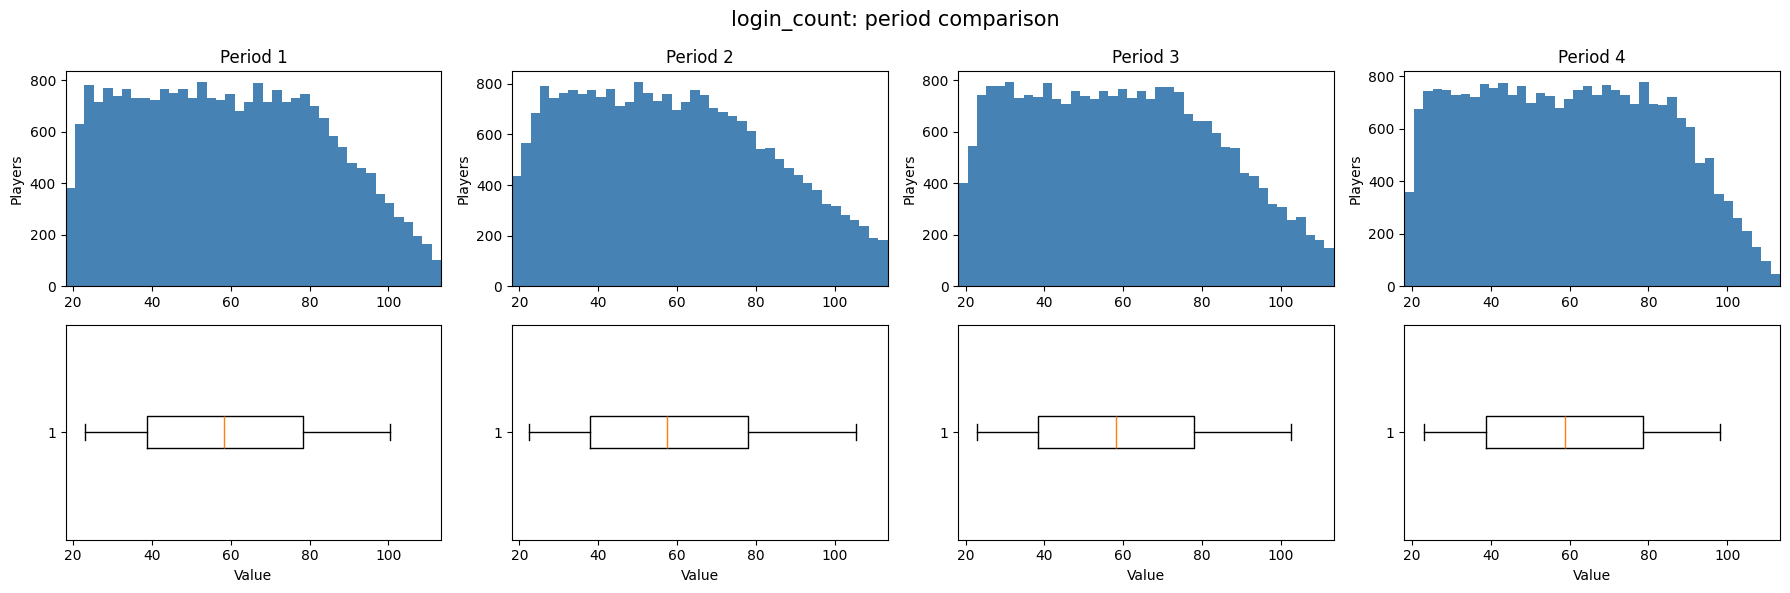

In [30]:
plot_feature_periods("login_count")

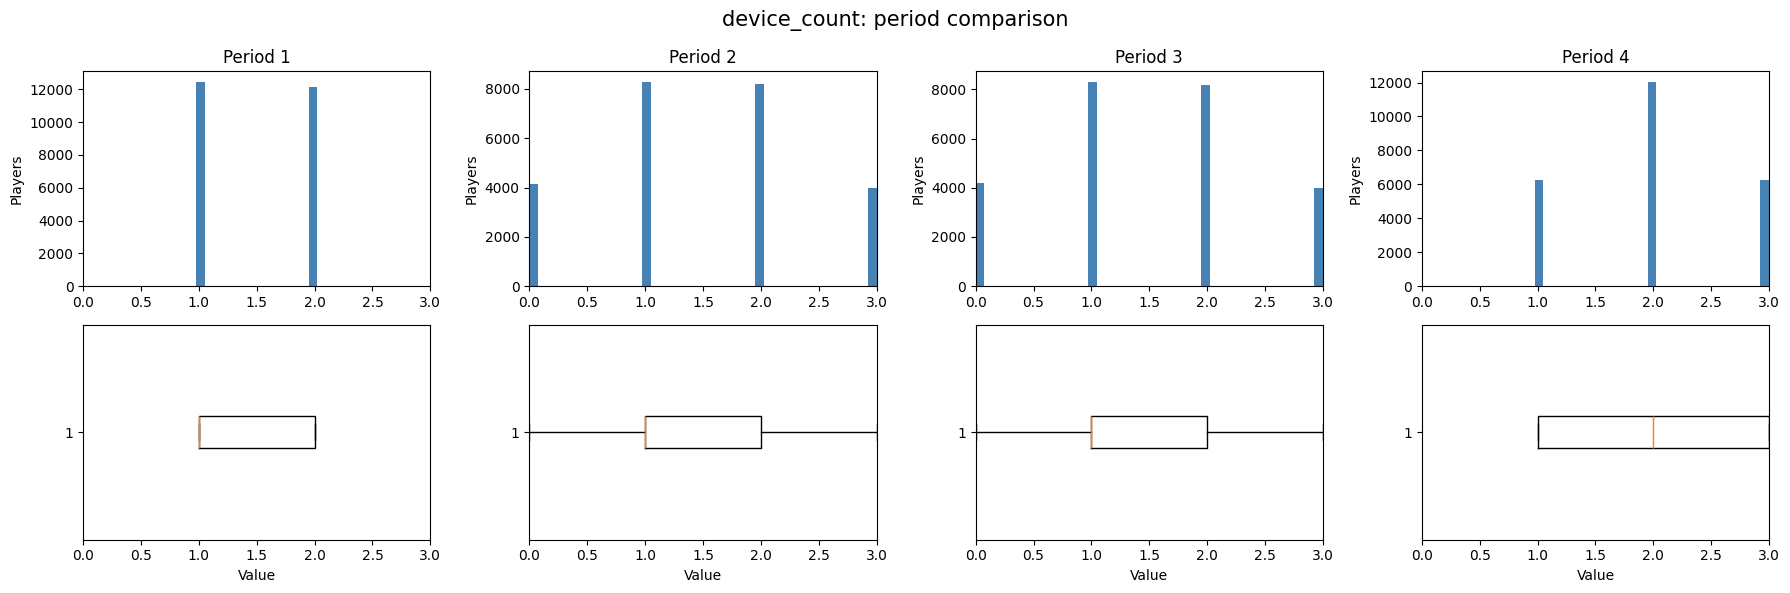

In [31]:
plot_feature_periods("device_count")

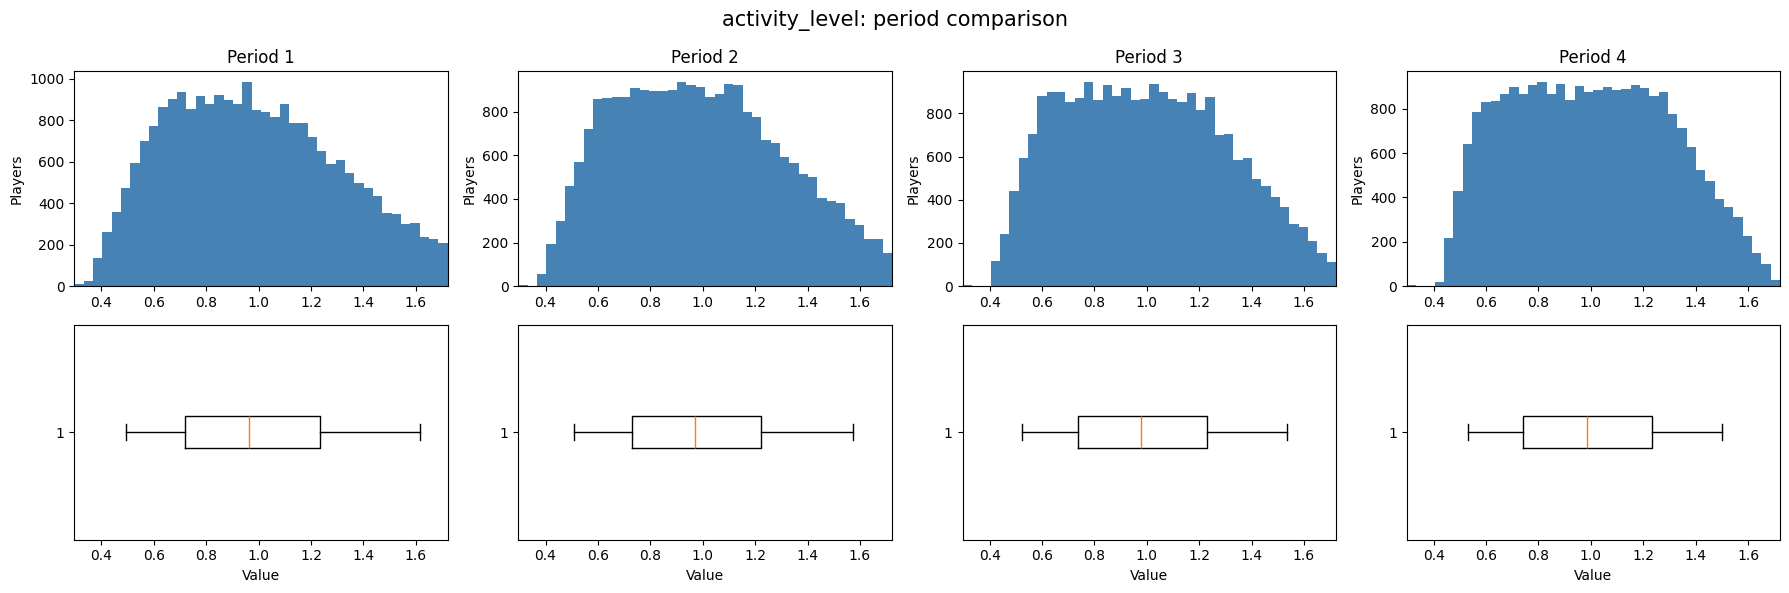

In [32]:
plot_feature_periods("activity_level")

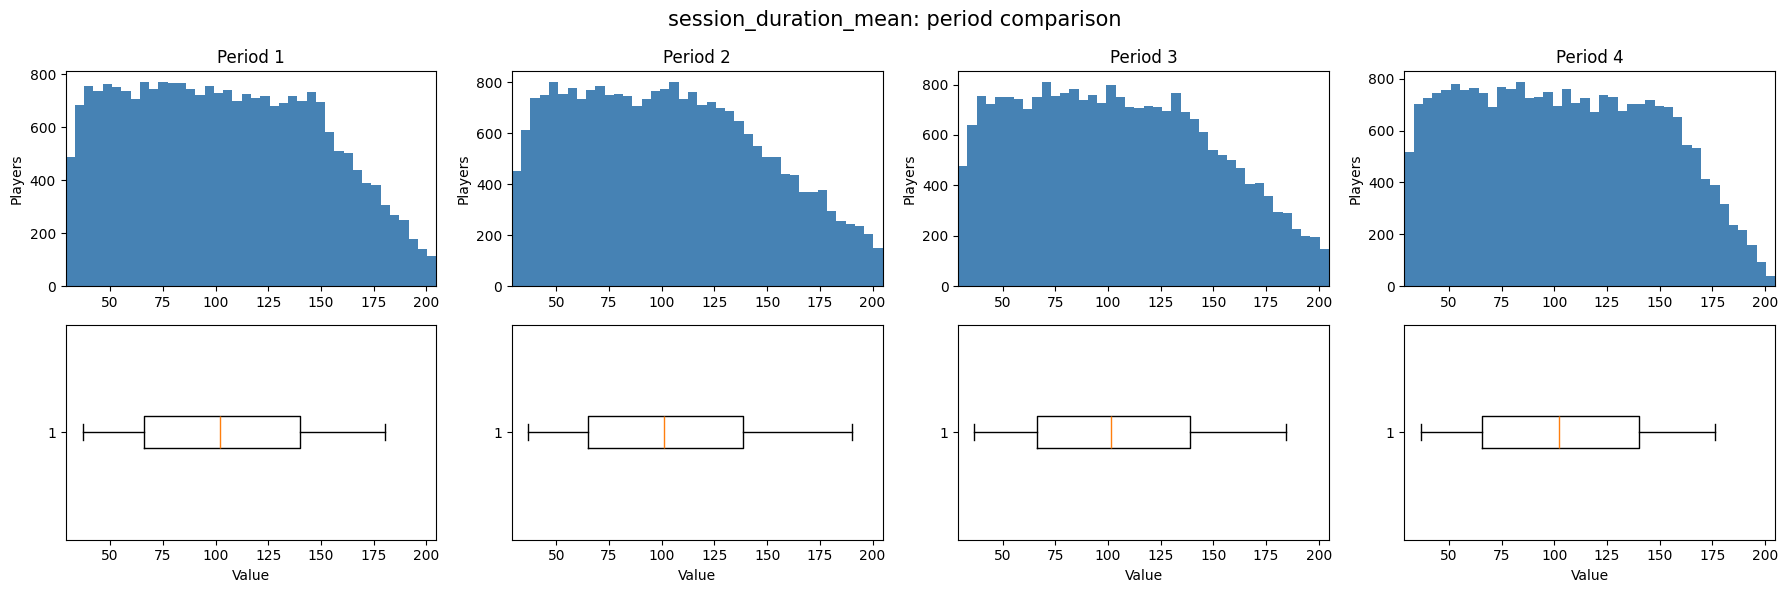

In [33]:
plot_feature_periods("session_duration_mean")

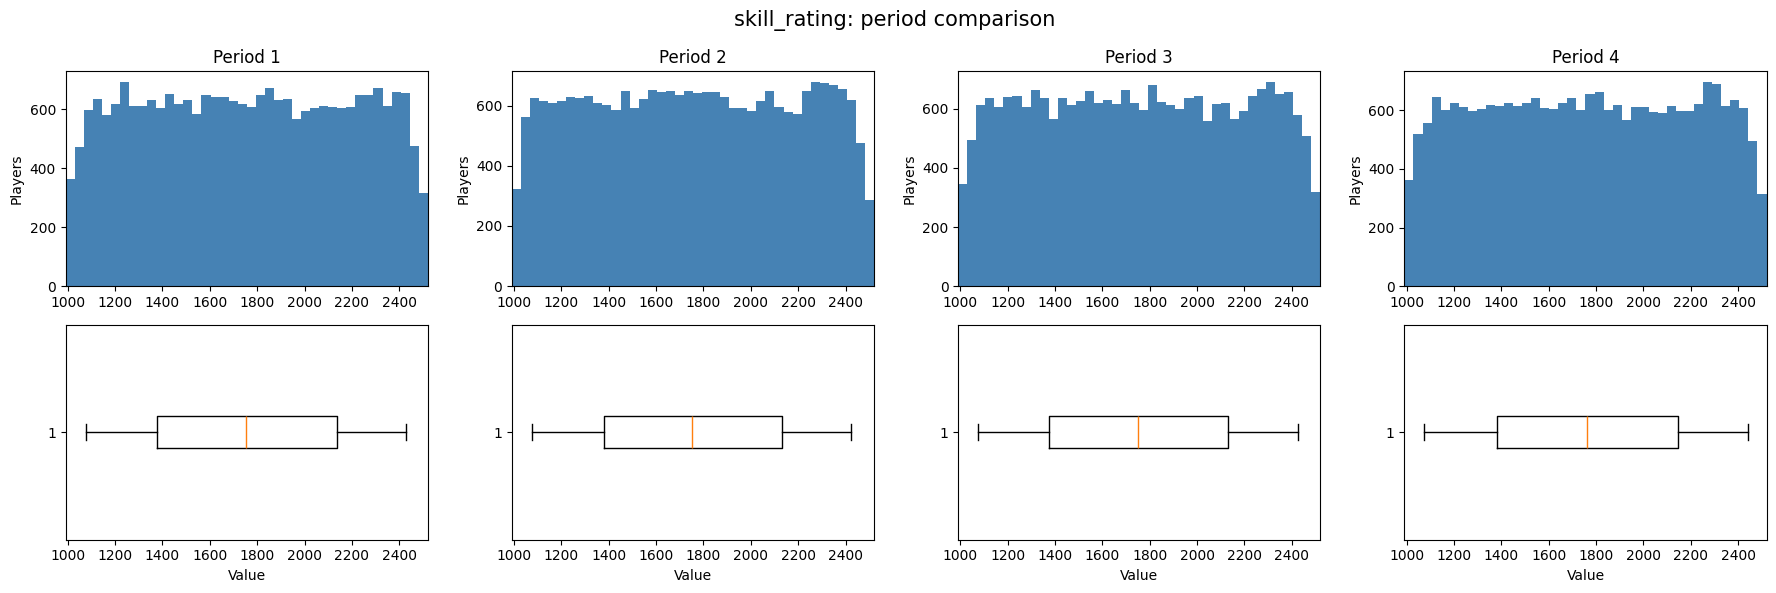

In [34]:
plot_feature_periods("skill_rating")

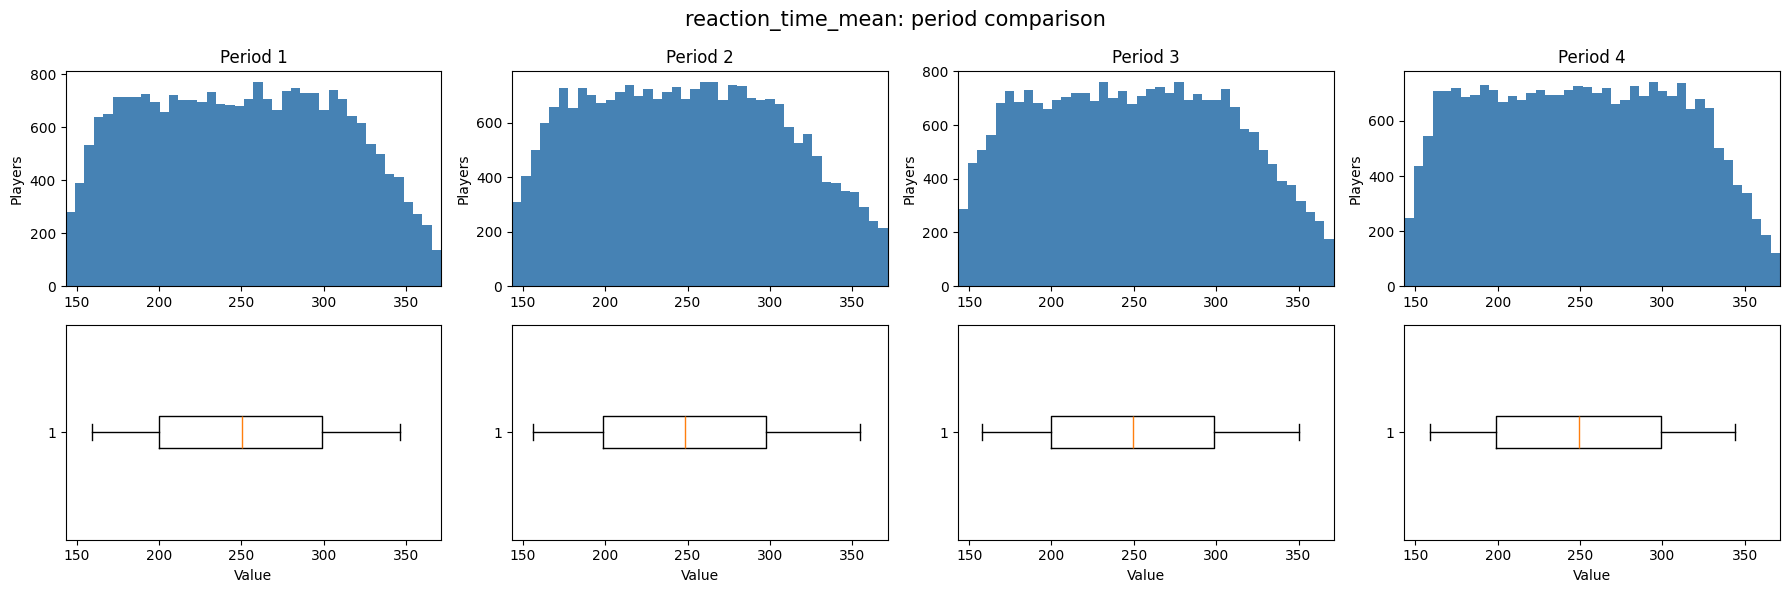

In [35]:
plot_feature_periods("reaction_time_mean")

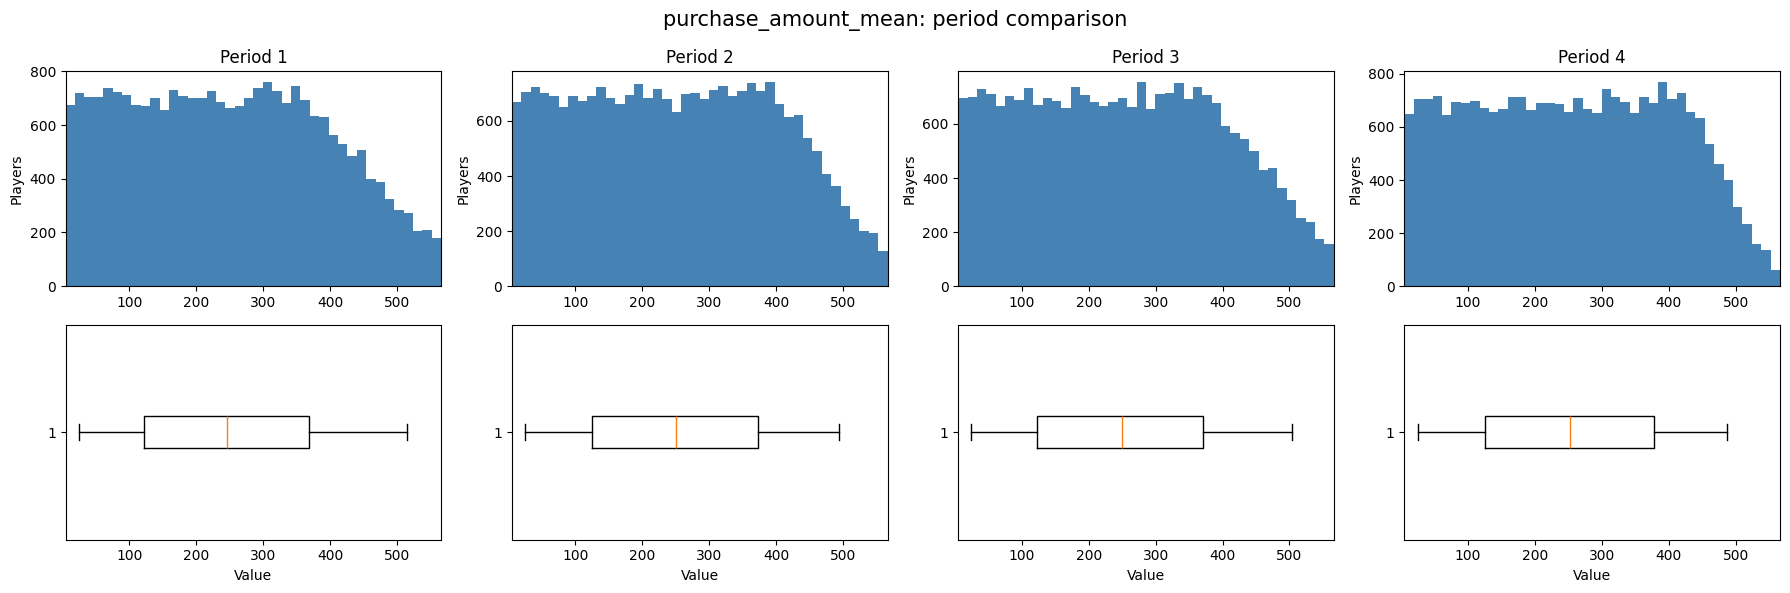

In [36]:
plot_feature_periods("purchase_amount_mean")

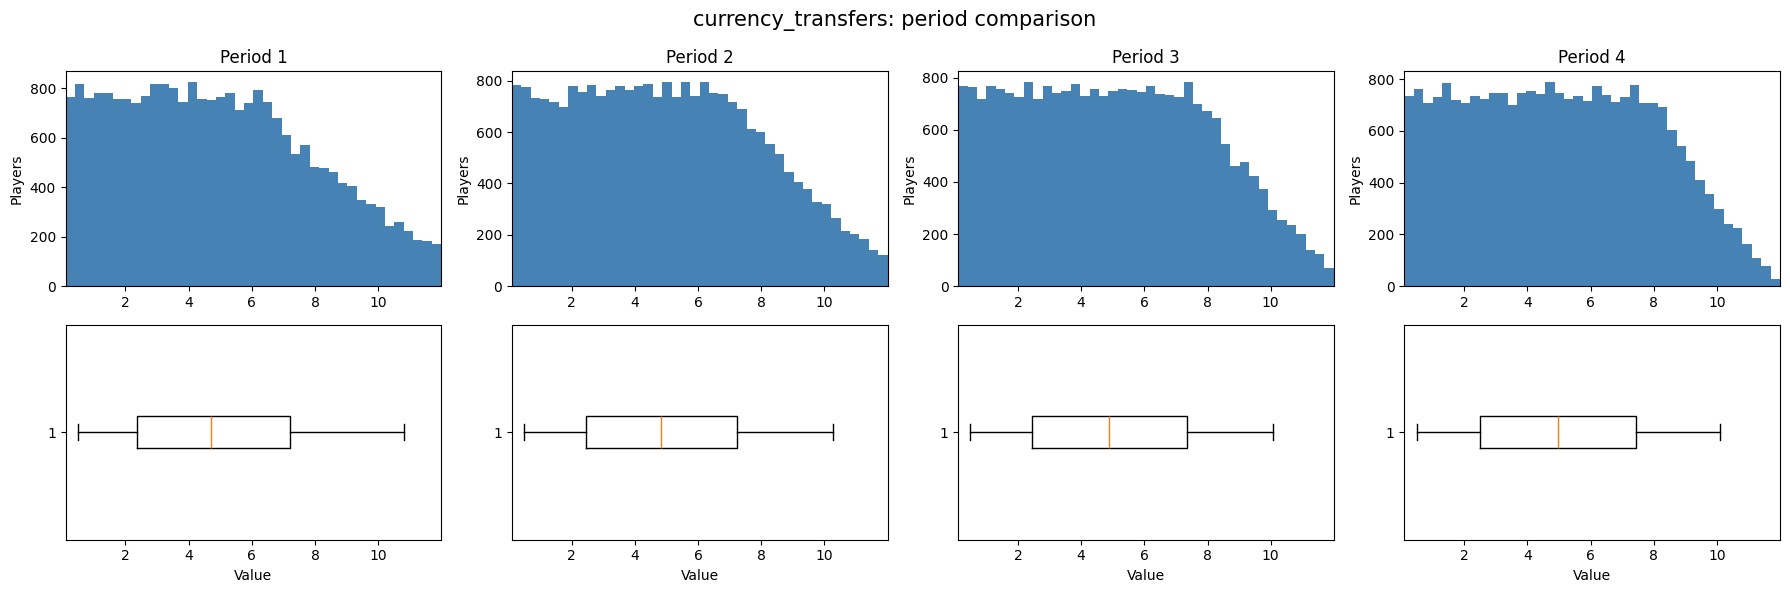

In [37]:
plot_feature_periods("currency_transfers")

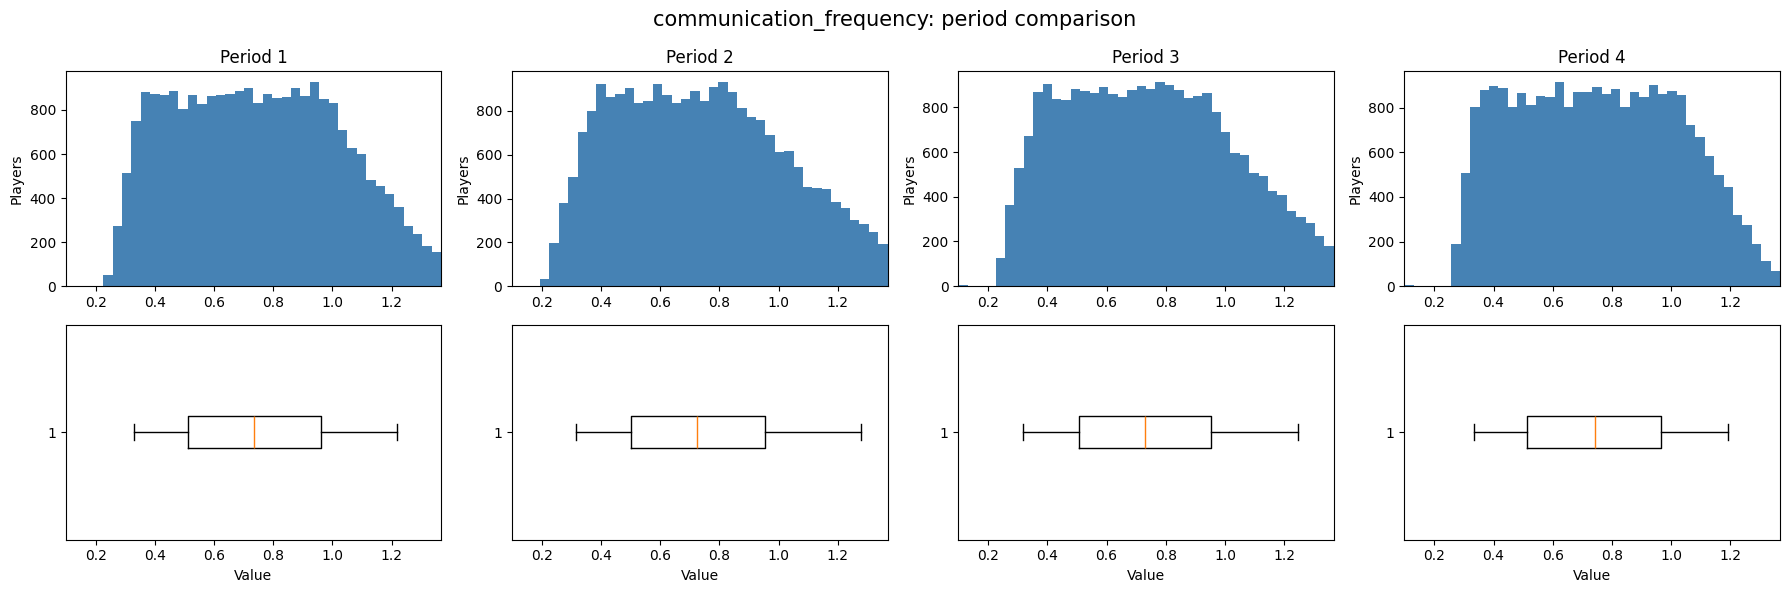

In [38]:
plot_feature_periods("communication_frequency")

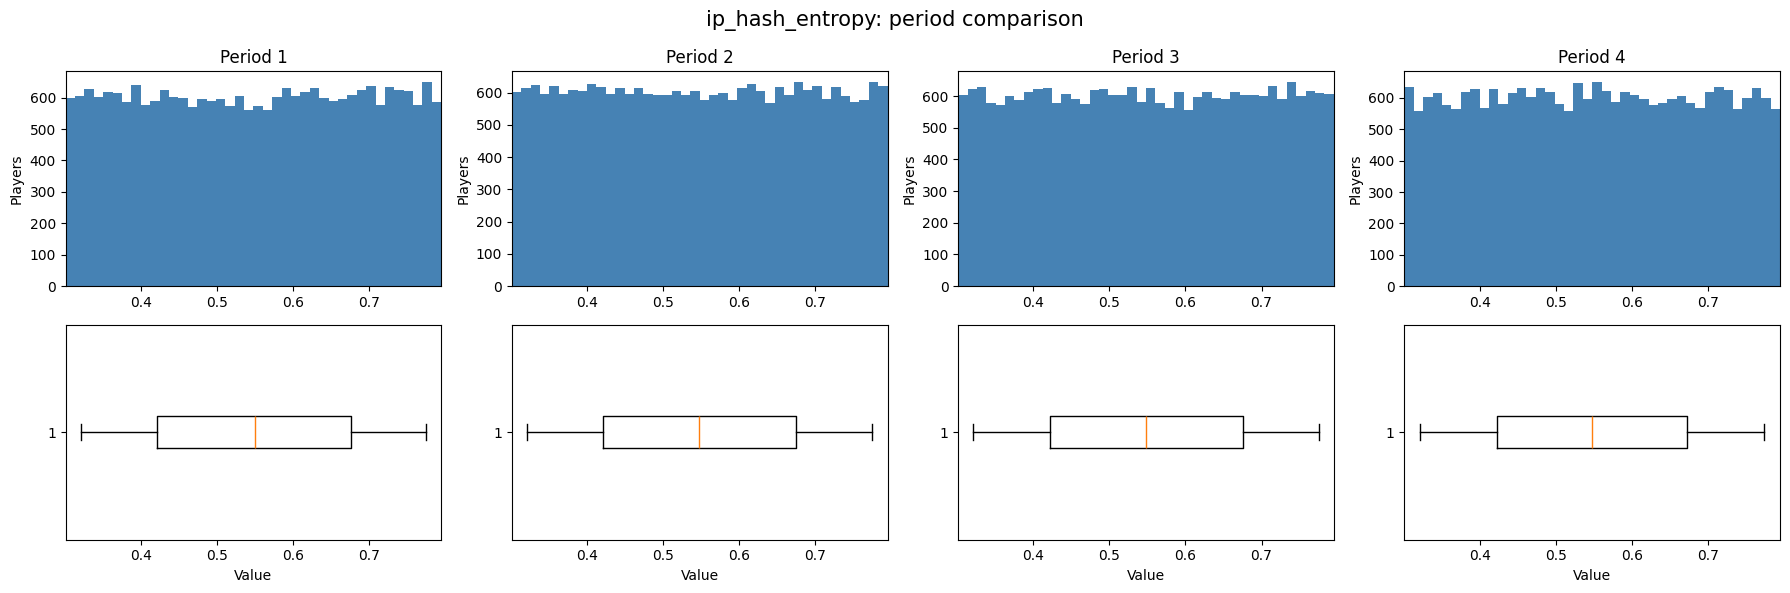

In [39]:
plot_feature_periods("ip_hash_entropy")

For count-like features, inspect the share of exact zeros among observed values. Zeros may be valid inactivity, and the `-1` count values were already masked in `test_clean`.

In [40]:
count_families = ["login_count", "location_changes", "device_count", "purchase_frequency",
                  "refund_count", "currency_transfers", "friend_adds", "friend_removes", "guild_changes"]
zero_rows = []
for family in count_families:
    for period in range(1, 5):
        column = f"{family}_{period}"
        values = test_clean[column].dropna()
        zero_rows.append({"feature": column, "observed": len(values),
                          "zero_pct": round(100 * values.eq(0).mean(), 2)})
count_zero_table = pd.DataFrame(zero_rows).sort_values("zero_pct", ascending=False)
print(f"Exact-zero prevalence in count-like features:\n{count_zero_table.to_string(index=False)}")

Exact-zero prevalence in count-like features:
             feature  observed  zero_pct
      refund_count_1     24617     49.00
      refund_count_3     20541     40.45
      refund_count_2     20549     39.79
     guild_changes_1     24640     32.84
      refund_count_4     24627     24.66
     guild_changes_3     21886     24.53
     guild_changes_2     21946     24.21
    friend_removes_2     24635     20.09
    friend_removes_1     24631     20.07
    friend_removes_3     24650     20.03
    friend_removes_4     24654     19.85
      device_count_3     24650     16.99
      device_count_2     24611     16.76
     guild_changes_4     24640     16.11
       friend_adds_3     24602      4.96
       friend_adds_2     24614      4.96
       friend_adds_1     24642      4.95
       friend_adds_4     24670      4.88
       login_count_2     24613      0.00
       login_count_1     24672      0.00
       login_count_4     24654      0.00
       login_count_3     24621      0.00
purchase_fr

Security flags are binary and are summarized by prevalence rather than histograms or KDE.

In [41]:
prevalence_rows = []
for column in security_flags:
    values = test_clean[column]
    observed = values.notna().sum()
    prevalence_rows.append({"feature": column, "zero_rows": int(values.eq(0).sum()),
                        "one_rows": int(values.eq(1).sum()), "missing_rows": int(values.isna().sum()),
                        "one_pct_observed": round(100 * values.eq(1).sum() / observed, 2)})
binary_prevalence = pd.DataFrame(prevalence_rows)
print(f"Security-flag prevalence:\n{binary_prevalence.to_string(index=False)}")

Security-flag prevalence:
              feature  zero_rows  one_rows  missing_rows  one_pct_observed
     password_changed      23053      1473          1363              6.01
            vpn_usage      20710      3919          1260             15.91
suspicious_login_time      23365      1250          1274              5.08
       mass_item_sale      23870       711          1308              2.89


The upper-tail table above is dominated by Period-4 columns. The next tables therefore compare Period 3 with Period 4 directly: their tails, the overlap of Period-4 top-1% tails across features, values outside the Period-3 range, and a few semantic checks on scores, devices, and geography. Period numbering does not establish which period is the most recent.

In [42]:
compare_families = ["location_changes", "skill_trajectory", "skill_rating",
                    "currency_transfers", "friend_removes", "purchase_frequency",
                    "purchase_amount_mean", "kda_mean", "accuracy_mean"]
compare_rows = []
for family in compare_families:
    p3, p4 = test_clean[f"{family}_3"], test_clean[f"{family}_4"]
    compare_rows.append({"feature": family, "P3_median": p3.median(), "P4_median": p4.median(),
                         "P3_P99": p3.quantile(.99), "P4_P99": p4.quantile(.99),
                         "P3_max": p3.max(), "P4_max": p4.max()})
p3_p4_comparison = pd.DataFrame(compare_rows)
print(f"Period 3 versus Period 4:\n{p3_p4_comparison.round(2).to_string(index=False)}")

Period 3 versus Period 4:
             feature  P3_median  P4_median  P3_P99  P4_P99  P3_max  P4_max
    location_changes       1.44       1.50    3.55   11.32    3.89   19.91
    skill_trajectory      -0.04       0.04   12.20   67.17   21.45  149.95
        skill_rating    1752.10    1762.01 2507.86 2630.21 2620.14 7158.83
  currency_transfers       4.89       4.98   11.41   25.80   12.46   49.95
      friend_removes       2.01       2.01    5.08   24.29    5.20   49.91
  purchase_frequency       2.45       2.53    5.90    5.80    6.46   24.99
purchase_amount_mean     249.08     253.05  569.29  544.72  619.65 2320.25
            kda_mean       2.10       2.14    4.05    3.90    4.36   11.49
       accuracy_mean      39.83      40.04   58.50   57.93   61.47   98.93


In [43]:
tail_families = ["location_changes", "skill_trajectory", "currency_transfers", "friend_removes"]
tail_flags = pd.DataFrame({family: test_clean[f"{family}_4"].ge(test_clean[f"{family}_4"].quantile(.99))
                           for family in tail_families})
co_occurrence = tail_flags.astype(int).T.dot(tail_flags.astype(int))
example_triple = int(tail_flags[["location_changes", "skill_trajectory", "currency_transfers"]].all(axis=1).sum())
print(f"Overlap of Period-4 top-1% tails (diagonal = individual tail counts):\n{co_occurrence.to_string()}\nLocation + skill trajectory + currency transfer together: {example_triple} players")

Overlap of Period-4 top-1% tails (diagonal = individual tail counts):
                    location_changes  skill_trajectory  currency_transfers  friend_removes
location_changes                 247                 0                  83               0
skill_trajectory                   0               246                   0             199
currency_transfers                83                 0                 247               0
friend_removes                     0               199                   0             247
Location + skill trajectory + currency transfer together: 0 players


In [44]:
extreme_rows = []
for family in ["skill_rating", "purchase_frequency", "purchase_amount_mean", "kda_mean", "accuracy_mean"]:
    extreme_rows.append({"feature": family, "comparison": "P4 > P3 maximum",
                         "P4_rows": int(test_clean[f"{family}_4"].gt(test_clean[f"{family}_3"].max()).sum())})
for family in ["reaction_time_mean", "play_pattern_consistency"]:
    extreme_rows.append({"feature": family, "comparison": "P4 < P3 minimum",
                         "P4_rows": int(test_clean[f"{family}_4"].lt(test_clean[f"{family}_3"].min()).sum())})
extreme_table = pd.DataFrame(extreme_rows)
print(f"Period-4 values beyond the Period-3 observed range:\n{extreme_table.to_string(index=False)}")

Period-4 values beyond the Period-3 observed range:
                 feature      comparison  P4_rows
            skill_rating P4 > P3 maximum      247
      purchase_frequency P4 > P3 maximum      189
    purchase_amount_mean P4 > P3 maximum      118
                kda_mean P4 > P3 maximum      151
           accuracy_mean P4 > P3 maximum      129
      reaction_time_mean P4 < P3 minimum       85
play_pattern_consistency P4 < P3 minimum      287


In [45]:
score_columns = ["play_pattern_consistency_2", "play_pattern_consistency_3",
                 "performance_stability_1", "performance_stability_2", "performance_stability_3"]
score_rows = [{"feature": column, "values_above_1": int(test_clean[column].gt(1).sum()),
               "maximum": round(float(test_clean[column].max()), 4)} for column in score_columns]
score_range_review = pd.DataFrame(score_rows)
print(f"Scores above 1 (the data card does not state an upper bound):\n{score_range_review.to_string(index=False)}")

Scores above 1 (the data card does not state an upper bound):
                   feature  values_above_1  maximum
play_pattern_consistency_2             170   1.0323
play_pattern_consistency_3              10   1.0046
   performance_stability_1             351   1.0429
   performance_stability_2             327   1.0439
   performance_stability_3             151   1.0247


In [46]:
device_rows = []
for period in (2, 3):
    no_device_with_login = test_clean[f"device_count_{period}"].eq(0) & test_clean[f"login_count_{period}"].gt(0)
    device_rows.append({"period": period, "zero_devices_positive_logins": int(no_device_with_login.sum())})
print(f"Potential device/login semantic mismatch:\n{pd.DataFrame(device_rows).to_string(index=False)}")

Potential device/login semantic mismatch:
 period  zero_devices_positive_logins
      2                          3907
      3                          3965


In [47]:
geography_rows = []
for period in range(1, 5):
    geography_rows.append({"period": period,
                           "valid_latitude_abs_over_80": int(test_clean[f"login_lat_{period}"].abs().gt(80).sum()),
                           "ip_entropy_max": round(float(test_clean[f"ip_hash_entropy_{period}"].max()), 6)})
print(f"Valid high-latitude observations and observed entropy ceiling:\n{pd.DataFrame(geography_rows).to_string(index=False)}")

Valid high-latitude observations and observed entropy ceiling:
 period  valid_latitude_abs_over_80  ip_entropy_max
      1                           0        0.799986
      2                           0        0.800000
      3                           7        0.799997
      4                          28        0.799977


Observations from the distribution analysis:

- The descriptive statistics in this section come from `test_clean`; out-of-range coordinate pairs and the four `-1` count fields were already masked to `NaN`. The ten feature-specific figures place all four periods side by side on a shared x-axis, while the tables retain full extrema.
- Several Period-4 upper tails are much wider than Period 3 even though their medians remain close. For example, `skill_trajectory` has median −0.04 versus 0.04 but P99 12.20 versus 67.17. `location_changes`, `currency_transfers`, and `friend_removes` also have much larger Period-4 P99 and maxima.
- Other features show a much larger change in maximum than in P99: `purchase_frequency`, `purchase_amount_mean`, `kda_mean`, and `accuracy_mean`. `skill_rating` has a modest P99 increase compared with its large maximum increase. This suggests fewer extreme observations for these features, but does not identify their cause.
- Period-4 top-1% tails do not all belong to the same players. The `location_changes` and `currency_transfers` tails overlap on **83** players; `skill_trajectory` and `friend_removes` overlap on **199**. No player is simultaneously in the top 1% of `location_changes`, `skill_trajectory`, and `currency_transfers` in Period 4. These are distinct descriptive patterns, not verified anomaly types.
- Exact zeros are common in several count-like fields after `-1` masking: `refund_count_1` is **49.00%** zero, and `refund_count_2`/`_3` are **39.79%/40.45%** zero among observed values. Security-flag positive rates range from **2.89%** (`mass_item_sale`) to **15.91%** (`vpn_usage`); these flags are inputs, not labels.
- Values above 1 occur in `play_pattern_consistency_2/_3` and `performance_stability_1/_2/_3`, but the data card does not state a hard upper bound for those scores. In Periods 2 and 3, **3,907** and **3,965** rows have `device_count = 0` with positive `login_count`; the feature definition should be clarified before treating this as an error. The observed `ip_hash_entropy` maximum is close to 0.8 in each period, which alone does not prove clipping.
- Feature scales differ substantially. Later distance- or density-based models will need fitted preprocessing. Extreme valid values remain in the data. No imputation, threshold selection, or model fitting is performed here, and the period numbering does not establish which period is newest.

### 3.2 Temporal Behavior Analysis

Compare each player across the four consecutive periods using `test_clean`. Period numbers establish sequence, but the data card does not identify the newest endpoint. All changes require both adjacent values to be observed; missing pairs stay missing. The eight cleaning flags and six non-period features are outside these temporal tables.

First, compare the central distribution and upper tail for every four-period feature family. IQR is Q3 minus Q1. These are cross-player summaries, so they do not by themselves identify a player whose behavior changed.

In [48]:
assert len(temporal_families) == 29

period_rows = []
for family in temporal_families:
    for period in range(1, 5):
        values = test_clean[f"{family}_{period}"].dropna()
        q1, median, q3, p95 = values.quantile([0.25, 0.50, 0.75, 0.95])
        period_rows.append({"feature": family, "period": period, "observed": len(values),
                            "median": median, "IQR": q3 - q1, "P95": p95})
period_summary = pd.DataFrame(period_rows)
print(period_summary.to_string(index=False, float_format=lambda value: f"{value:,.3f}"))

                 feature  period  observed    median     IQR       P95
             login_count       1     24672    58.272  39.743   100.448
             login_count       2     24613    57.377  39.984   105.524
             login_count       3     24621    58.111  39.492   102.660
             login_count       4     24654    58.963  39.792    98.132
               login_lat       1     24628    -0.589  60.354    53.993
               login_lat       2     24645    -0.482  60.208    53.998
               login_lat       3     24610    -0.360  60.113    54.012
               login_lat       4     24483    -0.033  60.341    54.258
               login_lon       1     24540     0.241 178.486   162.297
               login_lon       2     24566    -0.085 178.670   162.080
               login_lon       3     24604     0.186 178.819   162.372
               login_lon       4     24426     0.838 178.128   162.159
        location_changes       1     24643     1.366   1.471     3.368
      

Next, calculate signed changes within each player. The table reports the median signed change and the P95/P99 of absolute changes, with the number of valid pairs for each transition. A positive median is a distributional shift in that direction, not evidence of an anomaly.

In [49]:
change_rows = []
for family in temporal_families:
    for period in range(1, 4):
        change = test_clean[f"{family}_{period + 1}"] - test_clean[f"{family}_{period}"]
        valid = change.dropna()
        change_rows.append({"feature": family, "transition": f"P{period + 1}-P{period}",
                            "valid_pairs": len(valid), "median_change": valid.median(),
                            "P95_abs_change": valid.abs().quantile(0.95),
                            "P99_abs_change": valid.abs().quantile(0.99)})
change_summary = pd.DataFrame(change_rows)
print(change_summary.to_string(index=False, float_format=lambda value: f"{value:,.3f}"))

                 feature transition  valid_pairs  median_change  P95_abs_change  P99_abs_change
             login_count      P2-P1        23452          0.122          27.476          35.861
             login_count      P3-P2        23402         -0.157          30.277          39.950
             login_count      P4-P3        23447         -0.046          22.409          29.427
               login_lat      P2-P1        23432         -0.009           1.392           1.835
               login_lat      P3-P2        23431          0.010           1.420           2.150
               login_lat      P4-P3        23282         -0.002           1.486          27.573
               login_lon      P2-P1        23279          0.011           1.379           1.805
               login_lon      P3-P2        23368         -0.001           1.421           2.068
               login_lon      P4-P3        23218          0.013           1.490          38.605
        location_changes      P2-P1     

Summarize variability within each player. `max_step` is the largest observed adjacent absolute change and remains missing when no adjacent pair exists. `range` needs at least two observed periods. Exact flatline requires all four values to be observed and equal. Near-flatline allows a four-period range at most 5% of the pooled IQR for that feature; where the pooled IQR is zero, only exact equality qualifies. Both rates use complete rows as the denominator, shown to avoid treating incomplete rows as flat.

In [50]:
variability_rows = []
for family in temporal_families:
    values = test_clean[[f"{family}_{period}" for period in range(1, 5)]].copy()
    values.columns = range(1, 5)
    steps = pd.concat([(values[period + 1] - values[period]).abs()
                       for period in range(1, 4)], axis=1)
    max_step = steps.max(axis=1, skipna=True)
    enough_values = values.notna().sum(axis=1) >= 2
    row_range = (values.max(axis=1) - values.min(axis=1)).where(enough_values)
    complete = values.notna().all(axis=1)
    flatline = complete & values.eq(values[1], axis=0).all(axis=1)
    pooled_iqr = values.stack().quantile(0.75) - values.stack().quantile(0.25)
    near_flatline = complete & row_range.le(0.05 * pooled_iqr)
    variability_rows.append({"feature": family, "players_with_step": int(max_step.notna().sum()),
                             "median_max_step": max_step.median(), "P95_max_step": max_step.quantile(0.95),
                             "median_range": row_range.median(), "complete_players": int(complete.sum()),
                             "exact_flatline_pct_of_complete": 100 * flatline.sum() / complete.sum(),
                             "near_flatline_pct_of_complete": 100 * near_flatline.sum() / complete.sum()})
variability_summary = pd.DataFrame(variability_rows)
print(variability_summary.to_string(index=False, float_format=lambda value: f"{value:,.3f}"))

                 feature  players_with_step  median_max_step  P95_max_step  median_range  complete_players  exact_flatline_pct_of_complete  near_flatline_pct_of_complete
             login_count              25712           12.947        32.385        14.567             21239                           0.000                          0.433
               login_lat              25685            0.812         1.728         0.962             21092                           0.000                         98.549
               login_lon              25653            0.812         1.721         0.957             20911                           0.000                         98.618
        location_changes              25722            0.471         1.559         0.575             21195                           0.000                          6.780
            device_count              25715            1.000         2.000         1.000             21267                           6.122            

For a scale-free view of consecutive changes, use `2 × |next − previous| / (|next| + |previous|)`. It is 0 when both observed values are zero, and otherwise lies between 0 and 2. This is descriptive: zero-heavy features can reach 2 for a small absolute change, so read it together with the absolute-change table. Missing pairs are excluded. Latitude and longitude are omitted because ratios of geographic coordinates are not meaningful.

In [51]:
relative_rows = []
for family in [name for name in temporal_families if name not in {"login_lat", "login_lon"}]:
    for period in range(1, 4):
        previous = test_clean[f"{family}_{period}"]
        following = test_clean[f"{family}_{period + 1}"]
        denominator = previous.abs() + following.abs()
        relative = 2 * (following - previous).abs() / denominator.replace(0, np.nan)
        relative = relative.where(denominator.ne(0), 0).where(previous.notna() & following.notna())
        valid = relative.dropna()
        relative_rows.append({"feature": family, "transition": f"P{period + 1}-P{period}",
                              "valid_pairs": len(valid), "median_relative": valid.median(),
                              "P95_relative": valid.quantile(0.95),
                              "share_above_1_pct": 100 * valid.gt(1).mean()})
relative_summary = pd.DataFrame(relative_rows)
print(relative_summary.to_string(index=False, float_format=lambda value: f"{value:,.3f}"))

                 feature transition  valid_pairs  median_relative  P95_relative  share_above_1_pct
             login_count      P2-P1        23452            0.157         0.394              0.000
             login_count      P3-P2        23402            0.164         0.436              0.000
             login_count      P4-P3        23447            0.129         0.319              0.000
        location_changes      P2-P1        23442            0.278         0.720              0.000
        location_changes      P3-P2        23420            0.214         0.550              0.000
        location_changes      P4-P3        23417            0.155         0.419              1.866
            device_count      P2-P1        23405            0.667         2.000             16.783
            device_count      P3-P2        23426            0.667         2.000             22.159
            device_count      P4-P3        23528            0.667         2.000             17.188
         i

The Period 1–4 value distributions are already plotted side by side in Section 3.1. Here, compare **changes** across all three transitions for six representative domains. The display range is the pooled 1st–99th percentile of observed changes within each feature; full tails remain in the tables above.

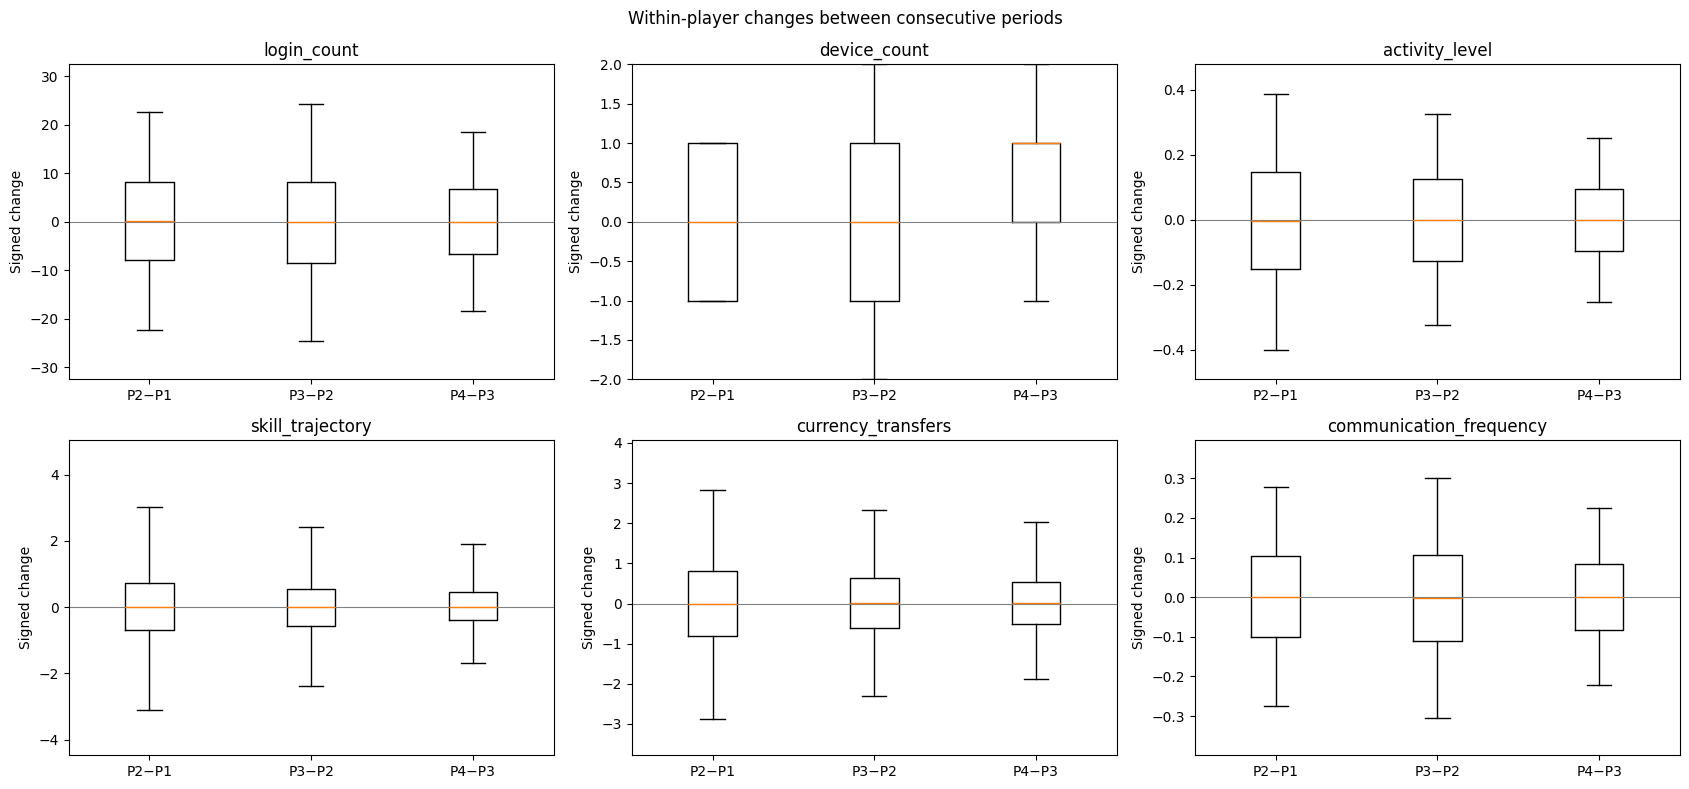

In [52]:
change_plot_families = ["login_count", "device_count", "activity_level",
                        "skill_trajectory", "currency_transfers", "communication_frequency"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, family in zip(axes.flat, change_plot_families):
    changes = [(test_clean[f"{family}_{period + 1}"] - test_clean[f"{family}_{period}"]).dropna()
               for period in range(1, 4)]
    pooled = pd.concat(changes)
    low, high = pooled.quantile([0.01, 0.99])
    ax.boxplot(changes, tick_labels=["P2−P1", "P3−P2", "P4−P3"],
               whis=(5, 95), showfliers=False)
    ax.set_ylim(low, high)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(family)
    ax.set_ylabel("Signed change")
fig.suptitle("Within-player changes between consecutive periods")
fig.tight_layout()
plt.show()

Finally, inspect individual trajectories for four behavior domains. Blue lines are five players sampled with a fixed seed from those with all four values. Orange lines are the five largest `max_step` values among complete players for that feature. Selection illustrates shapes, not known anomaly labels; each panel has its own value scale.

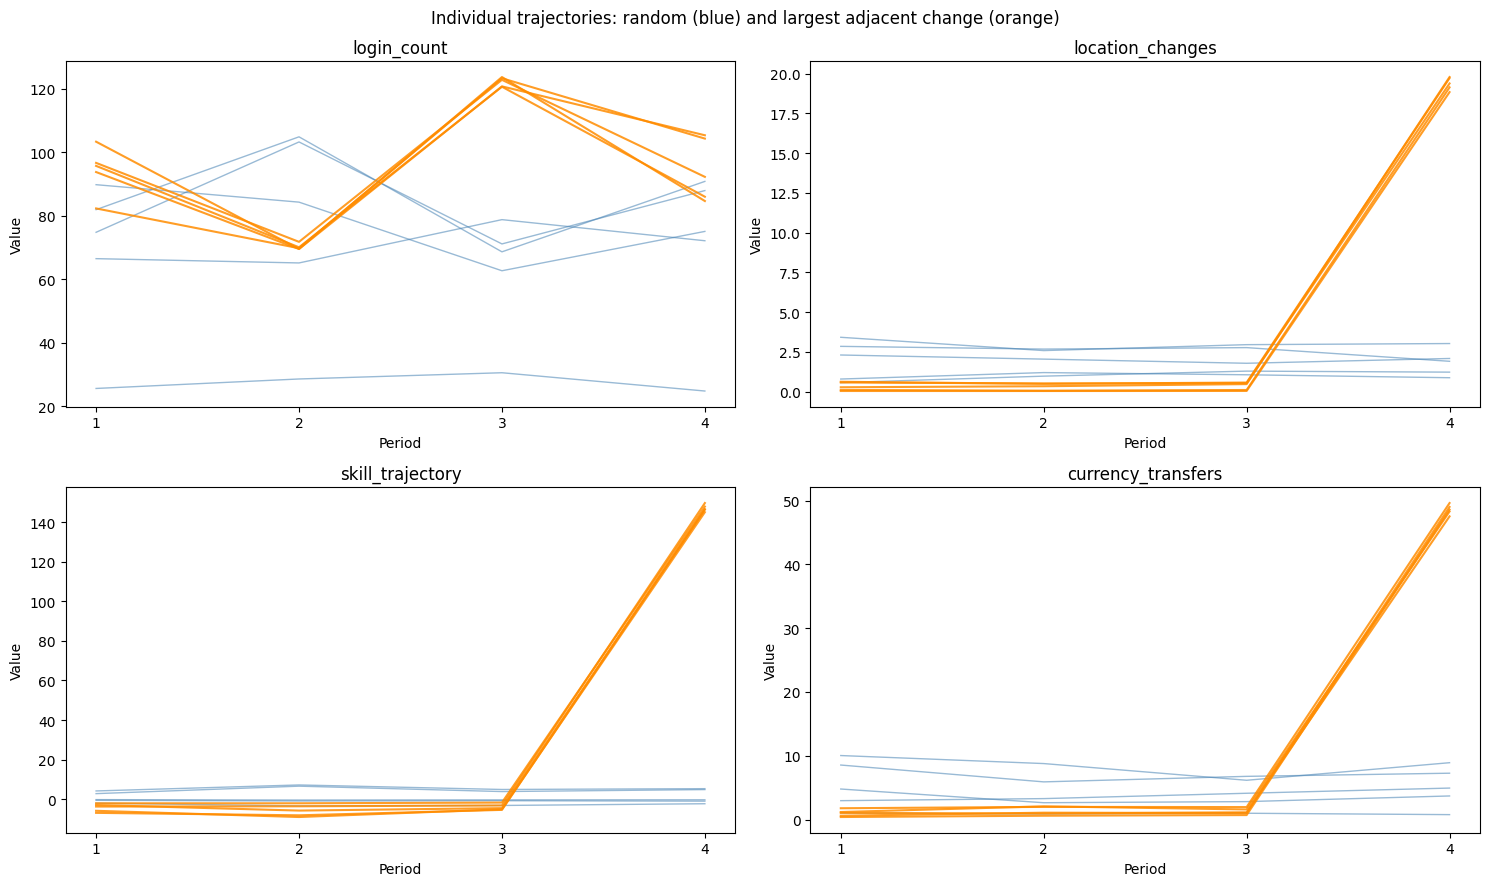

In [53]:
trajectory_families = ["login_count", "location_changes", "skill_trajectory", "currency_transfers"]
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, family in zip(axes.flat, trajectory_families):
    values = test_clean[[f"{family}_{period}" for period in range(1, 5)]]
    complete = values.dropna()
    random_rows = rng.choice(complete.index.to_numpy(), size=5, replace=False)
    largest_step = complete.diff(axis=1).iloc[:, 1:].abs().max(axis=1)
    largest_rows = largest_step.nlargest(5).index
    for row in random_rows:
        ax.plot(range(1, 5), values.loc[row], color="steelblue", alpha=0.55, linewidth=1)
    for row in largest_rows:
        ax.plot(range(1, 5), values.loc[row], color="darkorange", alpha=0.85, linewidth=1.5)
    ax.set_title(family)
    ax.set_xticks(range(1, 5))
    ax.set_xlabel("Period")
    ax.set_ylabel("Value")
fig.suptitle("Individual trajectories: random (blue) and largest adjacent change (orange)")
fig.tight_layout()
plt.show()

Observations from the temporal analysis:

- The period medians of most continuous features move much less than their upper-tail changes. `skill_trajectory` has medians near zero across all four periods, while its P4−P3 P99 absolute change reaches **66.522**, versus **5.119** for P3−P2. `location_changes` rises from **1.474** to **10.130**, `friend_removes` from **2.148** to **21.586**, and `currency_transfers` from **3.884** to **20.472** on the same P99 absolute-change comparison. This describes a subset of large changes, not a period-wide median shift.
- `device_count` is different: its median is **1** in Periods 1–3 and **2** in Period 4, and the median P4−P3 within-player change is **+1**. That suggests a broader period-level shift rather than only an extreme tail.
- Exact flatlines occur in discrete features such as `device_count`, `refund_count`, `guild_changes`, and `friend_removes`; a near-flatline rate also captures small changes in continuous features. Missing periods are excluded from both rates.
- The selected highest-change trajectories show sharp jumps at P4 for `location_changes`, `skill_trajectory`, and `currency_transfers`. These are illustrative selected accounts, not confirmed anomalies. The four periods are consecutive, but the data card does not establish which endpoint is newest.

### 3.3 Feature Relationship & Redundancy Analysis

Use pairwise-complete Spearman correlations to inspect monotonic relationships after cleaning. A high correlation does not mean two columns are identical or interchangeable. No feature is removed in this section. Check the four periods within each feature family, then inspect a focused set of behavioral domains. The heatmaps display correlations only; they do not imply that any relationship is causal.

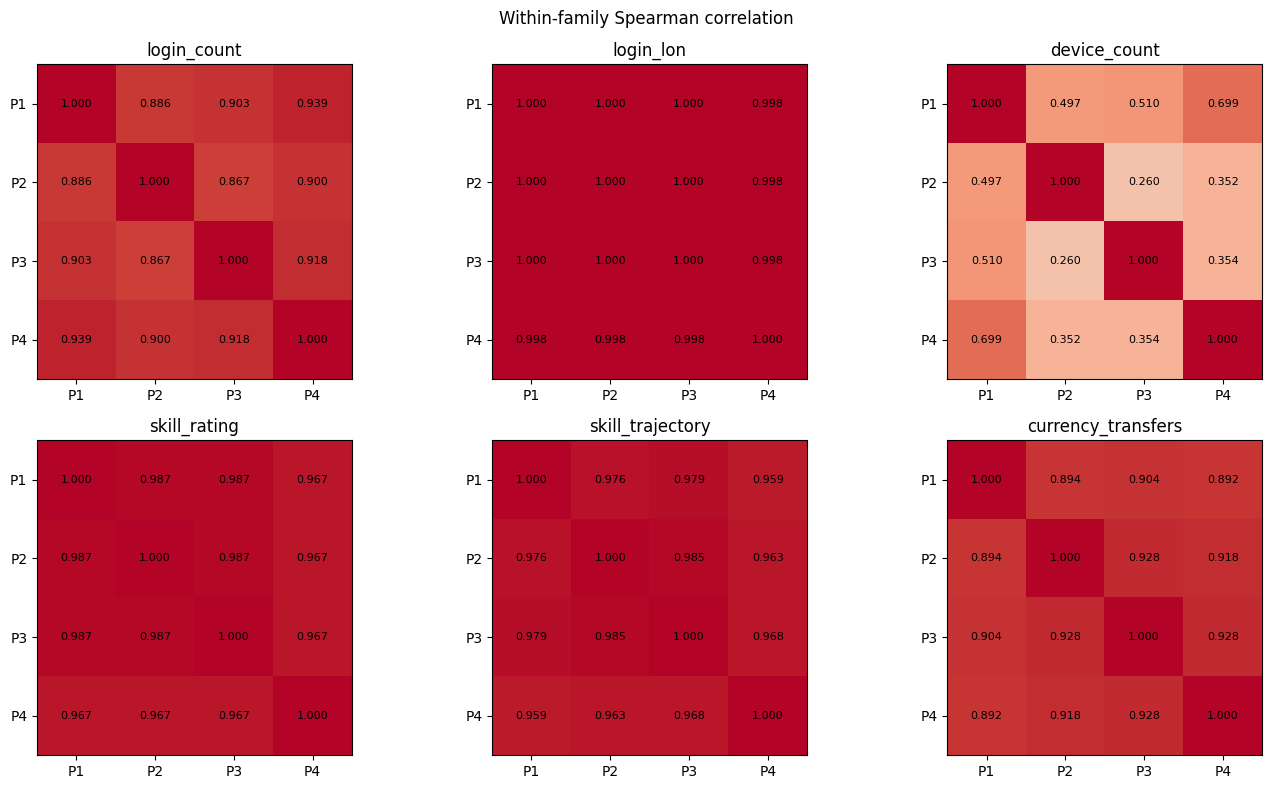

In [54]:
correlation_families = ["login_count", "login_lon", "device_count", "skill_rating",
                        "skill_trajectory", "currency_transfers"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, family in zip(axes.flat, correlation_families):
    columns = [f"{family}_{period}" for period in range(1, 5)]
    matrix = test_clean[columns].corr(method="spearman")
    ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(4), labels=[f"P{period}" for period in range(1, 5)])
    ax.set_yticks(range(4), labels=[f"P{period}" for period in range(1, 5)])
    ax.set_title(family)
    for row in range(4):
        for column in range(4):
            ax.text(column, row, f"{matrix.iloc[row, column]:.3f}",
                    ha="center", va="center", fontsize=8)
fig.suptitle("Within-family Spearman correlation")
fig.tight_layout()
plt.show()

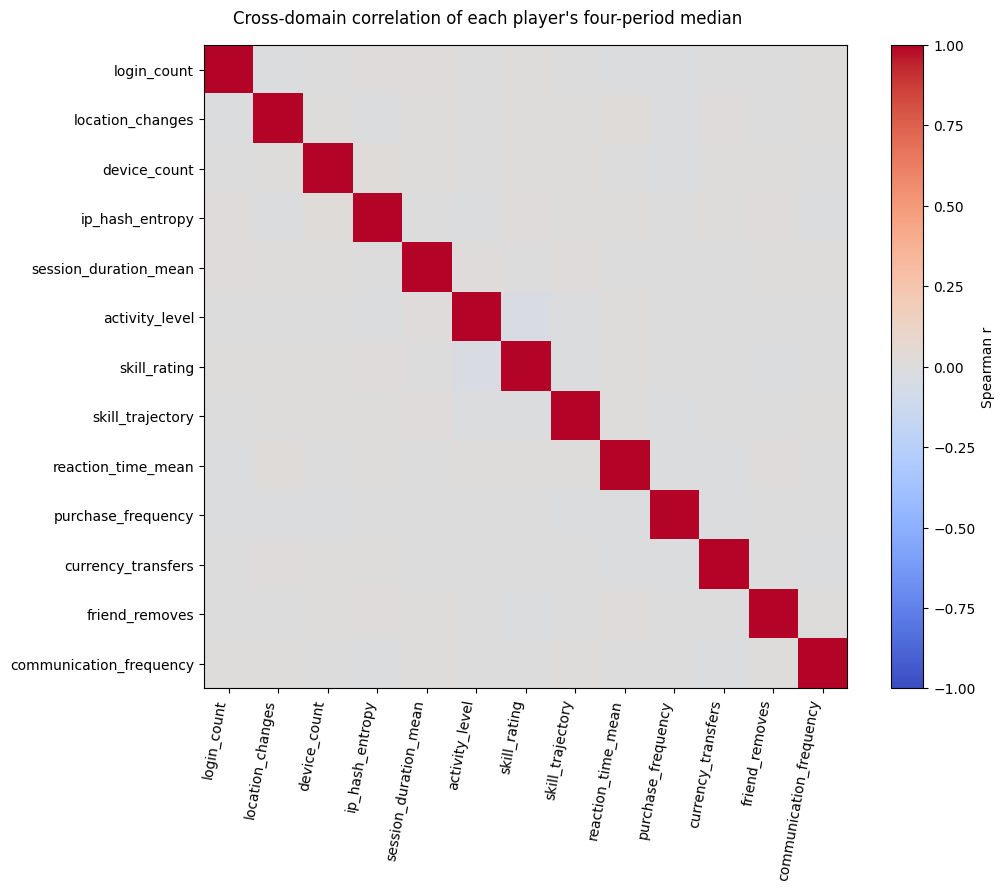

In [55]:
domain_families = ["login_count", "location_changes", "device_count", "ip_hash_entropy",
                   "session_duration_mean", "activity_level", "skill_rating", "skill_trajectory",
                   "reaction_time_mean", "purchase_frequency", "currency_transfers",
                   "friend_removes", "communication_frequency"]
domain_medians = pd.DataFrame({family: test_clean[[f"{family}_{period}" for period in range(1, 5)]].median(axis=1)
                               for family in domain_families})
domain_corr = domain_medians.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
heat = ax.imshow(domain_corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(domain_families)), labels=domain_families, rotation=80, ha="right")
ax.set_yticks(range(len(domain_families)), labels=domain_families)
fig.colorbar(heat, ax=ax, label="Spearman r")
fig.suptitle("Cross-domain correlation of each player's four-period median")
fig.tight_layout()
plt.show()

Screen all 122 original predictor pairs at `|Spearman r| ≥ 0.90`, requiring at least 1,000 observed pairs. The table includes pair count and both Spearman and Pearson coefficients. Correlation screening is descriptive and can surface relationships across periods as well as possible redundancy.

In [56]:
spearman_all = test_clean[feature_cols].corr(method="spearman", min_periods=1000)
pearson_all = test_clean[feature_cols].corr(method="pearson", min_periods=1000)
high_pair_rows = []
for left_index, left in enumerate(feature_cols):
    for right in feature_cols[left_index + 1:]:
        spearman_r = spearman_all.loc[left, right]
        if pd.notna(spearman_r) and abs(spearman_r) >= 0.90:
            high_pair_rows.append({"left": left, "right": right,
                                   "paired_rows": int(test_clean[[left, right]].notna().all(axis=1).sum()),
                                   "spearman_r": spearman_r,
                                   "pearson_r": pearson_all.loc[left, right]})
high_pairs = pd.DataFrame(high_pair_rows)
if len(high_pairs):
    high_pairs = high_pairs.reindex(high_pairs.spearman_r.abs().sort_values(ascending=False).index)
print(f"Pairs with |Spearman r| >= 0.90: {len(high_pairs)}\n"
      + (high_pairs.to_string(index=False, float_format=lambda value: f"{value:.5f}")
         if len(high_pairs) else "None"))

Pairs with |Spearman r| >= 0.90: 74
                     left                     right  paired_rows  spearman_r  pearson_r
              login_lon_1               login_lon_2        23279     0.99998    0.99998
              login_lat_1               login_lat_2        23432     0.99979    0.99979
              login_lon_1               login_lon_3        23334     0.99961    0.99962
              login_lon_2               login_lon_3        23368     0.99959    0.99959
              login_lat_1               login_lat_3        23416     0.99852    0.99817
              login_lat_2               login_lat_3        23431     0.99849    0.99815
              login_lon_1               login_lon_4        23152     0.99785    0.99784
              login_lon_2               login_lon_4        23189     0.99783    0.99782
              login_lon_3               login_lon_4        23218     0.99755    0.99754
              login_lat_1               login_lat_4        23293     0.99062    0.98

The raw audit found almost identical `login_lon_1` and `login_lon_2` by Pearson correlation. Check this pair again after coordinate masking and quantify their paired differences; exact equality and high correlation are different claims.

In [57]:
longitude_pair = test_clean[["login_lon_1", "login_lon_2"]].dropna()
longitude_gap = (longitude_pair.login_lon_2 - longitude_pair.login_lon_1).abs()
lon_review = pd.DataFrame([{
    "paired_rows": len(longitude_pair),
    "pearson_r": longitude_pair.login_lon_1.corr(longitude_pair.login_lon_2),
    "spearman_r": longitude_pair.login_lon_1.corr(longitude_pair.login_lon_2, method="spearman"),
    "exact_equal_pct": 100 * longitude_gap.eq(0).mean(),
    "median_abs_gap": longitude_gap.median(),
    "P95_abs_gap": longitude_gap.quantile(0.95),
    "max_abs_gap": longitude_gap.max(),
}])
print(lon_review.to_string(index=False, float_format=lambda value: f"{value:,.6f}"))

 paired_rows  pearson_r  spearman_r  exact_equal_pct  median_abs_gap  P95_abs_gap  max_abs_gap
       23279   0.999977    0.999976         0.000000        0.477792     1.378798     3.029011


Observations from the relationship analysis:

- **74** pairs of original predictors have `|Spearman r| ≥ 0.90` with at least 1,000 observed pairs. Most of the strongest pairs are the same feature in neighboring periods, so each period carries strongly related information.
- After cleaning, `login_lon_1` and `login_lon_2` still have Pearson **0.999977** and Spearman **0.999976**, but **0%** of paired values are exactly equal and their median absolute gap is **0.478**. High correlation alone does not justify dropping a period, so all periods are kept.

### 3.4 Data Quality Flags Exploration

The `invalid_` columns describe values masked during Section 2.8. They record data quality, not confirmed fraud. Group comparisons use observed values and report their sample sizes; no rows are removed.

#### 3.4.1 Invalid Geographic Coordinates

Count invalid coordinate pairs by period and by player, then compare device, location-change, and VPN measurements between flagged and unflagged players. The comparisons are descriptive because missingness and period context can differ between groups.

In [58]:
coord_flags = [f"invalid_login_coord_{period}" for period in range(1, 5)]
coord_count = test_clean[coord_flags].sum(axis=1)
coord_period_table = pd.DataFrame({"period": range(1, 5),
                                   "flagged_pairs": [int(test_clean[column].sum()) for column in coord_flags]})
coord_period_table["rate_pct"] = 100 * coord_period_table.flagged_pairs / len(test_clean)
print(coord_period_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

 period  flagged_pairs  rate_pct
      1             30     0.116
      2             36     0.139
      3             41     0.158
      4            158     0.610


In [59]:
coord_player_table = coord_count.value_counts().reindex(range(5), fill_value=0).rename_axis("invalid_periods").reset_index(name="players")
coord_player_table["share_pct"] = 100 * coord_player_table.players / len(test_clean)
print(coord_player_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

 invalid_periods  players  share_pct
               0    25671     99.158
               1      177      0.684
               2       35      0.135
               3        6      0.023
               4        0      0.000


In [60]:
coord_group_rows = []
for flagged, label in [(False, "no invalid coordinate"), (True, "invalid coordinate")]:
    group = test_clean.loc[coord_count.gt(0) == flagged]
    coord_group_rows.append({"group": label, "players": len(group),
                             "device_count_4_observed": int(group.device_count_4.notna().sum()),
                             "device_count_4_median": group.device_count_4.median(),
                             "location_changes_4_observed": int(group.location_changes_4.notna().sum()),
                             "location_changes_4_median": group.location_changes_4.median(),
                             "vpn_observed": int(group.vpn_usage.notna().sum()),
                             "vpn_positive_pct": 100 * group.vpn_usage.eq(1).sum() / group.vpn_usage.notna().sum()})
coord_group_table = pd.DataFrame(coord_group_rows)
print(coord_group_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

                group  players  device_count_4_observed  device_count_4_median  location_changes_4_observed  location_changes_4_median  vpn_observed  vpn_positive_pct
no invalid coordinate    25671                    24508                  2.000                        24438                      1.490         24419            15.742
   invalid coordinate      218                      209                  2.000                          207                      8.478           210            35.714


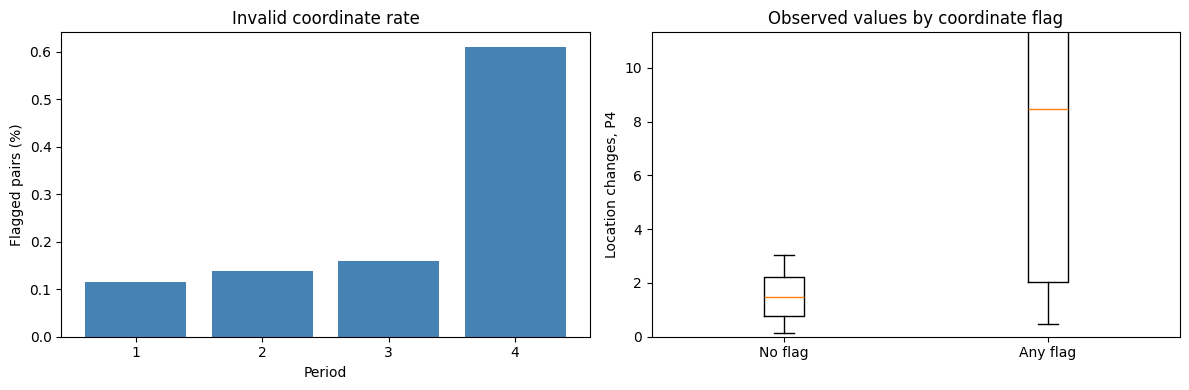

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(coord_period_table.period.astype(str), coord_period_table.rate_pct, color="steelblue")
axes[0].set_xlabel("Period")
axes[0].set_ylabel("Flagged pairs (%)")
axes[0].set_title("Invalid coordinate rate")
coord_groups = [test_clean.loc[coord_count.eq(0), "location_changes_4"].dropna(),
                test_clean.loc[coord_count.gt(0), "location_changes_4"].dropna()]
axes[1].boxplot(coord_groups, tick_labels=["No flag", "Any flag"], whis=(5, 95), showfliers=False)
axes[1].set_ylim(0, pd.concat(coord_groups).quantile(0.99))
axes[1].set_ylabel("Location changes, P4")
axes[1].set_title("Observed values by coordinate flag")
fig.tight_layout()
plt.show()

Observations: **218 players** have at least one flagged coordinate period, and **158 of the 265** flagged period pairs occur in Period 4. Flagged players have a median `location_changes_4` of **8.478** versus **1.490** for unflagged players, and observed VPN-positive rates of **35.7%** versus **15.7%**. Invalid coordinates therefore co-occur with unusual movement, although a data-quality flag is not evidence of account theft by itself.

#### 3.4.2 Negative Count Flags

Inspect the four `-1` flags from `refund_count` and `guild_changes` in Periods 2–3. Show prevalence, overlap within the same period, recurrence across periods, and selected activity/economy values by whether a player has any such flag.

In [62]:
negative_flags = [f"invalid_{column}" for column in invalid_count_cols]
negative_flag_count = test_clean[negative_flags].sum(axis=1)
negative_flag_table = pd.DataFrame({"flag": negative_flags,
                               "players": [int(test_clean[column].sum()) for column in negative_flags]})
negative_flag_table["rate_pct"] = 100 * negative_flag_table.players / len(test_clean)
print(negative_flag_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

                   flag  players  rate_pct
 invalid_refund_count_2     4044    15.621
 invalid_refund_count_3     4141    15.995
invalid_guild_changes_2     2698    10.421
invalid_guild_changes_3     2722    10.514


In [63]:
negative_overlap = pd.DataFrame({
    "comparison": ["refund and guild in P2", "refund and guild in P3",
                   "refund in P2 and P3", "guild in P2 and P3",
                   "any negative-count flag"],
    "players": [int((test_clean.invalid_refund_count_2.eq(1) & test_clean.invalid_guild_changes_2.eq(1)).sum()),
                int((test_clean.invalid_refund_count_3.eq(1) & test_clean.invalid_guild_changes_3.eq(1)).sum()),
                int((test_clean.invalid_refund_count_2.eq(1) & test_clean.invalid_refund_count_3.eq(1)).sum()),
                int((test_clean.invalid_guild_changes_2.eq(1) & test_clean.invalid_guild_changes_3.eq(1)).sum()),
                int(negative_flag_count.gt(0).sum())]
})
negative_overlap["share_all_players_pct"] = 100 * negative_overlap.players / len(test_clean)
print(negative_overlap.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

             comparison  players  share_all_players_pct
 refund and guild in P2      423                  1.634
 refund and guild in P3      427                  1.649
    refund in P2 and P3     1319                  5.095
     guild in P2 and P3      891                  3.442
any negative-count flag    10186                 39.345


In [64]:
negative_group_rows = []
for flagged, label in [(False, "no negative-count flag"), (True, "any negative-count flag")]:
    group = test_clean.loc[negative_flag_count.gt(0) == flagged]
    negative_group_rows.append({"group": label, "players": len(group),
                                "activity_4_observed": int(group.activity_level_4.notna().sum()),
                                "activity_4_median": group.activity_level_4.median(),
                                "purchase_frequency_4_median": group.purchase_frequency_4.median(),
                                "currency_transfers_4_median": group.currency_transfers_4.median()})
negative_group_table = pd.DataFrame(negative_group_rows)
print(negative_group_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

                  group  players  activity_4_observed  activity_4_median  purchase_frequency_4_median  currency_transfers_4_median
 no negative-count flag    15703                14902              0.990                        2.531                        5.015
any negative-count flag    10186                 9710              0.981                        2.526                        4.908


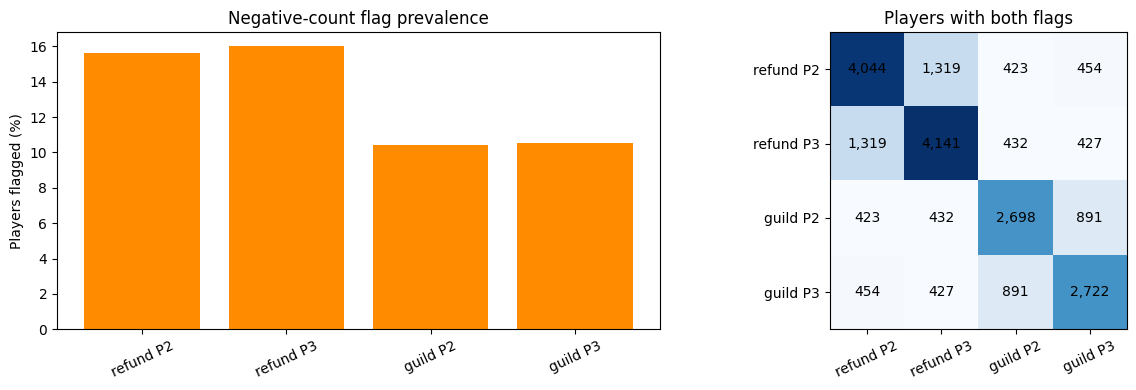

In [65]:
flag_matrix = test_clean[negative_flags].astype("int32").T.dot(test_clean[negative_flags].astype("int32"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(4), negative_flag_table.rate_pct, color="darkorange")
axes[0].set_xticks(range(4), labels=["refund P2", "refund P3", "guild P2", "guild P3"], rotation=25)
axes[0].set_ylabel("Players flagged (%)")
axes[0].set_title("Negative-count flag prevalence")
axes[1].imshow(flag_matrix, cmap="Blues")
axes[1].set_xticks(range(4), labels=["refund P2", "refund P3", "guild P2", "guild P3"], rotation=25)
axes[1].set_yticks(range(4), labels=["refund P2", "refund P3", "guild P2", "guild P3"])
for row in range(4):
    for column in range(4):
        axes[1].text(column, row, f"{flag_matrix.iloc[row, column]:,}", ha="center", va="center")
axes[1].set_title("Players with both flags")
fig.tight_layout()
plt.show()

Observations: **10,186 players** have at least one of the four `-1` flags, but their median Period-4 activity, purchase frequency, and currency transfers are similar to unflagged players. The `-1` values look like an encoding artifact of Periods 2–3 rather than a behavior pattern.

#### 3.4.3 Missingness Relationships

Use **raw** predictor missing counts so the `NaN` values introduced by masking cannot mechanically inflate the association with invalid flags. Compare raw missingness by flag status and report its rank correlation with the number of invalid flags.

In [66]:
raw_missing_count = test_raw[feature_cols].isna().sum(axis=1)
invalid_flag_count = test_clean[flag_cols].sum(axis=1)
missing_group_rows = []
for flagged, label in [(False, "no invalid flag"), (True, "any invalid flag")]:
    values = raw_missing_count.loc[invalid_flag_count.gt(0) == flagged]
    missing_group_rows.append({"group": label, "players": len(values),
                               "median_raw_missing": values.median(),
                               "P95_raw_missing": values.quantile(0.95),
                               "mean_raw_missing": values.mean()})
missing_group_table = pd.DataFrame(missing_group_rows)
print(missing_group_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

           group  players  median_raw_missing  P95_raw_missing  mean_raw_missing
 no invalid flag    15568               6.000           10.000             5.977
any invalid flag    10321               6.000           10.000             5.916


In [67]:
missing_relationship = pd.DataFrame([{
    "players": len(test_raw), "raw_missing_median": raw_missing_count.median(),
    "raw_missing_P95": raw_missing_count.quantile(0.95),
    "raw_missing_max": raw_missing_count.max(),
    "players_with_any_invalid_flag": int(invalid_flag_count.gt(0).sum()),
    "spearman_missing_vs_invalid_count": raw_missing_count.corr(invalid_flag_count, method="spearman")
}])
print(missing_relationship.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

 players  raw_missing_median  raw_missing_P95  raw_missing_max  players_with_any_invalid_flag  spearman_missing_vs_invalid_count
   25889              6.0000          10.0000               18                          10321                            -0.0139


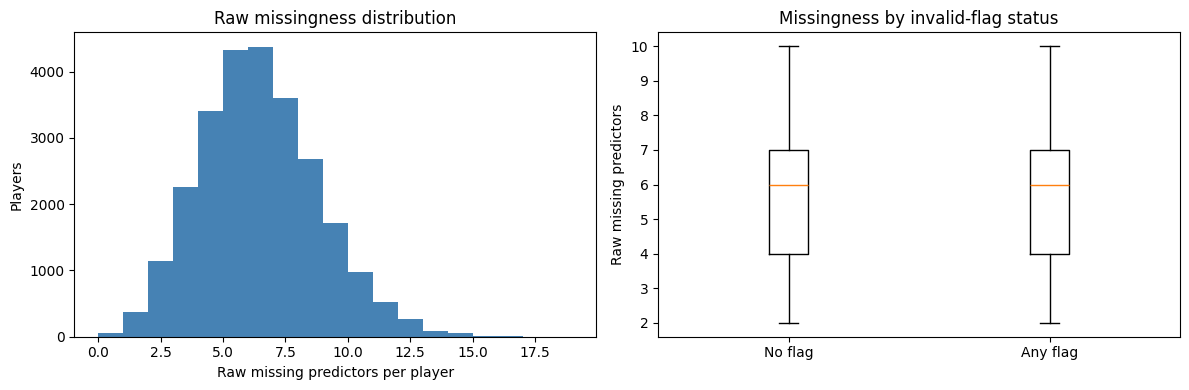

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw_missing_count, bins=range(int(raw_missing_count.max()) + 2), color="steelblue")
axes[0].set_xlabel("Raw missing predictors per player")
axes[0].set_ylabel("Players")
axes[0].set_title("Raw missingness distribution")
missing_groups = [raw_missing_count.loc[invalid_flag_count.eq(0)],
                  raw_missing_count.loc[invalid_flag_count.gt(0)]]
axes[1].boxplot(missing_groups, tick_labels=["No flag", "Any flag"], whis=(5, 95), showfliers=False)
axes[1].set_ylabel("Raw missing predictors")
axes[1].set_title("Missingness by invalid-flag status")
fig.tight_layout()
plt.show()

Observations: the median raw missing count is **6** whether or not a player has an invalid-value flag, and the Spearman correlation between raw missing count and invalid-flag count is **−0.014**. Missingness appears spread almost uniformly across players and is unrelated to the invalid-value flags.

### 3.5 Cross-Domain Behavioral Exploration

Explore five multi-feature patterns that combine related behavior domains without assigning labels or using thresholds as fraud rules. The data card gives no timestamp direction. A difference between Periods 3 and 4 is therefore a consecutive-period change, not necessarily a post-event change. The following views use cleaned values only.

For the location/device view, calculate great-circle distance between observed P3 and P4 coordinate pairs. This is distance between two recorded locations; without timestamps or period-level location details it is not travel speed or proof of impossible travel. Scatter plots sample at most 5,000 complete players with a fixed seed for readability; plotted axes use their 1st–99th percentile ranges, while the summary table below uses all eligible players.

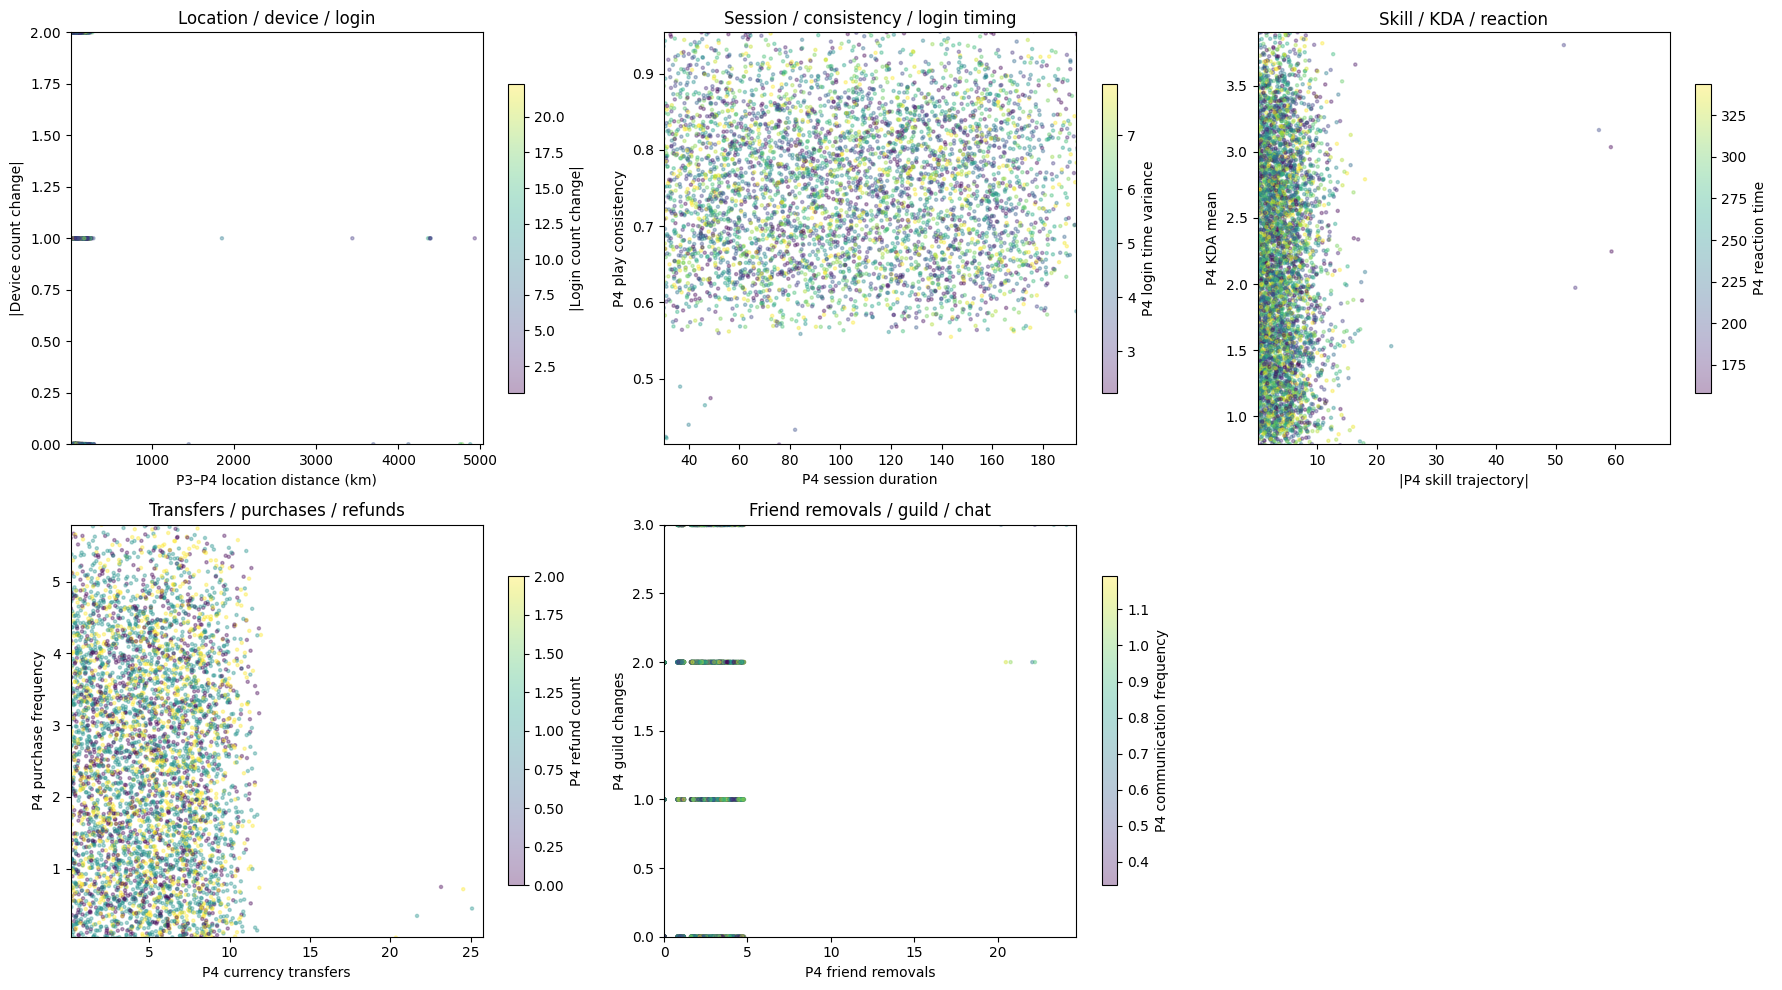

In [69]:
lat3, lat4 = np.radians(test_clean.login_lat_3), np.radians(test_clean.login_lat_4)
lon3, lon4 = np.radians(test_clean.login_lon_3), np.radians(test_clean.login_lon_4)
a = np.sin((lat4 - lat3) / 2) ** 2 + np.cos(lat3) * np.cos(lat4) * np.sin((lon4 - lon3) / 2) ** 2
distance_km_34 = 6371 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))
device_step_34 = (test_clean.device_count_4 - test_clean.device_count_3).abs()
login_step_34 = (test_clean.login_count_4 - test_clean.login_count_3).abs()
cross_domain_views = {
    "Location / device / login": pd.DataFrame({"x": distance_km_34, "y": device_step_34, "color": login_step_34}),
    "Session / consistency / login timing": pd.DataFrame({"x": test_clean.session_duration_mean_4,
        "y": test_clean.play_pattern_consistency_4, "color": test_clean.login_time_variance_4}),
    "Skill / KDA / reaction": pd.DataFrame({"x": test_clean.skill_trajectory_4.abs(),
        "y": test_clean.kda_mean_4, "color": test_clean.reaction_time_mean_4}),
    "Transfers / purchases / refunds": pd.DataFrame({"x": test_clean.currency_transfers_4,
        "y": test_clean.purchase_frequency_4, "color": test_clean.refund_count_4}),
    "Friend removals / guild / chat": pd.DataFrame({"x": test_clean.friend_removes_4,
        "y": test_clean.guild_changes_4, "color": test_clean.communication_frequency_4}),
}
view_labels = {
    "Location / device / login": ("P3–P4 location distance (km)", "|Device count change|", "|Login count change|"),
    "Session / consistency / login timing": ("P4 session duration", "P4 play consistency", "P4 login time variance"),
    "Skill / KDA / reaction": ("|P4 skill trajectory|", "P4 KDA mean", "P4 reaction time"),
    "Transfers / purchases / refunds": ("P4 currency transfers", "P4 purchase frequency", "P4 refund count"),
    "Friend removals / guild / chat": ("P4 friend removals", "P4 guild changes", "P4 communication frequency"),
}
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, frame) in zip(axes.flat, cross_domain_views.items()):
    observed = frame.dropna()
    sample = observed.sample(n=min(5000, len(observed)), random_state=SEED)
    xlo, xhi = observed.x.quantile([0.01, 0.99])
    ylo, yhi = observed.y.quantile([0.01, 0.99])
    clo, chi = observed.color.quantile([0.05, 0.95])
    points = ax.scatter(sample.x, sample.y, c=sample.color.clip(clo, chi),
                        s=5, alpha=0.35, cmap="viridis", vmin=clo, vmax=chi, rasterized=True)
    ax.set_xlim(xlo, xhi)
    ax.set_ylim(ylo, yhi)
    ax.set_title(name)
    ax.set_xlabel(view_labels[name][0])
    ax.set_ylabel(view_labels[name][1])
    fig.colorbar(points, ax=ax, label=view_labels[name][2], shrink=0.75)
axes.flat[-1].axis("off")
fig.tight_layout()
plt.show()

Quantify how often both x and y fall in their own values at or above their own 95th percentiles among complete observations for each view. Discrete features can have many ties at the threshold, so the selected group can exceed 5%. The same complete rows set both thresholds. This is a descriptive overlap, not a classifier; larger overlap can arise from ordinary relationships, and the color variable is context rather than part of the overlap rule.

In [70]:
joint_rows = []
for name, frame in cross_domain_views.items():
    observed = frame.dropna()
    x_high = observed.x.ge(observed.x.quantile(0.95))
    y_high = observed.y.ge(observed.y.quantile(0.95))
    joint_rows.append({"view": name, "complete_players": len(observed),
                       "x_at_or_above_P95": int(x_high.sum()),
                       "y_at_or_above_P95": int(y_high.sum()),
                       "both_players": int((x_high & y_high).sum()),
                       "both_pct": 100 * (x_high & y_high).mean()})
joint_table = pd.DataFrame(joint_rows)
print(joint_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

                                view  complete_players  x_at_or_above_P95  y_at_or_above_P95  both_players  both_pct
           Location / device / login             17276                864               2968           173     1.001
Session / consistency / login timing             22266               1114               1114            70     0.314
              Skill / KDA / reaction             22321               1117               1117           211     0.945
     Transfers / purchases / refunds             22359               1118               1118            56     0.250
      Friend removals / guild / chat             22284               1115               3974           328     1.472


Compare baseline behavior across account-age quartiles. Quartile groups use observed `account_age_days`; the table reports medians and group sizes, without treating account age as a fraud indicator.

In [71]:
age_group = pd.qcut(test_clean.account_age_days, q=4, labels=["Q1 newest", "Q2", "Q3", "Q4 oldest"], duplicates="drop")
age_summary = (test_clean.assign(age_group=age_group)
               .groupby("age_group", observed=True)
               .agg(players=(ID, "size"), age_median=("account_age_days", "median"),
                    activity_median=("activity_level_4", "median"),
                    session_median=("session_duration_mean_4", "median"),
                    transfers_median=("currency_transfers_4", "median"),
                    friends_median=("friend_removes_4", "median")))
print(age_summary.to_string(float_format=lambda value: f"{value:.3f}"))

           players  age_median  activity_median  session_median  transfers_median  friends_median
age_group                                                                                        
Q1 newest     6155     347.304            0.986         102.745             4.842           2.021
Q2            6155     678.871            0.988         100.962             5.031           2.013
Q3            6154    1010.051            0.982         102.129             5.017           2.006
Q4 oldest     6155    1337.275            0.989         102.638             5.008           2.012


For the social view, check friend additions alongside removals, guild changes, and communication. Pairwise Spearman correlations describe association across these four Period-4 measurements; they do not define a social-risk score.

In [72]:
social_columns = ["friend_adds_4", "friend_removes_4", "guild_changes_4", "communication_frequency_4"]
social_corr = test_clean[social_columns].corr(method="spearman")
print(social_corr.to_string(float_format=lambda value: f"{value:.3f}"))

                           friend_adds_4  friend_removes_4  guild_changes_4  communication_frequency_4
friend_adds_4                      1.000             0.032            0.035                     -0.039
friend_removes_4                   0.032             1.000            0.023                      0.008
guild_changes_4                    0.035             0.023            1.000                     -0.016
communication_frequency_4         -0.039             0.008           -0.016                      1.000


Observations: the five views quantify how often two related behaviors are jointly high among complete rows and show combinations worth inspecting, without identifying confirmed anomalies. For discrete values such as device and guild counts, ties at P95 make the jointly-high group larger than 5%. Account-age quartiles have similar Period-4 medians for activity, session duration, transfers, and friend removals, so this coarse age split shows no large central shift in those behaviors.

### 3.6 Candidate Extreme-Behavior Groups

Investigate two candidate groups observed in Section 3.1: A is in the Period-4 upper 1% of both `location_changes` and `currency_transfers`; B is in the upper 1% of both `skill_trajectory` and `friend_removes`. Thresholds are computed among observed values, and missing values do not enter a tail. These are post-hoc descriptive groups, not anomaly labels or fraud rules. The data card does not identify which period is newest.

Count the four individual tails and their intersections. For each pair, compare the double-tail group with accounts in only one tail. This makes the contrast more informative than comparing only with the large remainder. The independence expectation is an arithmetic reference based on full-row marginal rates, not a significance test.

In [73]:
focus_families = ["location_changes", "currency_transfers", "skill_trajectory", "friend_removes"]
tail_1pct = pd.DataFrame({family: test_clean[f"{family}_4"].ge(test_clean[f"{family}_4"].quantile(0.99))
                          for family in focus_families})
a_location = tail_1pct.location_changes
a_transfer = tail_1pct.currency_transfers
b_skill = tail_1pct.skill_trajectory
b_friend = tail_1pct.friend_removes
group_a = a_location & a_transfer
group_b = b_skill & b_friend
group_counts = pd.DataFrame([
    {"pair": "A: location + transfers", "left_tail": int(a_location.sum()),
     "right_tail": int(a_transfer.sum()), "both": int(group_a.sum()),
     "left_only": int((a_location & ~a_transfer).sum()),
     "right_only": int((~a_location & a_transfer).sum()),
     "independent_expected_both": a_location.sum() * a_transfer.sum() / len(test_clean)},
    {"pair": "B: skill + friend removes", "left_tail": int(b_skill.sum()),
     "right_tail": int(b_friend.sum()), "both": int(group_b.sum()),
     "left_only": int((b_skill & ~b_friend).sum()),
     "right_only": int((~b_skill & b_friend).sum()),
     "independent_expected_both": b_skill.sum() * b_friend.sum() / len(test_clean)},
])
print(group_counts.to_string(index=False, float_format=lambda value: f"{value:.2f}")
      + f"\nA and B overlap: {int((group_a & group_b).sum())} players")

                     pair  left_tail  right_tail  both  left_only  right_only  independent_expected_both
  A: location + transfers        247         247    83        164         164                       2.36
B: skill + friend removes        246         247   199         47          48                       2.35
A and B overlap: 0 players


Compare the flags and account-age distributions for each pair separately. A `positive_pct` uses only observed values for that flag; `observed` is printed alongside it. The invalid-coordinate flag is always observed because it was created in Section 2.8. Supplied security flags are features, not labels.

In [74]:
geo_flag = test_clean[[f"invalid_login_coord_{period}" for period in range(1, 5)]].eq(1).any(axis=1)
cohorts = {
    "A both": group_a,
    "A location only": a_location & ~a_transfer,
    "A transfers only": ~a_location & a_transfer,
    "B both": group_b,
    "B skill only": b_skill & ~b_friend,
    "B friend only": ~b_skill & b_friend,
    "Neither A nor B": ~(group_a | group_b),
}
flag_rows = []
for name, mask in cohorts.items():
    rows = test_clean.loc[mask]
    flag_rows.append({"cohort": name, "players": len(rows),
                      "geo_flag_count": int(geo_flag.loc[mask].sum()),
                      "geo_flag_pct": 100 * geo_flag.loc[mask].mean(),
                      "account_age_median": rows.account_age_days.median(),
                      **{f"{flag}_observed": int(rows[flag].notna().sum())
                         for flag in security_flags},
                      **{f"{flag}_positive_pct": 100 * rows[flag].eq(1).sum() / rows[flag].notna().sum()
                         for flag in security_flags}})
flag_cohorts = pd.DataFrame(flag_rows)
print(flag_cohorts.to_string(index=False, float_format=lambda value: f"{value:.2f}"))

          cohort  players  geo_flag_count  geo_flag_pct  account_age_median  password_changed_observed  vpn_usage_observed  suspicious_login_time_observed  mass_item_sale_observed  password_changed_positive_pct  vpn_usage_positive_pct  suspicious_login_time_positive_pct  mass_item_sale_positive_pct
          A both       83              31         37.35              946.44                         76                  80                              74                       76                         100.00                   18.75                                2.70                        67.11
 A location only      164              31         18.90              789.58                        152                 157                             155                      155                          17.11                   86.62                                4.52                        14.19
A transfers only      164              53         32.32              846.60                        1

Compare other behavior within the same cohorts, using paired changes only where both periods are observed. The location distance is between recorded P3/P4 coordinates, not travel speed. `device_change_pct` uses paired device counts; median changes use their own observed pairs.

In [75]:
behavior_rows = []
for name, mask in cohorts.items():
    rows = test_clean.loc[mask]
    device_change = (rows.device_count_4 - rows.device_count_3).abs()
    kda_change = rows.kda_mean_4 - rows.kda_mean_3
    rating_change = rows.skill_rating_4 - rows.skill_rating_3
    behavior_rows.append({"cohort": name, "players": len(rows),
                          "device_pairs": int(device_change.notna().sum()),
                          "device_change_pct": 100 * device_change.gt(0).sum() / device_change.notna().sum(),
                          "location_distance_pairs": int(distance_km_34.loc[mask].notna().sum()),
                          "location_distance_median_km": distance_km_34.loc[mask].median(),
                          "kda_pairs": int(kda_change.notna().sum()),
                          "kda_change_median": kda_change.median(),
                          "rating_change_median": rating_change.median(),
                          "reaction_change_median": (rows.reaction_time_mean_4 - rows.reaction_time_mean_3).median()})
behavior_cohorts = pd.DataFrame(behavior_rows)
print(behavior_cohorts.to_string(index=False, float_format=lambda value: f"{value:.2f}"))

          cohort  players  device_pairs  device_change_pct  location_distance_pairs  location_distance_median_km  kda_pairs  kda_change_median  rating_change_median  reaction_change_median
          A both       83            71              78.87                       40                      8320.90         81              -0.02                -13.61                   -1.31
 A location only      164           154              74.68                      102                      5469.22        149              -0.01                  8.55                    2.22
A transfers only      164           144              86.81                       87                      7765.60        146              -0.02                -14.07                    1.97
          B both      199           175              81.14                      160                        80.56        181               2.35               2036.59                  -78.18
    B skill only       47            42              76

Check whether the pairwise tail overlap survives nearby thresholds. The 0.5%, 1%, and 2% cutoffs were selected for a sensitivity check after seeing the 1% result. The expected overlap is calculated from the marginal tail rates across all rows. A/B intersection tests whether the two double-tail definitions select the same players at each cutoff.

In [76]:
sensitivity_rows = []
for upper_share in (0.005, 0.01, 0.02):
    tails = {family: test_clean[f"{family}_4"].ge(test_clean[f"{family}_4"].quantile(1 - upper_share))
             for family in focus_families}
    a = tails["location_changes"] & tails["currency_transfers"]
    b = tails["skill_trajectory"] & tails["friend_removes"]
    for label, left, right, both in [
        ("A", tails["location_changes"], tails["currency_transfers"], a),
        ("B", tails["skill_trajectory"], tails["friend_removes"], b),
    ]:
        expected = left.sum() * right.sum() / len(test_clean)
        sensitivity_rows.append({"upper_tail_pct": 100 * upper_share, "group": label,
                                 "left_players": int(left.sum()), "right_players": int(right.sum()),
                                 "both_players": int(both.sum()),
                                 "expected_if_independent": expected,
                                 "observed_to_expected": both.sum() / expected,
                                 "A_and_B_players": int((a & b).sum())})
sensitivity_table = pd.DataFrame(sensitivity_rows)
print(sensitivity_table.to_string(index=False, float_format=lambda value: f"{value:.2f}"))

 upper_tail_pct group  left_players  right_players  both_players  expected_if_independent  observed_to_expected  A_and_B_players
           0.50     A           124            124            13                     0.59                 21.89                0
           0.50     B           123            124            52                     0.59                 88.27                0
           1.00     A           247            247            83                     2.36                 35.22                0
           1.00     B           246            247           199                     2.35                 84.79                0
           2.00     A           493            494           280                     9.41                 29.76                0
           2.00     B           492            494           288                     9.39                 30.68                0


Show the full Period-4 value range for both candidate pairs. Gray points are all players with both values observed; orange points are the double-tail group. Dashed lines mark each feature’s 99th percentile. No axis clipping is applied, so large values remain visible.

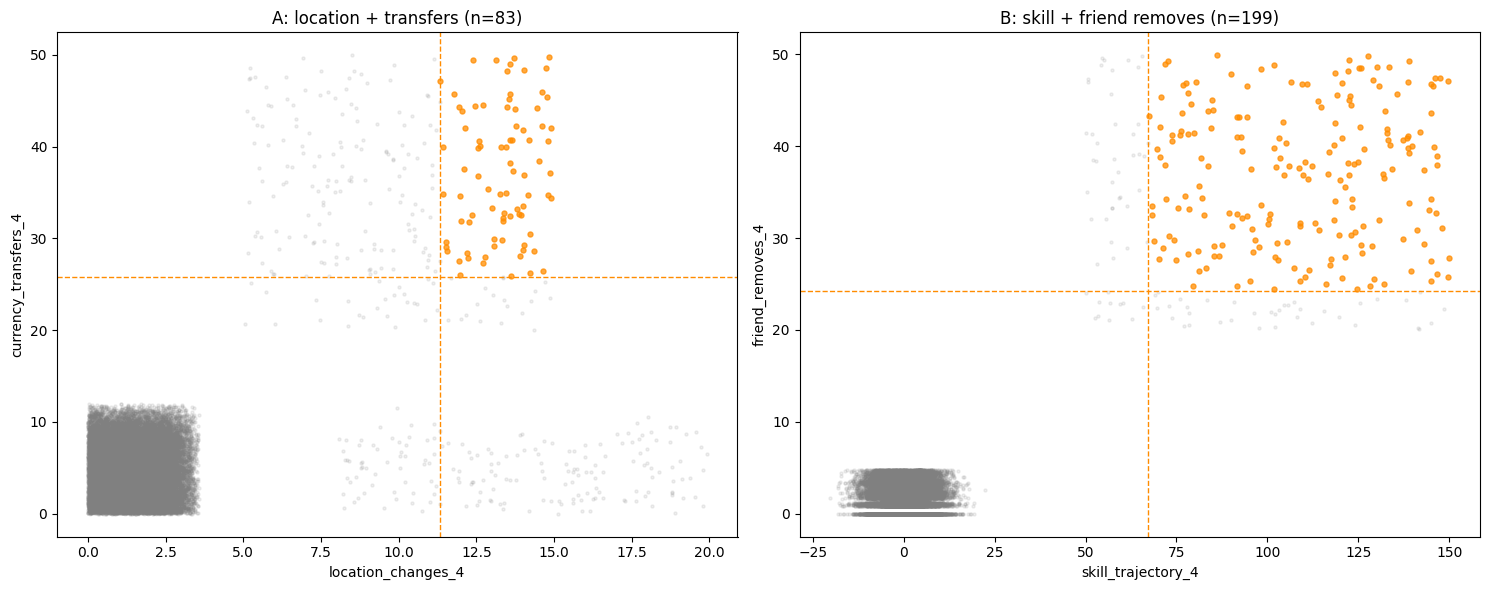

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (x_family, y_family, selected, title) in zip(axes, [
    ("location_changes", "currency_transfers", group_a, "A: location + transfers"),
    ("skill_trajectory", "friend_removes", group_b, "B: skill + friend removes"),
]):
    x = test_clean[f"{x_family}_4"]
    y = test_clean[f"{y_family}_4"]
    observed = x.notna() & y.notna()
    ax.scatter(x[observed & ~selected], y[observed & ~selected], s=5, alpha=0.12, color="gray", rasterized=True)
    ax.scatter(x[selected], y[selected], s=13, alpha=0.75, color="darkorange", rasterized=True)
    ax.axvline(x.quantile(0.99), color="darkorange", linestyle="--", linewidth=1)
    ax.axhline(y.quantile(0.99), color="darkorange", linestyle="--", linewidth=1)
    ax.set_xlabel(f"{x_family}_4")
    ax.set_ylabel(f"{y_family}_4")
    ax.set_title(f"{title} (n={int(selected.sum())})")
fig.tight_layout()
plt.show()

Sample up to 12 players from each double-tail group with a fixed random seed and plot all four periods. The lines show observed values only and retain the full vertical range. These examples illustrate within-player patterns and do not establish why the values changed.

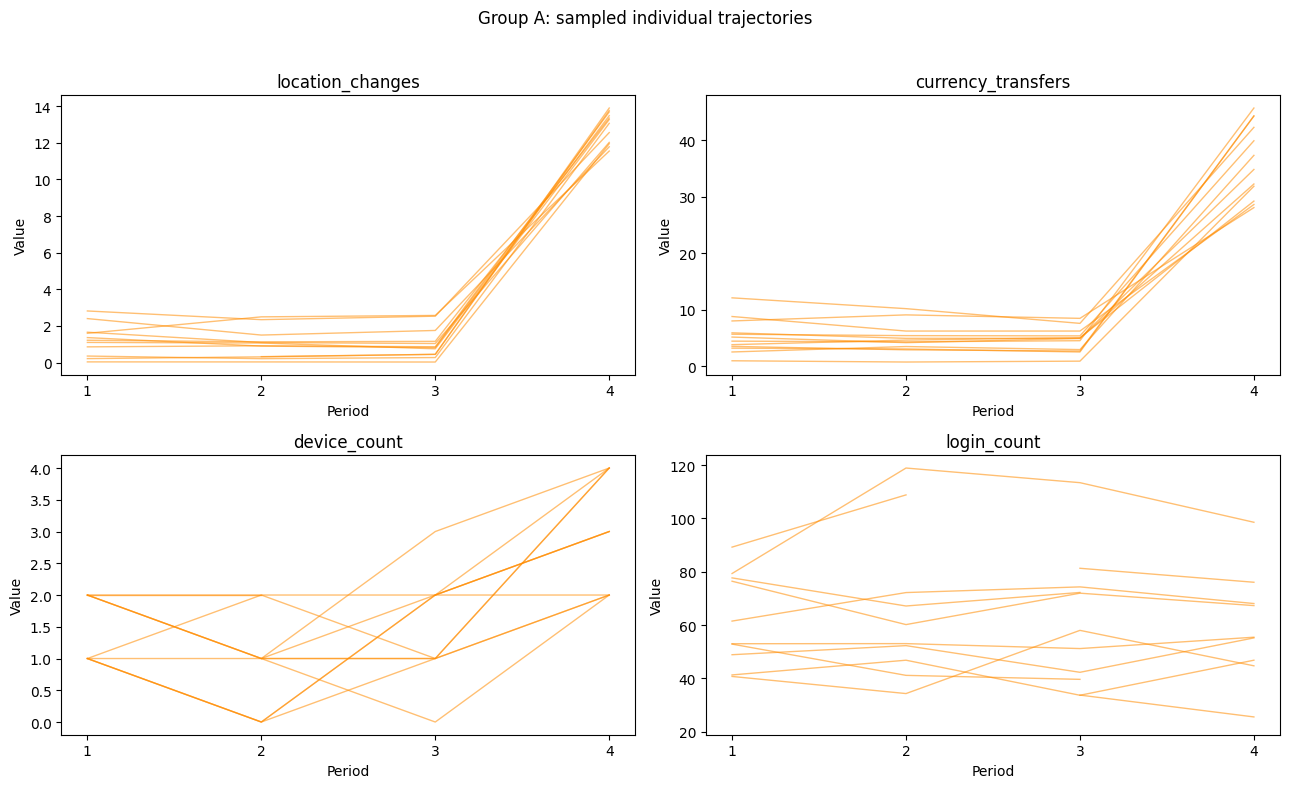

In [78]:
sample_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sample_a = sample_rng.choice(test_clean.index[group_a].to_numpy(), size=min(12, int(group_a.sum())), replace=False)
for ax, family in zip(axes.flat, ["location_changes", "currency_transfers", "device_count", "login_count"]):
    for row in sample_a:
        ax.plot(range(1, 5), test_clean.loc[row, [f"{family}_{period}" for period in range(1, 5)]].to_numpy(dtype=float),
                color="darkorange", alpha=0.55, linewidth=1)
    ax.set_title(family)
    ax.set_xticks(range(1, 5))
    ax.set_xlabel("Period")
    ax.set_ylabel("Value")
fig.suptitle("Group A: sampled individual trajectories")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

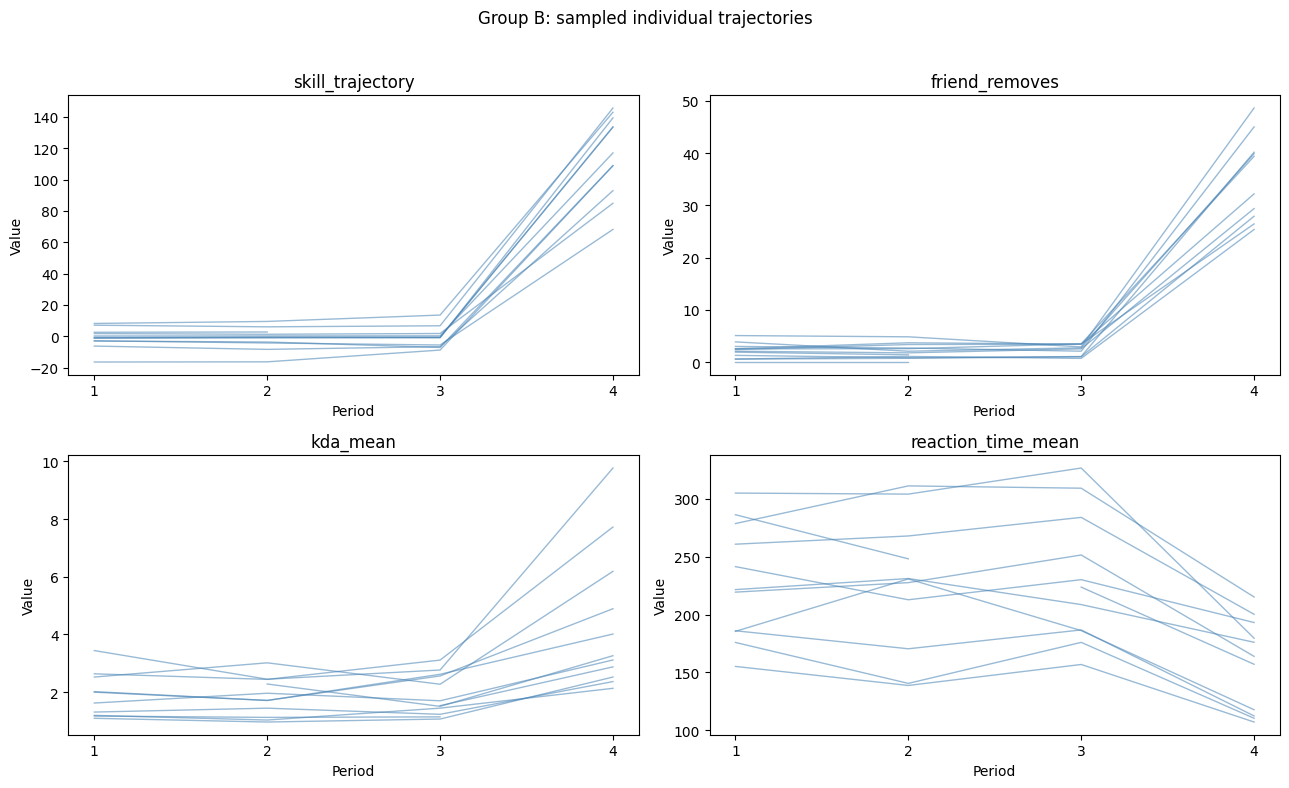

In [79]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sample_b = sample_rng.choice(test_clean.index[group_b].to_numpy(), size=min(12, int(group_b.sum())), replace=False)
for ax, family in zip(axes.flat, ["skill_trajectory", "friend_removes", "kda_mean", "reaction_time_mean"]):
    for row in sample_b:
        ax.plot(range(1, 5), test_clean.loc[row, [f"{family}_{period}" for period in range(1, 5)]].to_numpy(dtype=float),
                color="steelblue", alpha=0.55, linewidth=1)
    ax.set_title(family)
    ax.set_xticks(range(1, 5))
    ax.set_xlabel("Period")
    ax.set_ylabel("Value")
fig.suptitle("Group B: sampled individual trajectories")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

Observations from the candidate groups:

- At the Period-4 upper-1% threshold, group A contains **83** players and group B **199**; the groups do not overlap. Their within-pair overlap exceeds the arithmetic independence reference (**2.36** and **2.35** players, respectively). At upper-0.5% and upper-2%, both pairs still overlap far more often than that reference, though group membership and overlap strength change with the cutoff. These groups were selected after inspecting the data, so this is exploratory evidence of tail dependence, not a validated detector.
- Group A has invalid-coordinate flags for **31/83 (37.35%)** players. Its observed `password_changed` rate is **76/76 (100%)** and `mass_item_sale` rate **67.11%**. Yet the transfer-only group also has **100%** observed password changes and **68.55%** mass-item sales. VPN is **18.75%** in A versus **86.62%** in the location-only group. The two-feature intersection therefore does not uniquely explain these flag patterns. The supplied flags are model inputs, not truth labels.
- Group B has paired median P4−P3 changes of **+2.35 KDA**, **+2,036.59 skill rating**, and **−78.18 reaction time**. Skill-only and friend-only groups show similar shifts, so the intersection is not clearly a distinct behavioral subtype on these measurements.
- Median account age is **946** days in A, **894** in B, and **844** outside both; these descriptive differences do not establish an age effect. Only **40/83** A players have valid paired P3/P4 coordinates for a distance calculation, so distance summaries for A are especially selective.
- The scatter plots show the full Period-4 tails, and the sampled trajectories show sharp P3-to-P4 changes in both groups. No account was relabeled, removed, or used to fit a model.

### 3.7 EDA Conclusions and Hypotheses

EDA cannot identify anomalies, but it narrows down where an unusual account should show up. Five hypotheses carry forward into feature engineering and the experiment rounds:

- **H1 — Sudden change matters more than level.** Period medians barely move, yet a small subset of players shows very large P3→P4 jumps in `skill_trajectory`, `location_changes`, `currency_transfers`, and `friend_removes` (Sections 3.1–3.2). If anomalous accounts are those whose behavior changed abruptly (for example after a takeover or sale), within-player change features should describe them better than raw period values. → temporal features, Section 4.2.
- **H2 — Location movement matters, measured only as recorded distance.** Players with invalid coordinates move far more and use VPNs more often (Section 3.4.1). Distance between recorded coordinate pairs may reflect account sharing or theft; without timestamps it is not travel speed. → geographic features, Section 4.3.
- **H3 — Data-quality artifacts may or may not be signal.** The `-1` counts and missingness look unrelated to behavior (Sections 3.4.2–3.4.3), while invalid coordinates co-occur with unusual movement. Quality indicators are therefore built as a separate group so their effect can be isolated. → Section 4.4.
- **H4 — Supplied security flags are inputs, not labels.** Groups A and B show unusual password-change and item-sale rates, but neighboring single-tail groups show the same rates (Section 3.6). The flags are kept out of the behavioral baseline so their influence can be measured. → Sections 4.1 and 4.5.
- **H5 — Extreme behavior forms co-occurring tails.** The tail pairs A (location + transfers) and B (skill trajectory + friend removals) overlap far more than independence predicts at several cutoffs. A reasonable detector should rank such players high. Because A and B were chosen after looking at the data, their coverage is used only to *describe* what a model favors, never to judge it.

## 4. Feature Engineering

Create candidate feature views from the provided Task 5 data. All formulas operate row by row and preserve the original 25,889 player IDs. This section creates no labels, model scores, fitted preprocessing, or submission. Missing inputs remain missing when a value cannot be calculated.

### 4.1 Input and Feature Design

Use `test_clean` from Section 2.8 as the common input. Keep `player_id` separate from predictors. The four supplied security flags are held out of the behavioral baseline so their effect can be inspected later. The cleaned raw coordinates are also held out of that baseline; geographic distances are introduced as a separate feature group. `account_age_days` and `behavior_stability` remain in the baseline as supplied non-period predictors. Holding the security flags out follows H4.

In [80]:
security_cols = security_flags.copy()
raw_coordinate_cols = [f"login_{coord}_{period}" for period in range(1, 5) for coord in ("lat", "lon")]
behavior_cols = [column for column in feature_cols
                 if column not in security_cols and column not in raw_coordinate_cols]
player_ids = test_clean[ID].copy()
assert len(feature_cols) == 122 and len(security_cols) == 4 and len(raw_coordinate_cols) == 8
assert len(behavior_cols) == 110
assert player_ids.equals(test_raw[ID]) and player_ids.is_unique
design_table = pd.DataFrame([
    {"input_group": "cleaned original predictors", "columns": len(feature_cols)},
    {"input_group": "behavioral raw baseline", "columns": len(behavior_cols)},
    {"input_group": "held-out raw coordinates", "columns": len(raw_coordinate_cols)},
    {"input_group": "held-out security flags", "columns": len(security_cols)},
])
print(design_table.to_string(index=False))

                input_group  columns
cleaned original predictors      122
    behavioral raw baseline      110
   held-out raw coordinates        8
    held-out security flags        4


### 4.2 Temporal Features

For 16 selected four-period families, calculate P4−P3, its absolute value, P4 minus the median of observed P1–P3, maximum absolute adjacent change, four-period range, and four-period population standard deviation. The selection spans login, location/device, gameplay, performance, economy, and social behavior. `baseline_shift` needs at least one observed earlier period; range/std need at least two observed periods; `max_adjacent_change` needs at least one complete adjacent pair. Period 4 is simply an endpoint in the supplied sequence, not a verified “latest” period. These features operationalize H1.

In [81]:
temporal_selected = [
    "login_count", "login_time_variance", "location_changes", "device_count",
    "ip_hash_entropy", "activity_level", "session_duration_mean",
    "play_pattern_consistency", "skill_rating", "skill_trajectory",
    "kda_mean", "reaction_time_mean", "currency_transfers",
    "purchase_amount_mean", "friend_removes", "communication_frequency",
]
assert all(all(f"{family}_{period}" in feature_cols for period in range(1, 5))
           for family in temporal_selected)
temporal_features = pd.DataFrame(index=test_clean.index)
for family in temporal_selected:
    values = test_clean[[f"{family}_{period}" for period in range(1, 5)]].copy()
    values.columns = range(1, 5)
    earlier_median = values[[1, 2, 3]].median(axis=1)
    adjacent = pd.concat([(values[period + 1] - values[period]).abs()
                          for period in range(1, 4)], axis=1)
    has_two_values = values.notna().sum(axis=1).ge(2)
    delta34 = values[4] - values[3]
    temporal_features[f"{family}__delta34"] = delta34
    temporal_features[f"{family}__abs_delta34"] = delta34.abs()
    temporal_features[f"{family}__baseline_shift"] = values[4] - earlier_median
    temporal_features[f"{family}__max_adjacent_change"] = adjacent.max(axis=1)
    temporal_features[f"{family}__temporal_range"] = (values.max(axis=1) - values.min(axis=1)).where(has_two_values)
    temporal_features[f"{family}__temporal_std"] = values.std(axis=1, ddof=0).where(has_two_values)
assert temporal_features.shape == (len(test_clean), 96)
print(f"Selected families: {len(temporal_selected)} | Generated temporal features: {temporal_features.shape[1]} | Rows: {len(temporal_features):,}")

Selected families: 16 | Generated temporal features: 96 | Rows: 25,889


Inspect a compact summary of the new temporal values before combining them with raw predictors. Large values are retained. The table reports every generated column’s missing rate and three quantiles, so later preprocessing can be chosen from observed ranges rather than guesses.

In [82]:
temporal_review = pd.DataFrame({
    "missing_pct": 100 * temporal_features.isna().mean(),
    "median": temporal_features.median(),
    "P95": temporal_features.quantile(0.95),
    "max": temporal_features.max(),
})
print(temporal_review.to_string(float_format=lambda value: f"{value:,.3f}"))

                                               missing_pct  median     P95       max
login_count__delta34                                 9.433  -0.046  18.477    38.311
login_count__abs_delta34                             9.433   6.667  22.409    39.046
login_count__baseline_shift                          4.782  -0.044  14.635    33.898
login_count__max_adjacent_change                     0.684  12.947  32.385    54.146
login_count__temporal_range                          0.046  14.567  33.360    54.146
login_count__temporal_std                            0.046   5.772  13.138    21.029
login_time_variance__delta34                         9.467  -0.001   1.487     3.064
login_time_variance__abs_delta34                     9.467   0.558   1.817     3.064
login_time_variance__baseline_shift                  4.948  -0.004   1.223     3.064
login_time_variance__max_adjacent_change             0.695   1.027   2.432     3.929
login_time_variance__temporal_range                  0.027   1.22

### 4.3 Geographic Features

Compute Haversine distance between consecutive recorded coordinate pairs after invalid coordinate pairs were masked in Section 2.8. A distance is missing if either endpoint lacks valid latitude or longitude. `geo_jump_max` uses observed adjacent distances and stays missing when none exist. `geo_valid_pair_count` records availability and is placed with quality indicators, not with distance features. Distance between recorded locations is not travel speed. These features operationalize H2.

In [83]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1 = np.radians(lat1), np.radians(lon1)
    lat2, lon2 = np.radians(lat2), np.radians(lon2)
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 6371.0088 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))

geo_features = pd.DataFrame(index=test_clean.index)
jump_cols = []
for period in range(1, 4):
    name = f"geo_jump_{period}{period + 1}_km"
    jump_cols.append(name)
    geo_features[name] = haversine_km(
        test_clean[f"login_lat_{period}"], test_clean[f"login_lon_{period}"],
        test_clean[f"login_lat_{period + 1}"], test_clean[f"login_lon_{period + 1}"],
    )
geo_features["geo_jump_max_km"] = geo_features[jump_cols].max(axis=1)
geo_valid_pair_count = geo_features[jump_cols].notna().sum(axis=1).rename("geo_valid_pair_count")
geo_review = pd.DataFrame({"observed": geo_features.notna().sum(),
                           "missing_pct": 100 * geo_features.isna().mean(),
                           "median_km": geo_features.median(),
                           "P95_km": geo_features.quantile(0.95),
                           "max_km": geo_features.max()})
print(geo_review.to_string(float_format=lambda value: f"{value:,.2f}"))

                 observed  missing_pct  median_km  P95_km    max_km
geo_jump_12_km      21141        18.34      83.95  181.10    323.13
geo_jump_23_km      21211        18.07      83.99  184.16  7,059.13
geo_jump_34_km      21033        18.76      84.82  190.81 13,233.76
geo_jump_max_km     25168         2.78     116.19  213.52 13,233.76


In [84]:
pair_count_table = geo_valid_pair_count.value_counts().reindex(range(4), fill_value=0).rename_axis("valid_adjacent_pairs").reset_index(name="players")
pair_count_table["share_pct"] = 100 * pair_count_table.players / len(test_clean)
print(pair_count_table.to_string(index=False, float_format=lambda value: f"{value:.2f}"))

 valid_adjacent_pairs  players  share_pct
                    0      721       2.78
                    1     4170      16.11
                    2     3779      14.60
                    3    17219      66.51


### 4.4 Quality and Missing Indicators

Use the **raw** 122-predictor missing count to avoid counting NaNs introduced by quality cleaning as original missingness. Add two invalid-value counts, the four-period valid-coordinate-pair count, and the eight existing `invalid_` flags. The counts and their component flags are intentionally both available for later ablation; they are not proof of suspicious behavior. Keeping them as a separate group follows H3.

In [85]:
quality_features = pd.DataFrame(index=test_clean.index)
quality_features["raw_missing_count"] = test_raw[feature_cols].isna().sum(axis=1)
quality_features["invalid_geo_count"] = test_clean[[f"invalid_login_coord_{period}" for period in range(1, 5)]].sum(axis=1)
quality_features["invalid_count_count"] = test_clean[[f"invalid_{column}" for column in invalid_count_cols]].sum(axis=1)
quality_features["geo_valid_pair_count"] = geo_valid_pair_count
for column in flag_cols:
    quality_features[column] = test_clean[column]
assert quality_features.shape == (len(test_clean), 12)
quality_review = pd.DataFrame({"min": quality_features.min(), "median": quality_features.median(),
                               "max": quality_features.max(),
                               "missing_pct": 100 * quality_features.isna().mean()})
print(quality_review.to_string(float_format=lambda value: f"{value:.2f}"))

                         min  median  max  missing_pct
raw_missing_count          0    6.00   18         0.00
invalid_geo_count          0    0.00    3         0.00
invalid_count_count        0    0.00    4         0.00
geo_valid_pair_count       0    3.00    3         0.00
invalid_login_coord_1      0    0.00    1         0.00
invalid_login_coord_2      0    0.00    1         0.00
invalid_login_coord_3      0    0.00    1         0.00
invalid_login_coord_4      0    0.00    1         0.00
invalid_refund_count_2     0    0.00    1         0.00
invalid_refund_count_3     0    0.00    1         0.00
invalid_guild_changes_2    0    0.00    1         0.00
invalid_guild_changes_3    0    0.00    1         0.00


### 4.5 Feature Sets

Keep every feature set aligned to the same players. F0 is a behavioral raw baseline; F1 adds temporal values; F2 adds geographic distances. F3 and F4 branch independently from F2 to isolate security and quality indicators. F5 includes both. F6 is a separate baseline containing all 122 cleaned original predictors, including raw coordinates and security flags. The sets are candidates for controlled model comparisons, not a ranking of quality.

In [86]:
feature_sets = {
    "F0_behavior_raw": test_clean[behavior_cols].copy(),
    "F1_temporal": pd.concat([test_clean[behavior_cols], temporal_features], axis=1),
    "F2_geographic": pd.concat([test_clean[behavior_cols], temporal_features, geo_features], axis=1),
    "F3_security": pd.concat([test_clean[behavior_cols], temporal_features, geo_features,
                                test_clean[security_cols]], axis=1),
    "F4_quality": pd.concat([test_clean[behavior_cols], temporal_features, geo_features,
                               quality_features], axis=1),
    "F5_security_quality": pd.concat([test_clean[behavior_cols], temporal_features, geo_features,
                                        test_clean[security_cols], quality_features], axis=1),
    "F6_full_cleaned_raw": test_clean[feature_cols].copy(),
}
feature_set_summary = pd.DataFrame([{
    "set": name, "rows": len(frame), "columns": frame.shape[1],
    "missing_cells": int(frame.isna().sum().sum()),
    "missing_pct": 100 * frame.isna().sum().sum() / frame.size,
} for name, frame in feature_sets.items()])
print(feature_set_summary.to_string(index=False, float_format=lambda value: f"{value:.2f}"))

                set  rows  columns  missing_cells  missing_pct
    F0_behavior_raw 25889      110         152417         5.35
        F1_temporal 25889      206         253983         4.76
      F2_geographic 25889      210         268986         4.95
        F3_security 25889      214         274191         4.95
         F4_quality 25889      222         268986         4.68
F5_security_quality 25889      226         274191         4.69
F6_full_cleaned_raw 25889      122         168232         5.33


### 4.6 Feature Verification and Findings

Verify alignment, formulas, finite observed values, and the intended feature-group differences before any fitting. The checks below leave `NaN` in place for Section 5 and do not alter the original `test_raw` or cleaned `test_clean` frames.

In [87]:
expected_columns = {"F0_behavior_raw": 110, "F1_temporal": 206,
                    "F2_geographic": 210, "F3_security": 214,
                    "F4_quality": 222, "F5_security_quality": 226,
                    "F6_full_cleaned_raw": 122}
verification_rows = []
for name, frame in feature_sets.items():
    assert frame.index.equals(test_clean.index)
    assert len(frame) == len(player_ids) and frame.shape[1] == expected_columns[name]
    assert not frame.columns.duplicated().any() and ID not in frame and TARGET not in frame
    assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in frame.dtypes)
    infinite_cells = int(np.isinf(frame.to_numpy(dtype=float)).sum())
    assert infinite_cells == 0
    verification_rows.append({"set": name, "aligned_rows": len(frame),
                              "unique_columns": frame.shape[1], "infinite_cells": infinite_cells,
                              "all_missing_columns": int(frame.isna().all().sum())})
verification_table = pd.DataFrame(verification_rows)
print(verification_table.to_string(index=False))

                set  aligned_rows  unique_columns  infinite_cells  all_missing_columns
    F0_behavior_raw         25889             110               0                    0
        F1_temporal         25889             206               0                    0
      F2_geographic         25889             210               0                    0
        F3_security         25889             214               0                    0
         F4_quality         25889             222               0                    0
F5_security_quality         25889             226               0                    0
F6_full_cleaned_raw         25889             122               0                    0


In [88]:
assert temporal_features["skill_trajectory__delta34"].equals(
    test_clean.skill_trajectory_4 - test_clean.skill_trajectory_3)
assert temporal_features["skill_trajectory__abs_delta34"].equals(
    temporal_features["skill_trajectory__delta34"].abs())
assert geo_features["geo_jump_34_km"].notna().equals(
    test_clean[["login_lat_3", "login_lon_3", "login_lat_4", "login_lon_4"]].notna().all(axis=1))
assert geo_features.loc[geo_valid_pair_count.eq(0), "geo_jump_max_km"].isna().all()
assert quality_features.raw_missing_count.equals(test_raw[feature_cols].isna().sum(axis=1))
pd.testing.assert_frame_equal(test_raw, pd.read_csv(test_path))
print(f"Formula checks passed | IDs unchanged: {player_ids.equals(test_raw[ID])} | raw frame unchanged: True | model fitting performed: False")

Formula checks passed | IDs unchanged: True | raw frame unchanged: True | model fitting performed: False


Observations from feature engineering:

- Section 4 creates **96 temporal features** from 16 selected families, **4 geographic distance features**, and **12 quality/missing indicators**. It keeps the 122 cleaned original predictors available as a separate baseline. No row or ID was removed.
- The seven feature sets contain **110, 206, 210, 214, 222, 226, and 122** numeric columns, respectively. F3 adds security flags to F2; F4 independently adds quality indicators to F2; F5 includes both. This makes later ablations interpretable without assuming that more columns improve detection.
- Missing values remain meaningful at this stage: `delta34` is missing for roughly 9% of players in many families, while `max_adjacent_change` usually has more coverage because any one valid adjacent pair is enough. Geographic jumps are observed for **21,141**, **21,211**, and **21,033** players across P1–P2, P2–P3, and P3–P4; **721** players have no valid adjacent geographic pair. `geo_jump_max_km` is missing for those players.
- All feature sets retain **25,889** aligned rows, contain no duplicate columns, no all-missing columns, and no infinite observed values. Original `test_raw` is unchanged. The feature-set missing percentages are not a quality ranking because adding fully observed indicators changes the denominator.
- These are candidate representations only. Section 5 will fit any imputation, transformation, or scaling on the designated fit split and apply it to the same validation players; no model-quality conclusion follows from feature creation alone.

## 5. Preprocessing

Prepare the candidate feature sets for the unsupervised comparisons. Fitting on the unlabeled Task 5 file is permitted (Section 0.3), but the internal split below only checks whether a fitted procedure gives repeatable rankings on held-out players; it cannot measure F₃ or detection accuracy. The EDA already inspected the whole file, so the split is not a fully independent test of the feature hypotheses. No model is fitted in this section.

### 5.1 Fixed Internal Split

Use one reproducible 80/20 player split for every feature set. IDs stay separate from model inputs. The same validation rows will be scored by every later experiment, allowing fair rank and Top-K comparisons.

In [89]:
from sklearn.model_selection import train_test_split

fit_idx, validation_idx = train_test_split(
    np.arange(len(test_clean)), test_size=0.20, random_state=SEED, shuffle=True
)
assert len(fit_idx) + len(validation_idx) == len(test_clean)
assert not np.intersect1d(fit_idx, validation_idx).size
fit_ids = player_ids.iloc[fit_idx].copy()
validation_ids = player_ids.iloc[validation_idx].copy()
assert fit_ids.is_unique and validation_ids.is_unique
print(f"Seed: {SEED} | Fit players: {len(fit_idx):,} | Validation players: {len(validation_idx):,} | Shared IDs: {len(set(fit_ids) & set(validation_ids))}")

Seed: 42 | Fit players: 20,711 | Validation players: 5,178 | Shared IDs: 0


### 5.2 Missing Value Treatment

For each feature set, learn numeric medians and binary modes only from its fit rows. Apply those values to validation rows later. The four supplied security flags and eight `invalid_` flags are treated as binary; all other columns are numeric. Empty fit columns would require a separate decision, so stop if one appears rather than silently removing a feature. The fitting step is written as a function so that feature sets created in later rounds receive exactly the same treatment.

In [90]:
binary_candidates = set(security_cols + flag_cols)
imputation_states = {}


def fit_imputation_state(name):
    frame = feature_sets[name]
    numeric_cols = [column for column in frame.columns if column not in binary_candidates]
    binary_cols = [column for column in frame.columns if column in binary_candidates]
    fit_frame = frame.iloc[fit_idx]
    numeric_fill = fit_frame[numeric_cols].median()
    binary_fill = fit_frame[binary_cols].mode(dropna=True).iloc[0] if binary_cols else pd.Series(dtype=float)
    assert numeric_fill.notna().all() and binary_fill.notna().all()
    assert set(binary_fill.unique()) <= {0, 1}
    imputation_states[name] = {"numeric_cols": numeric_cols, "binary_cols": binary_cols,
                               "numeric_fill": numeric_fill, "binary_fill": binary_fill}
    return {"set": name, "numeric_cols": len(numeric_cols), "binary_cols": len(binary_cols),
            "fit_missing_before": int(fit_frame.isna().sum().sum()),
            "validation_missing_before": int(frame.iloc[validation_idx].isna().sum().sum())}


imputation_table = pd.DataFrame([fit_imputation_state(name) for name in feature_sets])
print(imputation_table.to_string(index=False))

                set  numeric_cols  binary_cols  fit_missing_before  validation_missing_before
    F0_behavior_raw           110            0              122242                      30175
        F1_temporal           206            0              203589                      50394
      F2_geographic           210            0              215568                      53418
        F3_security           210            4              219716                      54475
         F4_quality           214            8              215568                      53418
F5_security_quality           214           12              219716                      54475
F6_full_cleaned_raw           118            4              134859                      33373


### 5.3 Scaling

Fit a `RobustScaler` (median and interquartile range) on the imputed numeric fit rows of each feature set. A robust scaler is used because many features have long upper tails that would dominate a mean/standard-deviation scaler. Binary 0/1 columns are imputed but left unscaled. Distance- and density-based detectors use this scaled view, while Isolation Forest uses the imputed, unscaled view because tree splits do not depend on scale. No validation value is used to choose an imputation value or scaling parameter.

In [91]:
from sklearn.preprocessing import RobustScaler

preprocessing_states = {}


def fit_scaling_state(name):
    impute = imputation_states[name]
    fit_numeric = feature_sets[name].iloc[fit_idx][impute["numeric_cols"]].fillna(impute["numeric_fill"])
    preprocessing_states[name] = {**impute, "scaler": RobustScaler().fit(fit_numeric),
                                  "fit_row_count": len(fit_numeric)}
    return {"set": name, "scaled_numeric_cols": len(impute["numeric_cols"]), "fit_rows_used": len(fit_numeric)}


scaler_table = pd.DataFrame([fit_scaling_state(name) for name in feature_sets])
print(scaler_table.to_string(index=False))

                set  scaled_numeric_cols  fit_rows_used
    F0_behavior_raw                  110          20711
        F1_temporal                  206          20711
      F2_geographic                  210          20711
        F3_security                  210          20711
         F4_quality                  214          20711
F5_security_quality                  214          20711
F6_full_cleaned_raw                  118          20711


Transform rows with an already fitted state. The function preserves feature names and row indices, fills missing values, and scales only numeric columns when requested; `scale=False` returns the imputed, unscaled view. It performs no fitting.

In [92]:
def transform_feature_set(name, row_idx, scale=True):
    state = preprocessing_states[name]
    numeric_cols, binary_cols = state["numeric_cols"], state["binary_cols"]
    transformed = feature_sets[name].iloc[row_idx].copy()
    transformed[numeric_cols] = transformed[numeric_cols].fillna(state["numeric_fill"])
    if binary_cols:
        transformed[binary_cols] = transformed[binary_cols].fillna(state["binary_fill"])
    if scale:
        transformed[numeric_cols] = state["scaler"].transform(transformed[numeric_cols])
    return transformed


print("Ready: transform_feature_set(name, row_idx, scale=True)")

Ready: transform_feature_set(name, row_idx, scale=True)


### 5.4 Preprocessing Verification

Apply every fitted state to the fit and validation indices. Check that output columns and row indices match their inputs, observed outputs are finite, no missing value remains, binary values stay 0/1, and each scaler saw exactly the fit rows. The check is also a function so it can be reused for feature sets added later.

In [93]:
def verify_preprocessing(name):
    state = preprocessing_states[name]
    fit_prepared = transform_feature_set(name, fit_idx)
    validation_prepared = transform_feature_set(name, validation_idx)
    for prepared, rows in ((fit_prepared, fit_idx), (validation_prepared, validation_idx)):
        assert prepared.columns.equals(feature_sets[name].columns)
        assert prepared.index.equals(feature_sets[name].iloc[rows].index)
        assert prepared.notna().all().all() and np.isfinite(prepared.to_numpy(dtype=float)).all()
        if state["binary_cols"]:
            assert set(prepared[state["binary_cols"]].stack().unique()) <= {0, 1}
    assert state["fit_row_count"] == len(fit_idx)
    return {"set": name, "fit_rows": len(fit_prepared), "validation_rows": len(validation_prepared),
            "columns": fit_prepared.shape[1],
            "missing_after": int(fit_prepared.isna().sum().sum() + validation_prepared.isna().sum().sum())}


preprocessing_check = pd.DataFrame([verify_preprocessing(name) for name in feature_sets])
print(preprocessing_check.to_string(index=False))

                set  fit_rows  validation_rows  columns  missing_after
    F0_behavior_raw     20711             5178      110              0
        F1_temporal     20711             5178      206              0
      F2_geographic     20711             5178      210              0
        F3_security     20711             5178      214              0
         F4_quality     20711             5178      222              0
F5_security_quality     20711             5178      226              0
F6_full_cleaned_raw     20711             5178      122              0


As a direct leakage check, compare a few stored fill values with medians computed from fit rows, and confirm they differ from full-file medians where the data happen to differ. This checks the actual stored values rather than relying only on how the code is written.

In [94]:
leakage_columns = ["login_count_4", "skill_trajectory_4", "currency_transfers_4", "geo_jump_34_km"]
leakage_rows = []
for column in leakage_columns:
    state = imputation_states["F2_geographic"]
    fit_median = feature_sets["F2_geographic"].iloc[fit_idx][column].median()
    full_median = feature_sets["F2_geographic"][column].median()
    stored_fill = state["numeric_fill"][column]
    assert np.isclose(stored_fill, fit_median)
    leakage_rows.append({"feature": column, "stored_fit_fill": stored_fill,
                         "fit_median": fit_median, "full_file_median_reference": full_median})
leakage_check = pd.DataFrame(leakage_rows)
print(leakage_check.to_string(index=False, float_format=lambda value: f"{value:,.5f}"))

             feature  stored_fit_fill  fit_median  full_file_median_reference
       login_count_4         58.88916    58.88916                    58.96272
  skill_trajectory_4          0.01578     0.01578                     0.03695
currency_transfers_4          4.97564     4.97564                     4.97760
      geo_jump_34_km         84.87192    84.87192                    84.82296


Observations from preprocessing:

- A fixed seed-42 split assigns **20,711** players to the fit portion and **5,178** to validation, with no shared IDs. Every feature set uses the same indices, so every later model scores exactly the same validation players.
- Numeric missing values use fit-split medians; binary security and invalid-value flags use fit-split modes. Numeric columns are scaled with a `RobustScaler` fitted on the imputed fit rows; binary columns stay unscaled.
- All seven feature sets keep their columns and produce finite fit/validation matrices with **0** remaining missing cells.
- Stored fill values match fit-split medians. For example, `skill_trajectory_4` uses **0.01578** from the fit split, while its full-file median is **0.03695**, which confirms that validation rows did not influence the fill values.

## 6. Evaluation Method Without Labels

Before fitting any detector, fix how detectors will be compared. In Rounds 1–3 every detector is fitted on the same 20,711 fit players and scores the same 5,178 validation players, so rankings can be compared directly player by player.

### 6.1 What Can and Cannot Be Measured

No table in this notebook can say whether a flagged player is truly anomalous. The diagnostics measure **how a model behaves**:

- **Alert budget (Top-K).** Rankings are compared through their top K validation players. Rounds 1–2 use the top 1% (K = 52). Comparing equally sized sets avoids comparing raw anomaly scores, whose scales differ across models and feature sets.
- **Top-K Jaccard** = players in both sets ÷ players in either set. A value of 1 means identical selections and 0 means disjoint ones. A low Jaccard means two models disagree, not that either is wrong.
- **Spearman rank correlation** over all 5,178 validation players. It can be high even when the very top players differ, so it is read together with Jaccard.
- **Resampling stability.** A model is refitted on three random 80% subsets of the fit rows, with its preprocessing refitted inside each subset, and the three Top-K sets are compared. A stable model selects similar players whichever unlabeled players it saw. Stability is necessary for a usable detector, but it does not show that the selected players are correct.
- **Selection profile.** The number of selected players from EDA groups A and B, and the share with an invalid-value flag or a supplied security flag. Because A and B were defined from the same features after inspecting the file, their coverage is *circular* as a quality measure; it only shows which kind of extreme behavior a model favors.

These caveats apply to every diagnostic table in Sections 7–9 and are not repeated each time.

### 6.2 Shared Comparison Helpers

Every round uses the helpers below, so each comparison is computed the same way. `fit_only_imputed` and `resample_stability` implement the resampling protocol: the three 80% subsets are drawn once with a fixed seed and shared by all models.

In [95]:
TOP_K = round(0.01 * len(validation_idx))
validation_audit = test_clean.iloc[validation_idx].set_index(ID)
validation_raw_missing = pd.Series(test_raw.iloc[validation_idx][feature_cols].isna().sum(axis=1).to_numpy(),
                                   index=validation_ids.to_numpy())
a_validation_ids = set(player_ids.loc[group_a]) & set(validation_ids)
b_validation_ids = set(player_ids.loc[group_b]) & set(validation_ids)
assert TOP_K == 52 and not a_validation_ids & b_validation_ids


def top_k_ids(scores, k):
    return set(scores.nlargest(k).index)


def jaccard(left, right):
    return len(left & right) / len(left | right)


def compare_rankings(left_scores, right_scores, k):
    left, right = top_k_ids(left_scores, k), top_k_ids(right_scores, k)
    common = len(left & right)
    return {"common": common, "left_only": len(left) - common, "right_only": len(right) - common,
            "jaccard": jaccard(left, right), "spearman": left_scores.corr(right_scores, method="spearman")}


def validation_profile(ids):
    ids = set(ids)
    group = validation_audit.loc[list(ids)]
    return {"players": len(ids), "A_members": len(ids & a_validation_ids),
            "B_members": len(ids & b_validation_ids),
            "outside_A_B": len(ids - a_validation_ids - b_validation_ids),
            "raw_missing_median": validation_raw_missing.loc[list(ids)].median(),
            "any_invalid_pct": 100 * group[flag_cols].eq(1).any(axis=1).mean()}


def fit_only_imputed(feature_set, subset):
    """Refit median/mode imputation on one fit subset and apply it to the fixed validation rows."""
    frame = feature_sets[feature_set]
    numeric = imputation_states[feature_set]["numeric_cols"]
    binary = imputation_states[feature_set]["binary_cols"]
    fit_part = frame.iloc[subset].copy()
    validation_part = frame.iloc[validation_idx].copy()
    numeric_fill = fit_part[numeric].median()
    assert numeric_fill.notna().all()
    fit_part[numeric] = fit_part[numeric].fillna(numeric_fill)
    validation_part[numeric] = validation_part[numeric].fillna(numeric_fill)
    if binary:
        binary_fill = fit_part[binary].mode(dropna=True).iloc[0]
        fit_part[binary] = fit_part[binary].fillna(binary_fill)
        validation_part[binary] = validation_part[binary].fillna(binary_fill)
    return fit_part, validation_part


resample_rng = np.random.default_rng(SEED + 100)
resample_indices = [resample_rng.choice(fit_idx, size=round(0.80 * len(fit_idx)), replace=False)
                    for _ in range(3)]


def resample_stability(fit_and_score, k):
    """Refit on the three shared subsets and compare the replicate Top-K selections pairwise."""
    replicates = [fit_and_score(subset) for subset in resample_indices]
    pairs = [(0, 1), (0, 2), (1, 2)]
    jaccards = [jaccard(top_k_ids(replicates[i], k), top_k_ids(replicates[j], k)) for i, j in pairs]
    spearmans = [replicates[i].corr(replicates[j], method="spearman") for i, j in pairs]
    return {"mean_jaccard": np.mean(jaccards), "min_jaccard": np.min(jaccards),
            "mean_spearman": np.mean(spearmans)}


print(f"Validation Top-K: {TOP_K} | resample subsets: {len(resample_indices)} × {len(resample_indices[0]):,} fit players"
      f" | group A/B members in validation: {len(a_validation_ids)}/{len(b_validation_ids)}")

Validation Top-K: 52 | resample subsets: 3 × 16,569 fit players | group A/B members in validation: 18/51


## 7. Round 1 — Isolation Forest Across Feature Sets

### 7.1 Hypothesis

H1 and H2 claim that within-player change and location movement describe unusual accounts better than raw period values. Round 1 tests this by holding **one detector fixed** and changing only the representation:

| Experiment | Feature set | What changes |
| --- | --- | --- |
| E01 | F0 behavioral raw (110 columns) | baseline |
| E02 | F1 temporal (206) | + 96 temporal change features (H1) |
| E03 | F2 geographic (210) | + 4 recorded-distance features (H2) |
| E04 | F6 full cleaned raw (122) | raw coordinates and security flags, no engineered features |

If the temporal and geographic features carry the signal that EDA suggests, E02 and E03 should select a noticeably different, more change-driven set of players than E01. Isolation Forest is the first detector because it needs no scaling, copes with mixed feature scales, and flags points that random axis-aligned splits isolate quickly. It is a neutral starting point, not an assumed best model.

### 7.2 Model

All four fits use the fit-only median/mode imputation from Section 5 without scaling. Parameters are fixed before any result is seen: 300 trees, 256 sampled rows per tree (the subsample size recommended by the original Isolation Forest paper), and seed 42. A larger `-score_samples` value means a more unusual player. `contamination="auto"` does not set the alert budget; the fixed Top-K from Section 6 does. One caveat matters later: the 96 temporal columns are correlated, so they can give some behavior families more weight in the random splits.

In [96]:
from sklearn.ensemble import IsolationForest

IF_PARAMS = {"n_estimators": 300, "max_samples": 256, "contamination": "auto",
             "random_state": SEED, "n_jobs": -1}
round1_sets = {"E01": "F0_behavior_raw", "E02": "F1_temporal",
               "E03": "F2_geographic", "E04": "F6_full_cleaned_raw"}
model_results = {}
experiment_records = {}


def fit_isolation_experiment(experiment, feature_set):
    if experiment in model_results:
        return experiment_records[experiment]
    fit_frame = transform_feature_set(feature_set, fit_idx, scale=False)
    validation_frame = transform_feature_set(feature_set, validation_idx, scale=False)
    assert fit_frame.columns.equals(validation_frame.columns)
    started = perf_counter()
    model = IsolationForest(**IF_PARAMS).fit(fit_frame)
    scores = pd.Series(-model.score_samples(validation_frame), index=validation_ids.to_numpy(), name=experiment)
    assert scores.index.is_unique and np.isfinite(scores.to_numpy()).all()
    model_results[experiment] = {"model": model, "feature_set": feature_set, "validation_scores": scores}
    experiment_records[experiment] = {"experiment": experiment, "feature_set": feature_set,
                                      "fit_rows": len(fit_frame), "validation_rows": len(validation_frame),
                                      "features": fit_frame.shape[1], "seconds": perf_counter() - started,
                                      "score_median": scores.median(), "score_P95": scores.quantile(0.95),
                                      "score_P99": scores.quantile(0.99)}
    return experiment_records[experiment]


def show_record(record):
    print(pd.DataFrame([record]).to_string(index=False, float_format=lambda value: f"{value:.4f}"))


print("Round 1 experiments:", ", ".join(f"{key}={value}" for key, value in round1_sets.items()))

Round 1 experiments: E01=F0_behavior_raw, E02=F1_temporal, E03=F2_geographic, E04=F6_full_cleaned_raw


In [97]:
show_record(fit_isolation_experiment("E01", round1_sets["E01"]))

experiment     feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E01 F0_behavior_raw     20711             5178       110   0.7164        0.4742     0.5046     0.5278


In [98]:
show_record(fit_isolation_experiment("E02", round1_sets["E02"]))

experiment feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E02 F1_temporal     20711             5178       206   0.7253        0.4421     0.4803     0.5797


In [99]:
show_record(fit_isolation_experiment("E03", round1_sets["E03"]))

experiment   feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E03 F2_geographic     20711             5178       210   0.7599        0.4381     0.4761     0.5670


In [100]:
show_record(fit_isolation_experiment("E04", round1_sets["E04"]))

experiment         feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E04 F6_full_cleaned_raw     20711             5178       122   0.7515        0.4782     0.5076     0.5245


Summarize the four fits and verify their structure: one model per feature set, scores aligned with the fixed validation IDs, and the intended number of features. Raw score levels differ across feature sets, so this table is a sanity check rather than a leaderboard.

In [101]:
for experiment, feature_set in round1_sets.items():
    result = model_results[experiment]
    assert result["validation_scores"].index.equals(pd.Index(validation_ids.to_numpy()))
    assert result["model"].n_features_in_ == feature_sets[feature_set].shape[1]
    assert result["model"].max_samples_ == IF_PARAMS["max_samples"]
round1_record_table = pd.DataFrame([experiment_records[key] for key in round1_sets])
print(round1_record_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

experiment         feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E01     F0_behavior_raw     20711             5178       110   0.7164        0.4742     0.5046     0.5278
       E02         F1_temporal     20711             5178       206   0.7253        0.4421     0.4803     0.5797
       E03       F2_geographic     20711             5178       210   0.7599        0.4381     0.4761     0.5670
       E04 F6_full_cleaned_raw     20711             5178       122   0.7515        0.4782     0.5076     0.5245


Inspect each validation score distribution on its own x-axis. The figure does not compare raw scores across models or assign an anomaly threshold.

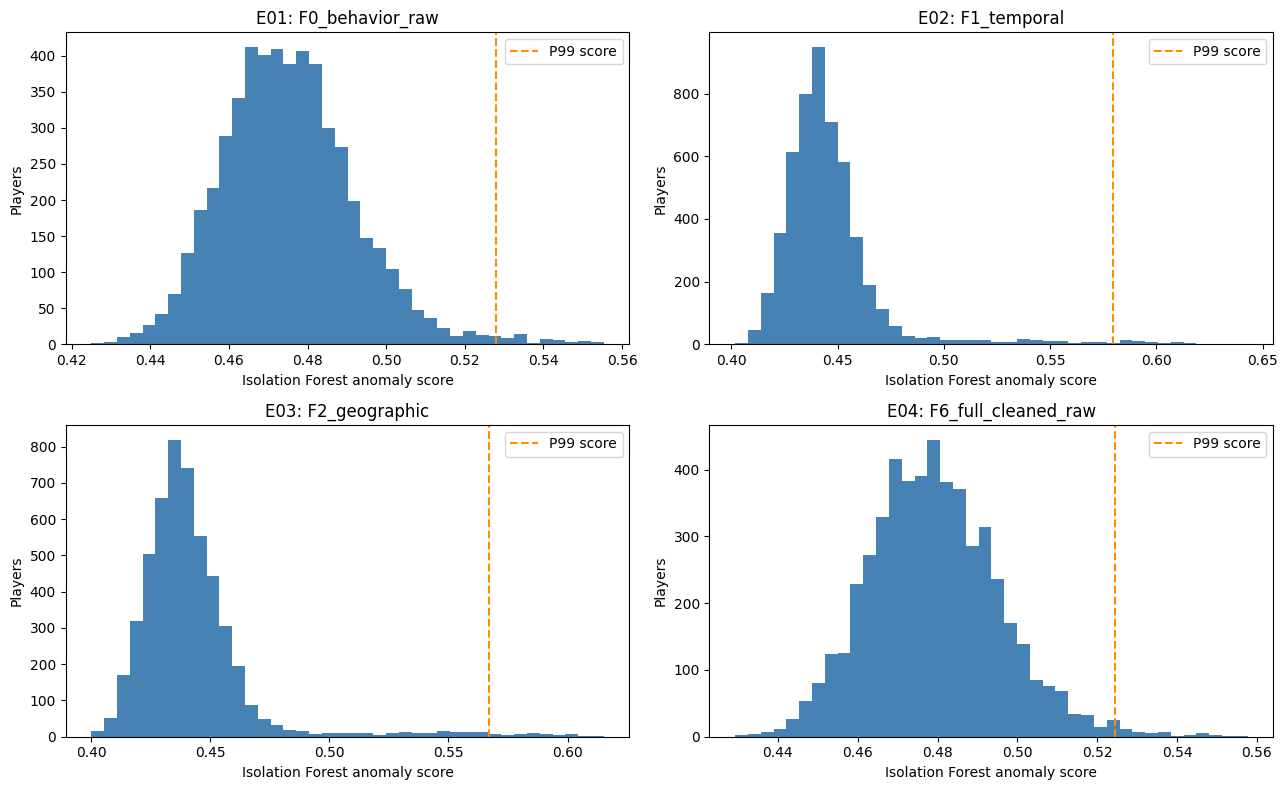

In [102]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, experiment in zip(axes.flat, round1_sets):
    scores = model_results[experiment]["validation_scores"]
    ax.hist(scores, bins=40, color="steelblue")
    ax.axvline(scores.quantile(0.99), color="darkorange", linestyle="--", label="P99 score")
    ax.set_title(f"{experiment}: {round1_sets[experiment]}")
    ax.set_xlabel("Isolation Forest anomaly score")
    ax.set_ylabel("Players")
    ax.legend()
fig.tight_layout()
plt.show()

### 7.3 Analysis

The analysis moves from *how different the four rankings are* (7.3.1–7.3.4) to *why they differ* (7.3.5–7.3.8).

#### 7.3.1 Alert Budget Check

Select the top 1% (52 players) of each ranking. If a cutoff has ties, `nlargest` keeps exactly K rows in their existing order; the tie count shows whether this matters.

In [103]:
topk_sets = {}
budget_rows = []
for experiment in round1_sets:
    scores = model_results[experiment]["validation_scores"]
    topk_sets[experiment] = top_k_ids(scores, TOP_K)
    cutoff = scores.nlargest(TOP_K).min()
    budget_rows.append({"experiment": experiment, "validation_players": len(scores),
                        "top_k": len(topk_sets[experiment]), "share_pct": 100 * TOP_K / len(scores),
                        "score_cutoff": cutoff, "at_cutoff_ties": int(scores.eq(cutoff).sum())})
print(pd.DataFrame(budget_rows).to_string(index=False, float_format=lambda value: f"{value:.5f}"))

experiment  validation_players  top_k  share_pct  score_cutoff  at_cutoff_ties
       E01                5178     52    1.00425       0.52821               1
       E02                5178     52    1.00425       0.58090               1
       E03                5178     52    1.00425       0.56792               1
       E04                5178     52    1.00425       0.52468               1


#### 7.3.2 Feature-Set Ablation

Compare the prespecified pairs. E01→E02 isolates the 96 temporal features and E02→E03 the four geographic distances. E01↔E04 and E03↔E04 change several groups at once, so they are broad comparisons rather than isolated effects.

In [104]:
ablation_pairs = [("E01", "E02", "add temporal"), ("E02", "E03", "add geographic"),
                  ("E01", "E04", "behavioral vs full raw"), ("E03", "E04", "engineered vs full raw")]
ablation_table = pd.DataFrame([{"comparison": f"{left} vs {right}", "change": change,
                                **compare_rankings(model_results[left]["validation_scores"],
                                                   model_results[right]["validation_scores"], TOP_K)}
                               for left, right, change in ablation_pairs])
print(ablation_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

comparison                 change  common  left_only  right_only  jaccard  spearman
E01 vs E02           add temporal       7         45          45    0.072     0.657
E02 vs E03         add geographic      42         10          10    0.677     0.866
E01 vs E04 behavioral vs full raw      33         19          19    0.465     0.784
E03 vs E04 engineered vs full raw       7         45          45    0.072     0.596


#### 7.3.3 Ranking Agreement

Inspect every pair, not only the four prespecified comparisons. Spearman uses all 5,178 score ranks; Jaccard uses only the Top-52 memberships. The two views can disagree when overall rankings are similar but the extreme top changes.

In [105]:
score_frame = pd.DataFrame({experiment: model_results[experiment]["validation_scores"] for experiment in round1_sets})
rank_agreement = score_frame.corr(method="spearman")
top_agreement = pd.DataFrame([[jaccard(topk_sets[left], topk_sets[right]) for right in round1_sets]
                              for left in round1_sets], index=list(round1_sets), columns=list(round1_sets))
print("All-player Spearman rank correlation:\n" + rank_agreement.to_string(float_format=lambda value: f"{value:.3f}")
      + "\n\nTop-52 Jaccard:\n" + top_agreement.to_string(float_format=lambda value: f"{value:.3f}"))

All-player Spearman rank correlation:
      E01   E02   E03   E04
E01 1.000 0.657 0.637 0.784
E02 0.657 1.000 0.866 0.611
E03 0.637 0.866 1.000 0.596
E04 0.784 0.611 0.596 1.000

Top-52 Jaccard:
      E01   E02   E03   E04
E01 1.000 0.072 0.072 0.465
E02 0.072 1.000 0.677 0.040
E03 0.072 0.677 1.000 0.072
E04 0.465 0.040 0.072 1.000


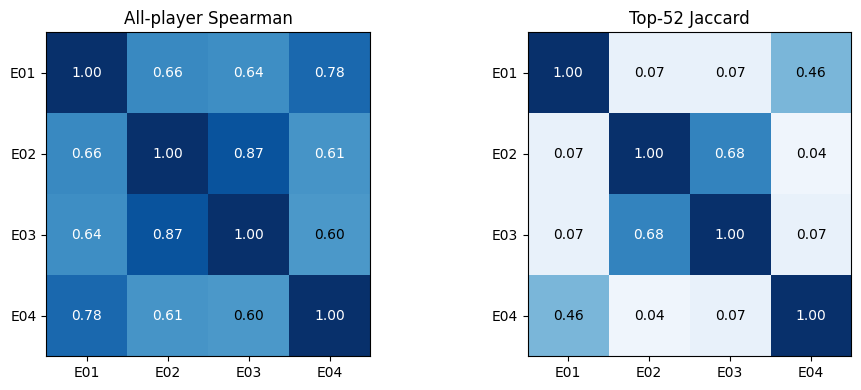

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, matrix, title in [(axes[0], rank_agreement, "All-player Spearman"),
                          (axes[1], top_agreement, "Top-52 Jaccard")]:
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(4), labels=matrix.columns)
    ax.set_yticks(range(4), labels=matrix.index)
    ax.set_title(title)
    for row in range(4):
        for column in range(4):
            ax.text(column, row, f"{matrix.iloc[row, column]:.2f}",
                    ha="center", va="center", color="white" if matrix.iloc[row, column] > 0.6 else "black")
fig.tight_layout()
plt.show()

#### 7.3.4 Resampling Stability

Refit each Round 1 model on the three shared 80% fit subsets (Section 6.2) with the Isolation Forest seed held fixed, refitting imputation inside each subset, and compare the replicate Top-52 sets.

In [107]:
def isolation_resample(feature_set):
    def fit_and_score(subset):
        fit_part, validation_part = fit_only_imputed(feature_set, subset)
        model = IsolationForest(**IF_PARAMS).fit(fit_part)
        return pd.Series(-model.score_samples(validation_part), index=validation_ids.to_numpy())
    return fit_and_score


round1_stability = pd.DataFrame([{"experiment": experiment, **resample_stability(isolation_resample(feature_set), TOP_K)}
                                 for experiment, feature_set in round1_sets.items()])
print(round1_stability.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

experiment  mean_jaccard  min_jaccard  mean_spearman
       E01         0.617        0.600          0.915
       E02         0.814        0.793          0.906
       E03         0.773        0.733          0.907
       E04         0.678        0.651          0.917


#### 7.3.5 Quality and Security Flag Dependence

Compare selected Top-52 players with all validation players on original missingness, any invalid-value flag, and each supplied security flag. Rates for supplied flags use observed values as denominators. These are *associations with model inputs or related data quality*, not validation labels. F0–F2 exclude security flags, while E04 includes them directly.

In [108]:
quality_audit_rows = []
for experiment in ["Validation", *round1_sets]:
    ids = validation_audit.index if experiment == "Validation" else list(topk_sets[experiment])
    group = validation_audit.loc[ids]
    quality_audit_rows.append({"group": experiment, "players": len(group),
                               "raw_missing_median": validation_raw_missing.loc[ids].median(),
                               "any_invalid_pct": 100 * group[flag_cols].eq(1).any(axis=1).mean(),
                               "invalid_coord_pct": 100 * group[coord_flags].eq(1).any(axis=1).mean(),
                               "invalid_count_pct": 100 * group[negative_flags].eq(1).any(axis=1).mean()})
print(pd.DataFrame(quality_audit_rows).to_string(index=False, float_format=lambda value: f"{value:.2f}"))

     group  players  raw_missing_median  any_invalid_pct  invalid_coord_pct  invalid_count_pct
Validation     5178                6.00            40.52               0.89              39.94
       E01       52                6.00            46.15               0.00              46.15
       E02       52                6.00            34.62               0.00              34.62
       E03       52                6.00            28.85               1.92              28.85
       E04       52                6.00            44.23               1.92              42.31


In [109]:
security_audit_rows = []
for experiment in ["Validation", *round1_sets]:
    ids = validation_audit.index if experiment == "Validation" else list(topk_sets[experiment])
    group = validation_audit.loc[ids]
    row = {"group": experiment, "players": len(group)}
    for column in security_cols:
        observed = group[column].notna().sum()
        row[f"{column}_positive_pct"] = 100 * group[column].eq(1).sum() / observed if observed else np.nan
    security_audit_rows.append(row)
print(pd.DataFrame(security_audit_rows).to_string(index=False, float_format=lambda value: f"{value:.2f}"))

     group  players  password_changed_positive_pct  vpn_usage_positive_pct  suspicious_login_time_positive_pct  mass_item_sale_positive_pct
Validation     5178                           5.84                   16.32                                4.51                         2.61
       E01       52                           2.13                   10.00                                2.17                         2.00
       E02       52                           8.00                   17.65                                2.00                         2.00
       E03       52                          18.00                   15.38                                2.13                        10.00
       E04       52                          28.26                   27.45                                6.38                        21.57


#### 7.3.6 Controlled Score Perturbation

Test score sensitivity without claiming to simulate real fraud. For each of two individual P4 features (`location_changes`, `skill_trajectory`), sample 150 validation players whose current value is below the fit-split 75th percentile, raise that value to the fit-split 99th percentile, and recompute its six derived temporal columns consistently. All other columns and the fitted model remain fixed. Changing one feature may break undocumented cross-feature relationships; the result is a controlled perturbation diagnostic, not a synthetic detection rate or recall.

In [110]:
perturb_rng = np.random.default_rng(SEED + 200)
perturbation_rows = []
for family in ("location_changes", "skill_trajectory"):
    fit_values = test_clean.iloc[fit_idx][f"{family}_4"]
    p75, p99 = fit_values.quantile([0.75, 0.99])
    eligible = test_clean.iloc[validation_idx]
    eligible = eligible.index[eligible[f"{family}_4"].notna() & eligible[f"{family}_4"].lt(p75)]
    chosen = perturb_rng.choice(eligible.to_numpy(), size=150, replace=False)
    chosen_ids = player_ids.loc[chosen].to_numpy()
    for experiment, feature_set in round1_sets.items():
        changed = feature_sets[feature_set].loc[chosen].copy()
        changed[f"{family}_4"] = p99
        if f"{family}__delta34" in changed:
            values = changed[[f"{family}_{period}" for period in range(1, 5)]].copy()
            values.columns = range(1, 5)
            delta34 = values[4] - values[3]
            adjacent = pd.concat([(values[period + 1] - values[period]).abs()
                                  for period in range(1, 4)], axis=1)
            has_two = values.notna().sum(axis=1).ge(2)
            changed[f"{family}__delta34"] = delta34
            changed[f"{family}__abs_delta34"] = delta34.abs()
            changed[f"{family}__baseline_shift"] = values[4] - values[[1, 2, 3]].median(axis=1)
            changed[f"{family}__max_adjacent_change"] = adjacent.max(axis=1)
            changed[f"{family}__temporal_range"] = (values.max(axis=1) - values.min(axis=1)).where(has_two)
            changed[f"{family}__temporal_std"] = values.std(axis=1, ddof=0).where(has_two)
        state = imputation_states[feature_set]
        changed[state["numeric_cols"]] = changed[state["numeric_cols"]].fillna(state["numeric_fill"])
        if state["binary_cols"]:
            changed[state["binary_cols"]] = changed[state["binary_cols"]].fillna(state["binary_fill"])
        new_scores = -model_results[experiment]["model"].score_samples(changed)
        old_scores = model_results[experiment]["validation_scores"].loc[chosen_ids].to_numpy()
        shift = new_scores - old_scores
        cutoff = model_results[experiment]["validation_scores"].nlargest(TOP_K).min()
        perturbation_rows.append({"feature_raised": f"{family}_4", "experiment": experiment,
                                  "players": len(chosen), "target_fit_P99": p99,
                                  "median_score_shift": np.median(shift),
                                  "score_increased_pct": 100 * np.mean(shift > 0),
                                  "newly_above_original_top52_cutoff": int(((old_scores < cutoff) & (new_scores >= cutoff)).sum())})
perturbation_table = pd.DataFrame(perturbation_rows)
print(perturbation_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

    feature_raised experiment  players  target_fit_P99  median_score_shift  score_increased_pct  newly_above_original_top52_cutoff
location_changes_4        E01      150         11.0741              0.0062             100.0000                                  0
location_changes_4        E02      150         11.0741              0.0409             100.0000                                  0
location_changes_4        E03      150         11.0741              0.0389             100.0000                                  0
location_changes_4        E04      150         11.0741              0.0047             100.0000                                  1
skill_trajectory_4        E01      150         60.4173              0.0054             100.0000                                  0
skill_trajectory_4        E02      150         60.4173              0.0344             100.0000                                  0
skill_trajectory_4        E03      150         60.4173              0.0314         

#### 7.3.7 Coverage of EDA Groups A and B

Measure how many validation members of the EDA-defined A and B groups each model places in its Top-52. Because the groups were chosen from these same features after looking at the full file, coverage is circular as a quality criterion. Report it only to describe a model’s ranking behavior and keep the remaining selections visible.

In [111]:
group_coverage_table = pd.DataFrame([{"experiment": experiment, "A_in_validation": len(a_validation_ids),
                                      "B_in_validation": len(b_validation_ids),
                                      **validation_profile(topk_sets[experiment])}
                                     for experiment in round1_sets])
print(group_coverage_table.to_string(index=False, float_format=lambda value: f"{value:.2f}"))

experiment  A_in_validation  B_in_validation  players  A_members  B_members  outside_A_B  raw_missing_median  any_invalid_pct
       E01               18               51       52          1          7           44                6.00            46.15
       E02               18               51       52          1         41           10                6.00            34.62
       E03               18               51       52          3         34           15                6.00            28.85
       E04               18               51       52          3          3           46                6.00            44.23


#### 7.3.8 Temporal-Only Selections

E02 places most validation members of group B in its Top-52. To see what the temporal features actually add, compare the **45 E02-only**, **45 E01-only**, and **7 shared** Top-52 players: first their group membership and missingness, then their paired P3→P4 changes in six domains. Absolute changes and their P95 complement the signed medians, which can cancel out when increases and decreases coexist.

In [112]:
selection_cohorts = {"E01 only": topk_sets["E01"] - topk_sets["E02"],
                     "E02 only": topk_sets["E02"] - topk_sets["E01"],
                     "Both": topk_sets["E01"] & topk_sets["E02"]}
selection_cohort_table = pd.DataFrame([{"cohort": name, **validation_profile(ids),
                                        "behavior_stability_median": validation_audit.loc[list(ids)].behavior_stability.median()}
                                       for name, ids in selection_cohorts.items()])
assert selection_cohort_table.players.tolist() == [45, 45, 7]
print(selection_cohort_table.to_string(index=False, float_format=lambda value: f"{value:.2f}"))

  cohort  players  A_members  B_members  outside_A_B  raw_missing_median  any_invalid_pct  behavior_stability_median
E01 only       45          1          1           43                6.00            44.44                       0.82
E02 only       45          1         35            9                6.00            31.11                       0.83
    Both        7          0          6            1                6.00            57.14                       0.82


In [113]:
change_families = ["skill_trajectory", "friend_removes", "location_changes",
                   "currency_transfers", "kda_mean", "reaction_time_mean"]
selection_change_rows = []
for name, ids in selection_cohorts.items():
    group = validation_audit.loc[list(ids)]
    for family in change_families:
        delta = (group[f"{family}_4"] - group[f"{family}_3"]).dropna()
        selection_change_rows.append({"cohort": name, "feature": family,
                                      "paired_rows": len(delta),
                                      "median_signed_change": delta.median(),
                                      "median_abs_change": delta.abs().median(),
                                      "P95_abs_change": delta.abs().quantile(0.95)})
selection_change_table = pd.DataFrame(selection_change_rows)
print(selection_change_table.to_string(index=False, float_format=lambda value: f"{value:,.2f}"))

  cohort            feature  paired_rows  median_signed_change  median_abs_change  P95_abs_change
E01 only   skill_trajectory           40                  0.16               0.67            3.00
E01 only     friend_removes           40                  0.00               0.23            0.81
E01 only   location_changes           42                 -0.01               0.22            0.85
E01 only currency_transfers           39                 -0.01               0.34            3.25
E01 only           kda_mean           39                 -0.03               0.27            0.91
E01 only reaction_time_mean           42                  3.01              11.49           49.95
E02 only   skill_trajectory           44                109.06             109.06          145.88
E02 only     friend_removes           45                 36.54              36.54           46.76
E02 only   location_changes           41                 -0.05               0.25            0.99
E02 only currency_tr

### 7.4 Submission and Result

Not submitted. Round 1 was designed to learn how the representation changes the ranking, not to produce a final detector: none of the four rankings has evidence of being more correct than the others, and a submission slot would not separate them.

### 7.5 Findings and Next Hypothesis

- **Temporal features change the ranking the most.** E01 and E02 share only **7** of 52 players (Jaccard **0.072**), while adding the four geographic distances (E02→E03) keeps **42** (Jaccard **0.677**). E01 and E04 share **33**, but that comparison changes several feature groups at once.
- **E02 essentially finds group-B-style jumps.** E02 selects **41/51** validation members of group B, and its 45 E02-only players have median P3→P4 changes of **+109.06** `skill_trajectory`, **+36.54** `friend_removes`, **+2.68** `kda_mean`, and **−87.39** `reaction_time_mean`, against near-zero changes for the E01-only players. H1 is supported in the sense that change features dominate what Isolation Forest isolates.
- **The temporal rankings are also the most stable.** Mean resampled Top-52 Jaccard is **0.814** for E02 and **0.773** for E03, against **0.617** for E01 and **0.678** for E04.
- **Security flags leave a visible mark only when they are inputs.** E04 includes the flags directly and its Top-52 has `password_changed` **28.26%** versus **5.84%** in validation, but E04 also differs in raw coordinates and temporal features, so the effect cannot be attributed to the flags alone.
- **Scores react to a single extreme value, but not enough to enter the top.** Raising one P4 feature to its fit-split P99 increases the score of nearly every perturbed player, especially in the temporal models, yet almost none crosses the original Top-52 cutoff.

**What we learned and next (Round 2).** E02's strong focus on group B may be partly an artifact of six correlated summaries per family, and `baseline_shift` can rest on a single earlier period. A reduced temporal set and a stricter baseline rule test this. The quality and security groups (H3, H4) have not yet been isolated either, so Round 2 adds them to F2 one at a time.

## 8. Round 2 — Isolation Forest Follow-ups

### 8.1 Hypothesis

Two follow-up questions from Round 1, each tested with the same Isolation Forest:

| Experiment | Feature set | Question |
| --- | --- | --- |
| E05 | F3 = F2 + 4 security flags | Do supplied security flags change the selection (H4)? |
| E06 | F4 = F2 + 12 quality indicators | Do data-quality indicators change it (H3)? |
| E07 | F5 = F2 + both | Do the two groups interact? |
| E08 | F7 = F0 + 2 temporal summaries per family (142) | Is E02's focus on group B caused by redundant temporal columns? |
| E09 | F8 = F7 with `baseline_shift` only when ≥ 2 earlier periods are observed | Does the single-period baseline add noise? |

If redundancy drives E02, E08 should drift away from group B toward E01. If the flags matter, E05–E07 should replace a noticeable part of E03's selection.

### 8.2 Model

Create F7 and F8 first. F7 keeps only `baseline_shift` and `max_adjacent_change` for the same 16 families (**110 raw + 32 temporal = 142 columns**). F8 has the same columns but sets `baseline_shift` to missing unless at least two of P1–P3 were observed. Neither view uses any model score or A/B membership.

In [114]:
reduced_cols = [f"{family}__{suffix}" for family in temporal_selected
                for suffix in ("baseline_shift", "max_adjacent_change")]
reduced_temporal = pd.concat([test_clean[behavior_cols], temporal_features[reduced_cols]], axis=1)
reduced_min2 = reduced_temporal.copy()
masked_baseline_cells = 0
for family in temporal_selected:
    enough_history = test_clean[[f"{family}_{period}" for period in (1, 2, 3)]].notna().sum(axis=1).ge(2)
    column = f"{family}__baseline_shift"
    masked_baseline_cells += int((reduced_min2[column].notna() & ~enough_history).sum())
    reduced_min2.loc[~enough_history, column] = np.nan
feature_sets["F7_reduced_temporal"] = reduced_temporal
feature_sets["F8_reduced_temporal_min2"] = reduced_min2
assert reduced_temporal.shape == reduced_min2.shape == (len(test_clean), 142)
assert all(frame.index.equals(test_clean.index) for frame in (reduced_temporal, reduced_min2))
assert not reduced_temporal.columns.duplicated().any()
assert np.isinf(reduced_min2.to_numpy(dtype=float)).sum() == 0
print(f"F7/F8: 142 columns each | additional F8 baseline-shift cells masked: {masked_baseline_cells:,} | rows per set: {len(test_clean):,}")

F7/F8: 142 columns each | additional F8 baseline-shift cells masked: 2,595 | rows per set: 25,889


Fit imputation and scaling for the two new sets on the fit rows only, using the Section 5 functions, and verify them.

In [115]:
round2_new_sets = ["F7_reduced_temporal", "F8_reduced_temporal_min2"]
round2_preprocessing = pd.DataFrame([{**fit_imputation_state(name), **fit_scaling_state(name), **verify_preprocessing(name)}
                                     for name in round2_new_sets])
print(round2_preprocessing.to_string(index=False))

                     set  numeric_cols  binary_cols  fit_missing_before  validation_missing_before  scaled_numeric_cols  fit_rows_used  fit_rows  validation_rows  columns  missing_after
     F7_reduced_temporal           142            0              140675                      34732                  142          20711     20711             5178      142              0
F8_reduced_temporal_min2           142            0              142713                      35289                  142          20711     20711             5178      142              0


All five follow-up fits use the same Isolation Forest parameters, fit split, imputation procedure, and validation IDs as Round 1.

In [116]:
round2_sets = {"E05": "F3_security", "E06": "F4_quality", "E07": "F5_security_quality",
               "E08": "F7_reduced_temporal", "E09": "F8_reduced_temporal_min2"}
assert set(round2_sets).isdisjoint(round1_sets)
print("Round 2 experiments:", ", ".join(f"{key}={value}" for key, value in round2_sets.items()))

Round 2 experiments: E05=F3_security, E06=F4_quality, E07=F5_security_quality, E08=F7_reduced_temporal, E09=F8_reduced_temporal_min2


In [117]:
show_record(fit_isolation_experiment("E05", round2_sets["E05"]))

experiment feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E05 F3_security     20711             5178       214   0.7192        0.4425     0.4787     0.5684


In [118]:
show_record(fit_isolation_experiment("E06", round2_sets["E06"]))

experiment feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E06  F4_quality     20711             5178       222   0.7259        0.4383     0.4770     0.5726


In [119]:
show_record(fit_isolation_experiment("E07", round2_sets["E07"]))

experiment         feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E07 F5_security_quality     20711             5178       226   0.7156        0.4387     0.4781     0.5677


In [120]:
show_record(fit_isolation_experiment("E08", round2_sets["E08"]))

experiment         feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E08 F7_reduced_temporal     20711             5178       142   0.7074        0.4592     0.4933     0.5389


In [121]:
show_record(fit_isolation_experiment("E09", round2_sets["E09"]))

experiment              feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E09 F8_reduced_temporal_min2     20711             5178       142   0.7546        0.4591     0.4934     0.5388


In [122]:
assert all(model_results[key]["validation_scores"].index.equals(pd.Index(validation_ids.to_numpy()))
           for key in round2_sets)
round2_record_table = pd.DataFrame([experiment_records[key] for key in round2_sets])
print(round2_record_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

experiment              feature_set  fit_rows  validation_rows  features  seconds  score_median  score_P95  score_P99
       E05              F3_security     20711             5178       214   0.7192        0.4425     0.4787     0.5684
       E06               F4_quality     20711             5178       222   0.7259        0.4383     0.4770     0.5726
       E07      F5_security_quality     20711             5178       226   0.7156        0.4387     0.4781     0.5677
       E08      F7_reduced_temporal     20711             5178       142   0.7074        0.4592     0.4933     0.5389
       E09 F8_reduced_temporal_min2     20711             5178       142   0.7546        0.4591     0.4934     0.5388


### 8.3 Analysis

#### 8.3.1 Security and Quality Additions

E05, E06, and E07 each branch from the E03/F2 base. Compare their Top-52 selections and full validation ranks with E03 (`left_only` = players E03 had and the new model dropped; `right_only` = players it added), then inspect the flag rates of the newly added players.

In [123]:
for experiment in round2_sets:
    topk_sets[experiment] = top_k_ids(model_results[experiment]["validation_scores"], TOP_K)
flag_ablation_table = pd.DataFrame([{"comparison": f"E03 vs {experiment}", "added_group": round2_sets[experiment],
                                     **compare_rankings(model_results["E03"]["validation_scores"],
                                                        model_results[experiment]["validation_scores"], TOP_K)}
                                    for experiment in ("E05", "E06", "E07")])
print(flag_ablation_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

comparison         added_group  common  left_only  right_only  jaccard  spearman
E03 vs E05         F3_security      48          4           4    0.857     0.850
E03 vs E06          F4_quality      42         10          10    0.677     0.796
E03 vs E07 F5_security_quality      42         10          10    0.677     0.803


In [124]:
def observed_positive_pct(group, column):
    observed = group[column].notna().sum()
    return 100 * group[column].eq(1).sum() / observed if observed else np.nan


flag_selection_rows = []
for experiment in ("E03", "E05", "E06", "E07"):
    added = topk_sets["E03"] if experiment == "E03" else topk_sets[experiment] - topk_sets["E03"]
    group = validation_audit.loc[list(added)]
    flag_selection_rows.append({"group": experiment if experiment == "E03" else f"{experiment} added vs E03",
                                "players": len(added),
                                "any_invalid_pct": 100 * group[flag_cols].eq(1).any(axis=1).mean(),
                                **{f"{column}_pct": observed_positive_pct(group, column)
                                   for column in ("password_changed", "vpn_usage", "mass_item_sale")}})
print(pd.DataFrame(flag_selection_rows).to_string(index=False, float_format=lambda value: f"{value:.2f}"))

           group  players  any_invalid_pct  password_changed_pct  vpn_usage_pct  mass_item_sale_pct
             E03       52            28.85                 18.00          15.38               10.00
E05 added vs E03        4            75.00                  0.00          50.00                0.00
E06 added vs E03       10            70.00                  0.00          50.00                0.00
E07 added vs E03       10            90.00                 90.00          33.33               90.00


#### 8.3.2 Reduced Temporal Representations

E08/F7 retains two temporal summaries per family; E09/F8 additionally requires at least two observed earlier periods for `baseline_shift`. Compare both with E02/F1 and E01/F0 at the same Top-52 budget. E08 changes the number and relative frequency of feature families, so a ranking change cannot be attributed to redundancy alone.

In [125]:
reduced_rows = []
for left, right in (("E02", "E08"), ("E01", "E08"), ("E08", "E09")):
    profile = validation_profile(topk_sets[right])
    reduced_rows.append({"comparison": f"{left} vs {right}",
                         **compare_rankings(model_results[left]["validation_scores"],
                                            model_results[right]["validation_scores"], TOP_K),
                         "right_B_members": profile["B_members"], "right_outside_A_B": profile["outside_A_B"]})
print(pd.DataFrame(reduced_rows).to_string(index=False, float_format=lambda value: f"{value:.3f}"))

comparison  common  left_only  right_only  jaccard  spearman  right_B_members  right_outside_A_B
E02 vs E08      44          8           8    0.733     0.775               35                 13
E01 vs E08      10         42          42    0.106     0.811               35                 13
E08 vs E09      50          2           2    0.926     0.997               36                 12


Refit E08 and E09 on the same three subsets used in Section 7.3.4 and compare their stability with E02's **0.814**.

In [126]:
round2_stability = pd.DataFrame([{"experiment": experiment, **resample_stability(isolation_resample(round2_sets[experiment]), TOP_K)}
                                 for experiment in ("E08", "E09")])
print(round2_stability.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

experiment  mean_jaccard  min_jaccard  mean_spearman
       E08         0.643        0.600          0.901
       E09         0.669        0.651          0.900


### 8.4 Submission and Result

Not submitted. The flag additions replace only 4–10 of 52 players, and the reduced temporal sets trade stability for less redundancy. None of the five gives a reason to expect its alerts to be closer to true anomalies than Round 1's rankings, so a submission slot would test little.

### 8.5 Findings and Next Hypothesis

- **Flags change only the margin of the selection.** E05 keeps **48/52** of E03's players; E06 and E07 keep **42/52**. The added players have high invalid-value rates (**75%**, **70%**, and **90%**), so quality indicators pull in quality-flagged accounts, and in E07 also security-flagged ones (**90%** `password_changed`). These cohorts are tiny (4–10 players) and describe model dependence, not fraud prevalence.
- **Redundancy explains only part of E02.** The reduced E08 still keeps **44/52** of E02's players and **35** group-B members, so the focus on abrupt changes is not just an artifact of six summaries per family. E08 and E09 share **50/52** players, so the stricter baseline rule barely matters.
- **Less redundancy means less stability.** E08/E09 resample at **0.643/0.669**, below E02's **0.814**: the correlated temporal columns make the ranking more repeatable, not necessarily more correct.

**What we learned and next (Round 3).** Nine Isolation Forest variants show that the representation decides *which* extreme pattern is selected, but every variant shares one notion of "unusual": being easy to isolate with random axis-aligned splits. EDA (H1, H5) points instead to players who are extreme in several individual features at once. Round 3 therefore changes the **detector family** while reusing F0/F1/F2, and starts producing submission candidates.

## 9. Round 3 — Detector Families and the First Submission

### 9.1 Hypothesis

Each detector family encodes a different idea of an anomaly:

| Family | A player is anomalous when … | Why it fits this data |
| --- | --- | --- |
| Empirical Tail | several of its features are individually rare compared with the fitted population | EDA shows the strongest signal as isolated upper tails (H1, H5) |
| One-Class SVM (RBF) | it lies outside a smooth boundary drawn around most players | captures non-linear combinations of ordinary values |
| Gaussian mixture (4 diagonal components) | it has low density under a mixture of normal behavior types | allows several kinds of normal player |
| Autoencoder (64–16–64) | it is hard to reconstruct from a compressed representation | learns cross-feature structure |

The hypothesis is that Empirical Tail, which matches the EDA picture most directly, gives a stable and distinct ranking worth submitting, and that at least one other family gives a usefully different second candidate. The Tail and One-Class SVM families were also the strongest in the team's earlier Task 5 work, which is outside this notebook.

From this round on, candidates may be submitted. Every submission flags **2,046** players (7.9%), the fixed alert budget (Section 0.4). Candidate screening therefore uses **Top-8% (414 validation players)**, roughly the depth of the ranking that a submission would use. Comparisons with Rounds 1–2 keep the 1% budget.

### 9.2 Model

**Empirical Tail.** For each feature, the fitted rows define an empirical distribution. A value's *tail surprise* is −log((min(#fit ≤ x, #fit ≥ x) + 1) / (n + 1)), which measures how rare the value is on its more extreme side. The score sums the **8 largest** surprises across features, so a player needs several extreme features rather than a single one. The detector has no trainable weights; "fitting" means storing the sorted fit values.

**Other families.** One-Class SVM and the Gaussian mixture use the Section 5 fit-only RobustScaler. One-Class SVM uses `nu=0.10` (an upper bound on the share of fit rows outside the boundary) and `gamma="scale"`. The autoencoder uses a fit-only normal-quantile transform clipped to ±4, learns to reproduce its own input through a 16-unit bottleneck (at most 50 iterations, early stopping), and scores a player by validation reconstruction MSE. All parameters are fixed before fitting. Convergence warnings are suppressed in the output; the iteration counts in the record table show whether a cap was reached. Because the families use different input transforms, ranking differences cannot be attributed solely to the detector formula.

In [127]:
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.mixture import GaussianMixture
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import QuantileTransformer
from sklearn.svm import OneClassSVM

DIAGNOSTIC_K = round(0.08 * len(validation_ids))
cross_model_sets = {"F0": "F0_behavior_raw", "F1": "F1_temporal", "F2": "F2_geographic"}
cross_model_results = {}
cross_model_records = {}


def empirical_tail_surprises(fit_values, values):
    sorted_fit = np.sort(fit_values, axis=0)
    n_fit = len(sorted_fit)
    surprises = np.empty(values.shape, dtype=float)
    for column in range(values.shape[1]):
        left = np.searchsorted(sorted_fit[:, column], values[:, column], side="right")
        right = n_fit - np.searchsorted(sorted_fit[:, column], values[:, column], side="left")
        surprises[:, column] = -np.log((np.minimum(left, right) + 1) / (n_fit + 1))
    return surprises


def empirical_tail_scores(fit_values, values, top_k=8):
    surprises = empirical_tail_surprises(fit_values, values)
    return np.partition(surprises, -top_k, axis=1)[:, -top_k:].sum(axis=1)


def quantile_inputs(fit_imputed, validation_imputed):
    transformer = QuantileTransformer(n_quantiles=512, output_distribution="normal", random_state=SEED)
    return (transformer, np.clip(transformer.fit_transform(fit_imputed), -4, 4),
            np.clip(transformer.transform(validation_imputed), -4, 4))


def fit_autoencoder(fit_values, max_iter):
    model = MLPRegressor(hidden_layer_sizes=(64, 16, 64), alpha=1e-3, batch_size=256, max_iter=max_iter,
                         early_stopping=True, validation_fraction=0.10, n_iter_no_change=5, random_state=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(fit_values, fit_values)
    return model


def reconstruction_error(model, values):
    return np.mean((values - model.predict(values)) ** 2, axis=1)


def fit_cross_model(family, short_set):
    key = f"{family}_{short_set}"
    if key in cross_model_results:
        return cross_model_records[key]
    feature_set = cross_model_sets[short_set]
    fit_values = transform_feature_set(feature_set, fit_idx).to_numpy(dtype=float)
    validation_values = transform_feature_set(feature_set, validation_idx).to_numpy(dtype=float)
    started = perf_counter()
    transform_name = "robust"
    if family == "TAIL":
        model = {"top_k": 8, "fit_rows": len(fit_values)}
        scores = empirical_tail_scores(fit_values, validation_values)
    elif family == "OCSVM":
        model = OneClassSVM(kernel="rbf", nu=0.10, gamma="scale", cache_size=500).fit(fit_values)
        scores = -model.score_samples(validation_values)
    elif family == "GMM":
        model = GaussianMixture(n_components=4, covariance_type="diag", reg_covar=1e-4,
                                max_iter=120, random_state=SEED).fit(fit_values)
        scores = -model.score_samples(validation_values)
    elif family == "AE":
        _, fit_values, validation_values = quantile_inputs(
            transform_feature_set(feature_set, fit_idx, scale=False).to_numpy(dtype=float),
            transform_feature_set(feature_set, validation_idx, scale=False).to_numpy(dtype=float))
        model = fit_autoencoder(fit_values, max_iter=50)
        scores = reconstruction_error(model, validation_values)
        transform_name = "quantile_normal_clip4"
    else:
        raise ValueError(f"Unknown model family: {family}")
    scores = pd.Series(scores, index=validation_ids.to_numpy(), name=key)
    assert scores.index.is_unique and np.isfinite(scores.to_numpy()).all()
    cross_model_results[key] = {"model": model, "feature_set": feature_set, "validation_scores": scores}
    cross_model_records[key] = {"experiment": key, "family": family, "feature_set": feature_set,
                                "features": fit_values.shape[1], "transform": transform_name,
                                "seconds": perf_counter() - started,
                                "fit_iterations": getattr(model, "n_iter_", np.nan),
                                "score_median": scores.median(), "score_P99": scores.quantile(0.99)}
    return cross_model_records[key]


print("Round 3 fits:", ", ".join(f"{family}_{short}" for family in ("TAIL", "OCSVM", "GMM", "AE") for short in cross_model_sets),
      f"| candidate screening budget: Top-{DIAGNOSTIC_K}")

Round 3 fits: TAIL_F0, TAIL_F1, TAIL_F2, OCSVM_F0, OCSVM_F1, OCSVM_F2, GMM_F0, GMM_F1, GMM_F2, AE_F0, AE_F1, AE_F2 | candidate screening budget: Top-414


In [128]:
show_record(fit_cross_model("TAIL", "F0"))

experiment family     feature_set  features transform  seconds  fit_iterations  score_median  score_P99
   TAIL_F0   TAIL F0_behavior_raw       110    robust   0.1332             NaN       31.3529    50.4755


In [129]:
show_record(fit_cross_model("TAIL", "F1"))

experiment family feature_set  features transform  seconds  fit_iterations  score_median  score_P99
   TAIL_F1   TAIL F1_temporal       206    robust   0.2587             NaN       35.3458    59.1114


In [130]:
show_record(fit_cross_model("TAIL", "F2"))

experiment family   feature_set  features transform  seconds  fit_iterations  score_median  score_P99
   TAIL_F2   TAIL F2_geographic       210    robust   0.2606             NaN       35.4824    59.1114


In [131]:
show_record(fit_cross_model("OCSVM", "F0"))

experiment family     feature_set  features transform  seconds  fit_iterations  score_median  score_P99
  OCSVM_F0  OCSVM F0_behavior_raw       110    robust   8.1052            2021     -211.2621   -17.3898


In [132]:
show_record(fit_cross_model("OCSVM", "F1"))

experiment family feature_set  features transform  seconds  fit_iterations  score_median  score_P99
  OCSVM_F1  OCSVM F1_temporal       206    robust  16.1861            1959    -1181.9924    -4.8898


In [133]:
show_record(fit_cross_model("OCSVM", "F2"))

experiment family   feature_set  features transform  seconds  fit_iterations  score_median  score_P99
  OCSVM_F2  OCSVM F2_geographic       210    robust  12.5480            1933    -1229.1892    -4.9822


In [134]:
show_record(fit_cross_model("GMM", "F0"))

experiment family     feature_set  features transform  seconds  fit_iterations  score_median  score_P99
    GMM_F0    GMM F0_behavior_raw       110    robust   2.7057              23      108.4226   143.4812


In [135]:
show_record(fit_cross_model("GMM", "F1"))

experiment family feature_set  features transform  seconds  fit_iterations  score_median  score_P99
    GMM_F1    GMM F1_temporal       206    robust   0.2994               3      221.9674   314.9477


In [136]:
show_record(fit_cross_model("GMM", "F2"))

experiment family   feature_set  features transform  seconds  fit_iterations  score_median  score_P99
    GMM_F2    GMM F2_geographic       210    robust   0.3083               3      227.0311   324.3909


In [137]:
show_record(fit_cross_model("AE", "F0"))

experiment family     feature_set  features             transform  seconds  fit_iterations  score_median  score_P99
     AE_F0     AE F0_behavior_raw       110 quantile_normal_clip4   9.0174              50        0.6662     1.1897


In [138]:
show_record(fit_cross_model("AE", "F1"))

experiment family feature_set  features             transform  seconds  fit_iterations  score_median  score_P99
     AE_F1     AE F1_temporal       206 quantile_normal_clip4  14.1559              50        0.7070     1.1349


In [139]:
show_record(fit_cross_model("AE", "F2"))

experiment family   feature_set  features             transform  seconds  fit_iterations  score_median  score_P99
     AE_F2     AE F2_geographic       210 quantile_normal_clip4  14.4991              50        0.7181     1.0870


Check that all 12 score series cover the same validation players with finite values. Raw score magnitudes are model-specific and not comparable across families.

In [140]:
assert len(cross_model_results) == 12
assert all(result["validation_scores"].index.equals(pd.Index(validation_ids.to_numpy()))
           for result in cross_model_results.values())
cross_model_record_table = pd.DataFrame([cross_model_records[key] for key in cross_model_results])
print(cross_model_record_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

experiment family     feature_set  features             transform  seconds  fit_iterations  score_median  score_P99
   TAIL_F0   TAIL F0_behavior_raw       110                robust   0.1332             NaN       31.3529    50.4755
   TAIL_F1   TAIL     F1_temporal       206                robust   0.2587             NaN       35.3458    59.1114
   TAIL_F2   TAIL   F2_geographic       210                robust   0.2606             NaN       35.4824    59.1114
  OCSVM_F0  OCSVM F0_behavior_raw       110                robust   8.1052       2021.0000     -211.2621   -17.3898
  OCSVM_F1  OCSVM     F1_temporal       206                robust  16.1861       1959.0000    -1181.9924    -4.8898
  OCSVM_F2  OCSVM   F2_geographic       210                robust  12.5480       1933.0000    -1229.1892    -4.9822
    GMM_F0    GMM F0_behavior_raw       110                robust   2.7057         23.0000      108.4226   143.4812
    GMM_F1    GMM     F1_temporal       206                robust   0.29

The three autoencoders stopped at the 50-iteration cap, so their rankings are provisional until the training-duration check in Section 9.3.3.

### 9.3 Analysis

#### 9.3.1 Agreement with Isolation Forest

Compare each family with the Isolation Forest model on the same feature set at three prespecified budgets (1%, 5%, 10%). The table shows the number of shared players at each budget and the all-player Spearman correlation.

In [141]:
cross_budget_rows = []
for short_set, if_experiment in (("F0", "E01"), ("F1", "E02"), ("F2", "E03")):
    if_scores = model_results[if_experiment]["validation_scores"]
    for family in ("TAIL", "OCSVM", "GMM", "AE"):
        other = cross_model_results[f"{family}_{short_set}"]["validation_scores"]
        row = {"feature_set": short_set, "comparison": f"IF vs {family}"}
        for share in (0.01, 0.05, 0.10):
            budget = round(len(validation_ids) * share)
            row[f"common_top{budget}"] = compare_rankings(if_scores, other, budget)["common"]
        row["spearman"] = if_scores.corr(other, method="spearman")
        cross_budget_rows.append(row)
print(pd.DataFrame(cross_budget_rows).to_string(index=False, float_format=lambda value: f"{value:.3f}"))

feature_set  comparison  common_top52  common_top259  common_top518  spearman
         F0  IF vs TAIL            28            110            238     0.597
         F0 IF vs OCSVM             8            115            333     0.878
         F0   IF vs GMM            40            179            363     0.897
         F0    IF vs AE            10             88            196     0.548
         F1  IF vs TAIL            19            170            287     0.558
         F1 IF vs OCSVM            32            213            349     0.814
         F1   IF vs GMM            14            215            396     0.880
         F1    IF vs AE             2             98            225     0.603
         F2  IF vs TAIL            21            160            278     0.571
         F2 IF vs OCSVM            19            220            343     0.805
         F2   IF vs GMM            15            224            391     0.873
         F2    IF vs AE             4             73            

#### 9.3.2 Selection Profiles

Profile each Top-52 selection with the same measures as Round 1, to see which kind of extreme behavior each family favors.

In [142]:
cross_profile_rows = []
for short_set, if_experiment in (("F0", "E01"), ("F1", "E02"), ("F2", "E03")):
    families = [("IF", model_results[if_experiment]["validation_scores"])] + [
        (name, cross_model_results[f"{name}_{short_set}"]["validation_scores"]) for name in ("TAIL", "OCSVM", "GMM", "AE")]
    for family, scores in families:
        profile = validation_profile(top_k_ids(scores, TOP_K))
        cross_profile_rows.append({"feature_set": short_set, "family": family, "top52_B_members": profile["B_members"],
                                   "top52_outside_A_B": profile["outside_A_B"], "any_invalid_pct": profile["any_invalid_pct"]})
print(pd.DataFrame(cross_profile_rows).to_string(index=False, float_format=lambda value: f"{value:.2f}"))

feature_set family  top52_B_members  top52_outside_A_B  any_invalid_pct
         F0     IF                7                 44            46.15
         F0   TAIL                4                 47            36.54
         F0  OCSVM               35                 17            30.77
         F0    GMM                1                 50            42.31
         F0     AE               18                 33            44.23
         F1     IF               41                 10            34.62
         F1   TAIL               15                 34            40.38
         F1  OCSVM               32                 20            26.92
         F1    GMM               13                 37            44.23
         F1     AE                1                 42            53.85
         F2     IF               34                 15            28.85
         F2   TAIL               15                 34            40.38
         F2  OCSVM               19                 33          

#### 9.3.3 Autoencoder Training Sensitivity

The three autoencoders reached the 50-iteration cap. Keep the same architecture, preprocessing, split, and seed, raise only `max_iter` to 120, and compare the Top-414 selections and score ranks with the 50-iteration models. A higher reconstruction error can mean a rare pattern or simply imperfect learning, so a ranking that changes a lot with training length is not yet reliable.

In [143]:
AE_LONG_ITERATIONS = 120
ae_long_results = {}
ae_duration_rows = []
for short_set, feature_set in cross_model_sets.items():
    started = perf_counter()
    _, fit_values, validation_values = quantile_inputs(
        transform_feature_set(feature_set, fit_idx, scale=False).to_numpy(dtype=float),
        transform_feature_set(feature_set, validation_idx, scale=False).to_numpy(dtype=float))
    model = fit_autoencoder(fit_values, max_iter=AE_LONG_ITERATIONS)
    scores = pd.Series(reconstruction_error(model, validation_values), index=validation_ids.to_numpy(),
                       name=f"AE120_{short_set}")
    short_scores = cross_model_results[f"AE_{short_set}"]["validation_scores"]
    ae_long_results[short_set] = {"model": model, "validation_scores": scores}
    ae_duration_rows.append({"feature_set": short_set,
                             "iterations_50": cross_model_results[f"AE_{short_set}"]["model"].n_iter_,
                             "iterations_120": model.n_iter_, "reached_120_cap": model.n_iter_ == AE_LONG_ITERATIONS,
                             "seconds": perf_counter() - started,
                             **{f"vs50_{key}": value for key, value in compare_rankings(short_scores, scores, DIAGNOSTIC_K).items()
                                if key in ("common", "jaccard", "spearman")}})
print(pd.DataFrame(ae_duration_rows).to_string(index=False, float_format=lambda value: f"{value:.4f}"))

feature_set  iterations_50  iterations_120  reached_120_cap  seconds  vs50_common  vs50_jaccard  vs50_spearman
         F0             50              59            False  10.9813          359        0.7655         0.9891
         F1             50             120             True  31.5357          315        0.6140         0.9403
         F2             50              73            False  19.9518          380        0.8482         0.9927


#### 9.3.4 Candidate Robustness Screen

Screen three prespecified candidates at Top-414:

- `TAIL_F1`: the family that matches the EDA picture, on the temporal representation that tests H1;
- `OCSVM_F0`: a smooth boundary on the simpler behavioral view;
- `AE120_F0`: the longer-trained reconstruction model, as a structurally different idea.

First compare their profiles and overlaps, then their resampling stability.

In [144]:
candidate_scores = {"TAIL_F1": cross_model_results["TAIL_F1"]["validation_scores"],
                    "OCSVM_F0": cross_model_results["OCSVM_F0"]["validation_scores"],
                    "AE120_F0": ae_long_results["F0"]["validation_scores"]}
candidate_profile_table = pd.DataFrame([{"candidate": name, **validation_profile(top_k_ids(scores, DIAGNOSTIC_K))}
                                        for name, scores in candidate_scores.items()])
print(candidate_profile_table.to_string(index=False, float_format=lambda value: f"{value:.2f}"))

candidate  players  A_members  B_members  outside_A_B  raw_missing_median  any_invalid_pct
  TAIL_F1      414         16         48          350                6.00            45.41
 OCSVM_F0      414         18         51          345                6.00            43.48
 AE120_F0      414          5         33          376                6.00            40.34


In [145]:
candidate_overlap_table = pd.DataFrame([{"comparison": f"{left} vs {right}",
                                         **compare_rankings(candidate_scores[left], candidate_scores[right], DIAGNOSTIC_K)}
                                        for left, right in (("TAIL_F1", "OCSVM_F0"), ("TAIL_F1", "AE120_F0"),
                                                            ("OCSVM_F0", "AE120_F0"))])
print(candidate_overlap_table.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

          comparison  common  left_only  right_only  jaccard  spearman
 TAIL_F1 vs OCSVM_F0     240        174         174    0.408     0.498
 TAIL_F1 vs AE120_F0     116        298         298    0.163     0.419
OCSVM_F0 vs AE120_F0     152        262         262    0.225     0.606


Refit each candidate on the three shared subsets, refitting imputation and the model-specific transform inside each subset, with the model seed fixed.

In [146]:
def candidate_resample(candidate):
    feature_set = "F1_temporal" if candidate == "TAIL_F1" else "F0_behavior_raw"
    numeric = imputation_states[feature_set]["numeric_cols"]

    def fit_and_score(subset):
        fit_frame, validation_frame = fit_only_imputed(feature_set, subset)
        if candidate == "AE120_F0":
            _, fit_values, validation_values = quantile_inputs(fit_frame.to_numpy(dtype=float),
                                                               validation_frame.to_numpy(dtype=float))
            scores = reconstruction_error(fit_autoencoder(fit_values, max_iter=AE_LONG_ITERATIONS), validation_values)
        else:
            scaler = RobustScaler().fit(fit_frame[numeric])
            fit_frame[numeric] = scaler.transform(fit_frame[numeric])
            validation_frame[numeric] = scaler.transform(validation_frame[numeric])
            fit_values, validation_values = fit_frame.to_numpy(dtype=float), validation_frame.to_numpy(dtype=float)
            if candidate == "TAIL_F1":
                scores = empirical_tail_scores(fit_values, validation_values)
            else:
                scores = -OneClassSVM(kernel="rbf", nu=0.10, gamma="scale", cache_size=500).fit(fit_values).score_samples(validation_values)
        return pd.Series(scores, index=validation_ids.to_numpy())
    return fit_and_score


candidate_stability = pd.DataFrame([{"candidate": name, **resample_stability(candidate_resample(name), DIAGNOSTIC_K)}
                                    for name in candidate_scores])
print(candidate_stability.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

candidate  mean_jaccard  min_jaccard  mean_spearman
  TAIL_F1         0.947        0.935          0.999
 OCSVM_F0         0.984        0.976          1.000
 AE120_F0         0.450        0.438          0.825


#### 9.3.5 Alternative Detector Check: K-Nearest Neighbors

Before choosing candidates, assess a fixed **20th-nearest-neighbor Euclidean distance** on F0 as a genuinely different local-density ranking. Fit neighbors only on fit rows; score validation rows against that fitted index. Median imputation and RobustScaler are fit-only, then values are clipped to ±5 so one extreme value cannot dominate Euclidean distance. This KNN input transform differs from Tail/OCSVM, so ranking differences include preprocessing. The 20-neighbor choice is fixed for this check, not tuned.

In [147]:
from sklearn.neighbors import NearestNeighbors

KNN_NEIGHBORS = 20


def knn_distance_scores(fit_frame, validation_frame):
    scaler = RobustScaler().fit(fit_frame)
    fit_values = np.clip(scaler.transform(fit_frame).astype(np.float32), -5, 5)
    validation_values = np.clip(scaler.transform(validation_frame).astype(np.float32), -5, 5)
    model = NearestNeighbors(n_neighbors=KNN_NEIGHBORS, algorithm="brute", metric="euclidean", n_jobs=1).fit(fit_values)
    return pd.Series(model.kneighbors(validation_values, return_distance=True)[0][:, -1],
                     index=validation_ids.to_numpy(), name="KNN20_F0")


knn_scores = knn_distance_scores(transform_feature_set("F0_behavior_raw", fit_idx, scale=False),
                                 transform_feature_set("F0_behavior_raw", validation_idx, scale=False))
assert np.isfinite(knn_scores.to_numpy()).all()
print(f"KNN20_F0 | fit: {len(fit_idx):,} | validation: {len(knn_scores):,} | score P99: {knn_scores.quantile(0.99):.3f}")

KNN20_F0 | fit: 20,711 | validation: 5,178 | score P99: 9.127


Compare the KNN selection with the three candidates at Top-414, profile it, and check its resampling stability.

In [148]:
knn_comparison = pd.DataFrame([{"comparison": f"KNN20_F0 vs {name}", **compare_rankings(knn_scores, scores, DIAGNOSTIC_K)}
                               for name, scores in candidate_scores.items()])
print(knn_comparison.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print(pd.DataFrame([{"model": "KNN20_F0", **validation_profile(top_k_ids(knn_scores, DIAGNOSTIC_K)),
                     **resample_stability(lambda subset: knn_distance_scores(*fit_only_imputed("F0_behavior_raw", subset)),
                                          DIAGNOSTIC_K)}]).to_string(index=False, float_format=lambda value: f"{value:.3f}"))

          comparison  common  left_only  right_only  jaccard  spearman
 KNN20_F0 vs TAIL_F1     222        192         192    0.366     0.489
KNN20_F0 vs OCSVM_F0     366         48          48    0.792     0.940
KNN20_F0 vs AE120_F0     154        260         260    0.228     0.585


   model  players  A_members  B_members  outside_A_B  raw_missing_median  any_invalid_pct  mean_jaccard  min_jaccard  mean_spearman
KNN20_F0      414         18         51          345               6.000           41.063         0.950        0.939          0.992


### 9.4 Submission and Result

#### 9.4.1 Candidate Decision

Select **TAIL_F1** as the first submission and keep **OCSVM_F0** as a prepared second candidate:

- TAIL_F1 directly implements the EDA picture (several individually extreme features) on the temporal representation, and its fit-resample Top-414 Jaccard is high.
- OCSVM_F0 is even more stable and shares only part of TAIL_F1's selection, so it represents a genuinely different idea.
- AE120_F0 is the most distinct, but its resample Jaccard is low: its selection depends heavily on which players it was trained on, so it is not a reliable candidate.
- KNN20_F0 is stable but almost duplicates OCSVM_F0, so it adds little diversity.

The decision uses only the diagnostics above.

In [149]:
selected_candidates = {"TAIL_F1": "F1_temporal", "OCSVM_F0": "F0_behavior_raw"}
stability_by_candidate = candidate_stability.set_index("candidate")["mean_jaccard"]
assert stability_by_candidate[list(selected_candidates)].gt(0.90).all()
print("Selected candidates:", ", ".join(f"{name} ({feature_set})" for name, feature_set in selected_candidates.items()))

Selected candidates: TAIL_F1 (F1_temporal), OCSVM_F0 (F0_behavior_raw)


#### 9.4.2 Full-File Fit

For the submission, refit median imputation, RobustScaler, and each selected model on **all 25,889 players**. This deliberately differs from the fit/validation models: the internal split was only for comparing procedures, and the final predictions should use the whole population as the reference for what "normal" looks like. Higher scores mean more anomalous for both models.

In [150]:
full_candidate_scores = {}
tail_full_frame = feature_sets["F1_temporal"]
tail_full_values = RobustScaler().fit_transform(tail_full_frame.fillna(tail_full_frame.median()).to_numpy(dtype=float))
full_candidate_scores["TAIL_F1"] = empirical_tail_scores(tail_full_values, tail_full_values)
assert np.isfinite(full_candidate_scores["TAIL_F1"]).all()
print(f"TAIL_F1 full-file scores | rows: {len(tail_full_values):,} | features: {tail_full_values.shape[1]} | "
      f"score P99: {np.quantile(full_candidate_scores['TAIL_F1'], 0.99):.4f}")

TAIL_F1 full-file scores | rows: 25,889 | features: 206 | score P99: 56.9242


In [151]:
ocsvm_full_frame = feature_sets["F0_behavior_raw"]
ocsvm_full_values = RobustScaler().fit_transform(ocsvm_full_frame.fillna(ocsvm_full_frame.median()).to_numpy(dtype=float))
full_ocsvm = OneClassSVM(kernel="rbf", nu=0.10, gamma="scale", cache_size=500).fit(ocsvm_full_values)
full_candidate_scores["OCSVM_F0"] = -full_ocsvm.score_samples(ocsvm_full_values)
assert np.isfinite(full_candidate_scores["OCSVM_F0"]).all()
print(f"OCSVM_F0 full-file scores | rows: {len(ocsvm_full_values):,} | features: {ocsvm_full_values.shape[1]} | "
      f"support vectors: {len(full_ocsvm.support_):,}")

OCSVM_F0 full-file scores | rows: 25,889 | features: 110 | support vectors: 2,622


#### 9.4.3 Submission Design and Export

Load the team's base submission. Its `id` column is a row identifier (`ANS00001`, …) in the same row order as `test.csv`, so Task 5 predictions are aligned by position; the cell checks the row count and the IDs against `sample_submission.csv`.

Every candidate keeps this file's `id` and Task 1–4 text exactly, ranks all players by its own full-file score, and sets exactly **2,046** Task 5 alerts to `1`, breaking ties by row order. Each file is written once to `src/submission/` with a JSON card. If a file already exists, it is regenerated in memory and must match byte for byte; it is never overwritten. The base file is optional: without it, exports and reference comparisons are skipped and the rest of the notebook still runs.

In [152]:
import csv
import hashlib
import io
import json

REFERENCE_PATH = ROOT / "src" / "task5" / "analysis" / "reference" / "peer_density_auto_v1.csv"
SAMPLE_PATH = ROOT / "src" / "submission" / "sample_submission.csv"
SUBMISSION_DIR = ROOT / "src" / "submission"
SUBMISSION_ALERTS = 2046

if REFERENCE_PATH.is_file():
    with REFERENCE_PATH.open("r", encoding="utf-8", newline="") as file:
        reference_rows = list(csv.reader(file))
    sample_ids = pd.read_csv(SAMPLE_PATH, usecols=["id"], dtype={"id": str})["id"].tolist()
    assert reference_rows[0] == ["id", "task1", "task2", "task3", "task4", "task5"]
    assert [row[0] for row in reference_rows[1:]] == sample_ids and len(sample_ids) == len(player_ids)
    best_known_alerts = np.array([row[5] == "1" for row in reference_rows[1:]])
    assert int(best_known_alerts.sum()) == SUBMISSION_ALERTS
    reference_sha256 = hashlib.sha256(REFERENCE_PATH.read_bytes()).hexdigest()
    print(f"Best-known submission loaded | rows: {len(sample_ids):,} | Task 5 alerts: {int(best_known_alerts.sum()):,}")
else:
    reference_rows, best_known_alerts, reference_sha256 = None, None, None
    print("Best-known submission absent; exports and reference comparisons will be skipped.")

Best-known submission loaded | rows: 25,889 | Task 5 alerts: 2,046


In [153]:
candidate_alerts = {}


def alerts_from_scores(scores):
    scores = np.asarray(scores, dtype=float)
    assert len(scores) == len(player_ids) and np.isfinite(scores).all()
    alerts = np.zeros(len(scores), dtype=bool)
    alerts[np.argsort(-scores, kind="stable")[:SUBMISSION_ALERTS]] = True
    return alerts


def export_or_verify(name, alerts, card, alert_count=SUBMISSION_ALERTS):
    if reference_rows is None:
        return {"file": name, "status": "skipped: best-known submission absent"}
    output_rows = [reference_rows[0]] + [row[:5] + [str(int(flag))] for row, flag in zip(reference_rows[1:], alerts)]
    buffer = io.StringIO(newline="")
    csv.writer(buffer, lineterminator="\n").writerows(output_rows)
    payload = buffer.getvalue().encode("utf-8")
    csv_sha256 = hashlib.sha256(payload).hexdigest()
    csv_path = SUBMISSION_DIR / f"{name}.csv"
    card_path = csv_path.with_suffix(".json")
    if csv_path.exists():
        if csv_path.read_bytes() != payload:
            raise FileExistsError(f"{csv_path.name} exists with different content; save a revision under a new name.")
        status = "existing file verified"
    else:
        with csv_path.open("xb") as file:
            file.write(payload)
        status = "written"
    if card_path.exists():
        assert json.loads(card_path.read_text(encoding="utf-8"))["csv_sha256"] == csv_sha256
    else:
        full_card = {"name": name, "csv_sha256": csv_sha256, "source_reference": str(REFERENCE_PATH.relative_to(ROOT)),
                     "source_reference_sha256": reference_sha256,
                     "task1_to_task4": "best-known submission text preserved row by row",
                     "task5": f"top {alert_count} full-file scores, 1 = anomaly, stable row-order tie break", **card}
        with card_path.open("xb") as file:
            file.write((json.dumps(full_card, indent=2, ensure_ascii=False) + "\n").encode("utf-8"))
    with csv_path.open("r", encoding="utf-8", newline="") as file:
        reloaded = list(csv.reader(file))
    assert reloaded[0] == reference_rows[0] and len(reloaded) == len(reference_rows)
    assert all(row[:5] == reference[:5] for row, reference in zip(reloaded[1:], reference_rows[1:]))
    assert {row[5] for row in reloaded[1:]} == {"0", "1"} and sum(row[5] == "1" for row in reloaded[1:]) == alert_count
    return {"file": csv_path.name, "status": status, "rows": len(reloaded) - 1,
            "alerts": int(alerts.sum()), "sha256": csv_sha256[:16]}


print("Export helper ready: existing files are verified byte for byte, never overwritten.")

Export helper ready: existing files are verified byte for byte, never overwritten.


In [154]:
candidate_alerts["TAIL_F1"] = alerts_from_scores(full_candidate_scores["TAIL_F1"])
print(pd.DataFrame([export_or_verify("kaggle_t1234_peer_t5_tail_f1_20261121", candidate_alerts["TAIL_F1"],
                                     {"candidate": "TAIL_F1", "feature_set": "F1_temporal",
                                      "model": "Empirical Tail, sum of 8 largest two-sided ECDF surprises"})]).to_string(index=False))

                                     file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_tail_f1_20261121.csv existing file verified 25889    2046 bc31c3c368feda76


In [155]:
candidate_alerts["OCSVM_F0"] = alerts_from_scores(full_candidate_scores["OCSVM_F0"])
print(pd.DataFrame([export_or_verify("kaggle_t1234_peer_t5_ocsvm_f0_20261121", candidate_alerts["OCSVM_F0"],
                                     {"candidate": "OCSVM_F0", "feature_set": "F0_behavior_raw",
                                      "model": "One-Class SVM, RBF, nu 0.10, gamma scale"})]).to_string(index=False))

                                      file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_ocsvm_f0_20261121.csv existing file verified 25889    2046 6641c75461812592


#### 9.4.4 Public Result

TAIL_F1 was submitted; OCSVM_F0 was prepared but not submitted. The public overall scores are recorded once here and reused in later rounds.

In [156]:
public_results = {"BEST_KNOWN": 0.81771, "TAIL_F1": 0.72418}
print(f"TAIL_F1 public overall score: {public_results['TAIL_F1']:.5f} | best-known: {public_results['BEST_KNOWN']:.5f} | "
      f"gap: {public_results['TAIL_F1'] - public_results['BEST_KNOWN']:+.5f}")

TAIL_F1 public overall score: 0.72418 | best-known: 0.81771 | gap: -0.09353


#### 9.4.5 Post-Result Error Analysis

TAIL_F1 scored **0.72418**, the starting score for Task 5. The error analysis below splits players into agreement groups with the reference selections and profiles which players TAIL_F1 selects and which kinds of anomaly it is likely to miss.

The profile uses two views of each player. **Tail percentile** is the player's TAIL_F1 score rank among all players (100 = most extreme), a summary of how extreme the player is feature by feature. **Dominant tail family** is the feature family behind a player's single largest tail surprise. The helpers below are reused in every later round.

In [157]:
tail_percentile = pd.Series(full_candidate_scores["TAIL_F1"]).rank(pct=True).to_numpy() * 100
tail_feature_names = feature_sets["F1_temporal"].columns
full_raw_missing = test_raw[feature_cols].isna().sum(axis=1).to_numpy()
any_invalid_full = test_clean[flag_cols].eq(1).any(axis=1).to_numpy()


def feature_family(name):
    if "__" in name:
        return name.split("__")[0]
    base, _, suffix = name.rpartition("_")
    return base if suffix in {"1", "2", "3", "4"} else name


tail_surprise_full = empirical_tail_surprises(tail_full_values, tail_full_values)
dominant_family = np.array([feature_family(tail_feature_names[column]) for column in tail_surprise_full.argmax(axis=1)])


def compare_alert_sets(alerts, references):
    rows = []
    for reference_name, reference in references.items():
        if reference is None:
            continue
        common = int((alerts & reference).sum())
        rows.append({"reference": reference_name, "common": common, "added": int(alerts.sum()) - common,
                     "removed": int(reference.sum()) - common, "jaccard": common / int((alerts | reference).sum())})
    return pd.DataFrame(rows)


def alert_groups(alerts, reference, name, reference_name):
    return {"both": alerts & reference, f"{name} only": alerts & ~reference,
            f"{reference_name} only": ~alerts & reference, "neither": ~alerts & ~reference}


def alert_group_profile(groups):
    rows = []
    for label, mask in groups.items():
        rows.append({"group": label, "players": int(mask.sum()),
                     "tail_pct_median": np.median(tail_percentile[mask]),
                     "tail_pct_P10": np.percentile(tail_percentile[mask], 10),
                     "A_members": int(group_a.to_numpy()[mask].sum()), "B_members": int(group_b.to_numpy()[mask].sum()),
                     "any_invalid_pct": 100 * any_invalid_full[mask].mean(),
                     **{f"{column}_pct": observed_positive_pct(test_clean.loc[mask], column)
                        for column in ("password_changed", "vpn_usage", "mass_item_sale")},
                     "account_age_median": test_clean.loc[mask, "account_age_days"].median(),
                     "raw_missing_median": np.median(full_raw_missing[mask])})
    return pd.DataFrame(rows)


def swap_analysis(new, previous, new_name, previous_name):
    rows = []
    for label, mask in (("kept", new & previous), (f"added by {new_name}", new & ~previous),
                        (f"removed from {previous_name}", ~new & previous)):
        row = {"group": label, "players": int(mask.sum()),
               "tail_pct_median": np.median(tail_percentile[mask]) if mask.any() else np.nan}
        if best_known_alerts is not None:
            row["best_known_flagged"] = int((mask & best_known_alerts).sum())
            row["best_known_flagged_pct"] = 100 * row["best_known_flagged"] / max(int(mask.sum()), 1)
        rows.append(row)
    return pd.DataFrame(rows)


def dominant_family_table(groups, top=8):
    shares = pd.DataFrame({label: pd.Series(dominant_family[mask]).value_counts(normalize=True) * 100
                           for label, mask in groups.items() if label != "neither"}).fillna(0)
    return shares.loc[shares.max(axis=1).sort_values(ascending=False).index[:top]]


def show(table, digits=2):
    print(table.to_string(index=not isinstance(table.index, pd.RangeIndex),
                          float_format=lambda value: f"{value:.{digits}f}"))


print("Error-analysis helpers ready.")

Error-analysis helpers ready.


In [158]:
show(compare_alert_sets(candidate_alerts["TAIL_F1"], {"best-known": best_known_alerts,
                                                      "OCSVM_F0 (unsubmitted)": candidate_alerts["OCSVM_F0"]}))
show(compare_alert_sets(candidate_alerts["OCSVM_F0"], {"best-known": best_known_alerts}))

             reference  common  added  removed  jaccard
            best-known    1027   1019     1019     0.34
OCSVM_F0 (unsubmitted)    1057    989      989     0.35
 reference  common  added  removed  jaccard
best-known    1316    730      730     0.47


In [159]:
if best_known_alerts is not None:
    tail_groups = alert_groups(candidate_alerts["TAIL_F1"], best_known_alerts, "TAIL_F1", "best-known")
    show(alert_group_profile(tail_groups))

          group  players  tail_pct_median  tail_pct_P10  A_members  B_members  any_invalid_pct  password_changed_pct  vpn_usage_pct  mass_item_sale_pct  account_age_median  raw_missing_median
           both     1027            97.22         93.66         63        180            44.69                 24.82          28.13               16.44              870.59                6.00
   TAIL_F1 only     1019            94.92         92.60          0          0            42.39                  5.46          15.93                2.46              846.07                6.00
best-known only     1019            80.29         45.86         20         19            38.47                 11.94          18.38                7.02              937.79                6.00
        neither    22824            44.44          8.84          0          0            39.60                  4.93          15.25                2.12              839.04                6.00


Which feature families make players extreme in each group? The table shows the share of each group whose single largest tail surprise comes from a given family (top families only).

In [160]:
if best_known_alerts is not None:
    show(dominant_family_table(tail_groups), digits=1)

                          both  TAIL_F1 only  best-known only
activity_level             3.7           6.5             18.5
communication_frequency    4.6           7.6             15.6
play_pattern_consistency   9.4           2.7              3.4
behavior_stability         0.3           0.1              8.8
login_time_variance        5.3           8.5              1.8
purchase_amount_mean       5.8           8.3              1.8
login_count                4.5           7.7              4.8
kda_std                    5.0           0.3              7.5


Finally, how does selection change along the TAIL_F1 ranking? Split all players into ten equal groups by tail percentile and compare each group with the reference selections. TAIL_F1 itself flags only the top 7.9%, almost all of the highest decile.

        players  best_known_alerts  tail_f1_alerts  best_known_share_pct
decile                                                                  
1          2588                  9               0                  0.35
2          2589                 13               0                  0.50
3          2589                 25               0                  0.97
4          2589                 32               0                  1.24
5          2589                 46               0                  1.78
6          2589                 71               0                  2.74
7          2589                109               0                  4.21
8          2589                197               0                  7.61
9          2589                386               0                 14.91
10         2589               1158            2046                 44.73


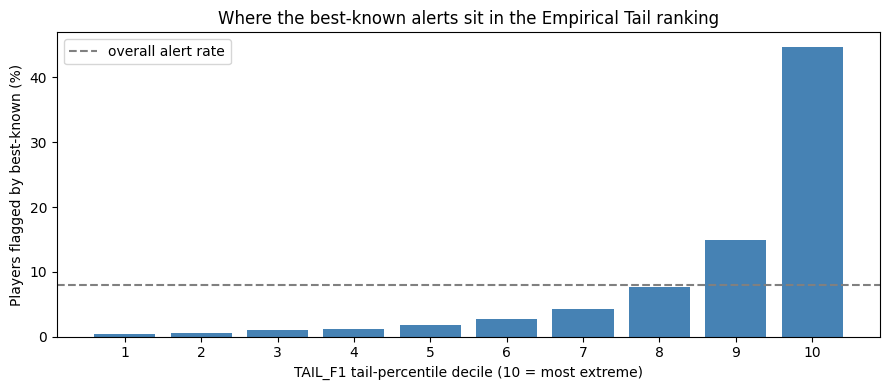

In [161]:
if best_known_alerts is not None:
    decile = np.minimum((tail_percentile / 10).astype(int), 9) + 1
    decile_table = pd.DataFrame({"decile": decile, "best_known": best_known_alerts,
                                 "tail_f1": candidate_alerts["TAIL_F1"]}).groupby("decile").agg(
        players=("best_known", "size"), best_known_alerts=("best_known", "sum"), tail_f1_alerts=("tail_f1", "sum"))
    decile_table["best_known_share_pct"] = 100 * decile_table.best_known_alerts / decile_table.players
    show(decile_table)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(decile_table.index, decile_table.best_known_share_pct, color="steelblue")
    ax.axhline(100 * SUBMISSION_ALERTS / len(player_ids), color="gray", linestyle="--", label="overall alert rate")
    ax.set_xticks(decile_table.index)
    ax.set_xlabel("TAIL_F1 tail-percentile decile (10 = most extreme)")
    ax.set_ylabel("Players flagged by best-known (%)")
    ax.set_title("Where the best-known alerts sit in the Empirical Tail ranking")
    ax.legend()
    fig.tight_layout()
    plt.show()

### 9.5 Findings and Next Hypothesis

- **Detector families disagree more than feature sets did.** On F1, Isolation Forest shares only **19** of its Top-52 players with Empirical Tail, **32** with One-Class SVM, **14** with the Gaussian mixture, and **2** with the autoencoder. Each family favors a different kind of extreme: One-Class SVM on F0 places **35** group-B players in its Top-52, while Tail on F0 places **4** and the Gaussian mixture **1**.
- **Reconstruction error is not a stable notion of "unusual" here.** The F1 autoencoder still hits the 120-iteration cap, its Top-414 overlap with the 50-iteration model is only Jaccard **0.614**, and AE120_F0 resamples at **0.450**.
- **Tail and One-Class SVM are very stable but different.** Their resample Jaccards are **0.947** and **0.984**, yet they share only **240** of 414 players (Jaccard **0.408**). KNN20_F0 is stable too (**0.950**) but shares **366/414** with One-Class SVM.
- **Result: the starting score.** TAIL_F1, the family that matches the EDA picture most directly, scored **0.72418**.

The error analysis points to two issues that became the targets of every later round:

1. **Edge-normal players.** Many players that TAIL_F1 selects are truly extreme (median tail percentile **94.9**), but their extremes come from everyday behavior such as `login_time_variance`, `purchase_amount_mean`, and `login_count`, and their event rates are close to typical players (`password_changed` **5.5%** and `mass_item_sale` **2.5%**, against **4.9%** and **2.1%** for unflagged players). They are most likely normal players who happen to sit at the edge.
2. **Hidden anomalies.** Some anomalies are not extreme feature by feature (median tail percentile **80.3**) but show up in `activity_level` and `communication_frequency`, which TAIL_F1 barely weighs.

**What we learned and next (Round 4).** Feature-by-feature extremeness finds the edge but cannot separate normal extremes from abnormal ones, and it misses anomalies whose individual values look ordinary. One way an ordinary value can still be suspicious is when it does not fit the player's own history, which Round 4 tests. The prepared OCSVM_F0 file is kept for a later round.

## 10. Round 4 — Masked Temporal Autoencoder

### 10.1 Hypothesis

Section 9.4.5 showed that many anomalies (the *hidden* players) are not extreme feature by feature. A player can have values that are each ordinary but do not fit together across periods, for example a Period-4 profile that does not follow from Periods 1–3. Empirical Tail cannot see this, because it scores every feature separately.

Hypothesis: a model that learns to predict one hidden period from the other three captures each player's normal cross-period pattern, and large prediction errors mark players whose behavior broke that pattern. For each training example, one entire period of the 16 behavioral families is hidden and predicted from the other three periods plus `account_age_days` and `behavior_stability`. Unlike the Round 3 autoencoder, which reconstructs its own visible input, this model never sees the values it predicts. It is a simple masked multi-output MLP trained from scratch on the supplied data, inspired by masked-modeling ideas rather than a reproduction of a published architecture.

### 10.2 Model

Use the same 16 temporal families from Section 4, arranged as 16 values per period, plus two non-security global context values. Fit median fills and a normal-quantile transform on fit rows only, clipping transformed values to ±4. Concatenate transformed values, observed-value indicators, and a one-hot marker of the hidden period as the model input. Train only augmented examples whose **16 target values are all observed**, so missing targets are never invented. At scoring, calculate absolute prediction error only where the original target is observed; normalize each family by its median fit-row residual, average its three largest normalized errors per period, then take the maximum over the four periods. This order-agnostic rule was fixed before the model was fitted.

In [162]:
MASKED_FAMILIES = temporal_selected.copy()
MASKED_PERIOD_COLUMNS = [f"{family}_{period}" for period in range(1, 5)
                         for family in MASKED_FAMILIES]
MASKED_CONTEXT_COLUMNS = ["account_age_days", "behavior_stability"]
MASKED_COLUMNS = MASKED_PERIOD_COLUMNS + MASKED_CONTEXT_COLUMNS
masked_raw = test_clean[MASKED_COLUMNS].to_numpy(dtype=np.float32)
assert len(MASKED_FAMILIES) == 16 and masked_raw.shape == (len(test_clean), 66)
assert np.isfinite(masked_raw[np.isfinite(masked_raw)]).all()
MASKED_MAX_ITER = 100
MASKED_TOP_ERRORS = 3

def masked_period_input(values, observed, period):
    start = period * len(MASKED_FAMILIES)
    stop = start + len(MASKED_FAMILIES)
    masked_values = values.copy()
    visible = observed.astype(np.float32).copy()
    masked_values[:, start:stop] = 0
    visible[:, start:stop] = 0
    period_marker = np.zeros((len(values), 4), dtype=np.float32)
    period_marker[:, period] = 1
    inputs = np.concatenate((masked_values, visible, period_marker), axis=1)
    targets = values[:, start:stop]
    target_observed = observed[:, start:stop]
    return inputs, targets, target_observed

print(f"Masked design: {len(MASKED_FAMILIES)} families × 4 periods + {len(MASKED_CONTEXT_COLUMNS)} global values | input width: {2 * len(MASKED_COLUMNS) + 4} | hidden target width: {len(MASKED_FAMILIES)}")

Masked design: 16 families × 4 periods + 2 global values | input width: 136 | hidden target width: 16


In [163]:
def fit_masked_temporal(row_indices):
    raw = masked_raw[row_indices]
    observed = np.isfinite(raw)
    fill = np.nanmedian(raw, axis=0)
    assert np.isfinite(fill).all()
    filled = np.where(observed, raw, fill)
    transformer = QuantileTransformer(n_quantiles=512, output_distribution="normal", random_state=SEED)
    values = np.clip(transformer.fit_transform(filled), -4, 4).astype(np.float32)
    input_parts, target_parts, complete_counts = [], [], []
    for period in range(4):
        inputs, targets, target_observed = masked_period_input(values, observed, period)
        complete = target_observed.all(axis=1)
        input_parts.append(inputs[complete])
        target_parts.append(targets[complete])
        complete_counts.append(int(complete.sum()))
    train_inputs = np.concatenate(input_parts)
    train_targets = np.concatenate(target_parts)
    started = perf_counter()
    model = MLPRegressor(hidden_layer_sizes=(128, 64, 128), alpha=1e-3,
                         batch_size=256, max_iter=MASKED_MAX_ITER, early_stopping=True,
                         validation_fraction=0.10, n_iter_no_change=7, random_state=SEED)
    model.fit(train_inputs, train_targets)
    train_seconds = perf_counter() - started
    residual_parts = []
    for period in range(4):
        inputs, targets, target_observed = masked_period_input(values, observed, period)
        complete = target_observed.all(axis=1)
        residual_parts.append(np.abs(model.predict(inputs[complete]) - targets[complete]))
    residual_scale = np.maximum(np.median(np.concatenate(residual_parts), axis=0), 0.10)
    return {"model": model, "transformer": transformer, "fill": fill,
            "residual_scale": residual_scale, "fit_rows": len(raw),
            "augmented_rows": len(train_inputs), "complete_by_period": complete_counts,
            "seconds": train_seconds}

def score_masked_temporal(fitted, row_indices):
    raw = masked_raw[row_indices]
    observed = np.isfinite(raw)
    filled = np.where(observed, raw, fitted["fill"])
    values = np.clip(fitted["transformer"].transform(filled), -4, 4).astype(np.float32)
    period_scores = []
    observed_absolute_errors = []
    observed_baseline_errors = []
    for period in range(4):
        inputs, targets, target_observed = masked_period_input(values, observed, period)
        predicted = fitted["model"].predict(inputs)
        absolute_error = np.abs(predicted - targets)
        observed_absolute_errors.append(absolute_error[target_observed])
        observed_baseline_errors.append(np.abs(targets)[target_observed])
        normalized = absolute_error / fitted["residual_scale"]
        normalized = np.where(target_observed, normalized, -np.inf)
        largest = np.partition(normalized, -MASKED_TOP_ERRORS, axis=1)[:, -MASKED_TOP_ERRORS:]
        largest = np.where(np.isfinite(largest), largest, 0)
        divisor = np.maximum(np.minimum(target_observed.sum(axis=1), MASKED_TOP_ERRORS), 1)
        period_scores.append(largest.sum(axis=1) / divisor)
    all_period_scores = np.stack(period_scores, axis=1)
    scores = all_period_scores.max(axis=1)
    assert np.isfinite(scores).all()
    return scores, all_period_scores, float(np.mean(np.concatenate(observed_absolute_errors))), float(np.mean(np.concatenate(observed_baseline_errors)))

print("Masked fit and scoring helpers ready; preprocessing and residual scales will be fitted only on supplied fit rows.")

Masked fit and scoring helpers ready; preprocessing and residual scales will be fitted only on supplied fit rows.


Fit on the same 20,711 unlabeled fit accounts used above. The MLP internally withholds 10% of its augmented training examples for early stopping; different masks of one account may land on both sides of that internal split, so the external 5,178-player validation slice remains the independent procedural check. Compare prediction MAE with the unconditional median predictor to confirm the model learned cross-period structure; this is not anomaly accuracy.

In [164]:
masked_fit = fit_masked_temporal(fit_idx)
print(f"Masked fit | accounts: {masked_fit['fit_rows']:,} | complete augmented examples: {masked_fit['augmented_rows']:,} | per period: {masked_fit['complete_by_period']} | iterations: {masked_fit['model'].n_iter_} | train seconds: {masked_fit['seconds']:.1f} | residual-scale range: {masked_fit['residual_scale'].min():.3f}–{masked_fit['residual_scale'].max():.3f}")

Masked fit | accounts: 20,711 | complete augmented examples: 37,210 | per period: [9239, 9184, 9410, 9377] | iterations: 33 | train seconds: 15.3 | residual-scale range: 0.123–0.933


In [165]:
masked_validation_values, masked_validation_periods, masked_mae, masked_baseline_mae = score_masked_temporal(masked_fit, validation_idx)
masked_validation_scores = pd.Series(masked_validation_values, index=validation_ids.to_numpy(), name="MASKED_TEMPORAL")
assert len(masked_validation_scores) == len(validation_ids) and masked_validation_scores.index.is_unique
assert masked_mae < masked_baseline_mae
print(f"Validation observed-value MAE: {masked_mae:.4f} | unconditional median MAE: {masked_baseline_mae:.4f} | improvement: {100 * (1 - masked_mae / masked_baseline_mae):.1f}% | score P99: {masked_validation_scores.quantile(0.99):.3f}")

Validation observed-value MAE: 0.4105 | unconditional median MAE: 0.9138 | improvement: 55.1% | score P99: 15.280


The validation check passes (prediction error well below the median baseline), so refit the same model and transforms on all 25,889 players for the submission scores.

In [166]:
masked_full_fit = fit_masked_temporal(np.arange(len(masked_raw)))
print(f"Full masked fit | accounts: {masked_full_fit['fit_rows']:,} | augmented examples: {masked_full_fit['augmented_rows']:,} | iterations: {masked_full_fit['model'].n_iter_} | train seconds: {masked_full_fit['seconds']:.1f}")

Full masked fit | accounts: 25,889 | augmented examples: 46,630 | iterations: 24 | train seconds: 13.1


In [167]:
masked_full_values, masked_full_periods, masked_full_mae, masked_full_baseline_mae = score_masked_temporal(masked_full_fit, np.arange(len(masked_raw)))
masked_full_scores = pd.Series(masked_full_values, index=player_ids.to_numpy(), name="MASKED_TEMPORAL")
assert masked_full_scores.index.is_unique and len(masked_full_scores) == len(test_raw)
assert np.isfinite(masked_full_scores.to_numpy()).all()
print(f"Full masked scores | rows: {len(masked_full_scores):,} | median: {masked_full_scores.median():.3f} | P99: {masked_full_scores.quantile(0.99):.3f} | observed reconstruction MAE: {masked_full_mae:.3f}")
full_candidate_scores["MASKED_TEMPORAL"] = masked_full_values

Full masked scores | rows: 25,889 | median: 3.484 | P99: 13.010 | observed reconstruction MAE: 0.406


### 10.3 Analysis

#### 10.3.1 Validation Ranking Diagnostics

Compare the masked model's Top-414 validation selection with the three Round 3 candidates and with Isolation Forest E02, then profile it. The last four columns count which hidden period produced each selected player's maximum score.

In [168]:
masked_overlap = pd.DataFrame([{"comparison": f"MASKED vs {name}", **compare_rankings(masked_validation_scores, scores, DIAGNOSTIC_K)}
                               for name, scores in {**candidate_scores, "IF_E02": model_results["E02"]["validation_scores"]}.items()])
print(masked_overlap.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

        comparison  common  left_only  right_only  jaccard  spearman
 MASKED vs TAIL_F1     206        208         208    0.331     0.434
MASKED vs OCSVM_F0     215        199         199    0.351     0.363
MASKED vs AE120_F0     106        308         308    0.147     0.242
  MASKED vs IF_E02     219        195         195    0.360     0.440


In [169]:
masked_top_ids = top_k_ids(masked_validation_scores, DIAGNOSTIC_K)
masked_top_positions = np.isin(validation_ids.to_numpy(), list(masked_top_ids))
peak_counts = np.bincount(masked_validation_periods[masked_top_positions].argmax(axis=1), minlength=4)
print(pd.DataFrame([{**validation_profile(masked_top_ids), **{f"peak_P{period + 1}": int(peak_counts[period]) for period in range(4)}}])
      .to_string(index=False, float_format=lambda value: f"{value:.2f}"))

 players  A_members  B_members  outside_A_B  raw_missing_median  any_invalid_pct  peak_P1  peak_P2  peak_P3  peak_P4
     414         18         51          345                6.00            43.24       86       66       51      211


#### 10.3.2 Alert-Set Difference from References

Compare the 2,046 full-file alerts with the scored TAIL_F1 file and the prepared OCSVM_F0 file. A candidate that changes only a few dozen alerts would not be worth a submission slot.

In [170]:
candidate_alerts["MASKED_TEMPORAL"] = alerts_from_scores(full_candidate_scores["MASKED_TEMPORAL"])
show(compare_alert_sets(candidate_alerts["MASKED_TEMPORAL"], {"TAIL_F1 (scored)": candidate_alerts["TAIL_F1"],
                                                              "OCSVM_F0 (unsubmitted)": candidate_alerts["OCSVM_F0"],
                                                              "best-known": best_known_alerts}))

             reference  common  added  removed  jaccard
      TAIL_F1 (scored)     853   1193     1193     0.26
OCSVM_F0 (unsubmitted)     948   1098     1098     0.30
            best-known     872   1174     1174     0.27


### 10.4 Submission and Result

Submit. The masked model replaces more than half of TAIL_F1's alerts, so its score tests a clearly different idea: cross-period consistency instead of marginal extremeness.

#### 10.4.1 Export and Format Check

In [171]:
print(pd.DataFrame([export_or_verify("kaggle_t1234_peer_t5_masked_temporal_v1_20261121", candidate_alerts["MASKED_TEMPORAL"],
                                     {"candidate": "MASKED_TEMPORAL",
                                      "model": "masked-period MLP 128-64-128 trained on all supplied rows",
                                      "score": "maximum over periods of mean top-3 normalized masked prediction errors"})]).to_string(index=False))

                                                file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_masked_temporal_v1_20261121.csv existing file verified 25889    2046 a4ac8204b2e4c046


#### 10.4.2 Public Result

In [172]:
public_results["MASKED_TEMPORAL"] = 0.70870
print(f"MASKED_TEMPORAL public overall score: {public_results['MASKED_TEMPORAL']:.5f} | "
      f"vs TAIL_F1: {public_results['MASKED_TEMPORAL'] - public_results['TAIL_F1']:+.5f} | "
      f"vs best-known: {public_results['MASKED_TEMPORAL'] - public_results['BEST_KNOWN']:+.5f}")

MASKED_TEMPORAL public overall score: 0.70870 | vs TAIL_F1: -0.01548 | vs best-known: -0.10901


#### 10.4.3 Post-Result Error Analysis

The masked model scored below TAIL_F1. Split its change relative to TAIL_F1 into kept, added, and removed alerts, and profile each group. This *swap analysis* is reused after every later result: if the added players look more anomalous than the removed ones, the score should rise.

In [173]:
show(swap_analysis(candidate_alerts["MASKED_TEMPORAL"], candidate_alerts["TAIL_F1"], "MASKED", "TAIL_F1"))

               group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                kept      853            96.88                 674                   79.02
     added by MASKED     1193            74.57                 198                   16.60
removed from TAIL_F1     1193            95.45                 353                   29.59


In [174]:
if best_known_alerts is not None:
    show(alert_group_profile(alert_groups(candidate_alerts["MASKED_TEMPORAL"], best_known_alerts, "MASKED", "best-known")))

          group  players  tail_pct_median  tail_pct_P10  A_members  B_members  any_invalid_pct  password_changed_pct  vpn_usage_pct  mass_item_sale_pct  account_age_median  raw_missing_median
           both      872            96.29         86.80         83        199            47.71                 36.42          34.01               25.00              862.23                6.00
    MASKED only     1174            75.36         37.42          0          0            41.06                  5.41          15.65                1.97              845.94                7.00
best-known only     1174            85.26         48.73          0          0            37.05                  5.23          15.32                2.05              941.49                6.00
        neither    22669            44.82          8.81          0          0            39.65                  4.93          15.26                2.14              839.04                6.00


### 10.5 Findings and Next Hypothesis

- **The model learned real cross-period structure.** Validation prediction MAE is **0.4105** against **0.9138** for the median baseline (**55.1%** lower), and its ranking is distinct (Top-414 Jaccard **0.331** with TAIL_F1). **211** of its 414 top validation players reach their maximum error when Period 4 is hidden.
- **Result: the score fell.** It replaced **1,193** of TAIL_F1's alerts and scored **0.70870** (**−0.01548** versus TAIL_F1).
- **Why: the added players look ordinary.** They are less extreme (median tail percentile **74.6**) and have ordinary event rates (`password_changed` **5.4%**, `mass_item_sale` **2.0%**).
- **Good prediction accuracy is not good detection.** The cross-period inconsistencies this model finds are mostly normal variation.

**What we learned and next (Round 5).** Breaking one's own cross-period pattern is mostly normal variation, not the anomaly signal. Two unlabeled models of the data's structure have now been tried; the supplied security flags are the only event-like signals in the file, so Round 5 asks whether predicting those events from behavior identifies anomalies.

## 11. Round 5 — Auxiliary Security-Event Risk

### 11.1 Hypothesis

Rounds 3 and 4 tried two unlabeled ideas of "unusual": being extreme feature by feature, and breaking one's own cross-period pattern. The second scored lower. The supplied security flags (`password_changed`, `vpn_usage`, `suspicious_login_time`, `mass_item_sale`) are the only event-like signals in the data. They are inputs, not labels (H4), but an account that *behaves like* accounts with such events may be at risk even when its own flag is 0 or missing.

Hypothesis: classifiers that predict these events from the other behavior features learn a security-risk pattern, and ranking players by predicted risk selects a useful, different set of anomalies. The learning target changes from reconstruction to auxiliary event prediction; no `is_anomaly` label is involved, and the four flags are excluded from the inputs so a classifier cannot simply copy them.

### 11.2 Model

Screen all four supplied flags as auxiliary targets. For each flag, fit a LightGBM classifier only where that flag is observed among the 20,711 fit players, using the other 118 cleaned predictors (all four flags are excluded from the inputs), and evaluate AUC and average precision on observed validation values. These metrics measure how predictable each event is from behavior, not Task 5 F₃. LightGBM (gradient-boosted trees, trained from scratch) is used because it handles missing values natively and needs no scaling. Parameters are fixed: 300 trees, 15 leaves, learning rate 0.04, balanced class weights.

In [175]:
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

proxy_predictors = [column for column in feature_cols if column not in security_flags]
proxy_frame = test_clean[proxy_predictors]
assert len(proxy_predictors) == 118


def fit_proxy(target, rows):
    observed = test_clean.iloc[rows][target].notna().to_numpy()
    model = LGBMClassifier(n_estimators=300, learning_rate=0.04, num_leaves=15, min_child_samples=80,
                           colsample_bytree=0.8, subsample=0.8, subsample_freq=1, class_weight="balanced",
                           random_state=SEED, verbosity=-1, n_jobs=4)
    model.fit(proxy_frame.iloc[rows].iloc[observed], test_clean.iloc[rows][target].iloc[observed].astype(int))
    return model


proxy_models, proxy_probabilities, proxy_screen_rows = {}, {}, []
for target in security_flags:
    proxy_models[target] = fit_proxy(target, fit_idx)
    proxy_probabilities[target] = proxy_models[target].predict_proba(proxy_frame.iloc[validation_idx])[:, 1]
    observed = test_clean.iloc[validation_idx][target].notna().to_numpy()
    truth = test_clean.iloc[validation_idx][target].iloc[observed].astype(int)
    proxy_screen_rows.append({"target": target, "validation_observed": int(observed.sum()),
                              "validation_positive_pct": 100 * truth.mean(),
                              "validation_auc": roc_auc_score(truth, proxy_probabilities[target][observed]),
                              "validation_ap": average_precision_score(truth, proxy_probabilities[target][observed])})
show(pd.DataFrame(proxy_screen_rows), digits=4)

               target  validation_observed  validation_positive_pct  validation_auc  validation_ap
     password_changed                 4884                   5.8354          0.6385         0.3094
            vpn_usage                 4944                  16.3228          0.5448         0.2473
suspicious_login_time                 4920                   4.5122          0.4973         0.0453
       mass_item_sale                 4907                   2.6085          0.6897         0.2904


Keep `password_changed` and `mass_item_sale` as targets. They are the most predictable from behavior: AUC **0.639** and **0.690**, with average precision about **5×** and **11×** their validation prevalence (5.8% and 2.6%). `vpn_usage` is weak (AUC **0.545**) and `suspicious_login_time` is at chance (**0.497**), so both are dropped. Because the two targets were chosen after seeing this screen, the screen numbers are optimistic for them.

Balanced class weights make raw probabilities unsuitable as calibrated event rates. Convert each model prediction to a percentile rank against its own fit-row prediction distribution, then take the larger of the two ranks. This fixed max score detects either auxiliary security-event pattern. Actual values of all four flags are absent from the predictors and the score. The validation comparison describes selection diversity, not fraud accuracy.

In [176]:
PROXY_TARGETS = ("password_changed", "mass_item_sale")
proxy_validation_ranks = {}
for target in PROXY_TARGETS:
    reference = np.sort(proxy_models[target].predict_proba(proxy_frame.iloc[fit_idx])[:, 1])
    proxy_validation_ranks[target] = np.searchsorted(reference, proxy_probabilities[target], side="right") / len(reference)
proxy_validation_scores = pd.Series(np.maximum.reduce([proxy_validation_ranks[target] for target in PROXY_TARGETS]),
                                    index=validation_ids.to_numpy(), name="SECURITY_PROXY")
assert proxy_validation_scores.index.is_unique and np.isfinite(proxy_validation_scores.to_numpy()).all()
print(f"Security proxy validation scores | players: {len(proxy_validation_scores):,} | targets: {', '.join(PROXY_TARGETS)}")

Security proxy validation scores | players: 5,178 | targets: password_changed, mass_item_sale


Refit the two classifiers on all players with an observed value of their flag, then rank everyone with the same maximum-percentile rule against the full-file prediction distribution. This is a self-supervised task on supplied features, not training on `is_anomaly`.

In [177]:
full_proxy_ranks = {}
for target in PROXY_TARGETS:
    probability = fit_proxy(target, np.arange(len(test_clean))).predict_proba(proxy_frame)[:, 1]
    full_proxy_ranks[target] = np.searchsorted(np.sort(probability), probability, side="right") / len(probability)
full_candidate_scores["SECURITY_PROXY"] = np.maximum.reduce([full_proxy_ranks[target] for target in PROXY_TARGETS])
assert np.isfinite(full_candidate_scores["SECURITY_PROXY"]).all()
print(f"Full security-proxy scores | players: {len(player_ids):,} | P99: {np.quantile(full_candidate_scores['SECURITY_PROXY'], 0.99):.3f}")

Full security-proxy scores | players: 25,889 | P99: 0.992


### 11.3 Analysis

#### 11.3.1 Validation Ranking Diagnostics

Compare the proxy's Top-414 validation selection with the earlier candidates and profile it, including the actual rates of the two target flags among selected players.

In [178]:
proxy_overlap = pd.DataFrame([{"comparison": f"PROXY vs {name}", **compare_rankings(proxy_validation_scores, scores, DIAGNOSTIC_K)}
                              for name, scores in {"TAIL_F1": candidate_scores["TAIL_F1"], "OCSVM_F0": candidate_scores["OCSVM_F0"],
                                                   "MASKED_TEMPORAL": masked_validation_scores,
                                                   "IF_E02": model_results["E02"]["validation_scores"]}.items()])
print(proxy_overlap.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
proxy_top_group = validation_audit.loc[list(top_k_ids(proxy_validation_scores, DIAGNOSTIC_K))]
print(pd.DataFrame([{**validation_profile(proxy_top_group.index),
                     **{f"{target}_pct": observed_positive_pct(proxy_top_group, target) for target in PROXY_TARGETS}}])
      .to_string(index=False, float_format=lambda value: f"{value:.2f}"))

              comparison  common  left_only  right_only  jaccard  spearman
        PROXY vs TAIL_F1      79        335         335    0.105    -0.138
       PROXY vs OCSVM_F0      84        330         330    0.113    -0.211
PROXY vs MASKED_TEMPORAL      92        322         322    0.125    -0.049
         PROXY vs IF_E02      90        324         324    0.122    -0.133
 players  A_members  B_members  outside_A_B  raw_missing_median  any_invalid_pct  password_changed_pct  mass_item_sale_pct
     414         18          2          394                5.00            42.75                 20.31               12.81


#### 11.3.2 Alert-Set Difference from References

In [179]:
candidate_alerts["SECURITY_PROXY"] = alerts_from_scores(full_candidate_scores["SECURITY_PROXY"])
show(compare_alert_sets(candidate_alerts["SECURITY_PROXY"], {"TAIL_F1 (scored)": candidate_alerts["TAIL_F1"],
                                                             "MASKED_TEMPORAL (scored)": candidate_alerts["MASKED_TEMPORAL"],
                                                             "best-known": best_known_alerts}))

               reference  common  added  removed  jaccard
        TAIL_F1 (scored)     341   1705     1705     0.09
MASKED_TEMPORAL (scored)     405   1641     1641     0.11
              best-known     406   1640     1640     0.11


### 11.4 Submission and Result

Submit. The proxy shares only a small fraction of its alerts with any earlier candidate, so its score tests whether event-like risk is a different, useful signal.

#### 11.4.1 Export and Format Check

In [180]:
print(pd.DataFrame([export_or_verify("kaggle_t1234_peer_t5_security_proxy_v1_20261121", candidate_alerts["SECURITY_PROXY"],
                                     {"candidate": "SECURITY_PROXY", "auxiliary_targets": list(PROXY_TARGETS),
                                      "model": "two LightGBM classifiers on 118 non-flag predictors",
                                      "score": "maximum full-file percentile rank of the two predicted events"})]).to_string(index=False))

                                               file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_security_proxy_v1_20261121.csv existing file verified 25889    2046 c7332a19a46e326f


#### 11.4.2 Public Result

In [181]:
public_results["SECURITY_PROXY"] = 0.66459
print(f"SECURITY_PROXY public overall score: {public_results['SECURITY_PROXY']:.5f} | "
      f"vs TAIL_F1: {public_results['SECURITY_PROXY'] - public_results['TAIL_F1']:+.5f} | "
      f"vs best-known: {public_results['SECURITY_PROXY'] - public_results['BEST_KNOWN']:+.5f}")

SECURITY_PROXY public overall score: 0.66459 | vs TAIL_F1: -0.05959 | vs best-known: -0.15312


#### 11.4.3 Post-Result Error Analysis

In [182]:
show(swap_analysis(candidate_alerts["SECURITY_PROXY"], candidate_alerts["TAIL_F1"], "PROXY", "TAIL_F1"))

               group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                kept      341            96.37                 273                   80.06
      added by PROXY     1705            44.83                 133                    7.80
removed from TAIL_F1     1705            95.99                 754                   44.22


In [183]:
if best_known_alerts is not None:
    show(alert_group_profile(alert_groups(candidate_alerts["SECURITY_PROXY"], best_known_alerts, "PROXY", "best-known")))

          group  players  tail_pct_median  tail_pct_P10  A_members  B_members  any_invalid_pct  password_changed_pct  vpn_usage_pct  mass_item_sale_pct  account_age_median  raw_missing_median
           both      406            95.11         76.87         83         12            54.93                 89.12          19.13               58.76              875.00                6.00
     PROXY only     1640            43.82          8.68          0          0            38.48                 49.28          14.29               30.65              811.91                6.00
best-known only     1640            90.89         58.51          0        187            38.29                  1.10          24.31                0.00              919.03                6.00
        neither    22203            46.70          9.28          0          0            39.81                  1.59          15.35                0.00              840.82                6.00


### 11.5 Findings and Next Hypothesis

- **Behavior does predict the events.** The selected validation players have the target events far more often than average (`password_changed` **20.3%** versus **5.8%**, `mass_item_sale` **12.8%** versus **2.6%**).
- **Result: the lowest score of all rounds.** The ranking is unrelated to every unlabeled detector (Spearman **−0.05** to **−0.21**). It replaced **1,705** of TAIL_F1's alerts and scored **0.66459** (**−0.05959** versus TAIL_F1).
- **Why: an event on an ordinary account is mostly normal.** Proxy-only players often have the events themselves (`password_changed` **49.3%**, `mass_item_sale` **30.7%**) yet sit in the middle of the tail ranking (median percentile **43.8**).

**What we learned and next (Round 6).** Security events matter only together with extreme behavior, which confirms H4: the flags are context, not labels. Both structurally different models (Rounds 4–5) scored below TAIL_F1, while Round 3 showed that Tail's problem is the mix of players at the edge, not the edge itself. Round 6 therefore returns to Tail and changes how its reference distribution is built.

## 12. Round 6 — Empirical Tail Reference Trimming

### 12.1 Hypothesis

Rounds 4 and 5 replaced Empirical Tail with structurally different models, and both scored below TAIL_F1. The Tail family remains the best own result, so Round 6 returns to it and questions its *reference*.

In TAIL_F1 every player, including the most extreme ones, belongs to the reference distribution against which tail surprises are measured. Extreme players thicken the tails, so other extreme values look less rare than they are. If anomalies concentrate at the edges, a reference built from the remaining players should make genuinely extreme behavior stand out more sharply. The test excludes the highest-scoring TAIL_F1 players from the **reference only**; they remain eligible for alerts. Two trim shares, 1% and 5%, are fixed in advance.

### 12.2 Model

Start from the TAIL_F1 full-file scores. For each trim share, keep the players below the top share as the reference, recompute every player's tail surprises against that reduced reference, and rank all 25,889 players again. Excluded players remain eligible for alerts.

In [184]:
baseline_tail = full_candidate_scores["TAIL_F1"]
trim_reference_idx = {}
for trim_share, name in ((0.01, "TAIL_TRIM1"), (0.05, "TAIL_TRIM5")):
    retained = len(tail_full_values) - int(np.ceil(len(tail_full_values) * trim_share))
    trim_reference_idx[trim_share] = np.argsort(baseline_tail, kind="stable")[:retained]
    full_candidate_scores[name] = empirical_tail_scores(tail_full_values[trim_reference_idx[trim_share]], tail_full_values)
    candidate_alerts[name] = alerts_from_scores(full_candidate_scores[name])
    print(f"{name} | reference players: {retained:,} of {len(tail_full_values):,}")

TAIL_TRIM1 | reference players: 25,630 of 25,889


TAIL_TRIM5 | reference players: 24,594 of 25,889


### 12.3 Analysis

Measure how much each trim changes TAIL_F1's ranking and how many of the players excluded from the reference are still alerted.

In [185]:
trim_rows = []
for trim_share, name in ((0.01, "TAIL_TRIM1"), (0.05, "TAIL_TRIM5")):
    excluded = np.ones(len(player_ids), dtype=bool)
    excluded[trim_reference_idx[trim_share]] = False
    common = int((candidate_alerts[name] & candidate_alerts["TAIL_F1"]).sum())
    trim_rows.append({"candidate": name, "trim_pct": 100 * trim_share, "common_with_TAIL_F1": common,
                      "swapped_each_way": SUBMISSION_ALERTS - common,
                      "spearman_with_TAIL_F1": pd.Series(baseline_tail).corr(pd.Series(full_candidate_scores[name]), method="spearman"),
                      "excluded_players_still_alerted": int((candidate_alerts[name] & excluded).sum())})
show(pd.DataFrame(trim_rows), digits=4)

 candidate  trim_pct  common_with_TAIL_F1  swapped_each_way  spearman_with_TAIL_F1  excluded_players_still_alerted
TAIL_TRIM1    1.0000                 1957                89                 0.9991                             259
TAIL_TRIM5    5.0000                 1785               261                 0.9861                            1295


In [186]:
for name in ("TAIL_TRIM1", "TAIL_TRIM5"):
    print(name)
    show(compare_alert_sets(candidate_alerts[name], {"TAIL_F1 (scored)": candidate_alerts["TAIL_F1"], "best-known": best_known_alerts}))

TAIL_TRIM1
       reference  common  added  removed  jaccard
TAIL_F1 (scored)    1957     89       89     0.92
      best-known    1075    971      971     0.36
TAIL_TRIM5
       reference  common  added  removed  jaccard
TAIL_F1 (scored)    1785    261      261     0.77
      best-known    1115    931      931     0.37


### 12.4 Submission and Result

Submit the **5% trim**. The 1% trim swaps few alerts relative to TAIL_F1, so it would test the idea only weakly; the 5% trim changes enough to show whether trimming the reference moves the score. The 1% file is prepared but not submitted.

#### 12.4.1 Export and Format Check

In [187]:
trim_exports = [export_or_verify(f"kaggle_t1234_peer_t5_tail_reference_trim{pct}pct_20261121", candidate_alerts[name],
                                 {"candidate": name, "reference_trim": f"exclude highest TAIL_F1 {pct}% from the ECDF reference only"})
                for pct, name in ((1, "TAIL_TRIM1"), (5, "TAIL_TRIM5"))]
print(pd.DataFrame(trim_exports).to_string(index=False))

                                                     file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_tail_reference_trim1pct_20261121.csv existing file verified 25889    2046 49088dde59071312
kaggle_t1234_peer_t5_tail_reference_trim5pct_20261121.csv existing file verified 25889    2046 b0e4a208d6f2b476


#### 12.4.2 Public Result

In [188]:
public_results["TAIL_TRIM5"] = 0.73288
print(f"TAIL_TRIM5 public overall score: {public_results['TAIL_TRIM5']:.5f} | "
      f"vs TAIL_F1: {public_results['TAIL_TRIM5'] - public_results['TAIL_F1']:+.5f} | "
      f"vs best-known: {public_results['TAIL_TRIM5'] - public_results['BEST_KNOWN']:+.5f}")

TAIL_TRIM5 public overall score: 0.73288 | vs TAIL_F1: +0.00870 | vs best-known: -0.08483


#### 12.4.3 Post-Result Error Analysis

The 5% trim improved on TAIL_F1. First check, with the swap analysis, whether the swapped-in players look more anomalous than the swapped-out ones, which would explain the gain.

In [189]:
show(swap_analysis(candidate_alerts["TAIL_TRIM5"], candidate_alerts["TAIL_F1"], "TAIL_TRIM5", "TAIL_F1"))

               group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                kept     1785            96.55                 983                   55.07
 added by TAIL_TRIM5      261            89.95                 132                   50.57
removed from TAIL_F1      261            92.90                  44                   16.86


Was 5% a special choice? This check was run *after* the 5% result, so it cannot justify 5%; it only shows how sensitive the selection is to the trim share. A data-only rule flags reference scores above the median plus three robust scales (1.4826 × MAD), and a fixed scan shows how many alerts change between neighboring trim shares.

In [190]:
score_median = float(np.median(baseline_tail))
robust_scale = float(1.4826 * np.median(np.abs(baseline_tail - score_median)))
robust_share = float(np.mean(baseline_tail > score_median + 3 * robust_scale))
scan_rows = []
previous = candidate_alerts["TAIL_F1"]
for trim_share in (0.005, 0.01, 0.02, 0.03, 0.05, 0.07, 0.10):
    retained = len(tail_full_values) - int(np.ceil(len(tail_full_values) * trim_share))
    alerts = alerts_from_scores(empirical_tail_scores(
        tail_full_values[np.argsort(baseline_tail, kind="stable")[:retained]], tail_full_values))
    scan_rows.append({"trim_pct": 100 * trim_share,
                      "changed_from_previous": SUBMISSION_ALERTS - int((alerts & previous).sum()),
                      "changed_from_TAIL_F1": SUBMISSION_ALERTS - int((alerts & candidate_alerts["TAIL_F1"]).sum()),
                      "changed_from_TAIL_TRIM5": SUBMISSION_ALERTS - int((alerts & candidate_alerts["TAIL_TRIM5"]).sum())})
    previous = alerts
print(f"Median + 3 robust scales flags {100 * robust_share:.2f}% of players as unusually high reference scores.")
show(pd.DataFrame(scan_rows))

Median + 3 robust scales flags 2.97% of players as unusually high reference scores.
 trim_pct  changed_from_previous  changed_from_TAIL_F1  changed_from_TAIL_TRIM5
     0.50                     52                    52                      217
     1.00                     40                    89                      180
     2.00                     55                   140                      131
     3.00                     50                   184                       86
     5.00                     86                   261                        0
     7.00                     60                   303                       60
    10.00                     65                   350                      111


### 12.5 Findings and Next Hypothesis

- **Trimming reshapes the ranking without discarding the extremes.** The 1% trim swaps **89** alerts (Spearman **0.999** with TAIL_F1) and the 5% trim **261** (Spearman **0.986**). **1,295** of the players excluded from the 5% reference are still alerted.
- **Result: the first own improvement.** The 5% trim scored **0.73288**, **+0.00870** versus TAIL_F1.
- **Why: it demotes the most extreme normal players.** The removed players were slightly *more* extreme than the added ones (median tail percentile **92.9** versus **90.0**). Outliers in the reference thicken its tails, so other extreme values look less rare than they are.
- **The trim share was fixed in advance.** The trim-share scan keeps changing **40–86** alerts per step up to 10%, and a data-only rule (median plus three robust scales) would trim **2.97%**. No further trim shares were submitted, to avoid tuning a cutoff on the leaderboard.

**What we learned and next (Round 7).** What the model treats as "normal" matters. Median imputation is a second way the Tail reference may be distorted, so Round 7 tests it.

## 13. Round 7 — Missing-Aware Empirical Tail

### 13.1 Hypothesis

The 5% trim improved the score, which shows that the reference distribution matters. A second weakness of the reference is median imputation: about 5% of each feature is missing, and filling those cells with the median adds an artificial spike at the center of every reference distribution and makes each missing value look perfectly typical.

Hypothesis: building each feature's reference from observed values only, and letting a missing value contribute no surprise, removes this artifact and changes the trimmed Tail selection.

### 13.2 Model

Keep the 5% reference-trim design and the same 206 F1 features, but skip median imputation. Each feature's reference uses only its observed values, and a missing query value contributes zero surprise. The initial observed-only scores choose the 5% excluded from the reference. Because a tail surprise depends only on a value's rank within its feature, the RobustScaler step is unnecessary here.

In [191]:
observed_tail_values = feature_sets["F1_temporal"].to_numpy(dtype=float)


def observed_only_tail(reference, query, top_k=8):
    surprises = np.zeros(query.shape, dtype=float)
    for column in range(query.shape[1]):
        observed_reference = np.sort(reference[:, column][np.isfinite(reference[:, column])])
        observed_query = np.isfinite(query[:, column])
        values = query[observed_query, column]
        low = np.searchsorted(observed_reference, values, side="right")
        high = len(observed_reference) - np.searchsorted(observed_reference, values, side="left")
        surprises[observed_query, column] = -np.log((np.minimum(low, high) + 1) / (len(observed_reference) + 1))
    return np.partition(surprises, -top_k, axis=1)[:, -top_k:].sum(axis=1)


observed_initial = observed_only_tail(observed_tail_values, observed_tail_values)
observed_reference_idx = np.argsort(observed_initial, kind="stable")[:len(trim_reference_idx[0.05])]
full_candidate_scores["TAIL_OBSERVED_TRIM5"] = observed_only_tail(observed_tail_values[observed_reference_idx], observed_tail_values)
candidate_alerts["TAIL_OBSERVED_TRIM5"] = alerts_from_scores(full_candidate_scores["TAIL_OBSERVED_TRIM5"])
print(f"Observed-only Tail | reference players: {len(observed_reference_idx):,} | "
      f"missing cells skipped: {int(np.isnan(observed_tail_values).sum()):,}")

Observed-only Tail | reference players: 24,594 | missing cells skipped: 253,983


### 13.3 Analysis

In [192]:
show(compare_alert_sets(candidate_alerts["TAIL_OBSERVED_TRIM5"], {"TAIL_TRIM5 (scored)": candidate_alerts["TAIL_TRIM5"],
                                                                  "TAIL_F1 (scored)": candidate_alerts["TAIL_F1"],
                                                                  "best-known": best_known_alerts}))
show(swap_analysis(candidate_alerts["TAIL_OBSERVED_TRIM5"], candidate_alerts["TAIL_TRIM5"], "OBSERVED", "TAIL_TRIM5"))

          reference  common  added  removed  jaccard
TAIL_TRIM5 (scored)    2032     14       14     0.99
   TAIL_F1 (scored)    1783    263      263     0.77
         best-known    1115    931      931     0.37
                  group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                   kept     2032            96.08                1112                   54.72
      added by OBSERVED       14            90.00                   3                   21.43
removed from TAIL_TRIM5       14            92.04                   3                   21.43


### 13.4 Submission and Result

Not submitted. The missing-aware ranking swaps only **14** alerts each way with the scored TAIL_TRIM5 file (0.7% of the alert set). A public score could reveal information about just 28 players, too little to justify a submission slot. The prepared file is verified below.

In [193]:
print(pd.DataFrame([export_or_verify("kaggle_t1234_peer_t5_tail_observed_ecdf_trim5pct_v1_20261121",
                                     candidate_alerts["TAIL_OBSERVED_TRIM5"],
                                     {"candidate": "TAIL_OBSERVED_TRIM5",
                                      "missing_score": "missing query feature contributes zero surprise"})]).to_string(index=False))

                                                            file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_tail_observed_ecdf_trim5pct_v1_20261121.csv existing file verified 25889    2046 be56cba0bb360324


### 13.5 Findings and Next Hypothesis

- **Imputation is not the problem.** Skipping **253,983** missing cells instead of median-filling them leaves **2,032** of 2,046 alerts unchanged. Because missingness is spread almost evenly across players (Section 3.4.3), a filled value sits at the center of its feature and rarely enters a player's eight largest surprises.
- **Checking offline saved a slot.** The 14-alert change was measured before submission, so no leaderboard attempt was spent on it.

**What we learned and next (Round 8).** Rounds 6–7 used up the simple changes to the Tail reference; the remaining problem is *which* players at the edge are flagged. Round 3's other stable family, One-Class SVM, has never been scored, so Round 8 revisits it together with the reference trimming from Round 6.

## 14. Round 8 — Cohort-Specific One-Class SVM

### 14.1 Hypothesis

OCSVM_F0, the second stable family from Round 3 (resample Jaccard **0.984**), was prepared but never submitted. Round 3 also showed that the Tail view keeps many edge-normal players, which a smooth boundary may drop, so the One-Class SVM family is worth revisiting with what Rounds 3 and 6 taught.

A single One-Class SVM draws one boundary around all players. Normal behavior, however, differs between a new low-activity account and a veteran high-activity player; one global boundary may be too loose for one group and too tight for another, so ordinary players of an unusual type look anomalous. Round 6 also showed that extreme players in the fitted reference distort it.

Hypothesis: fitting a separate boundary per player cohort, with the most extreme 5% (by TAIL_F1) excluded from fitting, describes normal behavior more precisely. Cohorts use only account age and prior-period activity, two transparent characteristics that do not depend on Period 4.

### 14.2 Model

Define four cohorts from the full-file medians of `account_age_days` and of each player's median P1–P3 `activity_level`, plus a fifth cohort for players with missing account age. Period 4 is not used to define cohorts, so a sudden P4 change cannot move a player into a different cohort.

In [194]:
cohort_values = ocsvm_full_values
age = test_clean["account_age_days"]
prior_activity = test_clean[[f"activity_level_{period}" for period in (1, 2, 3)]].median(axis=1)
age_cut, activity_cut = float(age.median()), float(prior_activity.median())
cohort_labels = np.where(age.isna(), "age_missing",
                         np.where(age.le(age_cut), "young", "old") + "__"
                         + np.where(prior_activity.le(activity_cut), "low_activity", "high_activity"))
cohort_names = np.unique(cohort_labels)
assert len(cohort_names) == 5
print(f"Cohort cuts | account age median: {age_cut:.1f} days | P1-P3 activity median: {activity_cut:.3f}")
print(pd.Series(cohort_labels).value_counts().rename("players").to_string())

Cohort cuts | account age median: 844.6 days | P1-P3 activity median: 0.983
young__high_activity    6174
old__low_activity       6170
old__high_activity      6139
young__low_activity     6136
age_missing             1270


Fit one One-Class SVM per cohort on the same F0 values, global median fill, and global RobustScaler as OCSVM_F0, with the same `nu=0.10` and `gamma="scale"`. Each cohort's scores are converted to percentiles against its own fit rows, so cohorts become comparable before everyone is ranked together. Two variants are fitted: all cohort members as fit rows, and the prespecified variant that excludes the TAIL_F1 top 5% (the Round 6 reference trim) from fitting only. Every player is still scored.

In [195]:
cohort_keep = np.zeros(len(cohort_values), dtype=bool)
cohort_keep[trim_reference_idx[0.05]] = True


def cohort_ocsvm_score(keep):
    calibrated = np.empty(len(cohort_values), dtype=float)
    for name in cohort_names:
        query_rows = np.flatnonzero(cohort_labels == name)
        fit_rows = query_rows[keep[query_rows]]
        assert len(fit_rows) > 500
        model = OneClassSVM(kernel="rbf", nu=0.10, gamma="scale", cache_size=500).fit(cohort_values[fit_rows])
        reference = np.sort(-model.score_samples(cohort_values[fit_rows]))
        calibrated[query_rows] = np.searchsorted(reference, -model.score_samples(cohort_values[query_rows]),
                                                 side="right") / len(reference)
    assert np.isfinite(calibrated).all()
    return calibrated


started = perf_counter()
full_candidate_scores["COHORT_OCSVM_ALL"] = cohort_ocsvm_score(np.ones(len(cohort_values), dtype=bool))
full_candidate_scores["COHORT_OCSVM_TRIM5"] = cohort_ocsvm_score(cohort_keep)
cohort_all_alerts = alerts_from_scores(full_candidate_scores["COHORT_OCSVM_ALL"])
candidate_alerts["COHORT_OCSVM_TRIM5"] = alerts_from_scores(full_candidate_scores["COHORT_OCSVM_TRIM5"])
print(f"Cohort One-Class SVM fits complete | variants: 2 | cohorts: {len(cohort_names)} | seconds: {perf_counter() - started:.1f}")

Cohort One-Class SVM fits complete | variants: 2 | cohorts: 5 | seconds: 9.4


### 14.3 Analysis

#### 14.3.1 Cohort Allocation

Count each method's alerts by cohort. Within-cohort percentile calibration tends to allocate alerts roughly in proportion to cohort size, so a proportional allocation alone is a consequence of the design, not evidence of better detection.

In [196]:
cohort_allocation = pd.DataFrame([{"cohort": name, "players": int((cohort_labels == name).sum()),
                                   **{label: int((alerts & (cohort_labels == name)).sum())
                                      for label, alerts in (("OCSVM_F0", candidate_alerts["OCSVM_F0"]),
                                                            ("TAIL_TRIM5", candidate_alerts["TAIL_TRIM5"]),
                                                            ("COHORT_ALL", cohort_all_alerts),
                                                            ("COHORT_TRIM5", candidate_alerts["COHORT_OCSVM_TRIM5"]),
                                                            ("best_known", best_known_alerts)) if alerts is not None}}
                                  for name in cohort_names])
show(cohort_allocation)

              cohort  players  OCSVM_F0  TAIL_TRIM5  COHORT_ALL  COHORT_TRIM5  best_known
         age_missing     1270       104          96         101           108         101
  old__high_activity     6139       521         523         485           487         474
   old__low_activity     6170       488         487         487           492         592
young__high_activity     6174       491         488         488           489         385
 young__low_activity     6136       442         452         485           470         494


#### 14.3.2 Alert-Set Difference from References

In [197]:
for name, alerts in (("COHORT_ALL", cohort_all_alerts), ("COHORT_TRIM5", candidate_alerts["COHORT_OCSVM_TRIM5"])):
    print(name)
    show(compare_alert_sets(alerts, {"OCSVM_F0 (unsubmitted)": candidate_alerts["OCSVM_F0"],
                                     "TAIL_TRIM5 (scored)": candidate_alerts["TAIL_TRIM5"],
                                     "best-known": best_known_alerts}))

COHORT_ALL
             reference  common  added  removed  jaccard
OCSVM_F0 (unsubmitted)    1894    152      152     0.86
   TAIL_TRIM5 (scored)    1154    892      892     0.39
            best-known    1279    767      767     0.45
COHORT_TRIM5
             reference  common  added  removed  jaccard
OCSVM_F0 (unsubmitted)    1885    161      161     0.85
   TAIL_TRIM5 (scored)    1166    880      880     0.40
            best-known    1295    751      751     0.46


### 14.4 Submission and Result

Submit the prespecified cohort-plus-trim variant. It changes 161 alerts relative to OCSVM_F0 and 880 relative to the scored TAIL_TRIM5 file, and it combines the stable One-Class SVM family from Round 3 with the reference trimming from Round 6.

#### 14.4.1 Export and Format Check

In [198]:
print(pd.DataFrame([export_or_verify("kaggle_t1234_peer_t5_cohort_ocsvm_tailtrim5_v1_20261121",
                                     candidate_alerts["COHORT_OCSVM_TRIM5"],
                                     {"candidate": "COHORT_OCSVM_TRIM5",
                                      "model": "One-Class SVM per age/activity cohort, TAIL_F1 top 5% excluded from fitting",
                                      "calibration": "within-cohort percentile against retained fit rows"})]).to_string(index=False))

                                                       file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_cohort_ocsvm_tailtrim5_v1_20261121.csv existing file verified 25889    2046 cf8abc0099a192fd


#### 14.4.2 Public Result

In [199]:
public_results["COHORT_OCSVM_TRIM5"] = 0.75029
print(f"COHORT_OCSVM_TRIM5 public overall score: {public_results['COHORT_OCSVM_TRIM5']:.5f} | "
      f"vs TAIL_TRIM5: {public_results['COHORT_OCSVM_TRIM5'] - public_results['TAIL_TRIM5']:+.5f} | "
      f"vs best-known: {public_results['COHORT_OCSVM_TRIM5'] - public_results['BEST_KNOWN']:+.5f}")

COHORT_OCSVM_TRIM5 public overall score: 0.75029 | vs TAIL_TRIM5: +0.01741 | vs best-known: -0.06742


#### 14.4.3 Post-Result Error Analysis

The submitted file combines three changes relative to OCSVM_F0: cohort-specific boundaries, the Tail-based fit exclusion, and within-cohort calibration. Without submitting more files, isolate their mechanical effect on the alert set: refit one global One-Class SVM with the same exclusion, and separately apply within-cohort percentile calibration to global scores.

In [200]:
global_trim_scores = -OneClassSVM(kernel="rbf", nu=0.10, gamma="scale", cache_size=500).fit(
    cohort_values[cohort_keep]).score_samples(cohort_values)


def calibrate_by_cohort(scores, keep):
    calibrated = np.empty(len(scores), dtype=float)
    for name in cohort_names:
        rows = np.flatnonzero(cohort_labels == name)
        reference = np.sort(scores[rows[keep[rows]]])
        calibrated[rows] = np.searchsorted(reference, scores[rows], side="right") / len(reference)
    return calibrated


all_keep = np.ones(len(cohort_values), dtype=bool)
factor_variants = {"global fit exclusion only": alerts_from_scores(global_trim_scores),
                   "cohort percentile only": alerts_from_scores(calibrate_by_cohort(full_candidate_scores["OCSVM_F0"], all_keep)),
                   "global exclusion + cohort percentile": alerts_from_scores(calibrate_by_cohort(global_trim_scores, cohort_keep)),
                   "cohort fits without exclusion": cohort_all_alerts,
                   "cohort fits + exclusion (submitted)": candidate_alerts["COHORT_OCSVM_TRIM5"]}
factor_rows = []
for label, alerts in factor_variants.items():
    row = {"variant": label, "swaps_from_OCSVM_F0": SUBMISSION_ALERTS - int((alerts & candidate_alerts["OCSVM_F0"]).sum())}
    if best_known_alerts is not None:
        row["common_with_best_known"] = int((alerts & best_known_alerts).sum())
    factor_rows.append(row)
show(pd.DataFrame(factor_rows))

                             variant  swaps_from_OCSVM_F0  common_with_best_known
           global fit exclusion only                   78                    1329
              cohort percentile only                   43                    1319
global exclusion + cohort percentile                   84                    1329
       cohort fits without exclusion                  152                    1279
 cohort fits + exclusion (submitted)                  161                    1295


Relative to the scored TAIL_TRIM5 file, which players did the cohort model add and remove?

In [201]:
show(swap_analysis(candidate_alerts["COHORT_OCSVM_TRIM5"], candidate_alerts["TAIL_TRIM5"], "COHORT", "TAIL_TRIM5"))

                  group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                   kept     1166            96.80                1037                   88.94
        added by COHORT      880            76.89                 258                   29.32
removed from TAIL_TRIM5      880            95.19                  78                    8.86


In [202]:
if best_known_alerts is not None:
    cohort_groups = alert_groups(candidate_alerts["COHORT_OCSVM_TRIM5"], best_known_alerts, "COHORT", "best-known")
    show(alert_group_profile(cohort_groups))
    show(dominant_family_table(cohort_groups), digits=1)

          group  players  tail_pct_median  tail_pct_P10  A_members  B_members  any_invalid_pct  password_changed_pct  vpn_usage_pct  mass_item_sale_pct  account_age_median  raw_missing_median
           both     1295            96.01         79.96         83        199            43.71                 25.70          29.21               17.21              905.14                6.00
    COHORT only      751            80.33         50.29          0          0            37.42                  6.21          12.55                3.27              793.62                5.00
best-known only      751            80.28         43.81          0          0            37.95                  5.82          13.22                2.26              924.36                6.00
        neither    23092            45.19          8.94          0          0            39.79                  4.91          15.37                2.10              840.76                6.00
                          both  COHORT o

### 14.5 Findings and Next Hypothesis

- **Result: the best own score so far.** The cohort-plus-trim model scored **0.75029**, **+0.01741** versus TAIL_TRIM5.
- **Why: the boundary drops extreme-but-normal players.** The 880 players removed relative to TAIL_TRIM5 are very extreme (median tail percentile **95.2**); a One-Class SVM boundary demotes edge-normal players that the Tail view keeps.
- **The factor audit separates the parts.** A single global One-Class SVM with the same 5% fit exclusion changes only **78** alerts from OCSVM_F0, so most of the gain over Tail comes from the One-Class SVM family plus the fit exclusion. Round 11 tests the cohort split on its own.
- **Allocation follows cohort size.** Within-cohort calibration gives each large cohort about **470–492** alerts, so the split cannot express different anomaly rates per cohort.
- **What is still missed.** Moderately extreme players whose largest surprise is in `activity_level` or `communication_frequency`, the hidden pattern from Round 3.

**What we learned and next (Round 9).** A smooth boundary helps, but choosing groups by hand among 110 features is guesswork. Instead of drawing boundaries around hand-made groups, Round 9 lets a non-linear model learn the normal relationships between features directly.

## 15. Round 9 — Attribute-Wise Residual Model

### 15.1 Hypothesis

Round 8 improved the score by drawing boundaries inside hand-made cohorts, but its factor audit could not show that the cohorts help, and choosing the right groups by hand among 110 features is guesswork. Section 9.4.5 described what a better model must do: tell *extreme-but-normal* players apart from anomalies at the edge, and find anomalies whose values are not extreme. Both are statements about **relationships between features**. A normal heavy player is extreme in a consistent way (many logins *and* long sessions), while an anomaly may have values that are each ordinary but do not fit together.

Hypothesis: a non-linear model that learns how every feature depends on all the others captures these relationships automatically, without hand-made groups. A player is anomalous when several features deviate from what the rest of their own profile predicts. Normal extremes should then be explained (low residual), and hidden anomalies exposed (high residual).

### 15.2 Model

For every one of the 110 F0 behavioral features, fit a LightGBM regressor that predicts it from other features, and keep only **out-of-fold** predictions: five folds over all 25,889 players, so each player's prediction comes from models that never saw that player. LightGBM handles missing predictors natively. Rows with a missing target are skipped during training and receive no residual. Two predictor sets are fixed in advance:

- **A, all other features**: every other F0 column, including the same family's other periods;
- **B, other families only**: the same family's other periods are removed, so only cross-domain relationships remain.

The parameters are fixed for speed and are not tuned: 100 trees, learning rate 0.1, 31 leaves, at least 50 rows per leaf, 63 histogram bins, and 80% row / 50% column subsampling. Each variant fits 550 models in about five minutes.

**Scoring rule (fixed before any comparison with references).** A feature is used only if its out-of-fold R² is at least **0.2**: a residual is a *broken relationship* only when a relationship exists, and for an unpredictable feature it is just marginal extremeness, which Empirical Tail already measures. For each used feature, the absolute residual receives the same tail surprise as in Section 9.2, and a player's score is the sum of the 8 largest surprises (all of them if fewer than 8 features qualify).

In [203]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold

RESIDUAL_PARAMS = {"n_estimators": 100, "learning_rate": 0.1, "num_leaves": 31, "min_child_samples": 50,
                   "max_bin": 63, "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.5,
                   "random_state": SEED, "verbosity": -1, "n_jobs": 4}
RESIDUAL_FOLDS = KFold(n_splits=5, shuffle=True, random_state=SEED)
RESIDUAL_MIN_R2 = 0.2
residual_frame = feature_sets["F0_behavior_raw"]
residual_targets = list(residual_frame.columns)


def fit_residual_models(predictor_rule):
    started = perf_counter()
    predictions = pd.DataFrame(np.nan, index=residual_frame.index, columns=residual_targets)
    r2, importance = {}, {}
    for position, target in enumerate(residual_targets):
        predictors = [column for column in residual_targets if column != target
                      and (predictor_rule == "all" or feature_family(column) != feature_family(target))]
        observed = residual_frame[target].notna().to_numpy()
        gains = pd.Series(0.0, index=predictors)
        for train_rows, score_rows in RESIDUAL_FOLDS.split(residual_frame):
            train_rows = train_rows[observed[train_rows]]
            model = LGBMRegressor(importance_type="gain", **RESIDUAL_PARAMS)
            model.fit(residual_frame.iloc[train_rows][predictors], residual_frame.iloc[train_rows][target])
            predictions.iloc[score_rows, position] = model.predict(residual_frame.iloc[score_rows][predictors])
            gains += model.feature_importances_
        actual = residual_frame[target]
        mask = actual.notna()
        r2[target] = 1 - (((actual[mask] - predictions.loc[mask, target]) ** 2).sum()
                          / ((actual[mask] - actual[mask].mean()) ** 2).sum())
        importance[target] = gains / gains.sum() if gains.sum() > 0 else gains
    return {"predictions": predictions, "r2": pd.Series(r2), "importance": importance,
            "seconds": perf_counter() - started}


def residual_scores(result):
    targets = [target for target in residual_targets if result["r2"][target] >= RESIDUAL_MIN_R2]
    residual = (residual_frame[targets] - result["predictions"][targets]).abs().to_numpy()
    surprises = np.zeros(residual.shape)
    for column in range(residual.shape[1]):
        observed = np.isfinite(residual[:, column])
        reference = np.sort(residual[observed, column])
        upper = len(reference) - np.searchsorted(reference, residual[observed, column], side="left")
        surprises[observed, column] = -np.log((upper + 1) / (len(reference) + 1))
    top_k = min(8, len(targets))
    return np.partition(surprises, -top_k, axis=1)[:, -top_k:].sum(axis=1), targets


print(f"Residual targets: {len(residual_targets)} | folds: {RESIDUAL_FOLDS.get_n_splits()} | "
      f"models per variant: {len(residual_targets) * RESIDUAL_FOLDS.get_n_splits()}")

Residual targets: 110 | folds: 5 | models per variant: 550


In [204]:
residual_results = {"A": fit_residual_models("all")}
print(f"Variant A (all other features) | seconds: {residual_results['A']['seconds']:.0f} | "
      f"median out-of-fold R²: {residual_results['A']['r2'].median():.3f}")

Variant A (all other features) | seconds: 234 | median out-of-fold R²: 0.820


In [205]:
residual_results["B"] = fit_residual_models("other_families")
print(f"Variant B (other families only) | seconds: {residual_results['B']['seconds']:.0f} | "
      f"median out-of-fold R²: {residual_results['B']['r2'].median():.3f}")

Variant B (other families only) | seconds: 224 | median out-of-fold R²: -0.010


Apply the fixed scoring rule to both variants and select 2,046 alerts from each.

In [206]:
for variant, name in (("A", "RESIDUAL_ALL"), ("B", "RESIDUAL_CROSS")):
    scores, used_targets = residual_scores(residual_results[variant])
    full_candidate_scores[name] = scores
    candidate_alerts[name] = alerts_from_scores(scores)
    print(f"{name} | targets with R² ≥ {RESIDUAL_MIN_R2}: {len(used_targets)} of {len(residual_targets)} | "
          f"score P99: {np.quantile(scores, 0.99):.3f}")

RESIDUAL_ALL | targets with R² ≥ 0.2: 102 of 110 | score P99: 40.797
RESIDUAL_CROSS | targets with R² ≥ 0.2: 5 of 110 | score P99: 13.455


### 15.3 Analysis

#### 15.3.1 What the Models Learned

Out-of-fold R² shows how much of each feature the other features explain. The table gives the median over each family's columns for both variants.

In [207]:
r2_by_family = pd.DataFrame({f"R2_{variant}": result["r2"].groupby(
    [feature_family(column) for column in result["r2"].index]).median()
    for variant, result in residual_results.items()}).sort_values("R2_A", ascending=False)
show(r2_by_family, digits=3)

                           R2_A   R2_B
skill_rating              0.980 -0.003
skill_trajectory          0.919 -0.022
purchase_amount_mean      0.913 -0.012
reaction_time_mean        0.900 -0.020
accuracy_mean             0.887 -0.021
purchase_amount_std       0.877 -0.021
currency_transfers        0.871 -0.021
session_duration_mean     0.865 -0.020
friend_removes            0.863 -0.021
login_count               0.852 -0.013
kda_mean                  0.836 -0.021
kda_std                   0.836  0.030
friend_adds               0.835  0.004
communication_frequency   0.834  0.015
login_time_variance       0.834  0.025
session_duration_std      0.832  0.018
purchase_frequency        0.827 -0.007
accuracy_std              0.801 -0.011
location_changes          0.791 -0.018
activity_level            0.777 -0.011
reaction_time_std         0.770 -0.023
performance_stability     0.725  0.012
play_pattern_consistency  0.707  0.013
guild_changes             0.543  0.002
device_count             

Variant B shows which features *other* families can explain at all. For its most predictable targets, list the three predictors with the largest share of split gain.

In [208]:
cross_r2 = residual_results["B"]["r2"].sort_values(ascending=False)
dependency_rows = []
for target in cross_r2.index[:8]:
    top = residual_results["B"]["importance"][target].sort_values(ascending=False).head(3)
    dependency_rows.append({"target": target, "R2_other_families": cross_r2[target],
                            "top_predictors": ", ".join(f"{name} ({100 * share:.0f}%)" for name, share in top.items())})
show(pd.DataFrame(dependency_rows), digits=3)

                    target  R2_other_families                                                                           top_predictors
          friend_removes_4              0.762                      skill_trajectory_4 (38%), friend_adds_4 (12%), skill_rating_4 (12%)
        skill_trajectory_4              0.715                          friend_removes_4 (62%), friend_adds_4 (8%), skill_rating_4 (7%)
        location_changes_4              0.562 purchase_frequency_4 (17%), play_pattern_consistency_4 (15%), currency_transfers_4 (14%)
      currency_transfers_4              0.468 play_pattern_consistency_4 (30%), location_changes_4 (19%), session_duration_mean_4 (5%)
      purchase_frequency_4              0.364 location_changes_4 (25%), purchase_amount_mean_4 (11%), play_pattern_consistency_4 (10%)
play_pattern_consistency_4              0.187        currency_transfers_4 (16%), location_changes_4 (12%), session_duration_std_4 (3%)
            skill_rating_4              0.186          

#### 15.3.2 Are the Families Really Independent?

An R² near zero only says that LightGBM could not predict one family from the others. As a model-free check, compute each player's four-period mean for every family and the Spearman correlation between every pair of families, and compare it with the correlation between periods *within* the same family.

In [209]:
period_families = sorted({feature_family(column) for column in residual_targets if column[-2:] in ("_1", "_2", "_3", "_4")})
family_levels = pd.DataFrame({family: residual_frame[[f"{family}_{period}" for period in range(1, 5)]].mean(axis=1)
                              for family in period_families})
for column in ("account_age_days", "behavior_stability"):
    family_levels[column] = residual_frame[column]
level_corr = family_levels.corr(method="spearman").abs()
upper = level_corr.where(np.triu(np.ones(level_corr.shape, dtype=bool), k=1)).stack()
within = pd.Series({family: residual_frame[[f"{family}_{period}" for period in range(1, 5)]].corr(method="spearman")
                    .where(np.triu(np.ones((4, 4), dtype=bool), k=1)).stack().mean() for family in period_families})
print(f"Between families | pairs: {len(upper)} | median |rho|: {upper.median():.3f} | 99th percentile: {upper.quantile(0.99):.3f} | "
      f"largest: {upper.max():.3f} ({' / '.join(upper.idxmax())})")
print(f"Within families (periods of the same family) | median rho: {within.median():.3f} | smallest: {within.min():.3f} ({within.idxmin()})")

Between families | pairs: 406 | median |rho|: 0.005 | 99th percentile: 0.029 | largest: 0.042 (communication_frequency / friend_adds)
Within families (periods of the same family) | median rho: 0.884 | smallest: 0.027 (ip_hash_entropy)


#### 15.3.3 Who Carries the Cross-Family Dependence?

If the Period-4 dependence in variant B comes from anomalous players, it should vanish among typical players. Split players into the **typical 95%** and the **extreme 5%** by TAIL_F1 score (the same split as the Round 6 reference trim). For the most predictable variant-B targets, report the original model's R² within each part, and the R² of a model refitted with the same folds **on typical players only**.

In [210]:
typical = np.zeros(len(player_ids), dtype=bool)
typical[trim_reference_idx[0.05]] = True
carrier_rows = []
for target in cross_r2.index[:8]:
    actual = residual_frame[target].to_numpy()
    original = residual_results["B"]["predictions"][target].to_numpy()
    predictors = [column for column in residual_targets if feature_family(column) != feature_family(target)]
    observed = np.isfinite(actual)
    refitted = np.full(len(actual), np.nan)
    for train_rows, score_rows in RESIDUAL_FOLDS.split(residual_frame):
        train_rows = train_rows[observed[train_rows] & typical[train_rows]]
        model = LGBMRegressor(**RESIDUAL_PARAMS).fit(residual_frame.iloc[train_rows][predictors], actual[train_rows])
        refitted[score_rows] = model.predict(residual_frame.iloc[score_rows][predictors])

    def r2_within(prediction, rows):
        rows = rows & observed
        return 1 - np.sum((actual[rows] - prediction[rows]) ** 2) / np.sum((actual[rows] - actual[rows].mean()) ** 2)

    carrier_rows.append({"target": target, "R2_all": cross_r2[target], "R2_typical_95pct": r2_within(original, typical),
                         "R2_extreme_5pct": r2_within(original, ~typical),
                         "R2_refit_on_typical_only": r2_within(refitted, typical)})
show(pd.DataFrame(carrier_rows), digits=3)

                    target  R2_all  R2_typical_95pct  R2_extreme_5pct  R2_refit_on_typical_only
          friend_removes_4   0.762             0.475            0.856                     0.476
        skill_trajectory_4   0.715             0.398            0.834                     0.382
        location_changes_4   0.562             0.384            0.714                     0.368
      currency_transfers_4   0.468             0.239            0.799                     0.235
      purchase_frequency_4   0.364             0.204            0.761                     0.137
play_pattern_consistency_4   0.187             0.060            0.764                     0.054
            skill_rating_4   0.186             0.018            0.595                     0.024
             friend_adds_4   0.103             0.036            0.524                     0.032


#### 15.3.4 Reference Panel Comparison

Compare each candidate with the **reference panel** used in every later round: the original Round 3 models TAIL_F1 and OCSVM_F0 (what is new), the cohort One-Class SVM (difference from the rough group split), and the base submission. The panel is defined here and reused in every later round.

In [211]:
REFERENCE_PANEL = {name: alerts for name, alerts in (
    ("best-known (closeness)", best_known_alerts),
    ("TAIL_F1 (original)", candidate_alerts["TAIL_F1"]),
    ("OCSVM_F0 (original)", candidate_alerts["OCSVM_F0"]),
    ("COHORT_OCSVM_TRIM5 (group SVM)", candidate_alerts["COHORT_OCSVM_TRIM5"])) if alerts is not None}


def reference_panel_table(names):
    rows = []
    for name in names:
        row = {"candidate": name}
        for reference, alerts in REFERENCE_PANEL.items():
            row[reference] = int((candidate_alerts[name] & alerts).sum())
        rows.append(row)
    return pd.DataFrame(rows)


show(reference_panel_table(["RESIDUAL_ALL", "RESIDUAL_CROSS"]))
print("Shared alerts out of 2,046. Model-to-model: RESIDUAL_ALL vs MASKED_TEMPORAL "
      f"{int((candidate_alerts['RESIDUAL_ALL'] & candidate_alerts['MASKED_TEMPORAL']).sum())}, "
      f"RESIDUAL_ALL vs RESIDUAL_CROSS {int((candidate_alerts['RESIDUAL_ALL'] & candidate_alerts['RESIDUAL_CROSS']).sum())}")

     candidate  best-known (closeness)  TAIL_F1 (original)  OCSVM_F0 (original)  COHORT_OCSVM_TRIM5 (group SVM)
  RESIDUAL_ALL                     703                 723                  829                             828
RESIDUAL_CROSS                     726                 630                  891                             908
Shared alerts out of 2,046. Model-to-model: RESIDUAL_ALL vs MASKED_TEMPORAL 896, RESIDUAL_ALL vs RESIDUAL_CROSS 706


#### 15.3.5 The Two Known Failure Modes

Section 9.4.5 identified two groups that the earlier models handle badly: **edge-normal** players (extreme, but ordinary on the supplied events) and **hidden** anomalies (not extreme feature by feature). The table counts both groups for each candidate, with the definitions fixed in Round 3. A model that solves either problem should keep fewer edge-normal players or pick up more hidden ones. Earlier submitted candidates are included for context.

In [212]:
if best_known_alerts is not None:
    edge_normal = candidate_alerts["TAIL_F1"] & ~best_known_alerts
    hidden = best_known_alerts & ~candidate_alerts["TAIL_F1"]
    failure_rows = []
    for name in ("TAIL_F1", "MASKED_TEMPORAL", "TAIL_TRIM5", "COHORT_OCSVM_TRIM5", "RESIDUAL_ALL", "RESIDUAL_CROSS"):
        alerts = candidate_alerts[name]
        failure_rows.append({"candidate": name, f"edge_normal_kept_of_{int(edge_normal.sum())}": int((alerts & edge_normal).sum()),
                             f"hidden_found_of_{int(hidden.sum())}": int((alerts & hidden).sum()),
                             "other_alerts": int((alerts & ~edge_normal & ~hidden & ~best_known_alerts).sum()),
                             "shared_with_best_known": int((alerts & best_known_alerts).sum()),
                             "public_score": public_results.get(name, np.nan)})
    show(pd.DataFrame(failure_rows), digits=5)

         candidate  edge_normal_kept_of_1019  hidden_found_of_1019  other_alerts  shared_with_best_known  public_score
           TAIL_F1                      1019                     0             0                    1027       0.72418
   MASKED_TEMPORAL                       179                   198           995                     872       0.70870
        TAIL_TRIM5                       802                   132           129                    1115       0.73288
COHORT_OCSVM_TRIM5                       132                   373           619                    1295       0.75029
      RESIDUAL_ALL                       191                   171          1152                     703           NaN
    RESIDUAL_CROSS                        91                   187          1229                     726           NaN


### 15.4 Submission and Result

Not submitted at this point, for reasons about the changed players rather than distance from any panel model. Variant A mostly repeats the masked direction of Round 4: it shares **896** alerts with MASKED_TEMPORAL, a direction that has already been scored. Variant B's mechanism explains away the joint jumps that this round identified as the anomaly signature. Variant B nevertheless removes extreme-but-normal players more than any other model and selects players no other model picks, so it is revisited as a new-direction probe in Round 11.

### 15.5 Findings and Next Hypothesis

- **Each feature is predictable only from its own history.** With all other features (A), the median out-of-fold R² is **0.820**; with other families only (B), it is **−0.010**. A model-free check agrees: across all 406 pairs of families, the Spearman correlation between players' four-period levels has a median |ρ| of **0.005** and a maximum of **0.042**, while periods of the same family correlate at a median of **0.884**. The behavior families are independent of each other, so for most features there is no cross-domain relationship that could "explain" a normal extreme. The core assumption of this round does not hold.
- **The only cross-family dependence is a Period-4 co-movement, and the data finds its modules by itself.** Variant B predicts just five features with R² ≥ 0.2, all from Period 4, forming two clusters:
  - **module B**: `friend_removes_4` (R² **0.762**) and `skill_trajectory_4` (**0.715**) explain each other (**38%** and **62%** of split gain), with `skill_rating_4` and `friend_adds_4` attached;
  - **module A**: `location_changes_4` (**0.562**), `currency_transfers_4` (**0.468**), and `purchase_frequency_4` (**0.364**) are explained by each other and by `play_pattern_consistency_4`.

  This reproduces EDA groups A and B (H5) without hand grouping, and extends module A with purchase frequency and play-pattern consistency.
- **The co-movement is strongest at the edge but not limited to it.** Among the extreme 5% by TAIL_F1 score, the module targets reach R² **0.52–0.86**. Among the typical 95%, the main pairs still reach **0.38–0.48** (`friend_removes_4` **0.475**), and a model refitted on typical players only gives the same values. Players who move together within a module therefore also exist below the Tail extremes.
- **Both variants are new directions, not refinements.** Neither is close to any panel model, and variant A is closest to MASKED_TEMPORAL (**896** shared alerts), a direction already scored. Both drop most edge-normal players but find few hidden ones, and they add many players that no panel model flags (**1,152** and **1,229**).
- **The failure-mode table explains the best own result.** The cohort One-Class SVM keeps far fewer edge-normal players than TAIL_TRIM5 and finds more hidden ones: its gain comes from dropping normal extremes *and* keeping the right players.

**What we learned and next (Round 10).** Explaining one feature from another fails because the families are independent; the anomaly pattern is a co-movement of Period-4 values inside data-discovered modules. A detector should treat co-occurring jumps in the same module as jointly improbable, rather than explaining one jump with another.

## 16. Round 10 — Joint Period-4 Jumps

### 16.1 Hypothesis

Round 9 found that the behavior families are independent in the population, and that the only cross-family dependence is a set of Period-4 jumps that occur together inside two modules discovered from the data. Its residual models explained those joint jumps away instead of flagging them.

Hypothesis: score joint jumps directly. Under independence, two families jumping together in the same module is much rarer than either jump alone, so a player whose Period-4 changes co-occur inside a module is jointly improbable. If some joint jumps are too moderate for the earlier detectors to notice, placing those players first should add anomalies that the cohort model misses.

### 16.2 Model

**Modules.** Derive them from Round 9 variant B with a fixed rule: for every target with out-of-fold R² ≥ 0.2, connect its family with each predictor family that carries at least **10%** of the split gain, and take the connected groups of families as modules. Nothing is chosen by hand.

In [213]:
MODULE_MIN_GAIN = 0.10
module_edges = []
for target in residual_targets:
    if residual_results["B"]["r2"][target] >= RESIDUAL_MIN_R2:
        shares = residual_results["B"]["importance"][target]
        module_edges += [(feature_family(target), feature_family(predictor))
                         for predictor, share in shares.items() if share >= MODULE_MIN_GAIN]
parent = {family: family for edge in module_edges for family in edge}


def module_root(family):
    while parent[family] != family:
        family = parent[family]
    return family


for left, right in module_edges:
    parent[module_root(left)] = module_root(right)
grouped = {}
for family in sorted(parent):
    grouped.setdefault(module_root(family), []).append(family)
jump_modules = {label: members for label, members in zip("AB", sorted(grouped.values(), key=len, reverse=True))}
assert len(jump_modules) == len(grouped) == 2
for label, members in jump_modules.items():
    print(f"Module {label}: {', '.join(members)}")

Module A: currency_transfers, location_changes, play_pattern_consistency, purchase_amount_mean, purchase_frequency
Module B: friend_adds, friend_removes, skill_rating, skill_trajectory


**Joint-jump score.** For each module family, take the signed Period-4 change from the player's own baseline (P4 minus the median of P1–P3) and give it a two-sided tail surprise, as in Empirical Tail. A module's joint-jump score is the **second-largest** surprise among its families, so it is high only when at least two families jump together; a single extreme value does not count.

**Threshold without labels.** Round 9 showed that the families are independent in the population. Under independence, the share of players with at least two families above a surprise level follows from each family's own marginal rate. Comparing that expected count with the observed count gives an estimated false discovery rate at each level. Each module uses the lowest level whose estimated FDR is at most **10%**, a value fixed before any comparison with references.

In [214]:
JUMP_FDR = 0.10


def two_sided_surprise(values):
    surprises = np.zeros(len(values))
    observed = np.isfinite(values)
    reference = np.sort(values[observed])
    left = np.searchsorted(reference, values[observed], side="right")
    right = len(reference) - np.searchsorted(reference, values[observed], side="left")
    surprises[observed] = -np.log((np.minimum(left, right) + 1) / (len(reference) + 1))
    return surprises


def probability_at_least_two(rates):
    none = np.prod(1 - rates)
    one = sum(rates[i] * np.prod(np.delete(1 - rates, i)) for i in range(len(rates)))
    return 1 - none - one


jump_surprises, jump_second, jump_fdr_tables, jump_thresholds = {}, {}, {}, {}
for label, members in jump_modules.items():
    surprises = np.column_stack([two_sided_surprise(
        (test_clean[f"{family}_4"] - test_clean[[f"{family}_{period}" for period in (1, 2, 3)]].median(axis=1)).to_numpy())
        for family in members])
    second = np.sort(surprises, axis=1)[:, -2]
    rows = []
    for level in np.arange(2.0, 8.01, 0.25):
        observed = int((second >= level).sum())
        expected = len(second) * probability_at_least_two((surprises >= level).mean(axis=0))
        rows.append({"level": level, "observed": observed, "expected_if_independent": expected,
                     "estimated_fdr": expected / max(observed, 1)})
    jump_fdr_tables[label] = pd.DataFrame(rows)
    jump_thresholds[label] = jump_fdr_tables[label].loc[jump_fdr_tables[label].estimated_fdr <= JUMP_FDR, "level"].min()
    jump_surprises[label], jump_second[label] = surprises, second
joint_jump = np.zeros(len(player_ids), dtype=bool)
for label in jump_modules:
    flagged = jump_second[label] >= jump_thresholds[label]
    joint_jump |= flagged
    print(f"Module {label} | level at FDR ≤ {JUMP_FDR:.0%}: {jump_thresholds[label]:.2f} | joint-jump players: {int(flagged.sum())}")
print(f"Players with a joint jump in either module: {int(joint_jump.sum())}")

Module A | level at FDR ≤ 10%: 6.00 | joint-jump players: 57
Module B | level at FDR ≤ 10%: 5.25 | joint-jump players: 174
Players with a joint jump in either module: 231


The joint-jump set is far smaller than the 2,046-alert budget, so the submission candidate puts every joint-jump player first and fills the remaining alerts with the best own ranking, the cohort One-Class SVM from Round 8.

In [215]:
full_candidate_scores["COHORT_JOINT"] = full_candidate_scores["COHORT_OCSVM_TRIM5"] + 10.0 * joint_jump
candidate_alerts["COHORT_JOINT"] = alerts_from_scores(full_candidate_scores["COHORT_JOINT"])
assert candidate_alerts["COHORT_JOINT"][joint_jump].all()
print(f"COHORT_JOINT | joint-jump players forced in: {int(joint_jump.sum())} | alerts: {int(candidate_alerts['COHORT_JOINT'].sum()):,}")

COHORT_JOINT | joint-jump players forced in: 231 | alerts: 2,046


### 16.3 Analysis

#### 16.3.1 Excess over Independence

If modules simply reflected chance, observed and expected counts would track each other. The gap between them is the joint-jump signal.

In [216]:
for label, table in jump_fdr_tables.items():
    print(f"Module {label}")
    show(table[(table.level >= 3) & (table.level <= 6.5)], digits=3)

Module A
    level  observed  expected_if_independent  estimated_fdr
4   3.000      2013                 1911.205          0.949
5   3.250      1393                 1210.613          0.869
6   3.500      1006                  758.797          0.754
7   3.750       761                  471.919          0.620
8   4.000       637                  291.433          0.458
9   4.250       566                  179.041          0.316
10  4.500       485                  109.897          0.227
11  4.750       384                   67.070          0.175
12  5.000       291                   40.904          0.141
13  5.250       206                   24.817          0.120
14  5.500       132                   14.913          0.113
15  5.750        87                    9.052          0.104
16  6.000        57                    5.474          0.096
17  6.250        34                    3.246          0.095
18  6.500        24                    1.969          0.082
Module B
    level  observed  e

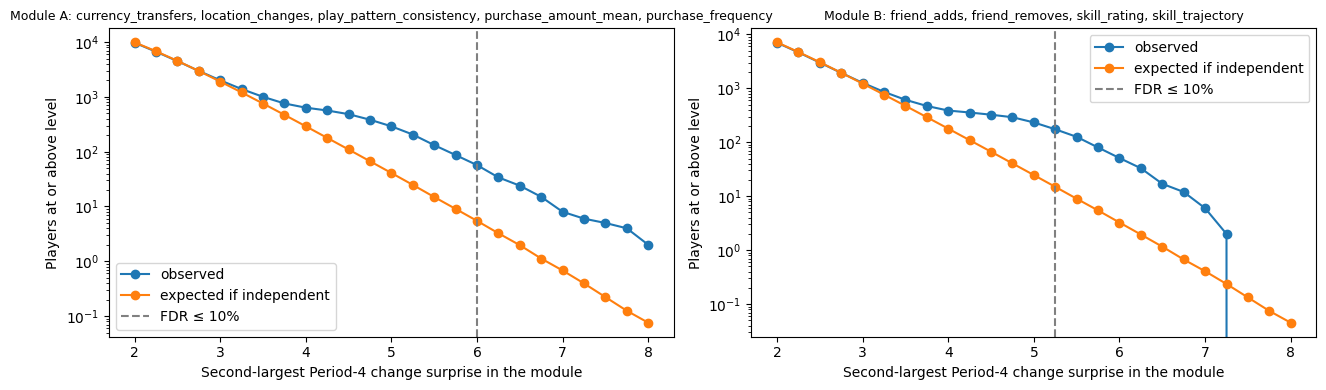

In [217]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (label, table) in zip(axes, jump_fdr_tables.items()):
    ax.plot(table.level, table.observed, marker="o", label="observed")
    ax.plot(table.level, table.expected_if_independent, marker="o", label="expected if independent")
    ax.axvline(jump_thresholds[label], color="gray", linestyle="--", label=f"FDR ≤ {JUMP_FDR:.0%}")
    ax.set_yscale("log")
    ax.set_xlabel("Second-largest Period-4 change surprise in the module")
    ax.set_ylabel("Players at or above level")
    ax.set_title(f"Module {label}: {', '.join(jump_modules[label])}", fontsize=9)
    ax.legend()
fig.tight_layout()
plt.show()

#### 16.3.2 Coverage by the Reference Panel

How many joint-jump players does each panel model already flag? The same question for EDA groups A and B could have been asked before this round was built: Section 14.4.3 already showed that the cohort model's shared alerts contain all of them. The second table repeats the joint-jump count at looser FDR levels, as a sensitivity check only.

In [218]:
coverage_rows = []
for name, alerts in {**REFERENCE_PANEL, "TAIL_TRIM5": candidate_alerts["TAIL_TRIM5"]}.items():
    coverage_rows.append({"reference": name, f"joint_jump_of_{int(joint_jump.sum())}": int((joint_jump & alerts).sum()),
                          f"group_A_of_{int(group_a.sum())}": int((group_a.to_numpy() & alerts).sum()),
                          f"group_B_of_{int(group_b.sum())}": int((group_b.to_numpy() & alerts).sum())})
show(pd.DataFrame(coverage_rows))
sensitivity_rows = []
for fdr_level in (0.10, 0.20, 0.30, 0.50):
    loose = np.zeros(len(player_ids), dtype=bool)
    for label, table in jump_fdr_tables.items():
        loose |= jump_second[label] >= table.loc[table.estimated_fdr <= fdr_level, "level"].min()
    outside = loose & ~candidate_alerts["COHORT_OCSVM_TRIM5"]
    row = {"fdr_level": fdr_level, "joint_jump_players": int(loose.sum()), "outside_cohort_alerts": int(outside.sum())}
    for name, alerts in REFERENCE_PANEL.items():
        if "COHORT" not in name:
            row[f"outside_and_{name.split(' ')[0]}"] = int((outside & alerts).sum())
    sensitivity_rows.append(row)
show(pd.DataFrame(sensitivity_rows))
show(reference_panel_table(["COHORT_JOINT"]))

                     reference  joint_jump_of_231  group_A_of_83  group_B_of_199
        best-known (closeness)                229             83             199
            TAIL_F1 (original)                225             63             180
           OCSVM_F0 (original)                229             83             199
COHORT_OCSVM_TRIM5 (group SVM)                229             83             199
                    TAIL_TRIM5                229             82             199
 fdr_level  joint_jump_players  outside_cohort_alerts  outside_and_best-known  outside_and_TAIL_F1  outside_and_OCSVM_F0
      0.10                 231                      2                       0                    0                     0
      0.20                 675                     21                       1                    4                     2
      0.30                 808                     42                       2                    8                     2
      0.50                1018

#### 16.3.3 Direction of the Joint Jumps

The surprise used so far is two-sided. Among the joint-jump players of each module, count how often each family's own jump is beyond the module threshold, and in which direction it goes. A consistent direction would show that the anomaly pattern has a sign, which the data reveals without labels.

In [219]:
direction_rows = []
for label, members in jump_modules.items():
    flagged = jump_second[label] >= jump_thresholds[label]
    for column, family in enumerate(members):
        change = (test_clean[f"{family}_4"] - test_clean[[f"{family}_{period}" for period in (1, 2, 3)]].median(axis=1)).to_numpy()
        jumped = flagged & (jump_surprises[label][:, column] >= jump_thresholds[label])
        direction_rows.append({"module": label, "family": family, "joint_jump_players": int(flagged.sum()),
                               "family_jumped": int(jumped.sum()),
                               "upward_pct": 100 * np.mean(change[jumped] > 0) if jumped.any() else np.nan,
                               "median_change": np.median(change[jumped]) if jumped.any() else np.nan})
show(pd.DataFrame(direction_rows))

module                   family  joint_jump_players  family_jumped  upward_pct  median_change
     A       currency_transfers                  57             11      100.00          41.21
     A         location_changes                  57             33      100.00          16.30
     A play_pattern_consistency                  57             10        0.00          -0.56
     A     purchase_amount_mean                  57             33      100.00        1166.84
     A       purchase_frequency                  57             32       96.88          20.22
     B              friend_adds                 174            101      100.00          26.25
     B           friend_removes                 174            108       98.15          40.57
     B             skill_rating                 174            104      100.00        2847.30
     B         skill_trajectory                 174            106       98.11         125.77


#### 16.3.4 Where the Remaining Gap Lies

If joint jumps are already covered, the players still missed must look different. Section 9.4.5 found that hidden anomalies stand out most in `activity_level` and `communication_frequency`. Compare the agreement groups on those two families and two other engagement families: the Period-4 level, the player's own P1–P3 baseline, the change between them, and the share of players in the bottom and top 10% of Period 4. This is descriptive error analysis; nothing is fitted to it.

In [220]:
if best_known_alerts is not None:
    cohort_alerts = candidate_alerts["COHORT_OCSVM_TRIM5"]
    gap_groups = alert_groups(cohort_alerts, best_known_alerts, "COHORT", "best-known")
    gap_rows = []
    for family in ("activity_level", "communication_frequency", "login_count", "session_duration_mean"):
        period4 = test_clean[f"{family}_4"]
        baseline = test_clean[[f"{family}_{period}" for period in (1, 2, 3)]].median(axis=1)
        low, high = period4.quantile([0.10, 0.90])
        for label, mask in gap_groups.items():
            gap_rows.append({"family": family, "group": label, "P4_median": period4[mask].median(),
                             "baseline_median": baseline[mask].median(), "change_median": (period4 - baseline)[mask].median(),
                             "P4_bottom10_pct": 100 * period4[mask].lt(low).mean(),
                             "P4_top10_pct": 100 * period4[mask].gt(high).mean()})
    show(pd.DataFrame(gap_rows), digits=3)

                 family           group  P4_median  baseline_median  change_median  P4_bottom10_pct  P4_top10_pct
         activity_level            both      0.988            0.981          0.002           10.888        10.116
         activity_level     COHORT only      0.994            0.992         -0.007           10.786        10.919
         activity_level best-known only      0.797            0.778         -0.001           34.754         7.190
         activity_level         neither      0.991            0.988          0.000            8.570         9.505
communication_frequency            both      0.700            0.702          0.001           14.672         9.575
communication_frequency     COHORT only      0.775            0.796         -0.009           10.919        14.248
communication_frequency best-known only      0.622            0.625          0.000           27.696         6.924
communication_frequency         neither      0.746            0.744          0.000      

#### 16.3.5 Are the Missed Anomalies Central?

The players missed by every own model are not extreme in any single feature. Could anomalies sit in the *middle* of the distribution? A central anomaly can still differ in other ways, so test five label-free ideas of "unusual" and take the top 5% of players under each:

- **too regular**: the lowest four-period variability across families, as a bot that repeats itself might show;
- **too similar to others**: the smallest distance to the 5th nearest neighbor on quantile-normalized F0, as near-copies from an account farm would show;
- **central in every feature**: the smallest maximum |z| over all F0 features;
- **isolated from others**: the largest 5th-neighbor distance, an ordinary outlier view for contrast;
- **quiet**: the lowest four-period levels of `activity_level` plus `communication_frequency`.

Every panel model flags exactly 2,046 players (7.9%), so a panel model that flags clearly more than 7.9% of an idea's group sees that idea as anomalous, and one that flags clearly less sees it as normal.

In [221]:
central_values = QuantileTransformer(n_quantiles=512, output_distribution="normal", random_state=SEED).fit_transform(
    residual_frame.fillna(residual_frame.median()))
neighbor_distance = NearestNeighbors(n_neighbors=6).fit(central_values).kneighbors(central_values)[0][:, -1]
variability = pd.DataFrame({family: residual_frame[[f"{family}_{period}" for period in range(1, 5)]].std(axis=1)
                            / residual_frame[[f"{family}_{period}" for period in range(1, 5)]].abs().mean(axis=1)
                            for family in period_families})
level_rank = family_levels.rank(pct=True)
central_ideas = {"too regular": -variability.rank(pct=True).mean(axis=1).to_numpy(),
                 "too similar to others": -neighbor_distance,
                 "central in every feature": -np.abs(central_values).max(axis=1),
                 "isolated from others": neighbor_distance,
                 "quiet (low activity + communication)": -(level_rank["activity_level"] + level_rank["communication_frequency"]).to_numpy()}
central_rows = []
for idea, score in central_ideas.items():
    top = np.zeros(len(score), dtype=bool)
    top[np.argsort(-score, kind="stable")[:round(0.05 * len(score))]] = True
    row = {"idea": idea, "players": int(top.sum())}
    row.update({f"{name.split(' ')[0]}_flags_pct": 100 * (top & alerts).sum() / top.sum() for name, alerts in REFERENCE_PANEL.items()})
    row["outside_cohort_and_best_known"] = int((top & ~candidate_alerts["COHORT_OCSVM_TRIM5"]
                                                & (best_known_alerts if best_known_alerts is not None else False)).sum())
    central_rows.append(row)
show(pd.DataFrame(central_rows), digits=1)

                                idea  players  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct  outside_cohort_and_best_known
                         too regular     1294                   3.7                3.8                 3.6                           3.8                             31
               too similar to others     1294                   0.8                0.6                 0.2                           0.2                              8
            central in every feature     1294                   7.1                8.2                 6.0                           6.3                             27
                isolated from others     1294                  27.9               29.4                41.3                          41.5                             32
quiet (low activity + communication)     1294                  17.4                6.9                10.7                           9.9                        

#### 16.3.6 Which Side of Each Family Matters?

All family distributions are close to symmetric, yet the two-sided surprise treats both ends alike. Compare the bottom 5% and the top 5% of each player's four-period level for six families, with the share of each group flagged by each panel model (7.9% would mean no preference).

In [222]:
side_rows = []
for family in ("activity_level", "communication_frequency", "login_count", "kda_mean", "skill_rating", "skill_trajectory"):
    level = family_levels[family]
    for side, mask in (("bottom 5%", level.le(level.quantile(0.05)).to_numpy()), ("top 5%", level.ge(level.quantile(0.95)).to_numpy())):
        row = {"family": family, "side": side, "skew": level.skew()}
        row.update({f"{name.split(' ')[0]}_flags_pct": 100 * (mask & alerts).sum() / mask.sum() for name, alerts in REFERENCE_PANEL.items()})
        side_rows.append(row)
show(pd.DataFrame(side_rows), digits=1)

                 family      side  skew  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
         activity_level bottom 5%  -0.0                  26.0                9.9                13.1                           9.7
         activity_level    top 5%  -0.0                   8.5               11.7                14.4                          11.0
communication_frequency bottom 5%  -0.0                  25.3               11.7                13.7                          14.1
communication_frequency    top 5%  -0.0                   6.9               12.4                11.7                          12.0
            login_count bottom 5%   0.1                  12.6               11.9                12.7                          13.4
            login_count    top 5%   0.1                   7.3               11.8                11.3                          11.0
               kda_mean bottom 5%   0.1                   6.4                8.3   

### 16.4 Submission and Result

Not submitted. Forcing the joint-jump players into the cohort ranking changes only **2** of 2,046 alerts, because **229** of the 231 joint-jump players are already selected. A submission could not test the hypothesis.

### 16.5 Findings and Next Hypothesis

- **The joint-jump signal is real.** At level 5, module A has **291** players against **41** expected under independence, and module B **233** against **25**. The 10% FDR rule selects levels **6.0** (A) and **5.25** (B), flagging **57** and **174** players (**231** in total).
- **Result: not submitted, because the signal is already covered.** OCSVM_F0 and the cohort model each contain **229** of the 231 joint-jump players (TAIL_F1 **225**), so forcing them into the cohort ranking changes only **2** alerts. Looser FDR levels add moderate co-movers outside the cohort alerts (up to **177** at 50%), but the panel models rarely flag them, so they look normal from every view.
- **The joint jumps have a fixed direction, found without labels.** Among joint-jump players, module-A families move **up** (location changes, currency transfers, purchase amount, and purchase frequency in 97–100% of jumps) while play-pattern consistency moves **down** in every case; module-B families move **up** in 98–100% of jumps.
- **The remaining gap is quiet, not central.** Every panel model flags central players at about the base rate (**6.0–8.2%**) and too-regular or near-copy players below it (**0.2–3.8%**). Our models also flag **quiet** players (low four-period activity plus communication) at only **6.9–10.7%**, so persistently low engagement is barely covered.
- **Two-sided scoring treats both ends alike.** All six families examined are nearly symmetric, and our models flag the bottom 5% of `activity_level` at **9.7–13.1%**, slightly less than its top 5%. If low engagement is the anomalous side, a one-sided score should reach it.

**What we learned and next.** The structure the data reveals by itself (joint jumps) is already caught, so the next gain should come from a different kind of anomaly: low engagement, on one side of a family. The anomalous side can be learned without labels, from the signs of joint jumps and from which one-sided tails are over-represented; Round 12 builds that. Before that, two prepared candidates test open questions with free submission slots (Round 11).

## 17. Round 11 — Free-Slot Probes

### 17.1 Hypothesis

After Round 10, distance from earlier selections was no longer treated as a reason to reject a candidate: a candidate whose changes test a new, interpretable direction is worth a slot. Three free submission slots before a leaderboard reset made two prepared candidates worth trying:

- **RESIDUAL_CROSS** (Round 9 variant B) removes edge-normal players more than any other model and selects **1,229** players that no panel model flags. Hypothesis: removing normal extremes matters more than what replaces them, so this new direction could score well despite low agreement with every panel model.
- **GLOBAL_OCSVM_TRIM5** isolates the cohort effect from Round 8: the same One-Class SVM with the same Tail-based fit exclusion, but without cohorts.

### 17.2 Model

No new model is trained. **RESIDUAL_CROSS** is Round 9 variant B unchanged. **GLOBAL_OCSVM_TRIM5** is the single global One-Class SVM fitted on F0 with the TAIL_F1 top 5% excluded from fitting, exactly as in the Round 8 factor audit (Section 14.4.3); it differs from the submitted cohort model only by having no cohort split and no within-cohort calibration.

In [223]:
full_candidate_scores["GLOBAL_OCSVM_TRIM5"] = global_trim_scores
candidate_alerts["GLOBAL_OCSVM_TRIM5"] = alerts_from_scores(global_trim_scores)
print(f"GLOBAL_OCSVM_TRIM5 alerts: {int(candidate_alerts['GLOBAL_OCSVM_TRIM5'].sum()):,} | "
      f"RESIDUAL_CROSS alerts: {int(candidate_alerts['RESIDUAL_CROSS'].sum()):,}")

GLOBAL_OCSVM_TRIM5 alerts: 2,046 | RESIDUAL_CROSS alerts: 2,046


### 17.3 Analysis

Report both probes against the reference panel, how many alerts each changes relative to the best own result, and how each treats the two known failure modes and the joint-jump players.

In [224]:
show(reference_panel_table(["GLOBAL_OCSVM_TRIM5", "RESIDUAL_CROSS"]))
probe_rows = []
for name in ("GLOBAL_OCSVM_TRIM5", "RESIDUAL_CROSS"):
    alerts = candidate_alerts[name]
    row = {"candidate": name, "swaps_vs_COHORT": SUBMISSION_ALERTS - int((alerts & candidate_alerts["COHORT_OCSVM_TRIM5"]).sum()),
           f"joint_jump_kept_of_{int(joint_jump.sum())}": int((alerts & joint_jump).sum())}
    if best_known_alerts is not None:
        row[f"edge_normal_kept_of_{int(edge_normal.sum())}"] = int((alerts & edge_normal).sum())
        row[f"hidden_found_of_{int(hidden.sum())}"] = int((alerts & hidden).sum())
    probe_rows.append(row)
show(pd.DataFrame(probe_rows))

         candidate  best-known (closeness)  TAIL_F1 (original)  OCSVM_F0 (original)  COHORT_OCSVM_TRIM5 (group SVM)
GLOBAL_OCSVM_TRIM5                    1329                1058                 1968                            1904
    RESIDUAL_CROSS                     726                 630                  891                             908
         candidate  swaps_vs_COHORT  joint_jump_kept_of_231  edge_normal_kept_of_1019  hidden_found_of_1019
GLOBAL_OCSVM_TRIM5              142                     229                       125                   396
    RESIDUAL_CROSS             1138                     200                        91                   187


### 17.4 Submission and Result

Submit **RESIDUAL_CROSS** first as a direct test of the new direction. It changes **1,138** alerts relative to the cohort model and **1,416** relative to TAIL_F1, and its changed players follow a clear mechanism (normal extremes out, unexplained single-family deviations in), so its score is informative whichever way it goes. **GLOBAL_OCSVM_TRIM5** (**142** swaps from the cohort model) was held at first and then submitted in the same window to isolate the cohort effect. OCSVM_F0 stays unsubmitted.

#### 17.4.1 Export and Format Check

In [225]:
probe_exports = [
    export_or_verify("kaggle_t1234_peer_t5_global_ocsvm_tailtrim5_v1_20261122", candidate_alerts["GLOBAL_OCSVM_TRIM5"],
                     {"candidate": "GLOBAL_OCSVM_TRIM5",
                      "model": "single global One-Class SVM on F0, TAIL_F1 top 5% excluded from fitting only"}),
    export_or_verify("kaggle_t1234_peer_t5_residual_cross_v1_20261122", candidate_alerts["RESIDUAL_CROSS"],
                     {"candidate": "RESIDUAL_CROSS",
                      "model": "out-of-fold LightGBM residuals from other families only, targets with R2 >= 0.2"})]
print(pd.DataFrame(probe_exports).to_string(index=False))

                                                       file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_global_ocsvm_tailtrim5_v1_20261122.csv existing file verified 25889    2046 0f6b7e60da7a26c5
        kaggle_t1234_peer_t5_residual_cross_v1_20261122.csv existing file verified 25889    2046 e5ed7caa879872ea


#### 17.4.2 Public Result

In [226]:
public_results["RESIDUAL_CROSS"] = 0.69554
print(f"RESIDUAL_CROSS public overall score: {public_results['RESIDUAL_CROSS']:.5f} | "
      f"vs COHORT_OCSVM_TRIM5: {public_results['RESIDUAL_CROSS'] - public_results['COHORT_OCSVM_TRIM5']:+.5f} | "
      f"vs TAIL_F1: {public_results['RESIDUAL_CROSS'] - public_results['TAIL_F1']:+.5f} | "
      f"vs best-known: {public_results['RESIDUAL_CROSS'] - public_results['BEST_KNOWN']:+.5f}")
public_results["GLOBAL_OCSVM_TRIM5"] = 0.75358
print(f"GLOBAL_OCSVM_TRIM5 public overall score: {public_results['GLOBAL_OCSVM_TRIM5']:.5f} | "
      f"vs COHORT_OCSVM_TRIM5: {public_results['GLOBAL_OCSVM_TRIM5'] - public_results['COHORT_OCSVM_TRIM5']:+.5f} | "
      f"vs best-known: {public_results['GLOBAL_OCSVM_TRIM5'] - public_results['BEST_KNOWN']:+.5f}")

RESIDUAL_CROSS public overall score: 0.69554 | vs COHORT_OCSVM_TRIM5: -0.05475 | vs TAIL_F1: -0.02864 | vs best-known: -0.12217
GLOBAL_OCSVM_TRIM5 public overall score: 0.75358 | vs COHORT_OCSVM_TRIM5: +0.00329 | vs best-known: -0.06413


#### 17.4.3 Post-Result Error Analysis

Split each probe's change against the cohort model (and RESIDUAL_CROSS also against the original TAIL_F1) into kept, added, and removed alerts, and profile the players RESIDUAL_CROSS adds.

In [227]:
show(swap_analysis(candidate_alerts["RESIDUAL_CROSS"], candidate_alerts["COHORT_OCSVM_TRIM5"], "RESIDUAL_CROSS", "COHORT"))
show(swap_analysis(candidate_alerts["RESIDUAL_CROSS"], candidate_alerts["TAIL_F1"], "RESIDUAL_CROSS", "TAIL_F1"))
show(swap_analysis(candidate_alerts["GLOBAL_OCSVM_TRIM5"], candidate_alerts["COHORT_OCSVM_TRIM5"], "GLOBAL_OCSVM_TRIM5", "COHORT"))

                  group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                   kept      908            95.27                 690                   75.99
added by RESIDUAL_CROSS     1138            55.57                  36                    3.16
    removed from COHORT     1138            89.09                 605                   53.16
                  group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                   kept      630            97.29                 539                   85.56
added by RESIDUAL_CROSS     1416            61.33                 187                   13.21
   removed from TAIL_F1     1416            95.52                 488                   34.46
                      group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                       kept     1904            93.51                1277                   67.07
added by GLOBAL_OCSVM_TRIM5      142            79.7

In [228]:
if best_known_alerts is not None:
    cross_groups = alert_groups(candidate_alerts["RESIDUAL_CROSS"], best_known_alerts, "RESIDUAL_CROSS", "best-known")
    show(alert_group_profile(cross_groups))
    show(dominant_family_table(cross_groups), digits=1)

              group  players  tail_pct_median  tail_pct_P10  A_members  B_members  any_invalid_pct  password_changed_pct  vpn_usage_pct  mass_item_sale_pct  account_age_median  raw_missing_median
               both      726            96.37         84.77         58        163            45.45                 33.43          35.41               22.81              861.58                6.00
RESIDUAL_CROSS only     1320            59.13         20.71          0          0            39.85                  5.48          15.19                3.34              828.53                6.00
    best-known only     1320            87.61         51.87         25         36            39.47                 10.23          16.67                5.73              933.65                6.00
            neither    22523            45.65          8.86          0          0            39.71                  4.92          15.28                2.06              839.89                6.00

                          both  RESIDUAL_CROSS only  best-known only
activity_level             3.2                  4.3             15.5
communication_frequency    2.9                  4.2             14.0
skill_trajectory           5.6                 12.4              0.6
play_pattern_consistency  10.3                  3.9              4.3
session_duration_mean      9.2                  4.7              3.2
kda_std                    1.0                  1.3              9.1
reaction_time_mean         8.5                  5.0              2.6
purchase_frequency         7.2                  7.8              1.4


### 17.5 Findings and Next Hypothesis

- **Result 1: the new direction failed clearly.** RESIDUAL_CROSS scored **0.69554**: **−0.05475** versus the cohort model and **−0.02864** versus TAIL_F1.
- **Why: what it added was ordinary.** The added players are near the middle of the distribution (median tail percentile **55.6**) with ordinary event rates, the kind of player Section 16.3.5 found that no panel model considers anomalous. Its mechanism also dropped **31** of the 231 easy joint-jump anomalies, so removing normal extremes is not enough on its own.
- **Result 2: the cohort split hurt.** GLOBAL_OCSVM_TRIM5 scored **0.75358**, **+0.00329** over the cohort model, and is the best own result. The Round 8 gain therefore came from the One-Class SVM family plus the fit exclusion; the age/activity cohorts slightly hurt.

**What we learned and next (Round 12).** Refining one score has stalled around 0.75, and the structure the data reveals by itself is already covered. The remaining difference points to a second anomaly mechanism, persistently low engagement, which needs its own detector rather than another version of the same score.

## 18. Round 12 — Dual-Mechanism Detector

### 18.1 Hypothesis

Rounds 9–11 kept refining one score for one kind of anomaly. Every structure the data reveals by itself (the two joint-jump modules and a low-variance module) is already covered by the best own model, and adjusting that model has stalled around 0.75. Round 10 showed where the remaining difference lies: players whose activity or communication is low in *every* period, neither changing nor extreme in the way a two-sided detector notices. The scale check below shows why the One-Class SVM misses them. After RobustScaler, the extreme values of `skill_trajectory` and `friend_removes` reach about 20 IQR, while `activity_level` and `communication_frequency` stay near 2, so the RBF distance is dominated by the jump families.

Hypothesis: there are at least two anomaly mechanisms, abrupt or extreme behavior and persistently low engagement, and a single anomaly score cannot rank both. A second detector dedicated to persistent low engagement, combined with the best own model without disturbing what it already catches, should find anomalies the first one misses. The direction "low is anomalous" must come from the data, not from the reference files.

In [229]:
scaled_extremes = (pd.DataFrame(np.abs(ocsvm_full_values), columns=residual_targets).quantile(0.999)
                   .groupby([feature_family(column) for column in residual_targets]).max().sort_values(ascending=False))
print("99.9th percentile of |RobustScaler value| by family (the scale Expert A sees):")
show(scaled_extremes.rename("abs_scaled_p999").to_frame().head(6), digits=1)
print(f"activity_level: {scaled_extremes['activity_level']:.1f} | communication_frequency: {scaled_extremes['communication_frequency']:.1f} | "
      f"median family: {scaled_extremes.median():.1f}")

99.9th percentile of |RobustScaler value| by family (the scale Expert A sees):
                    abs_scaled_p999
skill_trajectory               22.2
friend_removes                 19.5
location_changes               11.8
currency_transfers              8.8
purchase_frequency              8.5
skill_rating                    5.5
activity_level: 1.9 | communication_frequency: 1.9 | median family: 2.0


### 18.2 Model

**Step 1: find the anomalous side of each family without labels.** All family distributions are close to symmetric (Section 16.3.6), so in the population as a whole about as many players should lie far below the median as far above it. Count players whose four-period level is more than **1.5 IQR** below or above the median. A side is marked anomalous when its count is significantly larger than the other side's (one-sided binomial test, Bonferroni-corrected over all families) **and** at least **10×** larger. The effect-size condition was added after a significance-only version also admitted `ip_hash_entropy`, whose mild 1.5× asymmetry comes from its hard upper bound of 0.8 rather than from a separate group of players; that version is kept as a sensitivity check in Section 18.3.1.

In [230]:
from scipy.stats import binomtest

ASYMMETRY_IQR = 1.5
ASYMMETRY_RATIO = 10
asymmetry_alpha = 0.05 / len(period_families)
asymmetry_rows = []
for family in period_families:
    level = family_levels[family].dropna()
    center, spread = level.median(), level.quantile(0.75) - level.quantile(0.25)
    low = int((level < center - ASYMMETRY_IQR * spread).sum())
    high = int((level > center + ASYMMETRY_IQR * spread).sum())
    asymmetry_rows.append({"family": family, "far_below": low, "far_above": high,
                           "p_low_excess": binomtest(low, low + high, 0.5, alternative="greater").pvalue if low + high else 1.0,
                           "p_high_excess": binomtest(high, low + high, 0.5, alternative="greater").pvalue if low + high else 1.0})
asymmetry = pd.DataFrame(asymmetry_rows)
asymmetry["low_side_anomalous"] = (asymmetry.p_low_excess < asymmetry_alpha) & (asymmetry.far_below >= ASYMMETRY_RATIO * asymmetry.far_above.clip(lower=1))
asymmetry["high_side_anomalous"] = (asymmetry.p_high_excess < asymmetry_alpha) & (asymmetry.far_above >= ASYMMETRY_RATIO * asymmetry.far_below.clip(lower=1))
quiet_families = asymmetry.loc[asymmetry.low_side_anomalous, "family"].tolist()
show(asymmetry.sort_values(["low_side_anomalous", "far_below"], ascending=False), digits=4)
print(f"Low side anomalous: {quiet_families}")
print(f"High side anomalous: {asymmetry.loc[asymmetry.high_side_anomalous, 'family'].tolist()}")

                      family  far_below  far_above  p_low_excess  p_high_excess  low_side_anomalous  high_side_anomalous
2             activity_level        246          4        0.0000         1.0000                True                False
3    communication_frequency        232          1        0.0000         1.0000                True                False
14       login_time_variance        197          2        0.0000         1.0000                True                False
9            ip_hash_entropy        585        399        0.0000         1.0000               False                False
26          skill_trajectory        554        811        1.0000         0.0000               False                False
16  play_pattern_consistency         22         36        0.9760         0.0435               False                False
24      session_duration_std          9          2        0.0327         0.9941               False                False
5               device_count    

**Step 2: Expert B, persistent low engagement.** For each low-side family, a player's one-sided surprise is −log of their percentile from the bottom of the four-period level (a missing level contributes nothing). Expert B is the **maximum** over these families, because the families are independent and a player may be unusually low in only one of them.

**Step 3: combine with Expert A.** Expert A is the best own model, GLOBAL_OCSVM_TRIM5 (Round 11). Each expert's score is converted to its percentile among all players, and a player's combined score is the **larger** of the two percentiles (rank-max), so each expert contributes its own most confident players without one scale overwhelming the other. The 231 joint-jump players from Round 10 are always kept. The alert budget stays at **2,046**, so any score change comes from the ranking alone.

In [231]:
quiet_percentile = family_levels[quiet_families].rank(pct=True, method="average")
full_candidate_scores["QUIET_EXPERT"] = (-np.log(quiet_percentile.fillna(1.0))).max(axis=1).to_numpy()


def percentile_rank(values):
    return pd.Series(values).rank(pct=True, method="average").to_numpy()


full_candidate_scores["DUAL_MECHANISM"] = (np.maximum(percentile_rank(global_trim_scores),
                                                      percentile_rank(full_candidate_scores["QUIET_EXPERT"]))
                                           + 10.0 * joint_jump)
candidate_alerts["DUAL_MECHANISM"] = alerts_from_scores(full_candidate_scores["DUAL_MECHANISM"])
assert candidate_alerts["DUAL_MECHANISM"][joint_jump].all()
print(f"Expert B families: {quiet_families} | DUAL_MECHANISM alerts: {int(candidate_alerts['DUAL_MECHANISM'].sum()):,}")

Expert B families: ['activity_level', 'communication_frequency', 'login_time_variance'] | DUAL_MECHANISM alerts: 2,046


### 18.3 Analysis

#### 18.3.1 Reference Panel Comparison

Compare the dual-mechanism candidate with the panel and with the best own scored model. The sensitivity row repeats the construction with the significance-only family rule.

In [232]:
show(reference_panel_table(["GLOBAL_OCSVM_TRIM5", "DUAL_MECHANISM"]))
significance_families = asymmetry.loc[asymmetry.p_low_excess < asymmetry_alpha, "family"].tolist()
significance_score = (-np.log(family_levels[significance_families].rank(pct=True, method="average").fillna(1.0))).max(axis=1).to_numpy()
significance_alerts = alerts_from_scores(np.maximum(percentile_rank(global_trim_scores), percentile_rank(significance_score)) + 10.0 * joint_jump)
print(f"Sensitivity (significance-only families {significance_families}): shares "
      f"{int((significance_alerts & candidate_alerts['DUAL_MECHANISM']).sum()):,} alerts with DUAL_MECHANISM"
      + (f", {int((significance_alerts & best_known_alerts).sum()):,} with best-known" if best_known_alerts is not None else ""))

         candidate  best-known (closeness)  TAIL_F1 (original)  OCSVM_F0 (original)  COHORT_OCSVM_TRIM5 (group SVM)
GLOBAL_OCSVM_TRIM5                    1329                1058                 1968                            1904
    DUAL_MECHANISM                    1587                1034                 1285                            1264
Sensitivity (significance-only families ['activity_level', 'communication_frequency', 'ip_hash_entropy', 'login_time_variance']): shares 1,923 alerts with DUAL_MECHANISM, 1,589 with best-known


#### 18.3.2 Swap Analysis versus the Best Own Model

Which players does Expert B bring in, which Expert-A alerts make room for them, and how do the panel models see each group? The second table splits the added players by the family that made them enter (their lowest family percentile).

In [233]:
show(swap_analysis(candidate_alerts["DUAL_MECHANISM"], candidate_alerts["GLOBAL_OCSVM_TRIM5"], "DUAL", "GLOBAL_OCSVM_TRIM5"))
dual_added = candidate_alerts["DUAL_MECHANISM"] & ~candidate_alerts["GLOBAL_OCSVM_TRIM5"]
dual_removed = ~candidate_alerts["DUAL_MECHANISM"] & candidate_alerts["GLOBAL_OCSVM_TRIM5"]
entry_family = quiet_percentile.fillna(1.0).idxmin(axis=1).to_numpy()
entry_rows = []
for family in quiet_families:
    mask = dual_added & (entry_family == family)
    row = {"entered_via": family, "players": int(mask.sum())}
    row.update({f"{name.split(' ')[0]}_flags_pct": 100 * (mask & alerts).sum() / max(int(mask.sum()), 1)
                for name, alerts in REFERENCE_PANEL.items()})
    entry_rows.append(row)
removed_row = {"entered_via": "(removed Expert-A alerts)", "players": int(dual_removed.sum())}
removed_row.update({f"{name.split(' ')[0]}_flags_pct": 100 * (dual_removed & alerts).sum() / max(int(dual_removed.sum()), 1)
                    for name, alerts in REFERENCE_PANEL.items()})
show(pd.DataFrame(entry_rows + [removed_row]), digits=1)

                          group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                           kept     1293            96.10                1199                   92.73
                  added by DUAL      753            76.73                 388                   51.53
removed from GLOBAL_OCSVM_TRIM5      753            78.50                 130                   17.26
              entered_via  players  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
           activity_level      305                  67.5                9.8                 0.7                           0.0
  communication_frequency      292                  62.0               16.1                 2.1                           3.1
      login_time_variance      156                   0.6                4.5                 0.0                           0.0
(removed Expert-A alerts)      753                  17.3               14.3             

#### 18.3.3 Failure Modes and Joint Jumps

In [234]:
if best_known_alerts is not None:
    show(pd.DataFrame([{"candidate": name, f"joint_jump_kept_of_{int(joint_jump.sum())}": int((candidate_alerts[name] & joint_jump).sum()),
                        f"edge_normal_kept_of_{int(edge_normal.sum())}": int((candidate_alerts[name] & edge_normal).sum()),
                        f"hidden_found_of_{int(hidden.sum())}": int((candidate_alerts[name] & hidden).sum())}
                       for name in ("COHORT_OCSVM_TRIM5", "GLOBAL_OCSVM_TRIM5", "DUAL_MECHANISM")]))

         candidate  joint_jump_kept_of_231  edge_normal_kept_of_1019  hidden_found_of_1019
COHORT_OCSVM_TRIM5                     229                       132                   373
GLOBAL_OCSVM_TRIM5                     229                       125                   396
    DUAL_MECHANISM                     231                        62                   615


### 18.4 Submission and Result

Submitted. It changes **753** alerts relative to the best own model, a large change with a clear mechanism: the players it adds come almost entirely from the low tails of activity and communication, which no own model flagged (OCSVM_F0 **0.7–2.1%**, cohort **0.0–3.1%**), and it keeps all **231** joint-jump players.

#### 18.4.1 Export and Format Check

In [235]:
print(pd.DataFrame([export_or_verify("kaggle_t1234_peer_t5_dual_mechanism_v1_20261122", candidate_alerts["DUAL_MECHANISM"],
                                     {"candidate": "DUAL_MECHANISM",
                                      "model": "rank-max of GLOBAL_OCSVM_TRIM5 and a one-sided low-engagement expert; joint-jump players kept",
                                      "quiet_families": quiet_families,
                                      "family_rule": "low side far below median (1.5 IQR) significantly and at least 10x more often than far above; no labels"})]).to_string(index=False))

                                               file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_dual_mechanism_v1_20261122.csv existing file verified 25889    2046 3a2b51af096ec0c6

#### 18.4.2 Public Result

In [236]:
public_results["DUAL_MECHANISM"] = 0.77854
print(f"DUAL_MECHANISM public overall score: {public_results['DUAL_MECHANISM']:.5f} | "
      f"vs GLOBAL_OCSVM_TRIM5: {public_results['DUAL_MECHANISM'] - public_results['GLOBAL_OCSVM_TRIM5']:+.5f} | "
      f"vs best-known: {public_results['DUAL_MECHANISM'] - public_results['BEST_KNOWN']:+.5f}")

DUAL_MECHANISM public overall score: 0.77854 | vs GLOBAL_OCSVM_TRIM5: +0.02496 | vs best-known: -0.03917


#### 18.4.3 Post-Result Error Analysis

The score rose, so the second mechanism is real. What is still missed? Compare the mean level percentile (0.5 = typical) of every family across the agreement groups in the code below. A family where the missed players sit far from 0.5 points to a mechanism that no own expert covers yet.

In [237]:
if best_known_alerts is not None:
    remaining_groups = alert_groups(candidate_alerts["DUAL_MECHANISM"], best_known_alerts, "DUAL", "best-known")
    level_percentile = family_levels.rank(pct=True)
    remaining_profile = pd.DataFrame({label: level_percentile[mask].mean() for label, mask in remaining_groups.items()})
    remaining_profile["best_known_only_shift"] = remaining_profile["best-known only"] - remaining_profile["neither"]
    show(remaining_profile.reindex(remaining_profile.best_known_only_shift.abs().sort_values(ascending=False).index).head(10), digits=3)

                       both  DUAL only  best-known only  neither  best_known_only_shift
kda_std               0.432      0.482            0.746    0.500                  0.246
accuracy_std          0.500      0.501            0.739    0.495                  0.243
behavior_stability    0.481      0.518            0.282    0.505                 -0.223
performance_stability 0.546      0.521            0.670    0.493                  0.177
purchase_frequency    0.550      0.502            0.668    0.493                  0.174
login_count           0.487      0.516            0.364    0.503                 -0.139
account_age_days      0.507      0.478            0.608    0.498                  0.110
session_duration_mean 0.495      0.508            0.476    0.501                 -0.025
accuracy_mean         0.516      0.487            0.517    0.499                  0.018
purchase_amount_mean  0.558      0.489            0.480    0.497                 -0.016


### 18.5 Findings and Next Hypothesis

- **The data marks the anomalous side of each family by itself.** Although every family is nearly symmetric overall, players far from the median (beyond 1.5 IQR) are strongly one-sided in eleven families. The **low** side dominates for `activity_level` (**246** below versus **4** above), `communication_frequency` (**232** versus **1**), and `login_time_variance` (**197** versus **2**). The **high** side dominates for the joint-jump families (location changes, currency transfers, purchase frequency and amount, friend removals, skill rating) and for KDA and accuracy means. `login_count` and `session_duration_mean` have no far tail at all.
- **Result: the largest single gain of all rounds.** The public score rose to **0.77854**, **+0.02496** over GLOBAL_OCSVM_TRIM5.
- **Why: Expert B adds players no own model saw.** Of the 753 added players, **305** entered via `activity_level` and **292** via `communication_frequency`; OCSVM_F0 flags only **0.7%** and **2.1%** of them and the cohort model **0.0%** and **3.1%**. The dual detector also keeps all **231** joint-jump players.
- **What is still missed is a third, moderate pattern.** The missed players sit at a mean `kda_std` percentile of **0.746** and `accuracy_std` of **0.739** (typical: **0.50**), with low `behavior_stability` (**0.282**) and raised `performance_stability` and `purchase_frequency`. None of them is far in any single feature, so no tail-based expert reaches them.

**What we learned and next (Round 13).** The dataset mixes several anomaly mechanisms, and each one needs its own expert. The next experts should be discovered without labels and sized by their own evidence instead of sharing the budget equally.

## 19. Round 13 — Mechanism-Gated Experts

### 19.1 Hypothesis

Round 12 confirmed that the dataset mixes several anomaly mechanisms and that a dedicated expert per mechanism helps. Its post-result profile (Section 18.4.3) shows what is still missed: players with clearly high `kda_std` and `accuracy_std` and low `behavior_stability`, an *erratic performance* pattern that is moderate in every single feature, so no tail-based expert reaches it.

Two hypotheses follow. First, more mechanisms of this kind can be found **without labels**, as groups of tails that co-occur beyond independence, and each one that is not yet covered deserves its own expert. Second, experts should not share the budget equally: rank-max gives a small mechanism as many alerts as a large one, pushing it deep into its ranking. Instead, each expert should nominate only the population whose size it can justify from the data, and the generalist should fill the rest.

### 19.2 Model

**Step 1: discover mechanisms without labels.** Mark every family level (including the two global features) as in its bottom or top 10%. For every pair of family-sides, compare how often both tails occur together with the count expected if the two were independent. Pairs with at least **1.4×** the expected count and a significant binomial excess (Bonferroni over all pairs and sides) are connected, and the connected groups are candidate **mechanism modules**. For each module, count the players with at least two of its tails, compare that count with the independence expectation (a module-level excess ratio), and check how many of them the current best candidate already flags. A module becomes a new expert only if it shows a module-level excess of at least **1.4×** and fewer than **20%** of its players are already flagged, applying the Round 10 lesson to check coverage first. These rules are fixed before any panel comparison.

In [238]:
MODULE_TAIL = 0.10
MODULE_RATIO = 1.4
module_percentile = family_levels.rank(pct=True)
module_columns = list(module_percentile.columns)
tail_flags = {}
for column in module_columns:
    tail_flags[(column, "low")] = (module_percentile[column] <= MODULE_TAIL).to_numpy()
    tail_flags[(column, "high")] = (module_percentile[column] >= 1 - MODULE_TAIL).to_numpy()
pair_alpha = 0.05 / (len(module_columns) * (len(module_columns) - 1) * 2)
pair_rows = []
for i, left in enumerate(module_columns):
    for right in module_columns[i + 1:]:
        for left_side in ("low", "high"):
            for right_side in ("low", "high"):
                a, b = tail_flags[(left, left_side)], tail_flags[(right, right_side)]
                observed = int((a & b).sum())
                expected_rate = a.mean() * b.mean()
                if observed >= MODULE_RATIO * expected_rate * len(a) and \
                        binomtest(observed, len(a), expected_rate, alternative="greater").pvalue < pair_alpha:
                    pair_rows.append({"left": f"{left}:{left_side}", "right": f"{right}:{right_side}",
                                      "observed": observed, "ratio": observed / (expected_rate * len(a))})
module_pairs = pd.DataFrame(pair_rows).sort_values("ratio", ascending=False)
show(module_pairs, digits=2)

                             left                          right  observed  ratio
5             friend_removes:high          skill_trajectory:high       486   1.88
1     communication_frequency:low               friend_adds:high       483   1.87
0               accuracy_std:high                   kda_std:high       459   1.77
21  play_pattern_consistency:high       session_duration_std:low       444   1.72
7             ip_hash_entropy:low        login_time_variance:low       437   1.69
12                    kda_std:low     performance_stability:high       437   1.69
20     performance_stability:high       session_duration_std:low       436   1.68
17        login_time_variance:low  play_pattern_consistency:high       435   1.68
11                    kda_std:low        login_time_variance:low       434   1.68
18        login_time_variance:low       session_duration_std:low       432   1.67
8             ip_hash_entropy:low     performance_stability:high       432   1.67
10            ip

In [239]:
node_parent = {node: node for row in pair_rows for node in (row["left"], row["right"])}


def node_root(node):
    while node_parent[node] != node:
        node = node_parent[node]
    return node


for row in pair_rows:
    node_parent[node_root(row["left"])] = node_root(row["right"])
mechanism_modules = {}
for node in sorted(node_parent):
    mechanism_modules.setdefault(node_root(node), []).append(node)
module_rows = []
for members in sorted(mechanism_modules.values(), key=len, reverse=True):
    flags = np.column_stack([tail_flags[tuple(node.split(":"))] for node in members])
    in_module = flags.sum(axis=1) >= 2
    expected = len(in_module) * probability_at_least_two(flags.mean(axis=0))
    row = {"module": ", ".join(members), "players": int(in_module.sum()), "excess_ratio": in_module.sum() / expected,
           "flagged_by_DUAL_pct": 100 * candidate_alerts["DUAL_MECHANISM"][in_module].mean()}
    row.update({f"{name.split(' ')[0]}_flags_pct": 100 * (in_module & alerts).sum() / max(int(in_module.sum()), 1)
                for name, alerts in REFERENCE_PANEL.items()})
    row["new_expert"] = row["excess_ratio"] >= MODULE_RATIO and row["flagged_by_DUAL_pct"] < 20
    module_rows.append(row)
module_table = pd.DataFrame(module_rows)
show(module_table, digits=2)
new_modules = [members for members, row in zip(sorted(mechanism_modules.values(), key=len, reverse=True), module_rows)
               if row["new_expert"]]
print("New expert modules:", new_modules)

                                                                                                                                        module  players  excess_ratio  flagged_by_DUAL_pct  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct  new_expert
ip_hash_entropy:low, kda_std:low, login_time_variance:low, performance_stability:high, play_pattern_consistency:high, session_duration_std:low     2741          0.93                16.27                 14.16              14.63               15.47                         16.38       False
                                                                             communication_frequency:low, friend_adds:high, guild_changes:high      848          1.22                41.16                 37.50              15.09               20.52                         21.11       False
                                                                       currency_transfers:high, location_changes:high, purchase_fr

**Step 2: size each new mechanism.** A new module's expert scores each player by the **second-smallest** one-sided tail percentile among the module's members, so it is small only when at least two members are in their anomalous tails together. As in Round 10, compare the observed number of players below each level with the number expected if the members were independent. The expert nominates the players up to the largest tail level whose estimated false discovery rate is at most **20%**. This rule is looser than Round 10's 10% because this mechanism has no far tails, and 10% would admit only a few dozen players; the 10% version is reported as a sensitivity check.

In [240]:
MECHANISM_FDR = 0.20


def directional_percentiles(members):
    """Percentile from the anomalous end of each member's tail (small = deep in the tail)."""
    return pd.DataFrame({node: family_levels[node.split(":")[0]].rank(pct=True, ascending=node.endswith(":low"))
                         for node in members})


new_mechanism_sets, mechanism_fdr_tables = {}, {}
for members in new_modules:
    directional = directional_percentiles(members)
    second_smallest = np.sort(directional.fillna(1.0).to_numpy(), axis=1)[:, 1]
    rows = []
    for level in np.round(np.arange(0.01, 0.201, 0.01), 2):
        observed = int((second_smallest <= level).sum())
        expected = len(second_smallest) * probability_at_least_two((directional <= level).mean().to_numpy())
        rows.append({"tail_level": level, "observed": observed, "expected_if_independent": expected,
                     "estimated_fdr": expected / max(observed, 1)})
    table = pd.DataFrame(rows)
    label = " + ".join(members)
    chosen = table.loc[table.estimated_fdr <= MECHANISM_FDR, "tail_level"].max()
    strict = table.loc[table.estimated_fdr <= 0.10, "tail_level"].max()
    new_mechanism_sets[label] = second_smallest <= chosen
    mechanism_fdr_tables[label] = table
    show(table[table.tail_level.isin([0.01, 0.02, 0.03, 0.04, 0.06, 0.08, 0.10])], digits=3)
    print(f"{label}: level {chosen} at FDR <= {MECHANISM_FDR:.0%} -> {int(new_mechanism_sets[label].sum())} players | "
          f"FDR <= 10% would give level {strict} -> {int((second_smallest <= strict).sum()) if pd.notna(strict) else 0} players")

   tail_level  observed  expected_if_independent  estimated_fdr
0       0.010        27                    2.571          0.095
1       0.020        90                   10.324          0.115
2       0.030       134                   23.260          0.174
3       0.040       180                   41.378          0.230
5       0.060       270                   93.160          0.345
7       0.080       357                  165.670          0.464
9       0.100       459                  258.710          0.564
accuracy_std:high + kda_std:high: level 0.03 at FDR <= 20% -> 134 players | FDR <= 10% would give level 0.01 -> 27 players


**Step 3: gated allocation.** Rank-max gives every expert the same share of the budget whatever the size of its mechanism. Instead, each expert now nominates only the population it can justify without labels: the 231 joint-jump players (Round 10), the players beyond 1.5 IQR on every anomalous side found in Round 12 (both low and high sides), and the new mechanism's players from Step 2. All nominated players are flagged, and the remaining budget is filled by the generalist, Expert A (GLOBAL_OCSVM_TRIM5). The alert budget stays at 2,046.

In [241]:
far_side_population = np.zeros(len(player_ids), dtype=bool)
for row in asymmetry.itertuples():
    level = family_levels[row.family]
    center, spread = level.median(), level.quantile(0.75) - level.quantile(0.25)
    if row.low_side_anomalous:
        far_side_population |= (level < center - ASYMMETRY_IQR * spread).to_numpy()
    if row.high_side_anomalous:
        far_side_population |= (level > center + ASYMMETRY_IQR * spread).to_numpy()
new_mechanism_population = np.logical_or.reduce(list(new_mechanism_sets.values())) if new_mechanism_sets else np.zeros(len(player_ids), dtype=bool)
nominated = joint_jump | far_side_population | new_mechanism_population
full_candidate_scores["GATED_EXPERTS"] = percentile_rank(global_trim_scores) + 10.0 * nominated
candidate_alerts["GATED_EXPERTS"] = alerts_from_scores(full_candidate_scores["GATED_EXPERTS"])
assert nominated.sum() <= SUBMISSION_ALERTS and candidate_alerts["GATED_EXPERTS"][nominated].all()
print(f"Nominated: joint jumps {int(joint_jump.sum())} | far one-sided populations {int(far_side_population.sum())} | "
      f"new mechanism {int(new_mechanism_population.sum())} | union {int(nominated.sum())} | "
      f"filled by Expert A: {SUBMISSION_ALERTS - int(nominated.sum())}")

Nominated: joint jumps 231 | far one-sided populations 1416 | new mechanism 134 | union 1558 | filled by Expert A: 488


### 19.3 Analysis

#### 19.3.1 Reference Panel Comparison

In [242]:
show(reference_panel_table(["GLOBAL_OCSVM_TRIM5", "DUAL_MECHANISM", "GATED_EXPERTS"]))
print(f"Model-to-model: GATED_EXPERTS vs DUAL_MECHANISM {int((candidate_alerts['GATED_EXPERTS'] & candidate_alerts['DUAL_MECHANISM']).sum()):,} | "
      f"vs GLOBAL_OCSVM_TRIM5 {int((candidate_alerts['GATED_EXPERTS'] & candidate_alerts['GLOBAL_OCSVM_TRIM5']).sum()):,}")

         candidate  best-known (closeness)  TAIL_F1 (original)  OCSVM_F0 (original)  COHORT_OCSVM_TRIM5 (group SVM)
GLOBAL_OCSVM_TRIM5                    1329                1058                 1968                            1904
    DUAL_MECHANISM                    1587                1034                 1285                            1264
     GATED_EXPERTS                    1728                1086                 1575                            1557
Model-to-model: GATED_EXPERTS vs DUAL_MECHANISM 1,622 | vs GLOBAL_OCSVM_TRIM5 1,580


#### 19.3.2 Swap Analysis versus the Best Scored Model

Compare the change against DUAL_MECHANISM, the best scored model, and split the added players by the expert that nominated them.

In [243]:
show(swap_analysis(candidate_alerts["GATED_EXPERTS"], candidate_alerts["DUAL_MECHANISM"], "GATED", "DUAL"))
gated_added = candidate_alerts["GATED_EXPERTS"] & ~candidate_alerts["DUAL_MECHANISM"]
gated_removed = ~candidate_alerts["GATED_EXPERTS"] & candidate_alerts["DUAL_MECHANISM"]
source_rows = []
for source, mask in (("new mechanism", gated_added & new_mechanism_population),
                     ("far one-sided population", gated_added & far_side_population & ~new_mechanism_population),
                     ("Expert A fill", gated_added & ~nominated),
                     ("(removed DUAL alerts)", gated_removed)):
    row = {"source": source, "players": int(mask.sum())}
    row.update({f"{name.split(' ')[0]}_flags_pct": 100 * (mask & alerts).sum() / max(int(mask.sum()), 1)
                for name, alerts in REFERENCE_PANEL.items()})
    source_rows.append(row)
show(pd.DataFrame(source_rows), digits=1)

            group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
             kept     1622            94.84                1540                   94.94
   added by GATED      424            81.12                 188                   44.34
removed from DUAL      424            62.60                  47                   11.08


                  source  players  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
           new mechanism      131                  93.1               15.3                18.3                          15.3
far one-sided population        8                   0.0               25.0                25.0                          25.0
           Expert A fill      285                  23.2               19.3                98.6                          99.6
   (removed DUAL alerts)      424                  11.1                5.9                 4.0                           3.1


#### 19.3.3 Why Equal Rank-Max Fails with Three Experts

For contrast, combine Experts A, B, and the new mechanism's expert by the Round 12 rank-max rule instead of gated allocation. The new expert's score is its second-smallest tail percentile, turned into a percentile rank like the others.

In [244]:
if new_modules:
    members = new_modules[0]
    directional = directional_percentiles(members)
    new_expert_score = -np.sort(directional.fillna(1.0).to_numpy(), axis=1)[:, 1]
    triple_alerts = alerts_from_scores(np.maximum.reduce([percentile_rank(global_trim_scores),
                                                          percentile_rank(full_candidate_scores["QUIET_EXPERT"]),
                                                          percentile_rank(new_expert_score)]) + 10.0 * joint_jump)
    show(swap_analysis(triple_alerts, candidate_alerts["DUAL_MECHANISM"], "RANK_MAX_3", "DUAL"))
    if best_known_alerts is not None:
        print(f"RANK_MAX_3 shares {int((triple_alerts & best_known_alerts).sum()):,} alerts with the best-known file "
              f"(GATED_EXPERTS: {int((candidate_alerts['GATED_EXPERTS'] & best_known_alerts).sum()):,}).")

              group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
               kept     1393            95.27                1358                   97.49
added by RANK_MAX_3      653            61.39                 235                   35.99
  removed from DUAL      653            75.39                 229                   35.07
RANK_MAX_3 shares 1,593 alerts with the best-known file (GATED_EXPERTS: 1,728).


#### 19.3.4 Failure Modes and Joint Jumps

In [245]:
if best_known_alerts is not None:
    show(pd.DataFrame([{"candidate": name, f"joint_jump_kept_of_{int(joint_jump.sum())}": int((candidate_alerts[name] & joint_jump).sum()),
                        f"edge_normal_kept_of_{int(edge_normal.sum())}": int((candidate_alerts[name] & edge_normal).sum()),
                        f"hidden_found_of_{int(hidden.sum())}": int((candidate_alerts[name] & hidden).sum())}
                       for name in ("GLOBAL_OCSVM_TRIM5", "DUAL_MECHANISM", "GATED_EXPERTS")]))

         candidate  joint_jump_kept_of_231  edge_normal_kept_of_1019  hidden_found_of_1019
GLOBAL_OCSVM_TRIM5                     229                       125                   396
    DUAL_MECHANISM                     231                        62                   615
     GATED_EXPERTS                     231                        81                   723


### 19.4 Submission and Result

Submitted. Against the best scored model at the time (DUAL_MECHANISM), it changes **424** alerts; most of the removed players are DUAL's deep quiet-ranking entries. The **131** players nominated by the new erratic-performance expert are flagged by the original and cohort models only **15–18%** of the time, so the candidate adds a mechanism no own model covered.

#### 19.4.1 Export and Format Check

In [246]:
print(pd.DataFrame([export_or_verify("kaggle_t1234_peer_t5_gated_experts_v1_20261124", candidate_alerts["GATED_EXPERTS"],
                                     {"candidate": "GATED_EXPERTS",
                                      "model": "label-free mechanism populations (joint jumps, far one-sided tails, co-occurring module tails at FDR <= 20%) flagged first; GLOBAL_OCSVM_TRIM5 fills the rest",
                                      "new_modules": [" + ".join(members) for members in new_modules]})]).to_string(index=False))

                                              file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_gated_experts_v1_20261124.csv existing file verified 25889    2046 4a0b433efb9d2501


#### 19.4.2 Public Result

In [247]:
public_results["GATED_EXPERTS"] = 0.79247
print(f"GATED_EXPERTS public overall score: {public_results['GATED_EXPERTS']:.5f} | "
      f"vs DUAL_MECHANISM: {public_results['GATED_EXPERTS'] - public_results['DUAL_MECHANISM']:+.5f} | "
      f"vs best-known: {public_results['GATED_EXPERTS'] - public_results['BEST_KNOWN']:+.5f}")

GATED_EXPERTS public overall score: 0.79247 | vs DUAL_MECHANISM: +0.01393 | vs best-known: -0.02524


#### 19.4.3 Post-Result Error Analysis

Repeat the Round 12 profile for the new best model, GATED_EXPERTS: the mean level percentile of each family for each agreement group.

In [248]:
if best_known_alerts is not None:
    remaining_groups = alert_groups(candidate_alerts["GATED_EXPERTS"], best_known_alerts, "GATED", "best-known")
    remaining_profile = pd.DataFrame({label: level_percentile[mask].mean() for label, mask in remaining_groups.items()})
    remaining_profile["best_known_only_shift"] = remaining_profile["best-known only"] - remaining_profile["neither"]
    print({label: int(mask.sum()) for label, mask in remaining_groups.items()})
    show(remaining_profile.reindex(remaining_profile.best_known_only_shift.abs().sort_values(ascending=False).index).head(8), digits=3)

{'both': 1728, 'GATED only': 318, 'best-known only': 318, 'neither': 23525}
                         both  GATED only  best-known only  neither  best_known_only_shift
behavior_stability      0.467       0.529            0.270    0.505                 -0.235
purchase_frequency      0.558       0.497            0.678    0.493                  0.184
kda_std                 0.472       0.480            0.668    0.500                  0.168
login_count             0.480       0.514            0.349    0.503                 -0.155
accuracy_std            0.538       0.502            0.642    0.495                  0.147
account_age_days        0.515       0.512            0.612    0.497                  0.115
performance_stability   0.569       0.519            0.598    0.493                  0.105
communication_frequency 0.434       0.514            0.458    0.505                 -0.048


### 19.5 Findings and Next Hypothesis

- **Mechanisms can be discovered without labels.** Among all pairs of 10% family tails, **22** co-occur at least 1.4× more often than independence allows. They form five modules: the joint-jump modules A and B, a social module, a large low-variance module, and an **erratic-performance module** (`accuracy_std` high with `kda_std` high, **459** players, **1.77×**). Only the erratic module is both real at the module level and uncovered (**4.8%** flagged by DUAL); at FDR ≤ 20% it nominates **134** players.
- **Gated allocation beats equal rank-max.** Nominated populations (231 joint jumps, **1,416** far one-sided players, 134 erratic players; **1,558** in total) are flagged first, and Expert A fills the remaining **488** alerts. The same three experts combined by rank-max barely change the selection, because the small mechanism is pushed deep into its ranking.
- **Result: the score rose again.** GATED_EXPERTS scored **0.79247**, **+0.01393** over DUAL_MECHANISM.
- **What is still missed is a moderate, multi-feature shift.** The 318 missed players have lower `behavior_stability` (mean percentile **0.270**) and `login_count` (**0.349**), and higher `purchase_frequency` (**0.678**), `kda_std` (**0.668**), `accuracy_std` (**0.642**), and account age (**0.612**). No feature is extreme, and pairwise tails are too weak to show the pattern.
- **Caveat.** The erratic module was first noticed in the Round 12 post-result profile; the label-free scan identifies it independently, and its inclusion and size follow fixed label-free rules.

**What we learned and next (Round 14).** Letting each expert nominate only the population it can justify works better than sharing the budget equally. The players still missed share a *direction* of moderate shifts across several families, which calls for a method that finds directions rather than tails.

## 20. Round 14 — Latent-Direction Experts

### 20.1 Hypothesis

GATED_EXPERTS scored **0.79247**, and its post-result profile (Section 19.4.3) shows that the players still missed are shifted *moderately* in several families at once: lower `behavior_stability` and `login_count`, higher `purchase_frequency`, `kda_std`, `accuracy_std`, `performance_stability`, and account age. No single feature is extreme, and pairwise tail co-occurrence is too weak to reveal them.

Reading the brief again without looking at the data gives a list of expected cheater groups: account theft, patient attackers who spread their actions out, boosting and account selling, shared accounts, 24/7 bot farms, gradual botting, VPN regional-pricing abuse, and parked accounts. Most match mechanisms already found, but some suggest signal types never examined: gradual drift, location hotspots, and artifacts of how the data were generated.

Hypothesis: a subgroup that shifts several independent families together creates a hidden *direction* in the data along which players are no longer Gaussian. Finding such directions without labels, and giving each its own expert, should reach players that no tail rule can see. Other new signal types are screened first so that only those with evidence are used.

### 20.2 Model

**Step 1: screen new signal types.** Before building anything, test three kinds of signal that no earlier round examined, each against a label-free null:

- **gradual drift**, from the brief's "gradual botting patterns": if periods were exchangeable, a strictly increasing (or decreasing) four-period sequence would occur in 1/24 ≈ 4.17% of complete players;
- **location hotspots**, from "VPNs for regional pricing" and "selling rings": compare Period-4 login locations (5° cells) with the location distribution of Periods 1–3;
- **data artifacts**: pile-ups of values at a feature's minimum or maximum, and players missing several key families in one period.

For each, report the signal against its null and, where a group can be formed, how the reference panel sees its members outside the current best candidate.

In [249]:
drift_rows = []
for family in period_families:
    complete =test_clean[[f"{family}_{period}" for period in range(1, 5)]].dropna()
    steps = np.diff(complete.to_numpy(), axis=1)
    drift_rows.append({"family": family, "complete_players": len(complete),
                       "strictly_up_pct": 100 * (steps > 0).all(axis=1).mean(),
                       "strictly_down_pct": 100 * (steps < 0).all(axis=1).mean()})
drift = pd.DataFrame(drift_rows)
drift["max_vs_null"] = drift[["strictly_up_pct", "strictly_down_pct"]].max(axis=1) / (100 / 24)
show(drift.sort_values("max_vs_null", ascending=False).head(6), digits=2)
print(f"Largest excess over the exchangeable null: {drift.max_vs_null.max():.2f}x")

                 family  complete_players  strictly_up_pct  strictly_down_pct  max_vs_null
12     location_changes             21195             4.94               4.43         1.19
4    currency_transfers             21207             4.90               4.80         1.18
18  purchase_amount_std             21215             4.85               4.74         1.16
26     skill_trajectory             21083             4.82               4.14         1.16
19   purchase_frequency             21257             4.76               4.15         1.14
6           friend_adds             21207             4.59               4.07         1.10
Largest excess over the exchangeable null: 1.19x


In [250]:
def location_cell(period):
    lat, lon = test_clean[f"login_lat_{period}"], test_clean[f"login_lon_{period}"]
    cell = np.floor(lat / 5).astype("Int64").astype(str) + "_" + np.floor(lon / 5).astype("Int64").astype(str)
    return cell.where(lat.notna() & lon.notna())


period4_cells = location_cell(4).dropna()
earlier_cells = pd.concat([location_cell(period) for period in (1, 2, 3)]).dropna()
hotspots = pd.DataFrame({"observed_p4": period4_cells.value_counts(),
                         "expected_from_p1_p3": earlier_cells.value_counts(normalize=True) * len(period4_cells)}).fillna(0)
hotspots["ratio"] = hotspots.observed_p4 / hotspots.expected_from_p1_p3.clip(lower=1)
show(hotspots[hotspots.observed_p4 >= 20].sort_values("ratio", ascending=False).head(5), digits=2)
print(f"Cells with at least 20 Period-4 logins and at least 3x their earlier share: "
      f"{int(((hotspots.observed_p4 >= 20) & (hotspots.ratio >= 3)).sum())}")

       observed_p4  expected_from_p1_p3  ratio
-6_5         22.00                14.23   1.55
1_-22        24.00                15.89   1.51
7_-31        20.00                13.57   1.47
-8_3         20.00                13.57   1.47
10_13        24.00                16.55   1.45


Cells with at least 20 Period-4 logins and at least 3x their earlier share: 0


In [251]:
pile_rows = []
for column in [column for column in feature_cols if not column.startswith("login_l") and test_clean[column].nunique() > 50]:
    values = test_clean[column].dropna()
    margin = 0.001 * (values.max() - values.min())
    pile_rows.append({"feature": column, "at_min_pct": 100 * values.le(values.min() + margin).mean(),
                      "at_max_pct": 100 * values.ge(values.max() - margin).mean()})
piles = pd.DataFrame(pile_rows)
piles["largest_pile_pct"] = piles[["at_min_pct", "at_max_pct"]].max(axis=1)
show(piles.sort_values("largest_pile_pct", ascending=False).head(4), digits=2)
key_families = ["login_count", "location_changes", "currency_transfers", "skill_trajectory",
                "friend_removes", "activity_level", "communication_frequency", "purchase_frequency"]
missing_rows = []
for period in range(1, 5):
    group = (test_clean[[f"{family}_{period}" for family in key_families]].isna().sum(axis=1) >= 3).to_numpy()
    outside = group & ~candidate_alerts["GATED_EXPERTS"]
    row = {"period": period, "players_missing_3_of_8": int(group.sum()), "outside_GATED": int(outside.sum())}
    row.update({f"{name.split(' ')[0]}_flags_pct": 100 * (outside & alerts).sum() / max(int(outside.sum()), 1)
                for name, alerts in REFERENCE_PANEL.items()})
    missing_rows.append(row)
show(pd.DataFrame(missing_rows), digits=1)

             feature  at_min_pct  at_max_pct  largest_pile_pct
89  friend_removes_2       20.09        0.03             20.09
88  friend_removes_1       20.07        0.04             20.07
90  friend_removes_3       20.03        0.04             20.03
91  friend_removes_4       19.85        0.00             19.85
 period  players_missing_3_of_8  outside_GATED  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
      1                     127            119                   3.4                3.4                 0.8                           0.8
      2                     155            138                   1.4                5.1                 0.0                           0.7
      3                     130            119                   3.4                5.0                 1.7                           2.5
      4                     139            130                   0.0                3.8                 1.5                          

**Step 2: look for latent directions.** The players still missed after Round 13 are shifted moderately in several families at once (Section 19.4.3). If a subgroup shifts several otherwise independent families together, the data contains a *direction* (a weighted combination of features) along which the population is no longer Gaussian, even though no single feature looks extreme. Independent component analysis (FastICA) finds such directions without labels. Its input is the quantile-normalized four-period level of every *continuous* family (families with more than 1% of players at a single value, such as zero-inflated counts, are excluded because their ties create artificial components). Each component is oriented so that its longer tail is positive, and components with excess kurtosis of at least **0.3** are treated as structured; the others behave like Gaussian noise. FastICA reaches its 10,000-iteration cap at tolerance 10⁻⁴ without meeting the convergence criterion, so its convergence warning is suppressed and Step 3 checks instead whether the components are reproducible.

In [252]:
from scipy.stats import kurtosis, norm, skew
from sklearn.decomposition import FastICA

LATENT_KURTOSIS = 0.3
latent_columns = [column for column in family_levels.columns
                  if family_levels[column].value_counts(normalize=True).iloc[0] <= 0.01]
latent_input = QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED).fit_transform(
    family_levels[latent_columns].fillna(family_levels[latent_columns].median()))


def fit_ica(seed):
    ica = FastICA(n_components=len(latent_columns), whiten="unit-variance", random_state=seed, max_iter=10000, tol=1e-4)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        sources = ica.fit_transform(latent_input)
    sources = (sources - sources.mean(axis=0)) / sources.std(axis=0)
    signs = np.sign(skew(sources, axis=0))
    return ica, sources * signs, ica.mixing_ * signs


latent_ica, latent_sources, latent_mixing = fit_ica(SEED)
latent_rows = []
for component in range(latent_sources.shape[1]):
    loading = pd.Series(latent_mixing[:, component], index=latent_columns)
    top = loading.reindex(loading.abs().sort_values(ascending=False).index).head(4)
    latent_rows.append({"component": component, "skew": skew(latent_sources[:, component]),
                        "excess_kurtosis": kurtosis(latent_sources[:, component]),
                        "leading_loadings": ", ".join(f"{name} {value:+.2f}" for name, value in top.items())})
latent_table = pd.DataFrame(latent_rows).sort_values("excess_kurtosis", ascending=False)
structured_components = latent_table.loc[latent_table.excess_kurtosis >= LATENT_KURTOSIS, "component"].tolist()
print(f"ICA iterations: {latent_ica.n_iter_} (cap 10,000) | continuous families: {len(latent_columns)} | structured components: {structured_components}")
show(latent_table.head(10), digits=2)

ICA iterations: 10000 (cap 10,000) | continuous families: 24 | structured components: [10, 5, 1, 14, 13, 18, 9]
    component  skew  excess_kurtosis                                                                                              leading_loadings
10         10  1.48             8.00  ip_hash_entropy -0.49, session_duration_std -0.48, play_pattern_consistency +0.46, login_time_variance -0.45
5           5  0.27             0.92  currency_transfers +0.65, location_changes +0.57, play_pattern_consistency -0.44, purchase_amount_mean -0.15
1           1  0.20             0.90     purchase_frequency +0.66, location_changes +0.51, purchase_amount_mean +0.41, session_duration_mean +0.16
14         14  0.22             0.82                               skill_trajectory +0.67, skill_rating +0.50, kda_mean +0.42, accuracy_mean +0.22
13         13  0.22             0.58                      accuracy_std +0.69, kda_std +0.57, performance_stability +0.41, reaction_time_mean -0.11
18    

**Step 3: seed stability.** ICA can return different components from different random starts. Refit with four other seeds and, for each structured component, record its best absolute correlation with any component of each refit. Only components reproduced at |r| ≥ **0.9** in every refit become experts.

In [253]:
stability_seeds = (1, 7, 123, 2024)
refit_sources = {seed: fit_ica(seed)[1] for seed in stability_seeds}
stability_rows = []
for component in structured_components:
    row = {"component": component}
    for seed, sources in refit_sources.items():
        correlations = np.corrcoef(latent_sources[:, component], sources.T)[0, 1:]
        row[f"seed_{seed}"] = np.max(np.abs(correlations))
    row["stable"] = min(row[f"seed_{seed}"] for seed in stability_seeds) >= 0.9
    stability_rows.append(row)
latent_stability = pd.DataFrame(stability_rows)
stable_components = latent_stability.loc[latent_stability.stable, "component"].tolist()
show(latent_stability, digits=3)
print(f"Stable structured components: {stable_components}")

 component  seed_1  seed_7  seed_123  seed_2024  stable
        10   0.999   0.999     0.999      0.998    True
         5   0.993   0.985     0.985      0.984    True
         1   0.978   0.973     0.984      0.984    True
        14   0.985   0.993     0.976      0.991    True
        13   0.988   0.970     0.975      0.974    True
        18   0.960   0.981     0.987      0.972    True
         9   0.964   0.967     0.969      0.944    True
Stable structured components: [10, 5, 1, 14, 13, 18, 9]


**Step 4: size, nominate, and fill.** Because the input families are independent and quantile-normalized, a component's projection is Gaussian in the absence of a shifted subgroup. Each stable component nominates the players beyond the lowest z level at which the estimated false discovery rate against a standard normal tail is at most **20%**, the same level as Round 13. These players join the Round 13 nominations. The remaining budget is filled by the rank-max of Expert A and a **latent score** (each player's largest stable-component z), fixed before any comparison; filling with Expert A alone or with the latent score alone is kept as a sensitivity check.

In [254]:
LATENT_FDR = 0.20
latent_population = np.zeros(len(player_ids), dtype=bool)
latent_size_rows = []
for component in stable_components:
    source = latent_sources[:, component]
    levels = np.round(np.arange(1.5, 4.01, 0.1), 1)
    fdr = np.array([len(source) * norm.sf(level) / max(int((source >= level).sum()), 1) for level in levels])
    threshold = levels[fdr <= LATENT_FDR].min() if (fdr <= LATENT_FDR).any() else np.inf
    members = source >= threshold
    latent_population |= members
    latent_size_rows.append({"component": component, "z_threshold": threshold, "players": int(members.sum()),
                             "already_nominated": int((members & nominated).sum()),
                             "already_in_GATED": int((members & candidate_alerts["GATED_EXPERTS"]).sum())})
show(pd.DataFrame(latent_size_rows))
latent_score = np.max(latent_sources[:, stable_components], axis=1)
latent_nominated = nominated | latent_population
full_candidate_scores["LATENT_EXPERTS"] = (np.maximum(percentile_rank(global_trim_scores), percentile_rank(latent_score))
                                           + 10.0 * latent_nominated)
candidate_alerts["LATENT_EXPERTS"] = alerts_from_scores(full_candidate_scores["LATENT_EXPERTS"])
assert candidate_alerts["LATENT_EXPERTS"][latent_nominated].all()
print(f"Nominated before: {int(nominated.sum())} | latent population: {int(latent_population.sum())} "
      f"(new: {int((latent_population & ~nominated).sum())}) | nominated now: {int(latent_nominated.sum())} | "
      f"filled: {SUBMISSION_ALERTS - int(latent_nominated.sum())}")

 component  z_threshold  players  already_nominated  already_in_GATED
        10         3.00      210                197               208
         5         3.10      141                129               139
         1         3.20       99                 90                91
        14         3.10      132                126               128
        13         3.10      137                 92                95
        18         3.30       70                  0                43
         9         3.70       14                 14                14
Nominated before: 1558 | latent population: 801 (new: 154) | nominated now: 1712 | filled: 334


### 20.3 Analysis

#### 20.3.1 Reference Panel Comparison

In [255]:
show(reference_panel_table(["GATED_EXPERTS", "LATENT_EXPERTS"]))
print(f"Model-to-model: LATENT_EXPERTS vs GATED_EXPERTS {int((candidate_alerts['LATENT_EXPERTS'] & candidate_alerts['GATED_EXPERTS']).sum()):,}")

     candidate  best-known (closeness)  TAIL_F1 (original)  OCSVM_F0 (original)  COHORT_OCSVM_TRIM5 (group SVM)
 GATED_EXPERTS                    1728                1086                 1575                            1557
LATENT_EXPERTS                    1801                1066                 1376                            1360
Model-to-model: LATENT_EXPERTS vs GATED_EXPERTS 1,823


#### 20.3.2 Swap Analysis versus the Best Scored Model

In [256]:
show(swap_analysis(candidate_alerts["LATENT_EXPERTS"], candidate_alerts["GATED_EXPERTS"], "LATENT", "GATED"))
latent_added = candidate_alerts["LATENT_EXPERTS"] & ~candidate_alerts["GATED_EXPERTS"]
latent_removed = ~candidate_alerts["LATENT_EXPERTS"] & candidate_alerts["GATED_EXPERTS"]
latent_source_rows = []
for source, mask in (("latent population", latent_added & latent_population & ~nominated),
                     ("rank-max fill", latent_added & ~latent_nominated),
                     ("(removed GATED alerts)", latent_removed)):
    row = {"source": source, "players": int(mask.sum())}
    row.update({f"{name.split(' ')[0]}_flags_pct": 100 * (mask & alerts).sum() / max(int(mask.sum()), 1)
                for name, alerts in REFERENCE_PANEL.items()})
    latent_source_rows.append(row)
show(pd.DataFrame(latent_source_rows), digits=1)

             group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
              kept     1823            93.97                1698                   93.14
   added by LATENT      223            71.76                 103                   46.19
removed from GATED      223            80.87                  30                   13.45
                source  players  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
     latent population       85                  63.5               12.9                 7.1                          11.8
         rank-max fill      138                  35.5                4.3                10.1                          10.9
(removed GATED alerts)      223                  13.5               16.6                98.2                          99.6


#### 20.3.3 Fill Rule Sensitivity

In [257]:
fill_rows = []
for rule, fill in (("rank-max(A, latent) [chosen]", np.maximum(percentile_rank(global_trim_scores), percentile_rank(latent_score))),
                   ("Expert A only", percentile_rank(global_trim_scores)),
                   ("latent score only", percentile_rank(latent_score))):
    alerts = alerts_from_scores(fill + 10.0 * latent_nominated)
    row = {"fill_rule": rule, "swaps_vs_GATED": SUBMISSION_ALERTS - int((alerts & candidate_alerts["GATED_EXPERTS"]).sum())}
    row.update({name: int((alerts & reference).sum()) for name, reference in REFERENCE_PANEL.items()})
    fill_rows.append(row)
show(pd.DataFrame(fill_rows))

                   fill_rule  swaps_vs_GATED  best-known (closeness)  TAIL_F1 (original)  OCSVM_F0 (original)  COHORT_OCSVM_TRIM5 (group SVM)
rank-max(A, latent) [chosen]             223                    1801                1066                 1376                            1360
               Expert A only              85                    1770                1088                 1498                            1483
           latent score only             365                    1774                 998                 1239                            1225


#### 20.3.4 Failure Modes and Joint Jumps

In [258]:
if best_known_alerts is not None:
    show(pd.DataFrame([{"candidate": name, f"joint_jump_kept_of_{int(joint_jump.sum())}": int((candidate_alerts[name] & joint_jump).sum()),
                        f"edge_normal_kept_of_{int(edge_normal.sum())}": int((candidate_alerts[name] & edge_normal).sum()),
                        f"hidden_found_of_{int(hidden.sum())}": int((candidate_alerts[name] & hidden).sum())}
                       for name in ("DUAL_MECHANISM", "GATED_EXPERTS", "LATENT_EXPERTS")]))

     candidate  joint_jump_kept_of_231  edge_normal_kept_of_1019  hidden_found_of_1019
DUAL_MECHANISM                     231                        62                   615
 GATED_EXPERTS                     231                        81                   723
LATENT_EXPERTS                     231                        56                   791


### 20.4 Submission and Result

Submitted. Against GATED_EXPERTS it changes **223** alerts. The **85** players newly nominated by latent directions are flagged by the original and cohort models only **7–13%** of the time, so they come from a mechanism no own model saw.

#### 20.4.1 Export and Format Check

In [259]:
print(pd.DataFrame([export_or_verify("kaggle_t1234_peer_t5_latent_experts_v1_20261124", candidate_alerts["LATENT_EXPERTS"],
                                     {"candidate": "LATENT_EXPERTS",
                                      "model": "Round 13 nominations plus seed-stable ICA latent-direction populations (Gaussian-null FDR <= 20%); rank-max of GLOBAL_OCSVM_TRIM5 and latent score fills the rest",
                                      "stable_components": [int(component) for component in stable_components]})]).to_string(index=False))

                                               file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_latent_experts_v1_20261124.csv existing file verified 25889    2046 a9486426bd6ef10c


#### 20.4.2 Public Result

In [260]:
public_results["LATENT_EXPERTS"] = 0.79963
print(f"LATENT_EXPERTS public overall score: {public_results['LATENT_EXPERTS']:.5f} | "
      f"vs GATED_EXPERTS: {public_results['LATENT_EXPERTS'] - public_results['GATED_EXPERTS']:+.5f} | "
      f"vs best-known: {public_results['LATENT_EXPERTS'] - public_results['BEST_KNOWN']:+.5f}")

LATENT_EXPERTS public overall score: 0.79963 | vs GATED_EXPERTS: +0.00716 | vs best-known: -0.01808


#### 20.4.3 Post-Result Error Analysis

Repeat the post-result profile for the new best model, LATENT_EXPERTS: the mean level percentile of each family for each agreement group.

In [261]:
if best_known_alerts is not None:
    remaining_groups = alert_groups(candidate_alerts["LATENT_EXPERTS"], best_known_alerts, "LATENT", "best-known")
    remaining_profile = pd.DataFrame({label: level_percentile[mask].mean() for label, mask in remaining_groups.items()})
    remaining_profile["best_known_only_shift"] = remaining_profile["best-known only"] - remaining_profile["neither"]
    print({label: int(mask.sum()) for label, mask in remaining_groups.items()})
    show(remaining_profile.reindex(remaining_profile.best_known_only_shift.abs().sort_values(ascending=False).index).head(8), digits=3)

{'both': 1801, 'LATENT only': 245, 'best-known only': 245, 'neither': 23598}


                          both  LATENT only  best-known only  neither  best_known_only_shift
behavior_stability       0.457        0.506            0.280    0.506                 -0.226
purchase_frequency       0.567        0.601            0.648    0.492                  0.155
kda_std                  0.485        0.496            0.636    0.500                  0.137
login_count              0.470        0.489            0.381    0.504                 -0.123
accuracy_std             0.547        0.569            0.608    0.495                  0.113
account_age_days         0.519        0.529            0.609    0.497                  0.112
performance_stability    0.576        0.548            0.556    0.493                  0.063
play_pattern_consistency 0.515        0.506            0.449    0.499                 -0.050


### 20.5 Findings and Next Hypothesis

- **Three new signal types show nothing.** Strictly monotone four-period sequences occur at most **1.19×** as often as the exchangeable null predicts, so there is no gradual-drift mechanism. No 5° location cell receives three times its earlier share of Period-4 logins (largest **1.55×**), so there are no location hotspots. Value pile-ups occur only at the natural zeros of friend counts, and players with missing periods are rarely flagged by any panel model (**0.0–5.1%**). These negative results narrow the search: the remaining signal is not in trends, places, or data artifacts.
- **Latent directions reveal the mechanisms behind the experts, plus one new one.** ICA on 24 continuous family levels finds seven structured components, all reproduced across four other seeds (|r| **0.94–0.999**). Six match known mechanisms: bot-like regularity (**excess kurtosis 8.0**), module A, purchase plus location, module B, erratic performance (now including `performance_stability`), and quiet activity. The seventh, component 18, is new: **lower behavior stability and login count, higher purchase frequency, older accounts**. It matches the brief's *account selling*: a valuable old account changes hands, the new owner plays less steadily and buys more.
- **Each direction sizes its own population.** Against a Gaussian null at FDR ≤ 20%, the seven directions nominate **801** players, **154** of them new. Component 18 contributes **70** players, none nominated before.
- **Result: the score rose again.** LATENT_EXPERTS scored **0.79963**, **+0.00716** over GATED_EXPERTS. It keeps all **231** joint jumps.
- **What is still missed is the same moderate profile.** The missed players have lower `behavior_stability` (mean percentile **0.280**) and `login_count` (**0.381**), and higher `purchase_frequency` (**0.648**), `kda_std` (**0.636**), account age (**0.609**), and `accuracy_std` (**0.608**). Latent directions sized at FDR ≤ 20% reach only the strongest of them.

**What we learned and next (Round 15).** Directions find moderate mechanisms that tails cannot, but the gain per round is shrinking. Re-reading the brief leaves three untested ideas: benign-pattern filters that remove legitimate travelers and steady improvers from the fill, patient attackers whose changes spread over Periods 3 and 4, and the VPN regional-pricing signature. The remaining profile also calls for a detector that sees several moderately shifted families at once without assuming a direction in advance.

## 21. Round 15 — Dependence-Ratio Expert

### 21.1 Hypothesis

Round 14 left three ideas from the brief (benign patterns, patient attackers, VPN regional pricing) and a profile of missed players who are moderately shifted in several families at once. Every mechanism found so far is a group of families that move together, while normal players' families are close to independent (Section 3). Two hypotheses follow.

First, the brief's three ideas may each be a mechanism; each is checked against a label-free null before it is allowed to change the selection.

Second, and more general: an anomaly is any region where real players are denser than they would be if families were independent. A model that estimates this density ratio directly would see every mechanism at once, including nonlinear combinations, moderate shifts, and the binary security flags that the ICA input excluded, and it would provide its own null for sizing the population it nominates.

### 21.2 Model

**Step 1: screen the three ideas left from the brief.** Each is checked against a label-free null before any candidate is built. A shared helper reports, for any group of players, how often each panel model flags them.

- **Benign patterns.** The brief warns against flagging legitimate travelers and players who legitimately improve. A *traveler* has high location changes, VPN use, or a large Period-3-to-4 login distance (top 10%) without any monetization signal (password change, mass item sale, or top-quartile currency transfers or purchase frequency). A *steady improver* raises skill rating in every period by no more than the 95th percentile of the Period-1-to-2 step. Only players outside the nominated populations are considered, because only the fill can be changed by this rule.

In [262]:
def panel_row(label, mask, **extra):
    row = {"group": label, "players": int(mask.sum()), **extra}
    row.update({f"{name.split(' ')[0]}_flags_pct": 100 * (mask & alerts).sum() / max(int(mask.sum()), 1)
                for name, alerts in REFERENCE_PANEL.items()})
    return row


level_rank = family_levels.rank(pct=True)
lat3, lat4, lon3, lon4 = (np.radians(test_clean[column]) for column in ("login_lat_3", "login_lat_4", "login_lon_3", "login_lon_4"))
p3_to_p4_km = 6371 * 2 * np.arcsin(np.sqrt((np.sin((lat4 - lat3) / 2) ** 2
                                            + np.cos(lat3) * np.cos(lat4) * np.sin((lon4 - lon3) / 2) ** 2).clip(0, 1)))
travel = (level_rank["location_changes"].ge(0.90) | test_clean.vpn_usage.eq(1) | p3_to_p4_km.rank(pct=True).ge(0.90)).to_numpy()
monetize = (test_clean.password_changed.eq(1) | test_clean.mass_item_sale.eq(1)
            | level_rank["currency_transfers"].ge(0.75) | level_rank["purchase_frequency"].ge(0.75)).to_numpy()
traveler = travel & ~monetize
skill_steps = np.diff(test_clean[[f"skill_rating_{period}" for period in range(1, 5)]].to_numpy(dtype=float), axis=1)
step_cap = np.nanquantile(np.abs(skill_steps[:, 0]), 0.95)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    steady_improver = (skill_steps > 0).all(axis=1) & (np.nanmax(skill_steps, axis=1) <= step_cap)
benign = (traveler | steady_improver) & ~latent_nominated
latent_fill_alerts = candidate_alerts["LATENT_EXPERTS"] & ~latent_nominated
latent_order = np.argsort(-full_candidate_scores["LATENT_EXPERTS"], kind="stable")
next_in_line = np.zeros(len(player_ids), dtype=bool)
next_in_line[latent_order[SUBMISSION_ALERTS:SUBMISSION_ALERTS + 100]] = True
print(f"Travelers without monetization: {int(traveler.sum()):,} | steady improvers: {int(steady_improver.sum()):,} | "
      f"benign players outside nominations: {int(benign.sum()):,}")
show(pd.DataFrame([panel_row("benign LATENT fill alerts", benign & latent_fill_alerts),
                   panel_row("other LATENT fill alerts", ~benign & latent_fill_alerts),
                   panel_row("all benign players", benign),
                   panel_row("next 100 players after the cutoff", next_in_line)]), digits=1)

Travelers without monetization: 3,758 | steady improvers: 864 | benign players outside nominations: 4,266
                            group  players  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
        benign LATENT fill alerts       33                  15.2               27.3                48.5                          54.5
         other LATENT fill alerts      301                  49.5               27.9                64.5                          64.1
               all benign players     4266                   0.9                4.4                 2.8                           2.9
next 100 players after the cutoff      100                  21.0                7.0                53.0                          55.0


- **Patient attackers.** A careful attacker might spread the change over Periods 3 and 4 instead of jumping in Period 4. Within each joint-jump module from Round 13 (module A: currency transfers, location changes, purchase amount and frequency up, play-pattern consistency down; module B: friend adds and removes, skill rating and trajectory up), count players with two consecutive steps beyond the upper quartile of the Period-1-to-2 step in at least two families. The same two-step pattern one period earlier (Periods 2 and 3) is the null.

In [263]:
patient_modules = {"A": {"currency_transfers": 1, "location_changes": 1, "purchase_amount_mean": 1,
                         "purchase_frequency": 1, "play_pattern_consistency": -1},
                   "B": {"friend_adds": 1, "friend_removes": 1, "skill_rating": 1, "skill_trajectory": 1}}


def two_step(family, sign, first, second):
    values = test_clean[[f"{family}_{period}" for period in range(1, 5)]].to_numpy(dtype=float)
    threshold = np.nanquantile(sign * (values[:, 1] - values[:, 0]), 0.75)
    return ((sign * (values[:, first] - values[:, first - 1]) > threshold)
            & (sign * (values[:, second] - values[:, second - 1]) > threshold))


patient_rows = []
for module, members in patient_modules.items():
    observed = np.column_stack([two_step(family, sign, 2, 3) for family, sign in members.items()]).sum(axis=1) >= 2
    earlier = np.column_stack([two_step(family, sign, 1, 2) for family, sign in members.items()]).sum(axis=1) >= 2
    patient_rows.append(panel_row(f"module {module}: P3+P4 players outside LATENT", observed & ~candidate_alerts["LATENT_EXPERTS"],
                                  p3_p4_players=int(observed.sum()), p2_p3_null=int(earlier.sum()),
                                  ratio=observed.sum() / max(int(earlier.sum()), 1)))
show(pd.DataFrame(patient_rows), digits=2)

                                 group  players  p3_p4_players  p2_p3_null  ratio  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
module A: P3+P4 players outside LATENT       34             94         126   0.75                  0.00               5.88                0.00                          0.00
module B: P3+P4 players outside LATENT       31             84          73   1.15                  3.23               0.00                6.45                          3.23


- **VPN regional pricing.** Players exploiting regional prices should combine VPN use with frequent, cheap purchases. Compare the observed co-occurrence with the count expected if the three signals were independent, for level tails of 25% and 10% and for the Period-4 change version (Period 4 minus the median of Periods 1–3).

In [264]:
vpn = test_clean.vpn_usage.eq(1).to_numpy()
vpn_rows = []
for tail_share in (0.25, 0.10):
    frequent = level_rank["purchase_frequency"].ge(1 - tail_share).to_numpy()
    cheap = level_rank["purchase_amount_mean"].le(tail_share).to_numpy()
    observed = vpn & frequent & cheap
    expected = len(vpn) * vpn.mean() * frequent.mean() * cheap.mean()
    vpn_rows.append(panel_row(f"levels, {tail_share:.0%} tails: outside LATENT", observed & ~candidate_alerts["LATENT_EXPERTS"],
                              observed=int(observed.sum()), independence=expected, ratio=observed.sum() / expected))
change = {column: (test_clean[f"{column}_4"] - test_clean[[f"{column}_{period}" for period in (1, 2, 3)]].median(axis=1)).rank(pct=True)
          for column in ("purchase_frequency", "purchase_amount_mean")}
observed = vpn & change["purchase_frequency"].ge(0.75).to_numpy() & change["purchase_amount_mean"].le(0.25).to_numpy()
expected = len(vpn) * vpn.mean() * change["purchase_frequency"].ge(0.75).mean() * change["purchase_amount_mean"].le(0.25).mean()
vpn_rows.append(panel_row("Period-4 change, 25% tails: outside LATENT", observed & ~candidate_alerts["LATENT_EXPERTS"],
                          observed=int(observed.sum()), independence=expected, ratio=observed.sum() / expected))
show(pd.DataFrame(vpn_rows), digits=2)

                                     group  players  observed  independence  ratio  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
         levels, 25% tails: outside LATENT      228       281        244.96   1.15                  2.63               4.82                3.51                          3.95
         levels, 10% tails: outside LATENT       30        43         39.18   1.10                  6.67               6.67                0.00                          0.00
Period-4 change, 25% tails: outside LATENT      177       191        222.34   0.86                  0.56               3.39                1.69                          1.69


**Step 2: rank the fill by evidence instead of extremeness.** LATENT_EXPERTS fills its last slots with the largest latent z of any component. A large z on a pure-noise component is as common as on a component with a real subgroup, so the maximum may dilute the evidence. The two-groups local false discovery rate (local FDR) weighs each component by how much mass it has beyond its Gaussian null at the player's value: lfdr(z) = φ(z) / f(z), with f a smoothed histogram density, set to 1 at or below zero and made non-increasing in the tail. A player's posterior of belonging to any mechanism is 1 − Π lfdr. Three uses are compared with LATENT_EXPERTS: the posterior as the fill, rank-max of Expert A and the posterior as the fill, and the posterior for every player.

In [265]:
from scipy.ndimage import gaussian_filter1d


def local_fdr(z, width=0.05, smooth=3):
    edges = np.arange(np.floor(z.min()) - 1, np.ceil(z.max()) + 1 + width, width)
    counts, _ = np.histogram(z, edges)
    density = gaussian_filter1d(counts.astype(float), smooth) / (len(z) * width)
    centers = (edges[:-1] + edges[1:]) / 2
    lfdr = np.clip(norm.pdf(centers) / np.maximum(density, 1e-12), 0, 1)
    lfdr[centers <= 0] = 1.0
    lfdr[centers > 0] = np.minimum.accumulate(lfdr[centers > 0])
    return lfdr[np.clip(np.digitize(z, edges) - 1, 0, len(lfdr) - 1)]


latent_fill = np.maximum(percentile_rank(global_trim_scores), percentile_rank(latent_score))
component_lfdr = np.column_stack([local_fdr(latent_sources[:, component]) for component in sorted(stable_components)])
latent_posterior = 1 - np.prod(component_lfdr, axis=1)
print("Players with local FDR < 0.5 per component:",
      dict(zip(sorted(stable_components), (component_lfdr < 0.5).sum(axis=0).tolist())))
lfdr_rows = []
for rule, scores in (("posterior fill", latent_posterior + 10.0 * latent_nominated + 1e-6 * latent_fill),
                     ("rank-max(A, posterior) fill", np.maximum(percentile_rank(global_trim_scores), percentile_rank(latent_posterior)) + 10.0 * latent_nominated),
                     ("posterior for every player", latent_posterior + 1e-6 * latent_fill)):
    alerts = alerts_from_scores(scores)
    added, removed = alerts & ~candidate_alerts["LATENT_EXPERTS"], ~alerts & candidate_alerts["LATENT_EXPERTS"]
    lfdr_rows.append({"rule": rule, "changes_vs_LATENT": int(added.sum()),
                      "shared_with_best_known": int((alerts & best_known_alerts).sum()) if best_known_alerts is not None else np.nan,
                      "added_best_known_pct": 100 * (added & best_known_alerts).sum() / max(int(added.sum()), 1) if best_known_alerts is not None else np.nan,
                      "removed_best_known_pct": 100 * (removed & best_known_alerts).sum() / max(int(removed.sum()), 1) if best_known_alerts is not None else np.nan})
show(pd.DataFrame(lfdr_rows), digits=1)

Players with local FDR < 0.5 per component: {1: 87, 5: 129, 9: 144, 10: 207, 13: 181, 14: 132, 18: 121}
                       rule  changes_vs_LATENT  shared_with_best_known  added_best_known_pct  removed_best_known_pct
             posterior fill                166                    1791                  36.1                    42.2
rank-max(A, posterior) fill                 38                    1814                  47.4                    13.2
 posterior for every player                751                    1228                   9.6                    85.9


**Step 3: a dependence-ratio model.** Section 3 found the behavior families nearly independent (median |ρ| 0.005), and every mechanism found since is a set of families that move together. That gives a label-free definition of an anomaly: a region where real players are denser than they would be if the families were independent. To estimate this density ratio, create copies of the data in which each *block* of columns is permuted across players separately: each four-period family is one block (so normal period-to-period structure is kept), the eight login coordinates are one block, and every remaining column (globals and security flags) is its own block. The copies have the same marginals and the same within-family structure as the real data, but independent families. A LightGBM classifier separates real rows from shuffled rows; inputs are the 122 cleaned columns plus each family's level, Period-4 change, and spread, recomputed after shuffling. Real players are scored out of fold (5-fold cross-fitting with three shuffled copies, repeated twice and averaged), so no player is scored by a model that saw it. The classifier's raw score is the estimated log density ratio. Training is deterministic.

In [266]:
import lightgbm as lgb

RATIO_COPIES, RATIO_FOLDS, RATIO_ROUNDS, RATIO_REPEATS = 3, 5, 600, 2
ratio_coordinates = [f"login_{axis}_{period}" for period in range(1, 5) for axis in ("lat", "lon")]


def fit_dependence_ratio(excluded=(), threads=16, strata=None):
    blocks = [[f"{family}_{period}" for period in range(1, 5)] for family in period_families] + [ratio_coordinates]
    blocks += [[column] for column in feature_cols if column not in excluded and not any(column in block for block in blocks)]
    columns = [column for block in blocks for column in block]
    position = {column: index for index, column in enumerate(columns)}
    family_index = [[position[f"{family}_{period}"] for period in range(1, 5)] for family in period_families]
    values = test_clean[columns].to_numpy(dtype=float)
    rows = len(values)

    def with_views(matrix):
        periods = np.stack([matrix[:, index] for index in family_index], axis=1)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            level = np.nanmean(periods, axis=2)
            jump = periods[:, :, 3] - np.nanmedian(periods[:, :, :3], axis=2)
            spread = np.nanstd(periods, axis=2)
        return np.hstack([matrix, level, jump, spread])

    def permutation(rng):
        if strata is None:
            return rng.permutation(rows)
        order = np.empty(rows, dtype=int)
        for members in strata:
            order[members] = members[rng.permutation(len(members))]
        return order

    def shuffled(rng):
        out = np.empty_like(values)
        for block in blocks:
            index = [position[column] for column in block]
            out[:, index] = values[permutation(rng)][:, index]
        return with_views(out)

    params = dict(objective="binary", learning_rate=0.05, num_leaves=31, min_child_samples=100, feature_fraction=0.8,
                  bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=SEED, num_threads=threads,
                  deterministic=True, force_col_wise=True)
    real = with_views(values)
    rng = np.random.default_rng(SEED)
    folds = rng.permutation(rows) % RATIO_FOLDS
    score, null_parts = np.zeros(rows), []
    for repeat in range(RATIO_REPEATS):
        repeat_score = np.zeros(rows)
        for fold in range(RATIO_FOLDS):
            train = folds != fold
            fake = np.vstack([shuffled(rng) for _ in range(RATIO_COPIES)])
            fake_fold = rng.permutation(len(fake)) % RATIO_FOLDS
            model = lgb.train(params, lgb.Dataset(np.vstack([real[train], fake[fake_fold != fold]]),
                                                  np.r_[np.ones(train.sum()), np.zeros((fake_fold != fold).sum())]),
                              num_boost_round=RATIO_ROUNDS)
            repeat_score[~train] = model.predict(real[~train], raw_score=True)
            null_parts.append(model.predict(fake[fake_fold == fold], raw_score=True))
        score += repeat_score / RATIO_REPEATS
    names = columns + [f"{family}__{view}" for view in ("level", "jump", "spread") for family in period_families]
    gain = pd.Series(model.feature_importance("gain"), index=names)
    return score, np.sort(np.concatenate(null_parts)), gain / gain.sum(), len(blocks)


ratio_start = perf_counter()
ratio_score, ratio_null, ratio_gain, ratio_blocks = fit_dependence_ratio()
print(f"Independent blocks: {ratio_blocks} | fit time: {perf_counter() - ratio_start:.0f} s")
show(ratio_gain.sort_values(ascending=False).head(10).rename("gain_share").to_frame(), digits=3)

Independent blocks: 34 | fit time: 182 s
                                gain_share
purchase_frequency_4                 0.020
location_changes__spread             0.015
accuracy_mean__jump                  0.014
play_pattern_consistency_4           0.014
skill_rating__jump                   0.014
play_pattern_consistency__jump       0.014
purchase_amount_mean__jump           0.013
reaction_time_mean__jump             0.013
friend_removes_4                     0.013
skill_rating__spread                 0.012


**Step 4: size the population with the held-out null.** Shuffled rows held out of each fold were scored by a model that never saw them, so their scores show how high a player from the independence null can score. For the top *n* real players, the estimated FDR is the expected number of null players at or above the *n*-th score divided by *n*. The ratio population is the largest top *n* (in steps of 25) with FDR at most **20%**, the level used in Rounds 13 and 14. Two candidates are built from it, each fixed before any comparison: **RATIO_EXPERT** adds the ratio population to the LATENT_EXPERTS nominations and keeps its fill rule, and **RATIO_ALONE** takes the top 2,046 ratio scores with no hand-built expert.

In [267]:
def size_by_null(score, null, sizes, fdr_limit=0.20):
    ranked = np.sort(score)[::-1]
    fdr_at = {size: len(score) * (len(null) - np.searchsorted(null, ranked[size - 1])) / len(null) / size for size in sizes}
    passing = [size for size in sizes if fdr_at[size] <= fdr_limit]
    members = score >= ranked[max(passing) - 1] if passing else np.zeros(len(score), dtype=bool)
    return members, fdr_at


ratio_population, _ = size_by_null(ratio_score, ratio_null, range(200, 4001, 25))
_, ratio_fdr_table = size_by_null(ratio_score, ratio_null, range(1000, 2601, 100))
ratio_ranked = np.sort(ratio_score)[::-1]
show(pd.DataFrame([panel_row(f"ratio top {size}", ratio_score >= ratio_ranked[size - 1], estimated_fdr=fdr,
                             new_vs_nominated=int(((ratio_score >= ratio_ranked[size - 1]) & ~latent_nominated).sum()))
                   for size, fdr in ratio_fdr_table.items()]), digits=2)
ratio_population_fdr = size_by_null(ratio_score, ratio_null, [int(ratio_population.sum())])[1][int(ratio_population.sum())]
full_candidate_scores["RATIO_EXPERT"] = latent_fill + 10.0 * (latent_nominated | ratio_population)
candidate_alerts["RATIO_EXPERT"] = alerts_from_scores(full_candidate_scores["RATIO_EXPERT"])
full_candidate_scores["RATIO_ALONE"] = ratio_score
candidate_alerts["RATIO_ALONE"] = alerts_from_scores(ratio_score)
print(f"Ratio population: {int(ratio_population.sum()):,} at estimated FDR {ratio_population_fdr:.2f} | "
      f"new vs nominated: {int((ratio_population & ~latent_nominated).sum())} | "
      f"nominated now: {int((latent_nominated | ratio_population).sum()):,} of {SUBMISSION_ALERTS:,} slots")

         group  players  estimated_fdr  new_vs_nominated  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
ratio top 1000     1000           0.00                58                 99.50              80.00               94.70                         95.70
ratio top 1100     1100           0.00                66                 99.45              75.18               90.18                         90.82
ratio top 1200     1200           0.00                82                 99.50              70.42               85.58                         86.00
ratio top 1300     1300           0.01                92                 99.46              67.31               81.85                         82.23
ratio top 1400     1400           0.01               110                 99.50              64.79               78.57                         78.71
ratio top 1500     1500           0.01               136                 99.40              62.20               

### 21.3 Analysis

#### 21.3.1 Reference Panel Comparison

In [268]:
show(reference_panel_table(["LATENT_EXPERTS", "RATIO_EXPERT", "RATIO_ALONE"]))
print("Model-to-model: " + " | ".join(f"{left} vs {right} {int((candidate_alerts[left] & candidate_alerts[right]).sum()):,}"
                                       for left, right in (("RATIO_EXPERT", "LATENT_EXPERTS"), ("RATIO_ALONE", "LATENT_EXPERTS"),
                                                           ("RATIO_EXPERT", "RATIO_ALONE"))))

     candidate  best-known (closeness)  TAIL_F1 (original)  OCSVM_F0 (original)  COHORT_OCSVM_TRIM5 (group SVM)
LATENT_EXPERTS                    1801                1066                 1376                            1360
  RATIO_EXPERT                    1934                1034                 1311                            1295
   RATIO_ALONE                    1891                1013                 1282                            1268
Model-to-model: RATIO_EXPERT vs LATENT_EXPERTS 1,841 | RATIO_ALONE vs LATENT_EXPERTS 1,735 | RATIO_EXPERT vs RATIO_ALONE 1,933


#### 21.3.2 Swap Analysis versus the Best Scored Model

In [269]:
for name in ("RATIO_EXPERT", "RATIO_ALONE"):
    show(swap_analysis(candidate_alerts[name], candidate_alerts["LATENT_EXPERTS"], name, "LATENT"), digits=1)
removed_alone = ~candidate_alerts["RATIO_ALONE"] & candidate_alerts["LATENT_EXPERTS"]
print("LATENT alerts dropped by RATIO_ALONE, by origin:",
      {label: int((removed_alone & mask).sum()) for label, mask in (("joint jumps", joint_jump), ("far sides", far_side_population),
                                                                   ("erratic", new_mechanism_population), ("latent", latent_population),
                                                                   ("fill", ~latent_nominated))})

                group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                 kept     1841             93.6                1772                    96.3
added by RATIO_EXPERT      205             65.6                 162                    79.0
  removed from LATENT      205             81.0                  29                    14.1
               group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                kept     1735             94.0                1718                    99.0
added by RATIO_ALONE      311             63.1                 173                    55.6
 removed from LATENT      311             81.5                  83                    26.7
LATENT alerts dropped by RATIO_ALONE, by origin: {'joint jumps': 5, 'far sides': 50, 'erratic': 13, 'latent': 55, 'fill': 197}


#### 21.3.3 Who the Ratio Expert Adds

In [270]:
ratio_new = ratio_population & ~latent_nominated
ratio_new_profile = pd.DataFrame({"ratio-new players": level_percentile[ratio_new].mean(), "all players": level_percentile.mean()})
ratio_new_profile["shift"] = ratio_new_profile["ratio-new players"] - ratio_new_profile["all players"]
show(ratio_new_profile.reindex(ratio_new_profile["shift"].abs().sort_values(ascending=False).index).head(8), digits=3)
show(pd.DataFrame({"all players": test_clean[security_cols].mean(), "ratio-new players": test_clean.loc[ratio_new, security_cols].mean()}), digits=3)

                          ratio-new players  all players  shift
behavior_stability                    0.290        0.500 -0.210
purchase_frequency                    0.660        0.500  0.160
login_count                           0.400        0.500 -0.100
account_age_days                      0.591        0.500  0.091
kda_std                               0.590        0.500  0.090
location_changes                      0.590        0.500  0.090
play_pattern_consistency              0.449        0.500 -0.051
accuracy_std                          0.543        0.500  0.043
                       all players  ratio-new players
password_changed             0.060              0.190
vpn_usage                    0.159              0.173
suspicious_login_time        0.051              0.047
mass_item_sale               0.029              0.134


#### 21.3.4 Failure Modes and Joint Jumps

In [271]:
if best_known_alerts is not None:
    show(pd.DataFrame([{"candidate": name, f"joint_jump_kept_of_{int(joint_jump.sum())}": int((candidate_alerts[name] & joint_jump).sum()),
                        f"edge_normal_kept_of_{int(edge_normal.sum())}": int((candidate_alerts[name] & edge_normal).sum()),
                        f"hidden_found_of_{int(hidden.sum())}": int((candidate_alerts[name] & hidden).sum())}
                       for name in ("LATENT_EXPERTS", "RATIO_EXPERT", "RATIO_ALONE")]))

     candidate  joint_jump_kept_of_231  edge_normal_kept_of_1019  hidden_found_of_1019
LATENT_EXPERTS                     231                        56                   791
  RATIO_EXPERT                     231                        18                   918
   RATIO_ALONE                     226                        17                   895


### 21.4 Submission and Result

Both candidates were submitted. RATIO_EXPERT changes **205** alerts against LATENT_EXPERTS, and the added players are not extreme (median TAIL_F1 percentile **65.6**, against **93.6** for kept alerts), so the ratio expert reaches players that tail scoring ranks low. RATIO_ALONE changes **311** alerts and tests whether one dependence model can replace all hand-built experts. The two candidates share **1,933** alerts.

#### 21.4.1 Export and Format Check

In [272]:
ratio_card = {"method": "LightGBM real-vs-shuffled classifier: real players against copies with whole feature blocks (29 period families, login coordinates, each global/security column) permuted independently; inputs are the 122 raw columns plus per-family level, Period-4 change and spread",
              "params": "3 shuffled copies, 5-fold cross-fit x 2 repeats, 600 rounds, lr 0.05, 31 leaves, min_child_samples 100, deterministic, SEED 42",
              "population_rule": "largest top-n with FDR <= 20% against held-out shuffled rows",
              "ratio_population": int(ratio_population.sum()), "ratio_population_fdr": round(float(ratio_population_fdr), 3)}
print(pd.DataFrame([
    export_or_verify("kaggle_t1234_peer_t5_ratio_expert_v1_20261124", candidate_alerts["RATIO_EXPERT"],
                     {"candidate": "RATIO_EXPERT", "model": "LATENT_EXPERTS with one added nominating expert: the dependence-ratio population (players where real data is denser than the family-independence null); LATENT fill rule unchanged", **ratio_card}),
    export_or_verify("kaggle_t1234_peer_t5_ratio_alone_v1_20261124", candidate_alerts["RATIO_ALONE"],
                     {"candidate": "RATIO_ALONE", "model": "top 2046 dependence-ratio scores only, no hand-built experts", **ratio_card}),
]).to_string(index=False))

                                             file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_ratio_expert_v1_20261124.csv existing file verified 25889    2046 6b79765273fbcd96
 kaggle_t1234_peer_t5_ratio_alone_v1_20261124.csv existing file verified 25889    2046 db7dfa02ca612699


#### 21.4.2 Public Result

In [273]:
public_results["RATIO_EXPERT"] = 0.81230
public_results["RATIO_ALONE"] = 0.80775
for name in ("RATIO_EXPERT", "RATIO_ALONE"):
    print(f"{name} public overall score: {public_results[name]:.5f} | "
          f"vs LATENT_EXPERTS: {public_results[name] - public_results['LATENT_EXPERTS']:+.5f} | "
          f"vs best-known: {public_results[name] - public_results['BEST_KNOWN']:+.5f}")

RATIO_EXPERT public overall score: 0.81230 | vs LATENT_EXPERTS: +0.01267 | vs best-known: -0.00541
RATIO_ALONE public overall score: 0.80775 | vs LATENT_EXPERTS: +0.00812 | vs best-known: -0.00996


#### 21.4.3 Post-Result Error Analysis

Profile the players still missed and the players only RATIO_EXPERT flags: family levels, security flags, and which expert nominated them.

In [274]:
if best_known_alerts is not None:
    remaining_groups = alert_groups(candidate_alerts["RATIO_EXPERT"], best_known_alerts, "RATIO_EXPERT", "best-known")
    remaining_profile = pd.DataFrame({label: level_percentile[mask].mean() for label, mask in remaining_groups.items()})
    remaining_profile["best_known_only_shift"] = remaining_profile["best-known only"] - remaining_profile["neither"]
    print({label: int(mask.sum()) for label, mask in remaining_groups.items()})
    show(remaining_profile.reindex(remaining_profile.best_known_only_shift.abs().sort_values(ascending=False).index).head(8), digits=3)
    show(pd.DataFrame({label: test_clean.loc[mask, security_cols].mean() for label, mask in remaining_groups.items()}), digits=3)
    ours_only = remaining_groups["RATIO_EXPERT only"]
    print("RATIO_EXPERT-only alerts by origin:",
          {label: int((ours_only & mask).sum()) for label, mask in (("joint jumps", joint_jump), ("far sides", far_side_population),
                                                                   ("erratic", new_mechanism_population), ("latent", latent_population),
                                                                   ("ratio population", ratio_population))})
    ratio_rank = pd.Series(-ratio_score).rank().to_numpy()
    print("Ratio rank quartiles | best-known only:", np.percentile(ratio_rank[remaining_groups["best-known only"]], [25, 50, 75]).round(0),
          "| RATIO_EXPERT only:", np.percentile(ratio_rank[ours_only], [25, 50, 75]).round(0))

{'both': 1934, 'RATIO_EXPERT only': 112, 'best-known only': 112, 'neither': 23731}
                       both  RATIO_EXPERT only  best-known only  neither  best_known_only_shift
behavior_stability    0.443              0.526            0.304    0.505                 -0.202
purchase_frequency    0.572              0.583            0.658    0.493                  0.165
accuracy_std          0.548              0.608            0.659    0.495                  0.164
kda_std               0.494              0.608            0.657    0.499                  0.158
login_count           0.464              0.548            0.379    0.503                 -0.125
performance_stability 0.572              0.530            0.598    0.494                  0.105
account_age_days      0.526              0.478            0.591    0.498                  0.094
accuracy_mean         0.513              0.467            0.571    0.499                  0.072
                       both  RATIO_EXPERT only  best-

### 21.5 Findings and Next Hypothesis

- **The three ideas from the brief do not hold.** Patient attackers occur **0.75×** (module A) and **1.15×** (module B) as often as the same pattern one period earlier, so there is no excess. VPN use with frequent, cheap purchases occurs **1.10–1.15×** as often as independence predicts (**0.86×** for the Period-4 change version). The benign-pattern filter could change only **33** fill alerts, too few to justify a submission.
- **Evidence weighting by local FDR does not help.** Only **87–207** players per component reach a local FDR below 0.5, so at moderate z the posterior mostly reorders the fill by noise.
- **The dependence ratio finds a large, clean population.** Against held-out shuffled rows, the top **1,925** ratio players have an estimated FDR of **0.17**; up to rank 1,700 it is **0.02** or lower. **337** of them were not nominated by any earlier expert. These new players have lower `behavior_stability` (mean percentile **0.29**) and `login_count`, higher `purchase_frequency` (**0.66**), and older accounts, and they change passwords (**19.0%** vs **6.0%**) and mass-sell items (**13.4%** vs **2.9%**) far more often than other players: account takeover followed by cashing out, a combination of moderate behavior shifts and security flags that no tail or ICA expert could see.
- **Result: the best own score.** RATIO_EXPERT scored **0.81230**, **+0.01267** over LATENT_EXPERTS, the first score above 0.81. Its added players are not extreme (median tail percentile **65.6** against **93.6** for kept alerts), so the ratio model reaches the hidden anomalies targeted since Round 3, and it keeps all **231** joint-jump players. RATIO_ALONE scored **0.80775**: a single label-free model beats every earlier expert combination, and the hand-built experts still add value when combined with it.

**What we learned and next (Round 16).** Defining an anomaly as dependence beyond independence gave the largest late gain, but each new expert now adds less. A bigger change needs a signal that neither tails nor the block-shuffle ratio can see, or proof that the budget, not the ranking, limits the score.

## 22. Round 16 — Searching for the Next Major Direction

### 22.1 Hypothesis

The gains per round are shrinking (+0.01393, +0.00716, +0.01267). Six directions could still produce a larger change, and each has a label-free test:

1. **Events at a specific time** (an account takeover in Period 4) would separate real players from copies with their periods put in random order.
2. **A different person in Period 4** would make a real player look like a copy whose Period 4 came from a stranger.
3. **Weaker mechanisms hidden behind the strong ones** would leave residual dependence among the players not yet nominated.
4. **A budget that caps recall**: the nominated populations now fill all 2,046 slots, and F₃ weights recall nine times as much as precision.
5. **Normal players inside the alerts**, such as players flagged mostly because of security flags, which the brief says produce 60% false positives in the current rule-based system.
6. **Stealthy attackers outside the alerts**: known mechanisms at a smaller dose, events inside a single family, or bot farms of near-identical accounts.

### 22.2 Model

**Step 1: a time-asymmetry null.** If the four periods were exchangeable for normal players, an event at a specific time (such as an account takeover) would be the only thing that separates a real player from a copy whose periods are put in random order. Build such copies by permuting the four periods of every family (and the login coordinates) with the same random order per player, and train a cross-fitted real-versus-permuted classifier on the period values, each family's Period-4 change, and its Period-1-to-2 step. Levels and spreads do not change under the permutation, so only time order is informative. Held-out permuted rows give the null.

In [275]:
from sklearn.metrics import roc_auc_score

probe_periods = np.stack([test_clean[[f"{family}_{period}" for period in range(1, 5)]].to_numpy(dtype=float)
                          for family in period_families], axis=1)
probe_coordinates = np.stack([test_clean[[f"login_{axis}_{period}" for period in range(1, 5)]].to_numpy(dtype=float)
                              for axis in ("lat", "lon")], axis=1)
probe_globals = test_clean[[column for column in feature_cols if column[-2:] not in ("_1", "_2", "_3", "_4")]].to_numpy(dtype=float)


def probe_crossfit(rows, featurize, make_null, threads=16, copies=2, folds_n=5, rounds=300):
    rng = np.random.default_rng(SEED)
    real = featurize(probe_periods[rows], probe_coordinates[rows], probe_globals[rows])
    folds = rng.permutation(len(rows)) % folds_n
    score, null_parts = np.zeros(len(rows)), []
    params = dict(objective="binary", learning_rate=0.05, num_leaves=31, min_child_samples=100, feature_fraction=0.8,
                  bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=SEED, num_threads=threads,
                  deterministic=True, force_col_wise=True)
    for fold in range(folds_n):
        train = folds != fold
        fake = np.vstack([make_null(rows, rng) for _ in range(copies)])
        fake_fold = rng.permutation(len(fake)) % folds_n
        model = lgb.train(params, lgb.Dataset(np.vstack([real[train], fake[fake_fold != fold]]),
                                              np.r_[np.ones(train.sum()), np.zeros((fake_fold != fold).sum())]), rounds)
        score[~train] = model.predict(real[~train], raw_score=True)
        null_parts.append(model.predict(fake[fake_fold == fold], raw_score=True))
    return score, np.sort(np.concatenate(null_parts))


def time_features(periods, coordinates, globals_):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        jump = periods[:, :, 3] - np.nanmedian(periods[:, :, :3], axis=2)
    return np.hstack([periods.reshape(len(periods), -1), coordinates.reshape(len(coordinates), -1), globals_,
                      jump, periods[:, :, 1] - periods[:, :, 0]])


def period_permuted(rows, rng):
    order = np.argsort(rng.random((len(rows), 4)), axis=1)
    return time_features(np.take_along_axis(probe_periods[rows], order[:, None, :], axis=2),
                         np.take_along_axis(probe_coordinates[rows], order[:, None, :], axis=2), probe_globals[rows])


all_rows = np.arange(len(player_ids))
time_score, time_null = probe_crossfit(all_rows, time_features, period_permuted)
_, time_fdr = size_by_null(time_score, time_null, [100, 250, 500, 1000, 1500, 2000])
time_ranked = np.sort(time_score)[::-1]
print(f"Held-out AUC, real vs period-permuted: {roc_auc_score(np.r_[np.ones(len(time_score)), np.zeros(len(time_null))], np.r_[time_score, time_null]):.3f}")
show(pd.DataFrame([panel_row(f"time-asymmetry top {size}", time_score >= time_ranked[size - 1], estimated_fdr=fdr)
                   for size, fdr in time_fdr.items()]), digits=2)

Held-out AUC, real vs period-permuted: 0.945
                  group  players  estimated_fdr  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
 time-asymmetry top 100      100           0.07                  6.00              13.00               14.00                         15.00
 time-asymmetry top 250      250           0.08                  8.00              13.20               14.80                         15.20
 time-asymmetry top 500      500           0.07                  9.60              12.20               15.00                         15.80
time-asymmetry top 1000     1000           0.07                  9.90              10.20               13.60                         14.00
time-asymmetry top 1500     1500           0.08                  9.07               9.13               12.40                         12.67
time-asymmetry top 2000     2000           0.08                  8.45               8.75               11.55             

**Step 2: a takeover-discontinuity null.** A stolen account is played by a different person from Period 4 on. Copies in which every player's Period-4 block (all families and the Period-4 coordinates) comes from a random other player are what a takeover by a typical stranger would look like. A classifier trained on real versus Period-4-swapped players learns normal continuity; a real player who scores like a swapped copy has a Period 4 that does not belong to its own history.

In [276]:
def level_change_spread(periods, coordinates, globals_):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        level, spread = np.nanmean(periods, axis=2), np.nanstd(periods, axis=2)
        jump = periods[:, :, 3] - np.nanmedian(periods[:, :, :3], axis=2)
    return np.hstack([periods.reshape(len(periods), -1), coordinates.reshape(len(coordinates), -1), globals_, level, jump, spread])


def period4_swapped(rows, rng):
    periods, coordinates = probe_periods[rows].copy(), probe_coordinates[rows].copy()
    donor = rows[rng.permutation(len(rows))]
    periods[:, :, 3], coordinates[:, :, 3] = probe_periods[donor][:, :, 3], probe_coordinates[donor][:, :, 3]
    return level_change_spread(periods, coordinates, probe_globals[rows])


continuity_score, continuity_null = probe_crossfit(all_rows, level_change_spread, period4_swapped, threads=8)
print(f"Held-out AUC, real vs Period-4-swapped: "
      f"{roc_auc_score(np.r_[np.ones(len(continuity_score)), np.zeros(len(continuity_null))], np.r_[continuity_score, continuity_null]):.3f}")
print("Real players at or below the swapped 1% / 5% / 10% / 25% quantiles:",
      [int((continuity_score <= np.quantile(continuity_null, q)).sum()) for q in (0.01, 0.05, 0.10, 0.25)])
continuity_order = np.argsort(continuity_score, kind="stable")
continuity_rows = []
for size in (100, 250, 500, 1000, 2046):
    least_continuous = np.zeros(len(player_ids), dtype=bool)
    least_continuous[continuity_order[:size]] = True
    continuity_rows.append(panel_row(f"least continuous {size}", least_continuous,
                                     outside_RATIO_EXPERT=int((least_continuous & ~candidate_alerts["RATIO_EXPERT"]).sum()),
                                     outside_best_known_pct=100 * (least_continuous & ~candidate_alerts["RATIO_EXPERT"] & best_known_alerts).sum()
                                     / max(int((least_continuous & ~candidate_alerts["RATIO_EXPERT"]).sum()), 1)))
show(pd.DataFrame(continuity_rows), digits=1)

Held-out AUC, real vs Period-4-swapped: 1.000
Real players at or below the swapped 1% / 5% / 10% / 25% quantiles: [0, 0, 0, 0]
                group  players  outside_RATIO_EXPERT  outside_best_known_pct  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
 least continuous 100      100                    33                     6.1                  69.0               67.0                63.0                          61.0
 least continuous 250      250                   136                     2.9                  46.8               50.8                46.0                          44.8
 least continuous 500      500                   295                     2.0                  42.0               45.6                43.2                          42.8
least continuous 1000     1000                   673                     1.6                  33.0               37.4                36.0                          34.8
least continuous 2046     2046   

**Step 3: residual dependence.** Remove the players nominated by RATIO_EXPERT (all experts plus the ratio population) and refit the block-shuffle classifier on the rest, with the null built from the remaining players only. If weaker mechanisms are hidden behind the strong ones, the remaining players should still be denser than independence somewhere.

In [277]:
ratio_union = latent_nominated | ratio_population
remaining_rows = np.flatnonzero(~ratio_union)
probe_blocks = ([("periods", index) for index in range(probe_periods.shape[1])] + [("coordinates", None)]
                + [("global", index) for index in range(probe_globals.shape[1])])


def block_shuffled(rows, rng):
    periods, coordinates, globals_ = probe_periods[rows].copy(), probe_coordinates[rows].copy(), probe_globals[rows].copy()
    for kind, index in probe_blocks:
        donor = rows[rng.permutation(len(rows))]
        if kind == "periods":
            periods[:, index, :] = probe_periods[donor, index, :]
        elif kind == "coordinates":
            coordinates[:] = probe_coordinates[donor]
        else:
            globals_[:, index] = probe_globals[donor, index]
    return level_change_spread(periods, coordinates, globals_)


residual_score, residual_null = probe_crossfit(remaining_rows, level_change_spread, block_shuffled, threads=8)
residual_population, residual_fdr = size_by_null(residual_score, residual_null, range(25, 2001, 25))
residual_ranked = np.sort(residual_score)[::-1]
residual_rows = []
for size in (50, 100, 200, 400, 800):
    members = np.zeros(len(player_ids), dtype=bool)
    members[remaining_rows[residual_score >= residual_ranked[size - 1]]] = True
    residual_rows.append(panel_row(f"residual top {size}", members, estimated_fdr=residual_fdr[size]))
show(pd.DataFrame(residual_rows), digits=2)
print(f"Players outside the nominations: {len(remaining_rows):,} | residual population at FDR <= 20%: {int(residual_population.sum())}")

           group  players  estimated_fdr  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
 residual top 50       50           1.60                  0.00               0.00               10.00                         10.00
residual top 100      100           1.51                  2.00               2.00                8.00                          8.00
residual top 200      200           1.54                  1.00               3.00                5.50                          4.50
residual top 400      400           1.45                  1.00               3.25                5.75                          5.50
residual top 800      800           1.46                  0.75               4.12                5.75                          5.12
Players outside the nominations: 23,840 | residual population at FDR <= 20%: 0


**Step 4: the alert budget.** The nominated populations now fill all 2,046 slots. If more anomalies exist than the budget allows, recall is capped, and F₃ weights recall nine times as much as precision. The only change in this candidate is the budget: the exact RATIO_EXPERT ranking, cut at 2,600 alerts (about 10% of players).

In [278]:
BUDGET_TEST_ALERTS = 2600
budget_alerts = np.zeros(len(player_ids), dtype=bool)
budget_alerts[np.argsort(-full_candidate_scores["RATIO_EXPERT"], kind="stable")[:BUDGET_TEST_ALERTS]] = True
assert (budget_alerts & candidate_alerts["RATIO_EXPERT"]).sum() == SUBMISSION_ALERTS
candidate_alerts["RATIO_EXPERT_K2600"] = budget_alerts
show(pd.DataFrame([panel_row("554 added alerts", budget_alerts & ~candidate_alerts["RATIO_EXPERT"])]), digits=1)

           group  players  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
554 added alerts      554                   9.2               15.7                54.2                          55.1


### 22.3 Analysis

#### 22.3.1 Room Inside the Alerts

How many of the 2,046 RATIO_EXPERT alerts are probably normal? Three label-free measures: the ratio model's *local* FDR (expected null players per window of 100 ratio ranks divided by 100), the number of independent experts supporting each alert (joint jumps, far sides, erratic module, latent directions, and the ratio score with local FDR below 0.5), and, for the far sides, the opposite-side count of each anomalous family, which estimates the normal players beyond the cut.

In [279]:
ratio_rank = pd.Series(-ratio_score).rank(method="first").to_numpy()
null_above = lambda threshold: len(ratio_score) * (len(ratio_null) - np.searchsorted(ratio_null, threshold)) / len(ratio_null)
ratio_local_fdr = np.ones(len(player_ids))
window_rows = []
for start in range(0, 2200, 100):
    upper, lower = (ratio_ranked[start] if start else np.inf), ratio_ranked[start + 99]
    local = min((null_above(lower) - (null_above(upper) if start else 0.0)) / 100, 1.0)
    window = (ratio_rank > start) & (ratio_rank <= start + 100)
    ratio_local_fdr[window] = local
    if start >= 1300:
        window_rows.append(panel_row(f"ratio ranks {start + 1}-{start + 100}", window, local_fdr=local))
show(pd.DataFrame(window_rows), digits=2)
support = (joint_jump.astype(int) + far_side_population + new_mechanism_population + latent_population + (ratio_local_fdr < 0.5))
ratio_expert_alerts = candidate_alerts["RATIO_EXPERT"]
support_rows = [panel_row(f"{count} supports", ratio_expert_alerts & (support == count)) for count in range(5)]
support_rows += [panel_row("far-only alerts", ratio_expert_alerts & far_side_population & (support == 1)),
                 panel_row("latent-only alerts", ratio_expert_alerts & latent_population & (support == 1))]
show(pd.DataFrame(support_rows), digits=1)
far_expected_normal = int(asymmetry.loc[asymmetry.low_side_anomalous, "far_above"].sum()
                          + asymmetry.loc[asymmetry.high_side_anomalous, "far_below"].sum())
print(f"Far-side population: {int(far_side_population.sum()):,} | expected normal players (opposite-side counts): {far_expected_normal}")

                group  players  local_fdr  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
ratio ranks 1301-1400      100       0.04                100.00              32.00               36.00                         33.00
ratio ranks 1401-1500      100       0.05                 98.00              26.00               41.00                         42.00
ratio ranks 1501-1600      100       0.07                 95.00              22.00               40.00                         33.00
ratio ranks 1601-1700      100       0.09                 99.00              17.00               30.00                         27.00
ratio ranks 1701-1800      100       0.51                 92.00              12.00               25.00                         23.00
ratio ranks 1801-1900      100       1.00                 76.00              16.00               31.00                         25.00
ratio ranks 1901-2000      100       1.00                 32.00      

#### 22.3.2 Room Along Known Mechanism Directions

Stealthy attackers might follow a known mechanism at a smaller dose. For each mechanism, take the mean quantile-normal profile (levels and Period-4 changes) of its members as a direction, project every player on it, and compare the count beyond z = 2, 2.5, and 3 with a block-shuffled null. The excess estimates the mechanism's members at that depth; if it is smaller than the number already in the alerts, no stealthy members are left to find along that direction.

In [280]:
direction_frame = pd.concat([family_levels.add_suffix("__level"),
                             pd.DataFrame({family: test_clean[f"{family}_4"] - test_clean[[f"{family}_{period}" for period in (1, 2, 3)]].median(axis=1)
                                           for family in period_families}).add_suffix("__jump")], axis=1)
direction_z = QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED).fit_transform(
    direction_frame.fillna(direction_frame.median()))
direction_blocks = [[direction_frame.columns.get_loc(f"{family}__level"), direction_frame.columns.get_loc(f"{family}__jump")] for family in period_families]
direction_blocks += [[direction_frame.columns.get_loc(f"{column}__level")] for column in ("account_age_days", "behavior_stability")]
direction_order = [index for block in direction_blocks for index in block]
direction_rng = np.random.default_rng(SEED)
direction_null = np.vstack([np.column_stack([direction_z[direction_rng.permutation(len(direction_z))][:, block] for block in direction_blocks])
                            for _ in range(4)])
direction_real = direction_z[:, direction_order]
mechanism_members = {"joint jumps": joint_jump, "far sides": far_side_population, "erratic": new_mechanism_population,
                     "latent directions": latent_population & ~(joint_jump | far_side_population | new_mechanism_population),
                     "ratio-new": ratio_population & ~latent_nominated}
direction_rows = []
for mechanism, members in mechanism_members.items():
    direction = direction_real[members].mean(axis=0)
    direction /= np.linalg.norm(direction)
    projection, projection_null = direction_real @ direction, np.sort(direction_null @ direction)
    for depth in (2.0, 2.5, 3.0):
        beyond = projection >= depth
        expected = len(projection) * (len(projection_null) - np.searchsorted(projection_null, depth)) / len(projection_null)
        direction_rows.append(panel_row(f"{mechanism}, z >= {depth}: outside alerts", beyond & ~ratio_expert_alerts,
                                        excess_over_null=beyond.sum() - expected, already_in_alerts=int((beyond & ratio_expert_alerts).sum())))
show(pd.DataFrame(direction_rows), digits=1)

                                      group  players  excess_over_null  already_in_alerts  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
      joint jumps, z >= 2.0: outside alerts      266              40.2                390                   0.8                3.4                 3.8                           4.1
      joint jumps, z >= 2.5: outside alerts       62             183.8                331                   3.2                4.8                 9.7                           9.7
      joint jumps, z >= 3.0: outside alerts       12             260.8                313                  16.7               16.7                25.0                          25.0
        far sides, z >= 2.0: outside alerts      447             374.2                866                   0.9                2.7                 3.6                           4.0
        far sides, z >= 2.5: outside alerts      121             444.5                669      

#### 22.3.3 Single-Family Events

The block shuffle keeps each family's four periods together, so the ratio model cannot see an event inside one family. For every continuous family (the same rule as Round 14) and for the login location, compare how often Period 4 departs from the median of the other three periods with how often Period 1 does. Period 1 is the other end of the sequence, so a smooth trend affects both ends alike and Period 1 is the null. The cut is the 99th percentile of the Period-1 departure, in IQR units (great-circle kilometers for location).

In [281]:
def leave_one_out(values, period):
    return values[:, period] - np.nanmedian(np.delete(values, period, axis=1), axis=1)


def location_departure(period):
    lat = np.radians(test_clean[[f"login_lat_{p}" for p in range(1, 5)]].to_numpy(dtype=float))
    lon = np.radians(test_clean[[f"login_lon_{p}" for p in range(1, 5)]].to_numpy(dtype=float))
    others = [p for p in range(4) if p != period]
    mid_lat, mid_lon = np.nanmedian(lat[:, others], axis=1), np.nanmedian(lon[:, others], axis=1)
    a = np.sin((lat[:, period] - mid_lat) / 2) ** 2 + np.cos(lat[:, period]) * np.cos(mid_lat) * np.sin((lon[:, period] - mid_lon) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


event_tests = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    for family in [family for family in period_families if family in latent_columns]:
        values = test_clean[[f"{family}_{period}" for period in range(1, 5)]].to_numpy(dtype=float)
        scale = np.nanpercentile(values, 75) - np.nanpercentile(values, 25)
        for sign, direction in ((1, "up"), (-1, "down")):
            event_tests[f"{family} {direction}"] = (sign * leave_one_out(values, 0) / scale, sign * leave_one_out(values, 3) / scale)
    event_tests["login location far"] = (location_departure(0), location_departure(3))
event_rows, event_count = [], np.zeros(len(player_ids), dtype=int)
for label, (first, last) in event_tests.items():
    cut = np.nanpercentile(first, 99)
    first_events, last_events = first > cut, last > cut
    total_events = int(first_events.sum() + last_events.sum())
    p_value = binomtest(int(last_events.sum()), total_events, 0.5, alternative="greater").pvalue if total_events else 1.0
    passing = p_value < 0.05 / len(event_tests)
    event_count += passing * last_events
    event_rows.append(panel_row(f"{label}: P4 events outside alerts", last_events & ~ratio_expert_alerts,
                                p1_events=int(first_events.sum()), p4_events=int(last_events.sum()),
                                excess=int(last_events.sum() - first_events.sum()), in_alerts=int((last_events & ratio_expert_alerts).sum()),
                                p_value=p_value))
event_table = pd.DataFrame(event_rows).sort_values("p_value")
show(event_table[event_table.p_value < 0.05 / len(event_tests)], digits=3)
show(pd.DataFrame([panel_row(f">= {count} significant P4 events: outside alerts", (event_count >= count) & ~ratio_expert_alerts,
                             players=int((event_count >= count).sum()), in_alerts=int(((event_count >= count) & ratio_expert_alerts).sum()))
                   for count in (1, 2, 3)]), digits=1)

                                                      group  players  p1_events  p4_events  excess  in_alerts  p_value  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
40                skill_rating up: P4 events outside alerts      184        247        507     260        323    0.000                 0.543              3.261               3.804                         4.891
16            location_changes up: P4 events outside alerts        9        247        504     257        495    0.000                 0.000              0.000               0.000                        11.111
12                    kda_mean up: P4 events outside alerts      176        246        459     213        283    0.000                 1.136              5.114               3.409                         4.545
0                accuracy_mean up: P4 events outside alerts      147        247        450     203        303    0.000                 1.361              4.762 

#### 22.3.4 Bot-Farm Micro-Clusters

The brief mentions bot farms. Accounts run by one operator should be near-copies of each other, a group structure that no per-player detector and no tree with 100-row leaves can see. Compare each player's distance to its nearest and fifth-nearest neighbor (quantile-normal family levels, and all 116 period values) with the same distances in a block-shuffled copy. A farm shows as many more real players than expected below the null's low quantiles.

In [282]:
from sklearn.neighbors import NearestNeighbors

farm_rng = np.random.default_rng(SEED)
farm_rows = []
for view, frame, blocks in (("family levels", family_levels, None),
                            ("116 period values", test_clean[[f"{family}_{period}" for family in period_families for period in range(1, 5)]],
                             [[4 * index + period for period in range(4)] for index in range(len(period_families))])):
    z = QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED).fit_transform(frame.fillna(frame.median()))
    blocks = blocks or [[index] for index in range(z.shape[1])]
    z_null = np.column_stack([z[farm_rng.permutation(len(z))][:, block] for block in blocks])
    z_real = z[:, [index for block in blocks for index in block]]
    for k in (1, 5):
        real_distance = NearestNeighbors(n_neighbors=k + 1).fit(z_real).kneighbors(z_real)[0][:, k]
        null_distance = NearestNeighbors(n_neighbors=k + 1).fit(z_null).kneighbors(z_null)[0][:, k]
        for quantile in (0.001, 0.01):
            close = real_distance < np.quantile(null_distance, quantile)
            farm_rows.append(panel_row(f"{view}, {k}-NN below null {quantile:.1%}", close,
                                       expected_under_null=quantile * len(z), in_alerts=int((close & ratio_expert_alerts).sum())))
show(pd.DataFrame(farm_rows), digits=1)

                                  group  players  expected_under_null  in_alerts  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
    family levels, 1-NN below null 0.1%       54                 25.9          0                   0.0                0.0                 0.0                           0.0
    family levels, 1-NN below null 1.0%      354                258.9          3                   0.8                1.1                 0.0                           0.0
    family levels, 5-NN below null 0.1%       43                 25.9          0                   0.0                0.0                 0.0                           0.0
    family levels, 5-NN below null 1.0%      357                258.9          2                   0.6                0.6                 0.3                           0.3
116 period values, 1-NN below null 0.1%       20                 25.9          0                   0.0                0.0                 0.

#### 22.3.5 Security Flags as Rule-Like False Positives

The brief says the current rule-based system has a 60% false positive rate, so security flags alone are weak evidence. Refit the dependence-ratio model with the four security flags removed, size its population by the same rule, and build **RATIO_EXPERT_NOFLAG** with that population in place of the original one. Players nominated only when the flags are included are the candidates for rule-like false positives.

In [283]:
noflag_score, noflag_null, _, _ = fit_dependence_ratio(excluded=security_cols)
noflag_population, _ = size_by_null(noflag_score, noflag_null, range(200, 4001, 25))
noflag_population_fdr = size_by_null(noflag_score, noflag_null, [int(noflag_population.sum())])[1][int(noflag_population.sum())]
full_candidate_scores["RATIO_EXPERT_NOFLAG"] = latent_fill + 10.0 * (latent_nominated | noflag_population)
candidate_alerts["RATIO_EXPERT_NOFLAG"] = alerts_from_scores(full_candidate_scores["RATIO_EXPERT_NOFLAG"])
print(f"Flag-free ratio population: {int(noflag_population.sum()):,} at estimated FDR {noflag_population_fdr:.2f}")
flag_groups = {"flag-dependent (original population only)": ratio_population & ~noflag_population,
               "flag-free only (new population only)": noflag_population & ~ratio_population,
               "NOFLAG added vs RATIO_EXPERT": candidate_alerts["RATIO_EXPERT_NOFLAG"] & ~ratio_expert_alerts,
               "NOFLAG removed vs RATIO_EXPERT": ~candidate_alerts["RATIO_EXPERT_NOFLAG"] & ratio_expert_alerts}
show(pd.DataFrame([panel_row(label, mask, **{f"{column}_pct": 100 * test_clean.loc[mask, column].mean() for column in ("password_changed", "mass_item_sale")})
                   for label, mask in flag_groups.items()]), digits=1)

Flag-free ratio population: 1,900 at estimated FDR 0.16
                                    group  players  password_changed_pct  mass_item_sale_pct  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
flag-dependent (original population only)      103                  13.4                12.6                  58.3               20.4                33.0                          32.0
     flag-free only (new population only)       78                   5.7                 2.7                  57.7               10.3                17.9                          16.7
             NOFLAG added vs RATIO_EXPERT       62                   3.5                 1.7                  41.9                8.1                21.0                          22.6
           NOFLAG removed vs RATIO_EXPERT       62                   5.1                 7.1                  35.5               11.3                21.0                          19.4


#### 22.3.6 Account Selling and Erratic Play as One Mechanism

The players RATIO_EXPERT still misses (Section 21.4.3) combine the account-selling direction (lower behavior stability and login count, older accounts, more purchases) with erratic performance. If one mechanism shifts both, the two ICA components should be high together more often than independence predicts, and their sum should exceed its Gaussian null.

In [284]:
component_correlation = pd.DataFrame({component: pd.DataFrame(latent_input, columns=latent_columns).corrwith(pd.Series(latent_sources[:, component]))
                                      for component in stable_components})
erratic_component = int(component_correlation.loc["accuracy_std"].abs().idxmax())
selling_component = int(component_correlation.loc["behavior_stability"].abs().idxmax())
selling, erratic = latent_sources[:, selling_component], latent_sources[:, erratic_component]
print(f"Account-selling component: {selling_component} | erratic component: {erratic_component} | correlation {np.corrcoef(selling, erratic)[0, 1]:+.3f}")
joint_rows = []
for depth in (0.5, 1.0, 1.5, 2.0):
    both = (selling >= depth) & (erratic >= depth)
    joint_rows.append(panel_row(f"both >= {depth}: outside alerts", both & ~ratio_expert_alerts, observed=int(both.sum()),
                                independence=len(both) * (selling >= depth).mean() * (erratic >= depth).mean()))
combined = (selling + erratic) / np.sqrt(2)
for depth in (2.0, 2.5, 3.0):
    beyond = combined >= depth
    joint_rows.append(panel_row(f"sum z >= {depth}: outside alerts", beyond & ~ratio_expert_alerts, observed=int(beyond.sum()),
                                independence=len(beyond) * norm.sf(depth)))
show(pd.DataFrame(joint_rows), digits=2)

Account-selling component: 18 | erratic component: 13 | correlation -0.000
                       group  players  observed  independence  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
 both >= 0.5: outside alerts     1975      2238       2275.02                  1.57               4.10                3.39                          3.75
 both >= 1.0: outside alerts      458       546        562.30                  4.80               4.59                6.55                          7.86
 both >= 1.5: outside alerts       94       114        106.86                 12.77               3.19               10.64                         11.70
 both >= 2.0: outside alerts       10        12         17.86                 30.00               0.00               10.00                         10.00
sum z >= 2.0: outside alerts      418       701        588.98                  9.57               5.26                7.18                          8.37
sum z >

### 22.4 Submission and Result

Only the budget test was submitted. RATIO_EXPERT_K2600 keeps the exact RATIO_EXPERT ranking and adds the next **554** players; it is the only way to learn whether the budget limits the score, because no label-free rule can measure it. RATIO_EXPERT_NOFLAG changes only **62** alerts, so it is exported for the record but not submitted. No other probe produced a population, so no other candidate was built.

#### 22.4.1 Export and Format Check

In [285]:
print(pd.DataFrame([
    export_or_verify("kaggle_t1234_peer_t5_ratio_expert_k2600_v1_20261124", candidate_alerts["RATIO_EXPERT_K2600"],
                     {"candidate": "RATIO_EXPERT_K2600", "model": "exact RATIO_EXPERT ranking (top 2046 verified identical); only the alert budget changes from 2046 to 2600"},
                     alert_count=BUDGET_TEST_ALERTS),
    export_or_verify("kaggle_t1234_peer_t5_ratio_expert_noflag_v1_20261124", candidate_alerts["RATIO_EXPERT_NOFLAG"],
                     {"candidate": "RATIO_EXPERT_NOFLAG", "model": "RATIO_EXPERT with the dependence-ratio model refit without the four security-flag columns; tests whether flag-driven nominations are rule-like false positives",
                      "ratio_population": int(noflag_population.sum()), "ratio_population_fdr": round(float(noflag_population_fdr), 3)}),
]).to_string(index=False))

                                                    file                 status  rows  alerts           sha256
 kaggle_t1234_peer_t5_ratio_expert_k2600_v1_20261124.csv existing file verified 25889    2600 fe650ec96b8ca0fc
kaggle_t1234_peer_t5_ratio_expert_noflag_v1_20261124.csv existing file verified 25889    2046 be11846aea290d2f


#### 22.4.2 Public Result

In [286]:
public_results["RATIO_EXPERT_K2600"] = 0.81219
print(f"RATIO_EXPERT_K2600 public overall score: {public_results['RATIO_EXPERT_K2600']:.5f} | "
      f"vs RATIO_EXPERT: {public_results['RATIO_EXPERT_K2600'] - public_results['RATIO_EXPERT']:+.5f} | "
      f"vs best-known: {public_results['RATIO_EXPERT_K2600'] - public_results['BEST_KNOWN']:+.5f} | RATIO_EXPERT_NOFLAG: not submitted")

RATIO_EXPERT_K2600 public overall score: 0.81219 | vs RATIO_EXPERT: -0.00011 | vs best-known: -0.00552 | RATIO_EXPERT_NOFLAG: not submitted


### 22.5 Findings and Next Hypothesis

- **Time order is not exchangeable, so the time-asymmetry test is invalid.** The classifier separates real players from period-permuted copies almost everywhere (held-out AUC **0.945**, estimated FDR about **0.07** at every size). Normal players' periods differ systematically, so this null cannot isolate events.
- **No player looks like a takeover by a stranger.** Real and Period-4-swapped players are separated perfectly (AUC **1.000**), and no real player scores even as low as the swapped copies' 25% quantile. The least continuous players are extreme ones already in the alerts.
- **No residual dependence remains.** Among the **23,840** players outside the nominations, the block-shuffle classifier finds no population (estimated FDR above 1 at every size), so every cross-family mechanism the model can see is already nominated.
- **Result: the budget is close to optimal.** RATIO_EXPERT_K2600 scored **0.81219**, **−0.00011** against RATIO_EXPERT: the 554 extra alerts are at about break-even precision.
- **Little room inside the alerts.** The far-side rule expects only **7** normal players among its **1,416**, and removing the security flags from the ratio model changes only **62** alerts.
- **Little room outside the alerts.** Along every known mechanism direction, at every depth, the excess over the null is smaller than the number already in the alerts. Single-family Period-4 events are real for eight families, but each family's excess (for example **260** for skill rating) is smaller than its events already in the alerts (**323**). Near-copy clusters show only **+28** players over the null at the 0.1% quantile. Account selling and erratic play co-occur at **0.67–1.07×** independence, and their summed score reaches an estimated FDR of only **0.38**, so they are two mechanisms, not one.
- **Conclusion.** Every label-free excess measured so far lies inside the 2,046 alerts. What remains open is which moderate players fill the last 100–200 slots, which leads to Round 18.

**What we learned and next (Round 17).** Six probes and a budget test all came back empty, so more of the same kind of probe is unlikely to help. Round 17 tests ideas that the earlier nulls could not see, each against its own label-free null.

## 23. Round 17 — Outside Hypotheses

### 23.1 Hypothesis

Round 16 found nothing outside the alerts with the probes used so far. Round 17 tests six ideas that the earlier nulls could not see, each with a label-free check before any candidate is built:

1. A dependence model focused on one mechanism finds moderate members that the general ratio model dilutes.
2. Bots that copy average behavior form fine-scale dense groups of too-typical players.
3. After a takeover, Period 4 looks like it belongs to someone else, even against donors with the same history.
4. The ratio model flags normal players because of natural cohort effects, such as older accounts buying more.
5. Other tasks' data describe the same players.
6. Some anomalies are unusual four-period shapes inside a single family.

### 23.2 Model

**Step 1: focused dependence ratios.** The general ratio model has 209 inputs, so a moderate mechanism that involves four families competes with noise from the rest. For each stable ICA component, take its four most correlated families (label-free) and fit the same real-versus-block-shuffled classifier on those blocks only. Each focused population is sized against its own held-out null at FDR ≤ 20%. Because a null player lands outside the current nominations at the base rate, the expected null count among the *new* players gives a new-member FDR.

In [287]:
n_players = len(player_ids)
focused_params = dict(objective="binary", learning_rate=0.05, num_leaves=15, min_child_samples=50, feature_fraction=0.9,
                      bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=SEED, num_threads=16,
                      deterministic=True, force_col_wise=True)


def focused_ratio(group, copies=3, folds_n=5, rounds=300):
    blocks = [[f"{name}_{period}" for period in range(1, 5)] if name in period_families else [name] for name in group]
    columns = [column for block in blocks for column in block]
    position = {column: index for index, column in enumerate(columns)}
    values = test_clean[columns].to_numpy(dtype=float)
    family_index = [[position[f"{name}_{period}"] for period in range(1, 5)] for name in group if name in period_families]

    def views(matrix):
        if not family_index:
            return matrix
        periods = np.stack([matrix[:, index] for index in family_index], axis=1)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            return np.hstack([matrix, np.nanmean(periods, axis=2), periods[:, :, 3] - np.nanmedian(periods[:, :, :3], axis=2),
                              np.nanstd(periods, axis=2)])

    def shuffled(rng):
        out = np.empty_like(values)
        for block in blocks:
            index = [position[column] for column in block]
            out[:, index] = values[rng.permutation(n_players)][:, index]
        return views(out)

    real = views(values)
    rng = np.random.default_rng(SEED)
    folds = rng.permutation(n_players) % folds_n
    score, null_parts = np.zeros(n_players), []
    for fold in range(folds_n):
        train = folds != fold
        fake = np.vstack([shuffled(rng) for _ in range(copies)])
        fake_fold = rng.permutation(len(fake)) % folds_n
        model = lgb.train(focused_params, lgb.Dataset(np.vstack([real[train], fake[fake_fold != fold]]),
                                                      np.r_[np.ones(train.sum()), np.zeros((fake_fold != fold).sum())]), rounds)
        score[~train] = model.predict(real[~train], raw_score=True)
        null_parts.append(model.predict(fake[fake_fold == fold], raw_score=True))
    return score, np.sort(np.concatenate(null_parts))


latent_frame = pd.DataFrame(latent_input, columns=latent_columns)
focused_populations, focused_rows = {}, []
outside_share = 1 - ratio_union.mean()
best_known_only = best_known_alerts & ~candidate_alerts["RATIO_EXPERT"]
for component in sorted(stable_components):
    group = latent_frame.corrwith(pd.Series(latent_sources[:, component])).abs().sort_values(ascending=False).index[:4].tolist()
    score, null = focused_ratio(group)
    population, fdr_table = size_by_null(score, null, range(25, 4001, 25))
    size = int(population.sum())
    expected_null = n_players * (len(null) - np.searchsorted(null, np.sort(score)[::-1][size - 1])) / len(null) if size else 0.0
    new = population & ~ratio_union
    focused_populations[component] = population
    focused_rows.append(panel_row(f"comp {component}: {', '.join(group)} (new players)", new, population=size,
                                  population_fdr=expected_null / max(size, 1),
                                  new_member_fdr=expected_null * outside_share / max(int(new.sum()), 1),
                                  best_known_only_reached=int((population & best_known_only).sum())))
show(pd.DataFrame(focused_rows), digits=2)

                                                                                                      group  players  population  population_fdr  new_member_fdr  best_known_only_reached  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
    comp 1: purchase_frequency, location_changes, purchase_amount_mean, session_duration_mean (new players)       38         500            0.14            1.68                        3                  7.89              10.53               10.53                         10.53
 comp 5: currency_transfers, location_changes, play_pattern_consistency, purchase_amount_mean (new players)       58         550            0.17            1.52                        0                  0.00               5.17                6.90                          5.17
            comp 9: activity_level, skill_rating, purchase_amount_mean, session_duration_mean (new players)       14         275            0.17            3.00         

Adding a focused population must push out the lowest-ranked current alerts, because the nominations already fill the budget. Compare what enters and what leaves when the account-selling population (component 18) or all focused populations are added to RATIO_EXPERT's nominations.

In [288]:
focused_swap_rows = []
for label, extra in (("+ component 18", focused_populations[18]),
                     ("+ all focused populations", np.logical_or.reduce(list(focused_populations.values())))):
    alerts = alerts_from_scores(latent_fill + 10.0 * (ratio_union | extra))
    added, removed = alerts & ~candidate_alerts["RATIO_EXPERT"], ~alerts & candidate_alerts["RATIO_EXPERT"]
    focused_swap_rows.append(panel_row(f"{label}: added", added))
    focused_swap_rows.append(panel_row(f"{label}: removed", removed))
show(pd.DataFrame(focused_swap_rows), digits=1)

                             group  players  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
             + component 18: added       46                  78.3               15.2                43.5                          41.3
           + component 18: removed       46                  76.1               15.2                 0.0                           0.0
  + all focused populations: added      145                  42.8                9.7                32.4                          31.0
+ all focused populations: removed      145                  83.4               17.9                 0.0                           0.0


**Step 2: central, too-typical players.** Bots that copy average behavior, or near-copies run by one operator, would sit in regions that are denser than independence at a fine scale, which trees with 100-row leaves cannot resolve. A k-nearest-neighbor density ratio compares each player's distance to its 5th real neighbor with the distance to its 20th neighbor among four column-shuffled copies of the family levels; a fifth shuffled copy scored the same way gives the null. The check is repeated on the players outside the nominations only, with two null seeds, to rule out a mechanical effect of the known anomalies.

In [289]:
CENTRAL_K, CENTRAL_COPIES = 5, 4
central_z = QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED).fit_transform(
    family_levels.fillna(family_levels.median()))


def knn_density_ratio(z, seed):
    rng = np.random.default_rng(seed)
    rows = len(z)
    shuffle = lambda: np.column_stack([z[rng.permutation(rows), j] for j in range(z.shape[1])])
    null_set = np.vstack([shuffle() for _ in range(CENTRAL_COPIES)])
    held = shuffle()
    real_nn = NearestNeighbors(n_neighbors=CENTRAL_K + 1).fit(z)
    null_nn = NearestNeighbors(n_neighbors=CENTRAL_K * CENTRAL_COPIES).fit(null_set)
    score = np.log(null_nn.kneighbors(z)[0][:, -1]) - np.log(real_nn.kneighbors(z)[0][:, CENTRAL_K])
    null = np.log(null_nn.kneighbors(held)[0][:, -1]) - np.log(real_nn.kneighbors(held, n_neighbors=CENTRAL_K)[0][:, CENTRAL_K - 1])
    return score, np.sort(null)


central_rows = []
for label, rows in (("all players", np.arange(n_players)), ("outside the nominations", np.flatnonzero(~ratio_union))):
    for seed in (SEED, 7):
        score, null = knn_density_ratio(central_z[rows], seed)
        population, fdr_table = size_by_null(score, null, range(25, 3001, 25))
        members = np.zeros(n_players, dtype=bool); members[rows[population]] = True
        central_rows.append(panel_row(f"{label}, null seed {seed}: new vs nominations", members & ~ratio_union,
                                      fdr_top_100=fdr_table[100], fdr_top_500=fdr_table[500], fdr_top_1000=fdr_table[1000],
                                      population=int(population.sum())))
show(pd.DataFrame(central_rows), digits=2)

                                                    group  players  fdr_top_100  fdr_top_500  fdr_top_1000  population  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
            all players, null seed 42: new vs nominations       44         0.00         0.47          0.66         250                  2.27               0.00                2.27                          0.00
             all players, null seed 7: new vs nominations       46         0.00         0.52          0.74         250                  0.00               2.17                0.00                          0.00
outside the nominations, null seed 42: new vs nominations        0         1.10         0.99          0.95           0                  0.00               0.00                0.00                          0.00
 outside the nominations, null seed 7: new vs nominations        0         0.98         0.93          0.95           0                  0.00               0.00 

**Step 3: account takeover with a matched null.** The Round 16 takeover test swapped Period 4 with a random stranger, which is too easy to separate. Here each player's Period-4 block (all families and the Period-4 coordinates) is replaced by the Period 4 of the two donors whose Periods 1–3 are most similar, which keeps period effects and the dependence of Period 4 on history. If a share π of real players were takeovers, they would score like swapped copies, so π is at most min over thresholds t of F_real(t) / F_null(t).

In [290]:
history = probe_periods[:, :, :3].reshape(n_players, -1)
history = np.nan_to_num(QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED).fit_transform(
    np.where(np.isnan(history), np.nanmedian(history, axis=0), history)))
donors = NearestNeighbors(n_neighbors=3).fit(history).kneighbors(history)[1][:, 1:]


def matched_swap(column):
    periods, coordinates = probe_periods.copy(), probe_coordinates.copy()
    donor = donors[:, column]
    periods[:, :, 3], coordinates[:, :, 3] = probe_periods[donor][:, :, 3], probe_coordinates[donor][:, :, 3]
    return level_change_spread(periods, coordinates, probe_globals)


takeover_real = level_change_spread(probe_periods, probe_coordinates, probe_globals)
takeover_fake = np.vstack([matched_swap(0), matched_swap(1)])
takeover_params = dict(objective="binary", learning_rate=0.05, num_leaves=31, min_child_samples=100, feature_fraction=0.8,
                       bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=SEED, num_threads=8,
                       deterministic=True, force_col_wise=True)
takeover_folds = np.random.default_rng(SEED).permutation(n_players) % 5
takeover_fake_folds = np.tile(takeover_folds, 2)
takeover_score, takeover_null = np.zeros(n_players), []
for fold in range(5):
    train = takeover_folds != fold
    model = lgb.train(takeover_params, lgb.Dataset(np.vstack([takeover_real[train], takeover_fake[takeover_fake_folds != fold]]),
                                                   np.r_[np.ones(train.sum()), np.zeros((takeover_fake_folds != fold).sum())]), 300)
    takeover_score[~train] = model.predict(takeover_real[~train], raw_score=True)
    takeover_null.append(model.predict(takeover_fake[takeover_fake_folds == fold], raw_score=True))
takeover_null = np.sort(np.concatenate(takeover_null))
print(f"Held-out AUC, real vs matched-swapped: "
      f"{roc_auc_score(np.r_[np.ones(n_players), np.zeros(len(takeover_null))], np.r_[takeover_score, takeover_null]):.3f}")
takeover_rows = [{"swapped_quantile": q, "real_players_at_or_below": int((takeover_score <= np.quantile(takeover_null, q)).sum()),
                  "implied_takeover_share_bound": (takeover_score <= np.quantile(takeover_null, q)).mean() / q}
                 for q in (0.005, 0.01, 0.05, 0.10, 0.25)]
show(pd.DataFrame(takeover_rows), digits=3)

Held-out AUC, real vs matched-swapped: 1.000
 swapped_quantile  real_players_at_or_below  implied_takeover_share_bound
            0.005                         0                         0.000
            0.010                         0                         0.000
            0.050                         0                         0.000
            0.100                         0                         0.000
            0.250                         0                         0.000


**Step 4: false positives from cohort effects.** If older accounts naturally buy more, the ratio model could flag normal old accounts as account selling. Refit the dependence-ratio model with the block shuffle done *inside* fifteen strata (account-age quintile × activity-level tertile), so the null keeps cohort effects. **COHORT_CONDITIONAL_RATIO** replaces the ratio population of RATIO_EXPERT with the conditional one and changes nothing else.

In [291]:
age_quintile = pd.qcut(test_clean["account_age_days"].fillna(test_clean["account_age_days"].median()), 5, labels=False).to_numpy()
activity_tertile = pd.qcut(family_levels["activity_level"].fillna(family_levels["activity_level"].median()), 3, labels=False).to_numpy()
cohort_strata = age_quintile * 3 + activity_tertile
cohort_members = [np.flatnonzero(cohort_strata == stratum) for stratum in np.unique(cohort_strata)]
conditional_score, conditional_null, _, _ = fit_dependence_ratio(strata=cohort_members)
conditional_population, _ = size_by_null(conditional_score, conditional_null, range(200, 4001, 25))
conditional_fdr = size_by_null(conditional_score, conditional_null, [int(conditional_population.sum())])[1][int(conditional_population.sum())]
full_candidate_scores["COHORT_CONDITIONAL_RATIO"] = latent_fill + 10.0 * (latent_nominated | conditional_population)
candidate_alerts["COHORT_CONDITIONAL_RATIO"] = alerts_from_scores(full_candidate_scores["COHORT_CONDITIONAL_RATIO"])
print(f"Strata: {len(cohort_members)} (sizes {min(map(len, cohort_members))}-{max(map(len, cohort_members))}) | "
      f"conditional population: {int(conditional_population.sum()):,} at estimated FDR {conditional_fdr:.2f}")
cohort_groups = {"cohort-explained (original population only)": ratio_population & ~conditional_population,
                 "conditional population only": conditional_population & ~ratio_population}
show(pd.DataFrame([panel_row(label, mask, **{f"{column}_pct": 100 * test_clean.loc[mask, column].mean() for column in ("password_changed", "mass_item_sale")},
                             behavior_stability_pct=level_percentile.loc[mask, "behavior_stability"].mean(),
                             account_age_pct=level_percentile.loc[mask, "account_age_days"].mean(),
                             kda_std_pct=level_percentile.loc[mask, "kda_std"].mean())
                   for label, mask in cohort_groups.items()]), digits=2)

Strata: 15 (sizes 1677-1783) | conditional population: 1,900 at estimated FDR 0.20
                                      group  players  password_changed_pct  mass_item_sale_pct  behavior_stability_pct  account_age_pct  kda_std_pct  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
cohort-explained (original population only)      106                 10.10                4.17                    0.41             0.59         0.64                 62.26              11.32               25.47                         22.64
                conditional population only       81                  5.13                0.00                    0.33             0.52         0.64                 48.15               7.41               14.81                         14.81


**Step 5: two more outside checks.** Both look for signal that none of the earlier nulls could see.

- **Linking players across tasks.** The other tasks' test files also use `player_id`. If the same id were the same player, other tasks' data could describe Task 5 players. Compare the id overlap with what random sampling from one shared id pool would give, and the correlation of account age for shared ids.
- **Shapes inside a single family.** The block shuffle keeps each family's four periods together and tail scores look at one value at a time, so neither sees an unusual four-period *shape* within one family. For each continuous family, a Gaussian copula of its four periods (exact marginals, empirical correlation) is the null, and a cross-fitted classifier separates real players from copula samples.

In [292]:
task5_ages = test_clean[[ID, "account_age_days"]]
link_rows = []
for split in ("test", "train"):
    other = pd.read_csv(ROOT / "src" / "task1" / "data" / "raw" / f"{split}.csv", usecols=["player_id", "account_age_days"])
    shared = task5_ages.merge(other, on="player_id", suffixes=("_task5", "_task1"))
    link_rows.append({"task1_split": split, "shared_ids": len(shared),
                      "expected_if_random_pool": len(task5_ages) * len(other) / (len(task5_ages) + 104000),
                      "account_age_correlation": shared.account_age_days_task5.corr(shared.account_age_days_task1)})
show(pd.DataFrame(link_rows), digits=3)

task1_split  shared_ids  expected_if_random_pool  account_age_correlation
       test        5194                 5160.101                    0.008
      train       20673                20728.899                    0.005


In [293]:
copula_params = dict(objective="binary", learning_rate=0.05, num_leaves=15, min_child_samples=50, feature_fraction=1.0,
                     bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=SEED, num_threads=16,
                     deterministic=True, force_col_wise=True)
shape_features = lambda z: np.column_stack([z, np.diff(z, axis=1), z - z.mean(axis=1, keepdims=True)])
continuous_families = [family for family in period_families
                       if all(test_clean[f"{family}_{period}"].value_counts(normalize=True).iloc[0] <= 0.01 for period in range(1, 5))]
copula_rows, copula_any = [], np.zeros(n_players, dtype=bool)
for family in continuous_families:
    values = test_clean[[f"{family}_{period}" for period in range(1, 5)]].to_numpy(dtype=float)
    complete = np.flatnonzero(~np.isnan(values).any(axis=1))
    z = QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED).fit_transform(values[complete])
    rng = np.random.default_rng(SEED)
    fake = rng.multivariate_normal(np.zeros(4), np.corrcoef(z.T), size=2 * len(z))
    real_f, fake_f = shape_features(z), shape_features(fake)
    folds = rng.permutation(len(z)) % 5
    fake_folds = np.tile(folds, 2)
    score, null = np.zeros(len(z)), []
    for fold in range(5):
        train = folds != fold
        model = lgb.train(copula_params, lgb.Dataset(np.vstack([real_f[train], fake_f[fake_folds != fold]]),
                                                     np.r_[np.ones(train.sum()), np.zeros((fake_folds != fold).sum())]), 200)
        score[~train] = model.predict(real_f[~train], raw_score=True)
        null.append(model.predict(fake_f[fake_folds == fold], raw_score=True))
    population, fdr_table = size_by_null(score, np.sort(np.concatenate(null)), range(25, 2001, 25))
    members = np.zeros(n_players, dtype=bool); members[complete[population]] = True
    copula_any |= members
    copula_rows.append(panel_row(f"{family}: outside RATIO_EXPERT", members & ~candidate_alerts["RATIO_EXPERT"],
                                 population=int(members.sum()), fdr_top_100=fdr_table[100]))
copula_table = pd.DataFrame(copula_rows)
print(f"Continuous families: {len(continuous_families)} | families whose population reaches the 2,000-player cap: "
      f"{int((copula_table.population >= 1900).sum())}")
show(copula_table.sort_values("population", ascending=False).head(8), digits=1)
show(pd.DataFrame([panel_row("any copula population, outside RATIO_EXPERT", copula_any & ~candidate_alerts["RATIO_EXPERT"])]), digits=1)

Continuous families: 22 | families whose population reaches the 2,000-player cap: 18
                                            group  players  population  fdr_top_100  best-known_flags_pct  TAIL_F1_flags_pct  OCSVM_F0_flags_pct  COHORT_OCSVM_TRIM5_flags_pct
13     purchase_amount_mean: outside RATIO_EXPERT     1759        2004          0.0                   1.0                8.6                 5.5                           5.3
20             skill_rating: outside RATIO_EXPERT     1646        2003          0.0                   0.5                4.4                 3.0                           2.9
21         skill_trajectory: outside RATIO_EXPERT     1666        2002          0.0                   0.4                5.3                 1.7                           1.6
4        currency_transfers: outside RATIO_EXPERT     1672        2000          0.0                   0.4                7.3                 5.1                           4.9
0             accuracy_mean: outside RAT

### 23.3 Analysis

#### 23.3.1 Reference Panel Comparison

In [294]:
show(reference_panel_table(["RATIO_EXPERT", "COHORT_CONDITIONAL_RATIO"]))
print(f"Model-to-model: COHORT_CONDITIONAL_RATIO vs RATIO_EXPERT "
      f"{int((candidate_alerts['COHORT_CONDITIONAL_RATIO'] & candidate_alerts['RATIO_EXPERT']).sum()):,}")

               candidate  best-known (closeness)  TAIL_F1 (original)  OCSVM_F0 (original)  COHORT_OCSVM_TRIM5 (group SVM)
            RATIO_EXPERT                    1934                1034                 1311                            1295
COHORT_CONDITIONAL_RATIO                    1928                1034                 1302                            1289
Model-to-model: COHORT_CONDITIONAL_RATIO vs RATIO_EXPERT 1,976


#### 23.3.2 Swap Analysis versus the Best Scored Model

In [295]:
show(swap_analysis(candidate_alerts["COHORT_CONDITIONAL_RATIO"], candidate_alerts["RATIO_EXPERT"], "COHORT_CONDITIONAL", "RATIO_EXPERT"), digits=1)

                      group  players  tail_pct_median  best_known_flagged  best_known_flagged_pct
                       kept     1976             92.8                1902                    96.3
added by COHORT_CONDITIONAL       70             65.1                  26                    37.1
  removed from RATIO_EXPERT       70             64.2                  32                    45.7


### 23.4 Submission and Result

Only the cohort-conditional model produced a new population, so it was the one candidate submitted. COHORT_CONDITIONAL_RATIO changes **70** alerts against RATIO_EXPERT and nothing else. The other five checks found no population to add, so no candidate was built from them.

#### 23.4.1 Export and Format Check

In [296]:
print(pd.DataFrame([export_or_verify("kaggle_t1234_peer_t5_cohort_conditional_ratio_v1_20261124", candidate_alerts["COHORT_CONDITIONAL_RATIO"],
                                     {"candidate": "COHORT_CONDITIONAL_RATIO",
                                      "model": "RATIO_EXPERT with the dependence-ratio population re-estimated under a cohort-conditional null: blocks are permuted only inside account-age quintile x activity-level tertile strata (15 strata), so natural cohort effects are not counted as mechanisms; LATENT nominations and fill rule unchanged",
                                      "params": "3 shuffled copies, 5-fold cross-fit x 2 repeats, 600 rounds, lr 0.05, 31 leaves, min_child_samples 100, deterministic, SEED 42",
                                      "ratio_population": int(conditional_population.sum()), "ratio_population_fdr": round(float(conditional_fdr), 3)})]).to_string(index=False))

                                                         file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_cohort_conditional_ratio_v1_20261124.csv existing file verified 25889    2046 2ab5a1b42c00953e


#### 23.4.2 Public Result

In [297]:
public_results["COHORT_CONDITIONAL_RATIO"] = 0.81143
print(f"COHORT_CONDITIONAL_RATIO public overall score: {public_results['COHORT_CONDITIONAL_RATIO']:.5f} | "
      f"vs RATIO_EXPERT: {public_results['COHORT_CONDITIONAL_RATIO'] - public_results['RATIO_EXPERT']:+.5f} | "
      f"vs best-known: {public_results['COHORT_CONDITIONAL_RATIO'] - public_results['BEST_KNOWN']:+.5f}")

COHORT_CONDITIONAL_RATIO public overall score: 0.81143 | vs RATIO_EXPERT: -0.00087 | vs best-known: -0.00628


### 23.5 Findings and Next Hypothesis

- **Focused models find real members, but no better than those already chosen.**
  - The account-selling model (component 18) finds **47** players outside the nominations (new-member FDR **0.57**); the erratic model (component 13) finds **74** (FDR **1.08**).
  - The other five components add players that look like their null (new-member FDR **1.2–3.0**).
  - Adding the account-selling population would push out current alerts that look just as strong, so no candidate was built.
- **No too-typical players.** The k-NN density ratio finds 250 players at FDR ≤ 20% in the full data. Among players outside the nominations, the estimated FDR is **0.93–1.10** at every size with both null seeds, so the earlier near-copy excess was caused by the anomalies themselves.
- **No takeover population, even with matched donors.** Real and matched-swapped players are separated perfectly (AUC **1.000**). No real player scores as low as even the swapped copies' 25% quantile.
- **Result: cohort effects are not shared false positives.**
  - The conditional null keeps **1,900** players (FDR **0.20**). **106** original members are explained by their cohort, and **81** new players appear.
  - COHORT_CONDITIONAL_RATIO scored **0.81143**, **−0.00087** against RATIO_EXPERT. Conditioning on account age removes real account-selling members.
- **Players cannot be linked across tasks.** Task 1 test ids overlap Task 5 at the rate of random draws from one shared id pool (**5,194** against **5,160** expected), and account age for shared ids correlates at **+0.008**.
- **The shape null is invalid.** In **18** of 22 continuous families the classifier separates about 2,000 real players from the Gaussian copula. Normal four-period patterns are simply not Gaussian.

**What we learned and next (Round 18).** No new mechanism exists outside the alerts; every label-free test points to the same place: good models differ in *which groups of players* they choose. Mapping all distinct models onto one set of clusters should show which groups raise the score and which cost it.

## 24. Round 18 — Cluster Map of All Models

### 24.1 Hypothesis

After seventeen rounds there are thirteen distinct submitted selections with known public scores. If anomalies come in groups, each model is a choice of which groups to flag and how deep to go into each. Mapping all of them onto the same clusters of the candidate pool should show:

1. how many real groups exist;
2. how close the groups are to each other;
3. which groups the better models favor;
4. which cluster-level moves into or out of the two best files could raise the score.

Moves are decided per cluster with a stated rule, never by picking players.

### 24.2 Model

**Step 1: distinct models and the candidate pool.** Take every submitted 2,046-alert candidate and the base submission, order them by public score, and keep a model only when its Jaccard similarity with every model already kept is below 0.9. The union of the kept models' alerts is the candidate pool: the players at least one distinct model considered anomalous.

In [298]:
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from scipy.cluster.hierarchy import linkage

scored_sets = {"BEST_KNOWN": best_known_alerts,
               **{name: candidate_alerts[name] for name in public_results if name in candidate_alerts}}
scored_sets = {name: alerts for name, alerts in scored_sets.items() if int(alerts.sum()) == SUBMISSION_ALERTS}
priority = sorted(scored_sets, key=lambda name: (name not in ("BEST_KNOWN", "RATIO_EXPERT"), -public_results[name]))
jaccard = lambda left, right: (left & right).sum() / (left | right).sum()
distinct_models, near_duplicates = {}, {}
for name in priority:
    closest = max(((kept, jaccard(scored_sets[name], alerts)) for kept, alerts in distinct_models.items()), key=lambda item: item[1], default=(None, 0.0))
    if closest[1] >= 0.9:
        near_duplicates[name] = f"{closest[0]} (J = {closest[1]:.2f})"
    else:
        distinct_models[name] = scored_sets[name]
cluster_pool = np.logical_or.reduce(list(distinct_models.values()))
print(f"Distinct models: {len(distinct_models)} | near-duplicates dropped: {near_duplicates} | candidate pool: {int(cluster_pool.sum()):,} players")

Distinct models: 13 | near-duplicates dropped: {'COHORT_CONDITIONAL_RATIO': 'RATIO_EXPERT (J = 0.93)'} | candidate pool: 7,609 players


**Step 2: feature space.** Each player is described by the 29 family levels, the 27 Period-4 jumps (Period 4 minus the median of Periods 1–3), and the four security flags. Levels and jumps are converted to normal scores from *average* ranks, so tied values such as zero counts sit at their mid-quantile. A quantile transform would push every tie to an extreme value and create artificial clusters of zero-count players.

In [299]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    cluster_jump = pd.DataFrame({family: test_clean[f"{family}_4"] - test_clean[[f"{family}_{period}" for period in (1, 2, 3)]].median(axis=1)
                                 for family in period_families})
cluster_frame = pd.concat([family_levels.add_suffix("__lvl"), cluster_jump.add_suffix("__jmp")], axis=1)
cluster_q = norm.ppf(cluster_frame.rank(pct=True, method="average").sub(0.5 / len(cluster_frame)).fillna(0.5).clip(1e-4, 1 - 1e-4).to_numpy())
cluster_flags = test_clean[security_cols].fillna(0).to_numpy(dtype=float)
cluster_X = np.hstack([cluster_q, cluster_flags])
cluster_names = list(cluster_frame.columns) + list(security_cols)
pool_X = cluster_X[cluster_pool]
pool_index = np.flatnonzero(cluster_pool)
print(f"Pool matrix: {pool_X.shape[0]:,} players x {pool_X.shape[1]} features")

Pool matrix: 7,609 players x 60 features


**Step 3: how many groups?** Fit k-means for k = 2–30 on the pool and compute the silhouette score in the full space and in a PCA space keeping 90% of the variance. Seed stability (adjusted Rand index against three other seeds) is reported for the best k values. HDBSCAN, which does not need k, gives an independent count of dense groups.

In [300]:
pool_pca = PCA(n_components=0.9, random_state=SEED).fit(pool_X)
pool_pcs = pool_pca.transform(pool_X)
silhouette_rows, kmeans_labels = [], {}
for k in range(2, 31):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(pool_X).labels_
    labels_pca = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(pool_pcs).labels_
    kmeans_labels[k] = labels
    silhouette_rows.append({"k": k, "silhouette_full": silhouette_score(pool_X, labels), "silhouette_pca": silhouette_score(pool_pcs, labels_pca),
                            "smallest_cluster": int(np.bincount(labels).min())})
silhouette_table = pd.DataFrame(silhouette_rows)
show(silhouette_table, digits=4)
best_silhouette = silhouette_table.silhouette_full.max()
near_best = silhouette_table.loc[silhouette_table.silhouette_full >= best_silhouette - 0.01, "k"].tolist()
stability_ks = sorted(set(near_best + [2, 3, 4, 20]))
print("Seed stability (ARI vs seed 42): " + ", ".join(
    f"k={k} {np.mean([adjusted_rand_score(kmeans_labels[k], KMeans(n_clusters=k, n_init=10, random_state=seed).fit(pool_X).labels_) for seed in (1, 7, 123)]):.3f}"
    for k in stability_ks))
for min_size in (50, 100, 200):
    dense = HDBSCAN(min_cluster_size=min_size, min_samples=10, copy=True).fit(pool_X).labels_
    sizes = sorted((int((dense == group).sum()) for group in np.unique(dense) if group >= 0), reverse=True)
    print(f"HDBSCAN min_cluster_size={min_size}: {len(sizes)} dense groups {sizes} | noise {100 * (dense < 0).mean():.0f}% of the pool")

 k  silhouette_full  silhouette_pca  smallest_cluster
 2           0.1803          0.1927               311
 3           0.0919          0.0988               311
 4           0.0848          0.0946               212
 5           0.0341          0.0371               212
 6           0.0387          0.0402               212
 7           0.0378          0.0411               212
 8           0.0382          0.0418               210
 9           0.0386          0.0420               210
10           0.0385          0.0421               211
11           0.0386          0.0421               211
12           0.0388          0.0418               210
13           0.0383          0.0420               209
14           0.0385          0.0424               209
15           0.0382          0.0421               209
16           0.0380          0.0415               207
17           0.0382          0.0412               208
18           0.0382          0.0411               209
19           0.0376         

Seed stability (ARI vs seed 42): k=2 1.000, k=3 0.996, k=4 0.999, k=20 0.404


HDBSCAN min_cluster_size=50: 2 dense groups [6225, 166] | noise 16% of the pool


HDBSCAN min_cluster_size=100: 2 dense groups [6225, 166] | noise 16% of the pool


HDBSCAN min_cluster_size=200: 0 dense groups [] | noise 100% of the pool


**Step 4: a working map at k = 20, with label-free cluster types.** The pool has no sharp cluster structure, so k = 20 is used as a tessellation that separates the known mechanisms. Every real player and a block-shuffled copy of all players (each family's level and jump permuted together; every global and flag alone) are assigned to the nearest centroid. Clusters are typed without labels:

- **core**: at least 1.5 times as many real players as null players (a multi-family mechanism);
- **moderate**: 1.05–1.5 times;
- **far-side**: no excess, but the cluster's dominant family is shifted (|z| ≥ 1) towards an anomalous side found by the Round 12 asymmetry rule (the shuffle keeps every marginal, so it cannot see single-family mechanisms);
- **normal-like**: everything else.

In [301]:
CLUSTER_K = 20
cluster_rng = np.random.default_rng(SEED)
null_blocks = [[cluster_names.index(f"{family}__lvl"), cluster_names.index(f"{family}__jmp")] for family in period_families]
null_blocks += [[cluster_names.index(name)] for name in ("account_age_days__lvl", "behavior_stability__lvl", *security_cols)]
cluster_X_null = np.empty_like(cluster_X)
for block in null_blocks:
    cluster_X_null[:, block] = cluster_X[cluster_rng.permutation(len(cluster_X))][:, block]
far_sides = ({(family, -1) for family in asymmetry.loc[asymmetry.low_side_anomalous, "family"]}
             | {(family, 1) for family in asymmetry.loc[asymmetry.high_side_anomalous, "family"]})


def cluster_map(k, seed=SEED):
    model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(pool_X)
    labels = np.full(len(player_ids), -1); labels[pool_index] = model.labels_
    real, null = np.bincount(model.predict(cluster_X), minlength=k), np.bincount(model.predict(cluster_X_null), minlength=k)
    types, descriptions = [], []
    for cluster in range(k):
        shift = cluster_X[labels == cluster].mean(axis=0) - cluster_X.mean(axis=0)
        level_index = max((i for i, name in enumerate(cluster_names) if name.endswith("__lvl")), key=lambda i: abs(shift[i]))
        ratio = real[cluster] / max(null[cluster], 1)
        if ratio >= 1.5:
            types.append("core")
        elif ratio >= 1.05:
            types.append("moderate")
        elif (cluster_names[level_index][:-5], int(np.sign(shift[level_index]))) in far_sides and abs(shift[level_index]) >= 1.0:
            types.append("far-side")
        else:
            types.append("normal-like")
        top = np.argsort(-np.abs(shift))[:2]
        descriptions.append(" / ".join(cluster_names[i].replace("__lvl", "").replace("__jmp", " P4") for i in top))
    return labels, np.array(types), descriptions, real / np.maximum(null, 1)


cluster_labels, cluster_types, cluster_desc, cluster_ratio = cluster_map(CLUSTER_K)
re_alerts, bk_alerts = candidate_alerts["RATIO_EXPERT"], best_known_alerts
map_rows = []
for cluster in range(CLUSTER_K):
    member = cluster_labels == cluster
    map_rows.append({"cluster": f"c{cluster}", "type": cluster_types[cluster], "main_features": cluster_desc[cluster],
                     "pool_size": int(member.sum()), "real_over_null": cluster_ratio[cluster],
                     "best_known": int((member & bk_alerts).sum()), "RATIO_EXPERT": int((member & re_alerts).sum()),
                     "TAIL_F1": int((member & candidate_alerts["TAIL_F1"]).sum()), "SECURITY_PROXY": int((member & candidate_alerts["SECURITY_PROXY"]).sum())})
cluster_map_table = pd.DataFrame(map_rows)
type_order = {"core": 0, "moderate": 1, "far-side": 2, "normal-like": 3}
show(cluster_map_table.sort_values(["type", "real_over_null"], key=lambda col: col.map(type_order) if col.name == "type" else -col), digits=2)

   cluster         type                                         main_features  pool_size  real_over_null  best_known  RATIO_EXPERT  TAIL_F1  SECURITY_PROXY
5       c5         core                skill_trajectory P4 / skill_trajectory        310          155.00         310           308      272              24
19     c19         core                             ip_hash_entropy / kda_std        209           34.83         207           208      208              10
0       c0         core   currency_transfers P4 / play_pattern_consistency P4        306            9.94         292           304      227             305
17     c17         core           purchase_frequency P4 / location_changes P4        208            2.00         200           200      143              17
13     c13     moderate                 communication_frequency / friend_adds        371            1.25         262           259       79              45
15     c15     moderate                                kda_std /

### 24.3 Analysis

#### 24.3.1 What Each Model Selects

Count each distinct model's alerts by cluster type and relate the counts to public score with least squares (core is the reference, because every good model already holds about the same number of core players). The fit is checked by leave-one-out and repeated for k = 12–30 with two seeds each.

In [302]:
player_type = np.full(len(player_ids), "outside", dtype=object)
player_type[cluster_pool] = cluster_types[cluster_labels[cluster_pool]]
type_counts = pd.DataFrame({name: pd.Series(player_type[alerts]).value_counts() for name, alerts in distinct_models.items()}).T
type_counts = type_counts.reindex(columns=["core", "moderate", "far-side", "normal-like"]).fillna(0).astype(int)
type_counts["public_score"] = [public_results[name] for name in type_counts.index]
show(type_counts.sort_values("public_score", ascending=False), digits=5)


def type_regression(counts):
    design = np.column_stack([np.ones(len(counts)), counts["moderate"], counts["far-side"], counts["normal-like"]])
    target = counts["public_score"].to_numpy()
    coefficients, *_ = np.linalg.lstsq(design, target, rcond=None)
    r2 = 1 - ((target - design @ coefficients) ** 2).sum() / ((target - target.mean()) ** 2).sum()
    return coefficients, r2, design, target


type_coef, type_r2, type_design, type_target = type_regression(type_counts)
print(f"Per 100 alerts moved from core: moderate {100 * type_coef[1]:+.4f} | far-side {100 * type_coef[2]:+.4f} | "
      f"normal-like {100 * type_coef[3]:+.4f} | R^2 {type_r2:.3f}")
loo_rows = []
for i, name in enumerate(type_counts.index):
    keep = np.arange(len(type_counts)) != i
    coefficients, *_ = np.linalg.lstsq(type_design[keep], type_target[keep], rcond=None)
    loo_rows.append({"model": name, "public": type_target[i], "leave_one_out_prediction": type_design[i] @ coefficients,
                     "error": type_design[i] @ coefficients - type_target[i]})
show(pd.DataFrame(loo_rows).head(6), digits=5)
robust_rows = []
for k in (12, 16, 25, 30):
    for seed in (SEED, 7):
        labels, types, _, _ = cluster_map(k, seed)
        kind = np.full(len(player_ids), "outside", dtype=object); kind[cluster_pool] = types[labels[cluster_pool]]
        counts = pd.DataFrame({name: pd.Series(kind[alerts]).value_counts() for name, alerts in distinct_models.items()}).T
        counts = counts.reindex(columns=["core", "moderate", "far-side", "normal-like"]).fillna(0)
        counts["public_score"] = [public_results[name] for name in counts.index]
        coefficients, r2, _, _ = type_regression(counts)
        robust_rows.append({"k": k, "seed": seed, "moderate": 100 * coefficients[1], "far_side": 100 * coefficients[2],
                            "normal_like": 100 * coefficients[3], "R2": r2,
                            "RE_minus_BK_moderate": int(counts.loc["RATIO_EXPERT", "moderate"] - counts.loc["BEST_KNOWN", "moderate"])})
show(pd.DataFrame(robust_rows), digits=4)

                    core  moderate  far-side  normal-like  public_score
BEST_KNOWN          1009       727       283           27       0.81771
RATIO_EXPERT        1020       679       304           43       0.81230
RATIO_ALONE         1007       650       305           84       0.80775
LATENT_EXPERTS      1017       602       332           95       0.79963
GATED_EXPERTS       1020       494       341          191       0.79247
DUAL_MECHANISM      1011       370       470          195       0.77854
GLOBAL_OCSVM_TRIM5  1021       302       303          420       0.75358
COHORT_OCSVM_TRIM5  1021       304       272          449       0.75029
TAIL_TRIM5           981       161       332          572       0.73288
TAIL_F1              850       203       403          590       0.72418
MASKED_TEMPORAL      808        90       634          514       0.70870
RESIDUAL_CROSS       664       172       527          683       0.69554
SECURITY_PROXY       356       166       622          902       

 k  seed  moderate  far_side  normal_like     R2  RE_minus_BK_moderate
12    42    0.0000   -0.0112      -0.0238 0.7616                     0
12     7   -0.0000   -0.0002      -0.0144 0.8965                     0
16    42    0.0120   -0.0083      -0.0109 0.9860                   -41
16     7    0.0114   -0.0086      -0.0123 0.9867                   -35
25    42    0.0170   -0.0029      -0.0152 0.9847                   -37
25     7    0.0035   -0.0074      -0.0125 0.9973                   -26
30    42    0.0010   -0.0065      -0.0131 0.9945                   -39
30     7    0.0019   -0.0073      -0.0142 0.9922                   -41


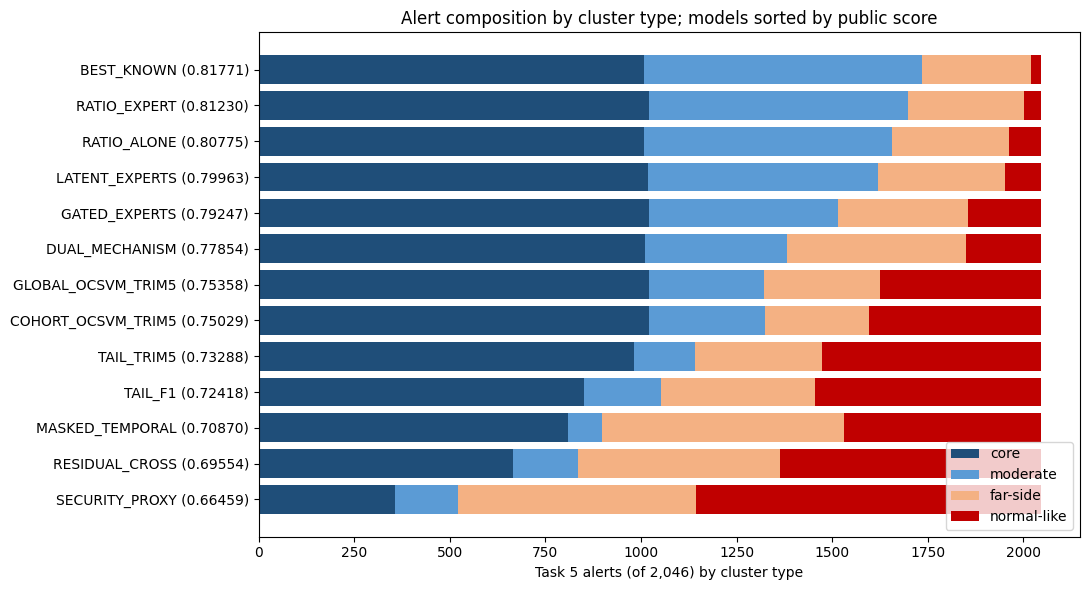

In [303]:
ordered = type_counts.sort_values("public_score").index
fig, ax = plt.subplots(figsize=(11, 6))
left = np.zeros(len(ordered))
for kind, color in (("core", "#1f4e79"), ("moderate", "#5b9bd5"), ("far-side", "#f4b183"), ("normal-like", "#c00000")):
    ax.barh(range(len(ordered)), type_counts.loc[ordered, kind], left=left, color=color, label=kind)
    left += type_counts.loc[ordered, kind].to_numpy()
ax.set_yticks(range(len(ordered)), labels=[f"{name} ({public_results[name]:.5f})" for name in ordered])
ax.set_xlabel("Task 5 alerts (of 2,046) by cluster type")
ax.set_title("Alert composition by cluster type; models sorted by public score")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

#### 24.3.2 Proximity Between Clusters

In [304]:
centroids = np.vstack([cluster_X[cluster_labels == cluster].mean(axis=0) for cluster in range(CLUSTER_K)])
centroid_distance = np.sqrt(((centroids[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
show(pd.DataFrame([{"cluster": f"c{cluster} {cluster_desc[cluster]}", "type": cluster_types[cluster],
                    "nearest": f"c{int(np.argsort(centroid_distance[cluster])[1])} {cluster_desc[int(np.argsort(centroid_distance[cluster])[1])]}",
                    "distance": centroid_distance[cluster, np.argsort(centroid_distance[cluster])[1]]} for cluster in range(CLUSTER_K)]), digits=2)
merge_names = {cluster: f"c{cluster}" for cluster in range(CLUSTER_K)}
for step, (left_id, right_id, height, _) in enumerate(linkage(centroids, method="ward")):
    merge_names[CLUSTER_K + step] = f"({merge_names[int(left_id)]}+{merge_names[int(right_id)]})"
    if step >= CLUSTER_K - 5:
        print(f"Ward merge {step + 1}: {merge_names[int(left_id)]} + {merge_names[int(right_id)]} at {height:.2f}")

                                                cluster        type                                              nearest  distance
 c0 currency_transfers P4 / play_pattern_consistency P4        core c12 session_duration_mean / session_duration_mean P4      5.78
c1 communication_frequency P4 / communication_frequency normal-like       c4 currency_transfers / login_time_variance P4      3.01
                  c2 friend_removes P4 / friend_removes    far-side              c16 location_changes / skill_trajectory      3.04
          c3 purchase_frequency / purchase_frequency P4    far-side       c4 currency_transfers / login_time_variance P4      3.07
         c4 currency_transfers / login_time_variance P4 normal-like              c16 location_changes / skill_trajectory      2.89
              c5 skill_trajectory P4 / skill_trajectory        core          c6 reaction_time_std / reaction_time_std P4      8.03
            c6 reaction_time_std / reaction_time_std P4 normal-like              c1

#### 24.3.3 Depth Inside the Mechanism Clusters

In [305]:
show(type_counts.loc[["RATIO_EXPERT", "BEST_KNOWN"], ["core", "moderate", "far-side", "normal-like"]].T.assign(
    best_known_minus_RE=lambda frame: frame.BEST_KNOWN - frame.RATIO_EXPERT))
disagreement = bk_alerts ^ re_alerts
disagreement_X = cluster_X[disagreement]
best_k, best_value = max(((k, silhouette_score(disagreement_X, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(disagreement_X).labels_))
                          for k in range(2, 9)), key=lambda item: item[1])
disagreement_groups = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(disagreement_X).labels_
disagreement_index = np.flatnonzero(disagreement)
print(f"Disagreement set: {int(disagreement.sum())} players | best silhouette k = {best_k} ({best_value:.3f})")
group_rows = []
for group in range(best_k):
    member = np.zeros(len(player_ids), dtype=bool); member[disagreement_index[disagreement_groups == group]] = True
    shift = cluster_X[member].mean(axis=0) - cluster_X.mean(axis=0)
    top = np.argsort(-np.abs(shift))[:4]
    group_rows.append({"group": group, "players": int(member.sum()), "best_known_only": int((member & bk_alerts).sum()),
                       "RATIO_EXPERT_only": int((member & re_alerts).sum()),
                       "profile": ", ".join(f"{cluster_names[i].replace('__lvl', '').replace('__jmp', ' P4')} {shift[i]:+.2f}" for i in top)})
show(pd.DataFrame(group_rows))

             RATIO_EXPERT  BEST_KNOWN  best_known_minus_RE
core                 1020        1009                  -11
moderate              679         727                   48
far-side              304         283                  -21
normal-like            43          27                  -16


Disagreement set: 224 players | best silhouette k = 4 (0.041)
 group  players  best_known_only  RATIO_EXPERT_only                                                                                                             profile
     0       47               14                 33                purchase_frequency +0.88, purchase_frequency P4 -0.71, accuracy_std -0.51, login_time_variance +0.50
     1       29                5                 24 session_duration_mean P4 -1.40, currency_transfers +1.40, skill_trajectory P4 -0.93, play_pattern_consistency -0.81
     2       65               52                 13                       behavior_stability -2.21, purchase_frequency +0.89, account_age_days +0.69, login_count -0.65
     3       83               41                 42                         accuracy_std +1.67, kda_std +1.58, performance_stability +0.87, session_duration_mean -0.30


Within a cluster, a player's *depth* is its projection on the direction from the overall mean to the cluster centroid. The figure shows how often each file flags members of the three moderate clusters at each depth decile, and the table shows how many alerts every model places in each mechanism cluster, which reveals where adding more stops helping (saturation).

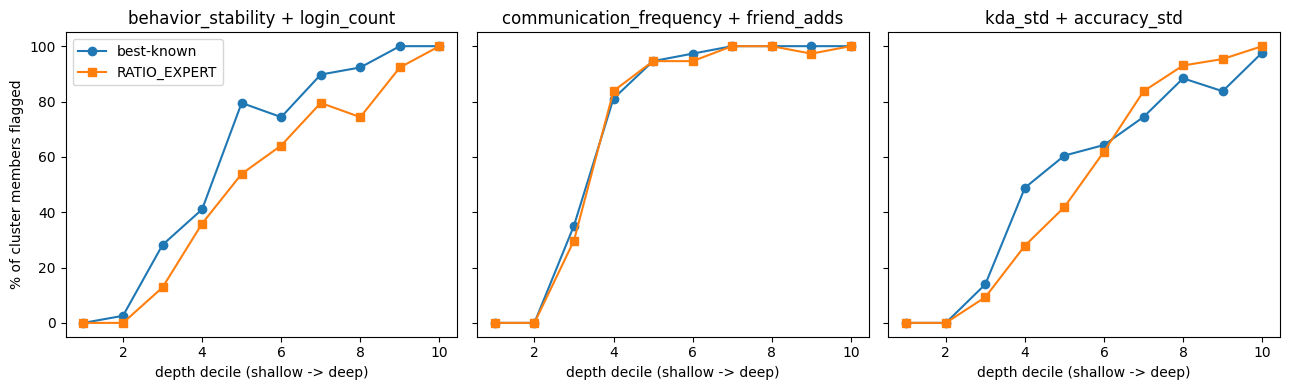

                    c0 currency_transfers P [core]  c2 friend_removes P4 [far-side]  c3 purchase_frequency [far-side]  c5 skill_trajectory P4 [core]  c7 behavior_stability [moderate]  c8 currency_transfers P [far-side]  c10 purchase_amount_mean [far-side]  c11 activity_level [far-side]  c13 communication_freque [moderate]  c14 location_changes P4 [far-side]  c15 kda_std [moderate]  c17 purchase_frequency P [core]  c19 ip_hash_entropy [core]
BEST_KNOWN                                     292                                8                                 8                            310                               237                                   1                                    5                            257                                  262                                   4                     228                              200                         207
RATIO_EXPERT                                   304                                9                           

In [306]:
def cluster_depth(cluster):
    direction = cluster_X[cluster_labels == cluster].mean(axis=0) - cluster_X.mean(axis=0)
    return cluster_X @ (direction / np.linalg.norm(direction))


moderate_clusters = [cluster for cluster in range(CLUSTER_K) if cluster_types[cluster] == "moderate"]
fig, axes = plt.subplots(1, len(moderate_clusters), figsize=(13, 4), sharey=True)
for ax, cluster in zip(np.atleast_1d(axes), moderate_clusters):
    depth = cluster_depth(cluster)
    member = np.flatnonzero(cluster_labels == cluster)
    decile = pd.qcut(depth[member], 10, labels=False)
    for name, alerts, style in (("best-known", bk_alerts, "-o"), ("RATIO_EXPERT", re_alerts, "-s")):
        ax.plot(range(1, 11), [100 * alerts[member[decile == d]].mean() for d in range(10)], style, label=name)
    ax.set_title(cluster_desc[cluster].replace(" / ", " + "))
    ax.set_xlabel("depth decile (shallow -> deep)")
np.atleast_1d(axes)[0].set_ylabel("% of cluster members flagged")
np.atleast_1d(axes)[0].legend()
fig.tight_layout()
plt.show()
mechanism_clusters = [cluster for cluster in range(CLUSTER_K) if cluster_types[cluster] != "normal-like"]
saturation = pd.DataFrame({f"c{cluster} {cluster_desc[cluster].split(' / ')[0][:20]} [{cluster_types[cluster]}]":
                           [int((alerts & (cluster_labels == cluster)).sum()) for alerts in distinct_models.values()]
                           for cluster in mechanism_clusters}, index=list(distinct_models))
show(saturation)
weak_clusters = [cluster for cluster in range(CLUSTER_K) if cluster_types[cluster] == "normal-like"
                 or (cluster_types[cluster] == "far-side" and (re_alerts & (cluster_labels == cluster)).sum() < 100)]
weak_re = re_alerts & np.isin(cluster_labels, weak_clusters)
print(f"RATIO_EXPERT alerts in normal-like or small far-side clusters: {int(weak_re.sum())} | best-known flags {100 * (weak_re & bk_alerts).sum() / weak_re.sum():.0f}% | "
      "nominated by: " + ", ".join(f"{label} {int((weak_re & mask).sum())}" for label, mask in (("ratio population", ratio_population), ("latent", latent_population),
                                                                                               ("far sides", far_side_population), ("joint jumps", joint_jump))))

### 24.4 Submission and Result

Five cluster-level candidates are built with explicit rules; no individual player is chosen by hand. *Weak clusters* are the normal-like clusters plus the far-side clusters that RATIO_EXPERT barely uses (fewer than 100 alerts); the large far-side cluster (quiet activity) stays a mechanism. Depth ranks players inside a cluster.

- **RE_NORMAL_TO_SELLING**: a single change. RATIO_EXPERT's alerts in normal-like clusters are replaced by the deepest unflagged members of the account-selling cluster.
- **RE_MOVE_C7C15**: RATIO_EXPERT's alerts in normal-like clusters and its weakly supported (support ≤ 1) alerts in small far-side clusters are replaced, alternately, by the deepest account-selling and erratic members (the two moderate clusters that are not saturated).
- **RE_MOVE_DEPTH**: the same removals, refilled from all moderate clusters by depth.
- **BK_MOVE** and **CLUSTER_UNION**: control candidates that apply the same cluster rules to the base submission and to its union with RATIO_EXPERT.

In [307]:
in_clusters = lambda clusters: np.isin(cluster_labels, clusters)
normal_clusters = [cluster for cluster in range(CLUSTER_K) if cluster_types[cluster] == "normal-like"]
small_far = [cluster for cluster in range(CLUSTER_K) if cluster_types[cluster] == "far-side" and (re_alerts & (cluster_labels == cluster)).sum() < 100]
large_far = [cluster for cluster in range(CLUSTER_K) if cluster_types[cluster] == "far-side" and cluster not in small_far]
core_clusters = [cluster for cluster in range(CLUSTER_K) if cluster_types[cluster] == "core"]
selling_cluster = next(cluster for cluster in range(CLUSTER_K) if cluster_desc[cluster].startswith("behavior_stability"))
erratic_cluster = next(cluster for cluster in range(CLUSTER_K) if cluster_desc[cluster].startswith("kda_std"))
votes = np.sum([alerts for name, alerts in distinct_models.items() if name not in ("BEST_KNOWN", "RATIO_EXPERT")], axis=0)
ratio_percentile = pd.Series(ratio_score).rank(pct=True).to_numpy()


def refill(base, drop, ranked):
    out = base & ~drop
    picks = [index for index in ranked if not out[index]][:SUBMISSION_ALERTS - int(out.sum())]
    out[picks] = True
    assert int(out.sum()) == SUBMISSION_ALERTS
    return out


def deepest(cluster, exclude):
    depth = cluster_depth(cluster)
    candidates = np.flatnonzero((cluster_labels == cluster) & ~exclude)
    return list(candidates[np.argsort(-depth[candidates], kind="stable")])


moderate_depth = np.full(len(player_ids), -np.inf)
for cluster in moderate_clusters:
    depth = cluster_depth(cluster)
    moderate_depth[cluster_labels == cluster] = depth[cluster_labels == cluster]
moderate_rank = np.argsort(-moderate_depth, kind="stable")
moderate_rank = moderate_rank[np.isfinite(moderate_depth[moderate_rank])]
weak_drop = lambda alerts: alerts & (in_clusters(normal_clusters) | (in_clusters(small_far) & (support <= 1)))

kept = re_alerts & ~in_clusters(normal_clusters)
candidate_alerts["RE_NORMAL_TO_SELLING"] = refill(re_alerts, re_alerts & in_clusters(normal_clusters), deepest(selling_cluster, kept))
kept = re_alerts & ~weak_drop(re_alerts)
queues, picks, turn = [deepest(selling_cluster, kept), deepest(erratic_cluster, kept)], [], 0
while len(picks) < SUBMISSION_ALERTS - int(kept.sum()):
    if queues[turn % 2]:
        picks.append(queues[turn % 2].pop(0))
    turn += 1
candidate_alerts["RE_MOVE_C7C15"] = refill(re_alerts, weak_drop(re_alerts), picks)
candidate_alerts["RE_MOVE_DEPTH"] = refill(re_alerts, weak_drop(re_alerts), moderate_rank)
re_extra = np.flatnonzero(re_alerts & ~bk_alerts & in_clusters(core_clusters + moderate_clusters + large_far))
re_extra = re_extra[np.argsort(-(votes[re_extra] + ratio_percentile[re_extra]), kind="stable")]
candidate_alerts["BK_MOVE"] = refill(bk_alerts, weak_drop(bk_alerts), list(re_extra) + list(moderate_rank))
union_base = (((re_alerts | bk_alerts) & in_clusters(core_clusters + moderate_clusters + large_far))
              | ((re_alerts & bk_alerts) & in_clusters(normal_clusters + small_far)))
candidate_alerts["CLUSTER_UNION"] = alerts_from_scores(votes + ratio_percentile + 20.0 * union_base)
cluster_candidates = ["RE_NORMAL_TO_SELLING", "RE_MOVE_C7C15", "RE_MOVE_DEPTH", "BK_MOVE", "CLUSTER_UNION"]
predicted = lambda alerts: type_coef[0] + sum(type_coef[i + 1] * int((alerts & (player_type == kind)).sum())
                                              for i, kind in enumerate(("moderate", "far-side", "normal-like")))
show(pd.DataFrame([{"candidate": name, "swaps_vs_RATIO_EXPERT": int((candidate_alerts[name] & ~re_alerts).sum()),
                    "swaps_vs_best_known": int((candidate_alerts[name] & ~bk_alerts).sum()),
                    **{kind: int((candidate_alerts[name] & (player_type == kind)).sum()) for kind in ("core", "moderate", "far-side", "normal-like")},
                    "type_model_prediction": predicted(candidate_alerts[name])} for name in cluster_candidates]), digits=5)
show(reference_panel_table(["RATIO_EXPERT"] + cluster_candidates))

           candidate  swaps_vs_RATIO_EXPERT  swaps_vs_best_known  core  moderate  far-side  normal-like  type_model_prediction
RE_NORMAL_TO_SELLING                     43                   99  1020       722       304            0                0.82029
       RE_MOVE_C7C15                     84                   94  1020       763       263            0                0.82430
       RE_MOVE_DEPTH                     84                   96  1020       763       263            0                0.82430
             BK_MOVE                     87                   48  1023       760       263            0                0.82424
       CLUSTER_UNION                     61                   51  1023       737       272           14                0.82119
           candidate  best-known (closeness)  TAIL_F1 (original)  OCSVM_F0 (original)  COHORT_OCSVM_TRIM5 (group SVM)
        RATIO_EXPERT                    1934                1034                 1311                            1295
RE

Two candidates were submitted. **RE_NORMAL_TO_SELLING** is the cleanest test of the main finding on our own model: a single change of **43** alerts. **BK_MOVE** was submitted as the control. The other three candidates combine more changes and were kept for later.

#### 24.4.1 Export and Format Check

In [308]:
cluster_card = {"cluster_space": "k-means k=20 (seed 42) on the 7,609-player union of 13 distinct models; mid-rank normal scores of 29 family levels and 27 P4 jumps plus 4 security flags",
                "cluster_types": "core = real/null >= 1.5 against a block-shuffled null; moderate = 1.05-1.5; far-side = dominant family on a Round-12 anomalous side; normal-like = the rest"}
cluster_exports = [
    ("kaggle_t1234_peer_t5_cluster_normal_to_selling_v1_20261124", "RE_NORMAL_TO_SELLING", {"candidate": "RE_NORMAL_TO_SELLING", "model": "single change from RATIO_EXPERT: its alerts in the seven normal-like single-family clusters (k=20 pool clustering, real/null < 1.05, not an anomalous far side) are replaced by the deepest non-alerted members of the account-selling cluster along its direction; no best-known input"}),
    ("kaggle_t1234_peer_t5_cluster_move_c7c15_v1_20261124", "RE_MOVE_C7C15", {"candidate": "RE_MOVE_C7C15", "model": "RATIO_EXPERT minus alerts in normal-like and weak single far-side clusters (k=20 pool clustering); refilled alternately with the deepest non-alerted members of the account-selling and erratic clusters only (the two moderate clusters that are not saturated); no best-known input"}),
    ("kaggle_t1234_peer_t5_cluster_move_re_v1_20261124", "RE_MOVE_DEPTH", {"candidate": "RE_MOVE_DEPTH", "model": "RATIO_EXPERT minus alerts in normal-like clusters and weak (support <= 1) single far-side clusters; refilled with the deepest members of the moderate clusters (account selling, social, erratic) along each cluster's direction; no best-known input", **cluster_card}),
    ("kaggle_t1234_peer_t5_cluster_move_bk_v1_20261124", "BK_MOVE", {"candidate": "BK_MOVE", "model": "best-known (teammate) file minus its alerts in normal-like and weak single far-side clusters; refilled with RATIO_EXPERT core/moderate/quiet alerts it lacks, then the deepest moderate-cluster members", **cluster_card}),
    ("kaggle_t1234_peer_t5_cluster_union_v1_20261124", "CLUSTER_UNION", {"candidate": "CLUSTER_UNION", "model": "union of RATIO_EXPERT and best-known inside mechanism clusters, intersection inside normal-like and single far-side clusters; ranked by votes of the other 11 distinct models plus ratio percentile", **cluster_card}),
]
print(pd.DataFrame([export_or_verify(file_name, candidate_alerts[key], card) for file_name, key, card in cluster_exports]).to_string(index=False))

                                                          file                 status  rows  alerts           sha256
kaggle_t1234_peer_t5_cluster_normal_to_selling_v1_20261124.csv existing file verified 25889    2046 7d4880b85919488a
       kaggle_t1234_peer_t5_cluster_move_c7c15_v1_20261124.csv existing file verified 25889    2046 d1c9e7be8f6dcd0f
          kaggle_t1234_peer_t5_cluster_move_re_v1_20261124.csv existing file verified 25889    2046 903a3001eea7e67b
          kaggle_t1234_peer_t5_cluster_move_bk_v1_20261124.csv existing file verified 25889    2046 07c1027eef7f4498
            kaggle_t1234_peer_t5_cluster_union_v1_20261124.csv existing file verified 25889    2046 dc7fbe89a0ee77c1


#### 24.4.2 Public Result

In [309]:
public_results["RE_NORMAL_TO_SELLING"] = 0.81346
public_results["BK_MOVE"] = 0.81713
print(f"RE_NORMAL_TO_SELLING public overall score: {public_results['RE_NORMAL_TO_SELLING']:.5f} | "
      f"vs RATIO_EXPERT: {public_results['RE_NORMAL_TO_SELLING'] - public_results['RATIO_EXPERT']:+.5f} | "
      f"type-model prediction {predicted(candidate_alerts['RE_NORMAL_TO_SELLING']):.5f}")
print(f"BK_MOVE public overall score: {public_results['BK_MOVE']:.5f} | vs best-known: {public_results['BK_MOVE'] - public_results['BEST_KNOWN']:+.5f} | "
      f"type-model prediction {predicted(candidate_alerts['BK_MOVE']):.5f}")

RE_NORMAL_TO_SELLING public overall score: 0.81346 | vs RATIO_EXPERT: +0.00116 | type-model prediction 0.82029
BK_MOVE public overall score: 0.81713 | vs best-known: -0.00058 | type-model prediction 0.82424


#### 24.4.3 Post-Result Error Analysis

The single change helped RATIO_EXPERT. Compare what the move removed: the cluster breakdown and the expert support of the players taken out.

In [310]:
post_rows = []
for name, base_name, base in (("RE_NORMAL_TO_SELLING", "RATIO_EXPERT", re_alerts), ("BK_MOVE", "BEST_KNOWN", bk_alerts)):
    added, removed = candidate_alerts[name] & ~base, base & ~candidate_alerts[name]
    for label, mask in (("added", added), ("removed", removed)):
        post_rows.append({"move": f"{name} vs {base_name}", "group": label, "players": int(mask.sum()),
                          **{kind: int((mask & (player_type == kind)).sum()) for kind in ("core", "moderate", "far-side", "normal-like")},
                          "mean_support": support[mask].mean(), "mean_votes_of_11": votes[mask].mean(),
                          "ratio_percentile": ratio_percentile[mask].mean(),
                          "flagged_by_other_top_file_pct": 100 * (mask & (re_alerts if base_name == "BEST_KNOWN" else bk_alerts)).sum() / max(int(mask.sum()), 1)})
show(pd.DataFrame(post_rows), digits=2)

                                move   group  players  core  moderate  far-side  normal-like  mean_support  mean_votes_of_11  ratio_percentile  flagged_by_other_top_file_pct
RE_NORMAL_TO_SELLING vs RATIO_EXPERT   added       43     0        43         0            0          0.00              2.30              0.59                          62.79
RE_NORMAL_TO_SELLING vs RATIO_EXPERT removed       43     0         0         0           43          0.56              3.14              0.77                          32.56
               BK_MOVE vs BEST_KNOWN   added       48    14        33         1            0          1.10              4.19              0.76                         100.00
               BK_MOVE vs BEST_KNOWN removed       48     0         0        21           27          0.46              2.81              0.70                          47.92


### 24.5 Findings

- **There are only about three separated groups.**
  - Silhouette is **0.180** at k = 2 (Module B splits off), **0.085–0.092** at k = 3–4, and a flat **0.03–0.04** from k = 5 to 22.
  - HDBSCAN finds only two dense groups: Module B and one large blob.
  - The k = 20 map is used as a tessellation that separates the known mechanisms (seed ARI **0.40**).
- **The map separates core mechanisms, moderate mechanisms, and single-family excursions.**
  - Four core clusters (Module B, bot regularity, Module A takeover, purchase plus location jump) hold **2.0–155×** as many real players as the null.
  - Three moderate clusters (social, erratic, account selling) hold **1.13–1.25×**.
  - The rest are the quiet far side, five small far-side clusters, and seven normal-like single-family excursions.
  - The core clusters are far from everything (nearest centroid **5.8–8.0**). The moderate clusters border single-family excursions: account selling is closest to the high-purchase-frequency cluster (distance **3.36**). This is why the last slots are hard to fill.
- **Cluster types explain public scores.**
  - Every model from GLOBAL_OCSVM up already holds about **1,010–1,020** core players.
  - Relative to core, 100 alerts in moderate clusters are worth **+0.0019**, in far-side clusters **−0.0079**, and in normal-like clusters **−0.0136** (R² **0.996**).
  - The normal-like effect stays strongly negative for k = 12–30 with both seeds.
- **Where RATIO_EXPERT can still move.** Its **89** weak-cluster alerts come mostly from the edge of the ratio population (**56**).
- **Account selling and erratic play are not saturated; quiet and social are.**
  - The top models agree on about **257–262** quiet and social players, and DUAL's larger counts scored lower.
  - Account-selling counts rise with score: RATIO_EXPERT **200**, LATENT **161**, GATED **106**.
- **Result: the move raised the score.** RE_NORMAL_TO_SELLING scored **0.81346**, **+0.00116** over RATIO_EXPERT and the best result of this notebook. The 43 players it removed (support **0.56**) were weaker than the account-selling members that replaced them.

**What we learned.** The last gains come from moving alerts out of single-family excursions and into the moderate mechanisms that are not yet full. Section 25.3 turns this into a reproducible rule for future work.

## 25. Final Summary

### 25.1 Results Summary

Collect every full-file candidate in round order: whether it was submitted, its public overall score, and how many of its 2,046 alerts it shares with each panel model. All scores are overall five-task scores with the same Tasks 1–4, so their differences come only from Task 5.

In [311]:
candidate_round = {"TAIL_F1": 3, "OCSVM_F0": 3, "MASKED_TEMPORAL": 4, "SECURITY_PROXY": 5, "TAIL_TRIM1": 6,
                   "TAIL_TRIM5": 6, "TAIL_OBSERVED_TRIM5": 7, "COHORT_OCSVM_TRIM5": 8,
                   "RESIDUAL_ALL": 9, "RESIDUAL_CROSS": 9, "COHORT_JOINT": 10, "GLOBAL_OCSVM_TRIM5": 11, "DUAL_MECHANISM": 12, "GATED_EXPERTS": 13, "LATENT_EXPERTS": 14,
                   "RATIO_EXPERT": 15, "RATIO_ALONE": 15, "RATIO_EXPERT_K2600": 16, "RATIO_EXPERT_NOFLAG": 16,
                   "COHORT_CONDITIONAL_RATIO": 17, "RE_NORMAL_TO_SELLING": 18, "RE_MOVE_C7C15": 18, "RE_MOVE_DEPTH": 18,
                   "BK_MOVE": 18, "CLUSTER_UNION": 18}
summary_rows = []
for name, alerts in candidate_alerts.items():
    score = public_results.get(name, np.nan)
    summary_rows.append({"round": candidate_round[name], "candidate": name, "alerts": int(alerts.sum()), "submitted": name in public_results,
                         "public_overall_score": score, "gap_to_best_known": score - public_results["BEST_KNOWN"],
                         "shared_with_best_known": int((alerts & best_known_alerts).sum()) if best_known_alerts is not None else np.nan,
                         **{f"shared_with_{reference}": int((alerts & candidate_alerts[reference]).sum())
                            for reference in ("TAIL_F1", "OCSVM_F0", "COHORT_OCSVM_TRIM5")}})
results_summary = pd.DataFrame(summary_rows)
show(results_summary, digits=5)

 round                candidate  alerts  submitted  public_overall_score  gap_to_best_known  shared_with_best_known  shared_with_TAIL_F1  shared_with_OCSVM_F0  shared_with_COHORT_OCSVM_TRIM5
     3                  TAIL_F1    2046       True               0.72418           -0.09353                    1027                 2046                  1057                            1054
     3                 OCSVM_F0    2046      False                   NaN                NaN                    1316                 1057                  2046                            1885
     4          MASKED_TEMPORAL    2046       True               0.70870           -0.10901                     872                  853                   948                             950
     5           SECURITY_PROXY    2046       True               0.66459           -0.15312                     406                  341                   420                             416
     6               TAIL_TRIM1    2046      

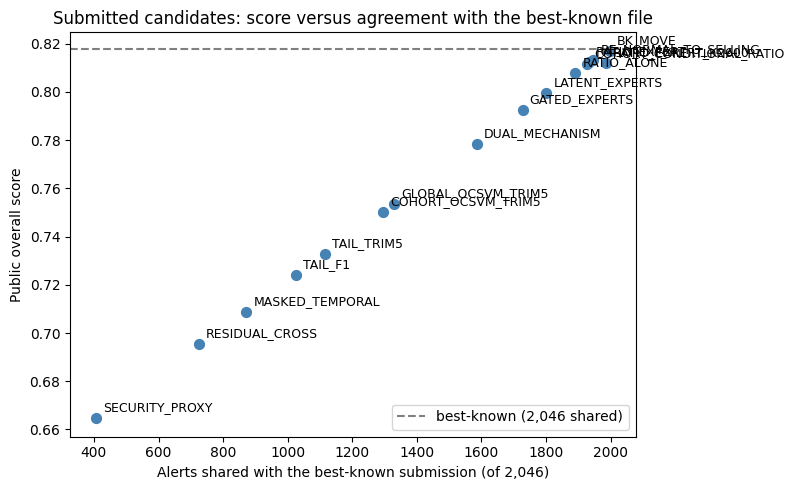

In [312]:
if best_known_alerts is not None:
    submitted = results_summary[results_summary.submitted]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(submitted.shared_with_best_known, submitted.public_overall_score, color="steelblue", s=50)
    for row in submitted.itertuples():
        ax.annotate(row.candidate, (row.shared_with_best_known, row.public_overall_score),
                    textcoords="offset points", xytext=(5, 5), fontsize=9)
    ax.axhline(public_results["BEST_KNOWN"], color="gray", linestyle="--", label="best-known (2,046 shared)")
    ax.set_xlabel("Alerts shared with the best-known submission (of 2,046)")
    ax.set_ylabel("Public overall score")
    ax.set_title("Submitted candidates: score versus agreement with the best-known file")
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()

Compare the candidates with each other directly. Each cell counts the alerts two candidates share (out of 2,046), so related ideas form visible blocks and isolated ideas stand apart. The budget test (2,600 alerts) is left out of this view.

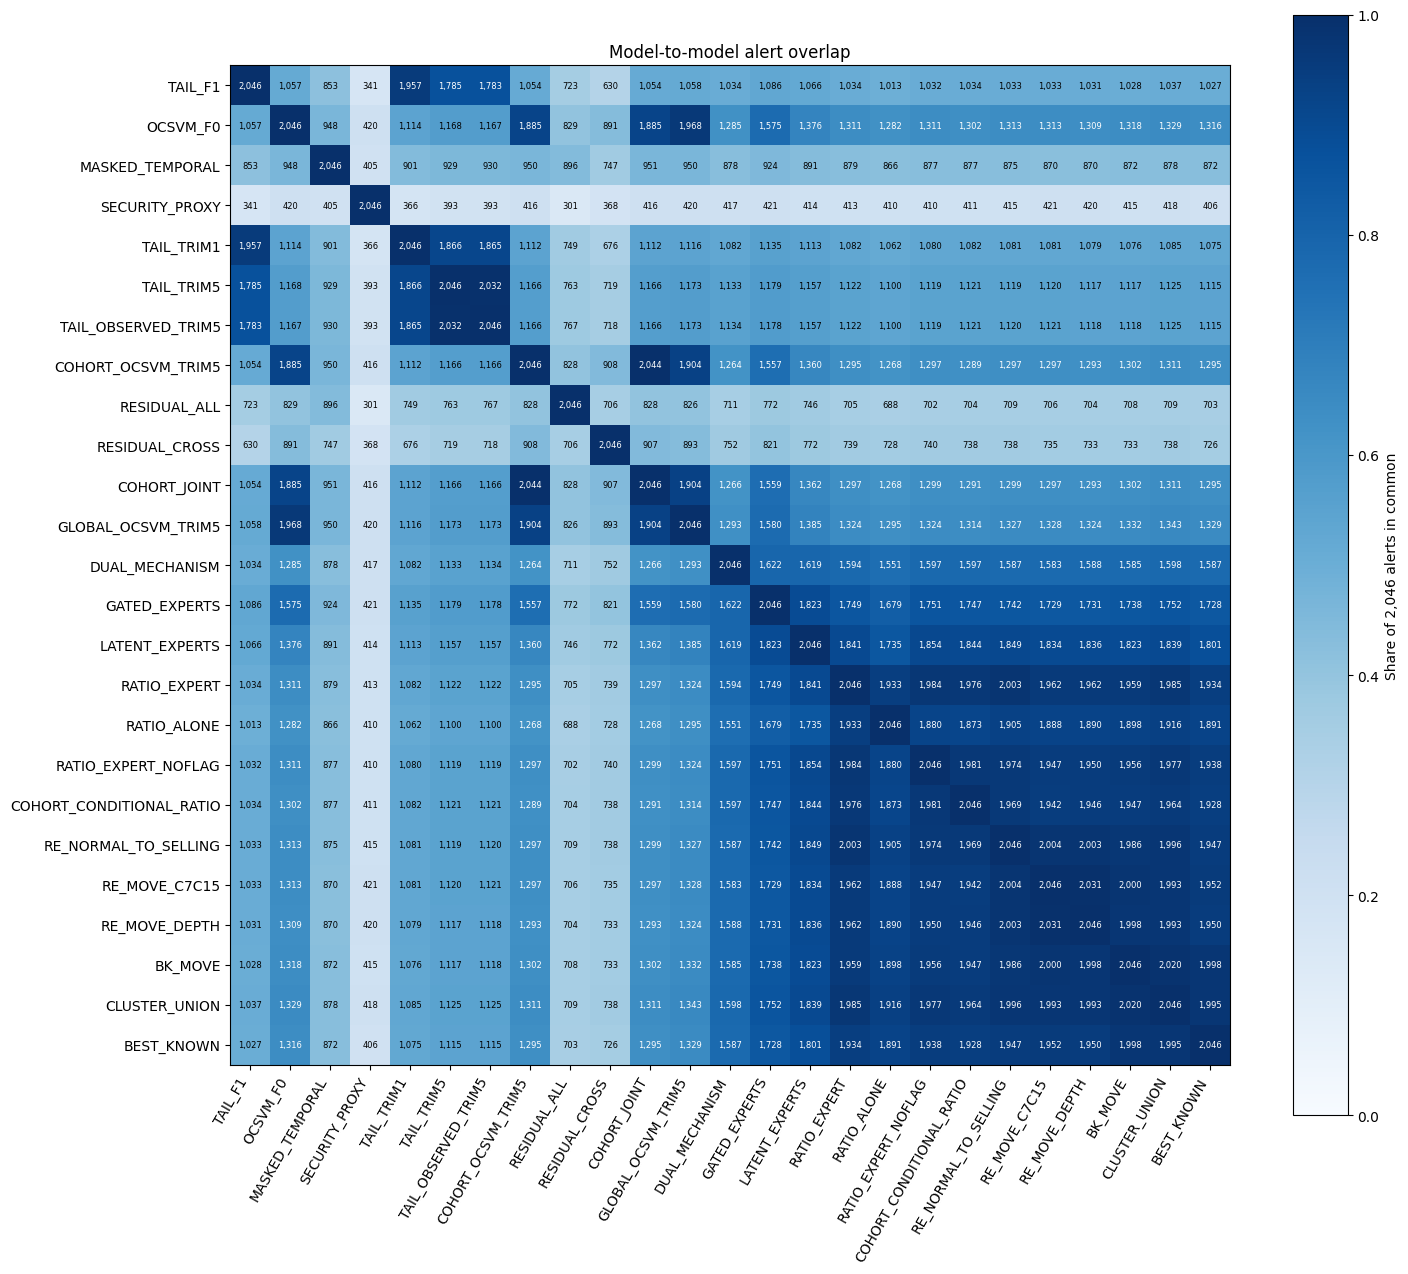

In [313]:
overlap_names = [name for name, alerts in candidate_alerts.items() if int(alerts.sum()) == SUBMISSION_ALERTS] + (["BEST_KNOWN"] if best_known_alerts is not None else [])
overlap_sets = {**candidate_alerts, "BEST_KNOWN": best_known_alerts}
overlap_matrix = pd.DataFrame([[int((overlap_sets[left] & overlap_sets[right]).sum()) for right in overlap_names]
                               for left in overlap_names], index=overlap_names, columns=overlap_names)
fig, ax = plt.subplots(figsize=(15, 13))
image = ax.imshow(overlap_matrix / SUBMISSION_ALERTS, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(overlap_names)), labels=overlap_names, rotation=60, ha="right")
ax.set_yticks(range(len(overlap_names)), labels=overlap_names)
for row in range(len(overlap_names)):
    for column in range(len(overlap_names)):
        value = overlap_matrix.iloc[row, column]
        ax.text(column, row, f"{value:,}", ha="center", va="center", fontsize=6,
                color="white" if value / SUBMISSION_ALERTS > 0.6 else "black")
fig.colorbar(image, ax=ax, label="Share of 2,046 alerts in common")
ax.set_title("Model-to-model alert overlap")
fig.tight_layout()
plt.show()

### 25.2 Key Findings

**The experiment path.** Each row is what was tried, what happened, and what it told us to try next.

| Round | Tried | Public overall | What it told us |
| --- | --- | --- | --- |
| 1–2 | Isolation Forest on nine feature-set variants | not submitted | Temporal change features decide what is flagged; security and quality flags change only the margin. |
| 3 | Four detector families; Empirical Tail submitted | 0.72418 | The edge is the right place, but it mixes anomalies with extreme normal players and misses non-extreme anomalies. |
| 4 | Masked cross-period model | 0.70870 | Breaking one's own history is mostly normal; good prediction accuracy is not good detection. |
| 5 | Predicting security events from behavior | 0.66459 | Events matter only together with extreme behavior; flags are context, not labels. |
| 6 | Trim the top 5% from the Tail reference | 0.73288 | Extreme players inside the fitted reference distort what "normal" means. |
| 7 | Missing-aware Tail | not submitted (14 swaps) | Imputation is not the problem. |
| 8 | Cohort One-Class SVM with the same trim | 0.75029 | A smooth boundary drops extreme-but-normal players. |
| 9 | Predicting each feature from the others | not submitted | Behavior families are independent; the only dependence is joint Period-4 jumps. |
| 10 | Scoring joint jumps directly | not submitted (2 swaps) | Joint jumps are already caught; the gap is quiet, low-engagement players. |
| 11 | Residual direction; global One-Class SVM | 0.69554; 0.75358 | Removing normal extremes is not enough; the cohort split slightly hurt. |
| 12 | Second expert for one-sided low engagement | 0.77854 | Several mechanisms exist, and each needs its own expert. |
| 13 | Label-free mechanism discovery, gated allocation | 0.79247 | Size each expert by its own evidence, not by an equal share. |
| 14 | ICA latent directions | 0.79963 | Moderate coordinated shifts, such as account selling, are mechanisms too. |
| 15 | Real-versus-block-shuffled dependence ratio | 0.81230 | An anomaly is dependence beyond independence; one model sees most mechanisms. |
| 16 | Residual, takeover, and budget probes | 0.81219 (2,600 alerts) | No label-free signal is left outside the alerts, and the budget is not the limit. |
| 17 | Focused, fine-scale, matched-takeover, cohort-conditional models | 0.81143 | No missing mechanism; conditioning on cohorts removes real members. |
| 18 | Cluster map of all models; cluster-level moves | 0.81346 | Moving alerts from single-family excursions to account selling raises the score. |

**Key findings.**

1. **Detailed EDA set the direction.** The Period-4 jumps, the co-occurring tails, and the independence between families found in Section 3 became the core of the later models.
2. **An anomaly in this dataset is dependence beyond independence.**
   - Normal players' behavior families are almost independent (median |ρ| **0.005**). Every mechanism found is a group of families that move together, or a one-sided tail of a single family.
   - A classifier that separates real players from family-block-shuffled copies estimates this directly and sizes its own population with held-out shuffled rows. It gave the largest late gain: **0.79963 → 0.81230**.
3. **The mechanisms, found without labels:**
   - joint Period-4 jumps (two modules, one of them a takeover with password changes and mass item sales);
   - bot-like regularity;
   - a purchase-plus-location jump;
   - quiet low engagement;
   - social withdrawal with friend churn;
   - erratic performance;
   - account selling (older accounts with less stable play and more purchases).

   Only Module B, bot regularity and Module A are clearly separated groups; the rest form a continuum with ordinary single-family excursions (Round 18).
4. **Experts should nominate populations sized by their own evidence.** Gated allocation beat equal rank-max (Round 13), and each later mechanism entered the same way.
5. **What separates good models is the last ~1,000 alerts.** All good models hold the same core of about 1,010–1,020 players. Their scores follow how the rest is split between moderate mechanisms and single-family excursions (R² **0.996**), and every step up in the score history moved alerts out of excursions.
6. **The measurable signal is used up at this budget.**
   - No residual dependence, takeover discontinuity (random or matched donors), too-typical cluster, single-family event, cohort effect, cross-task link, or stealthy dose along a known direction exceeds its null outside the current alerts.
   - A larger budget did not help (Rounds 16–17).
7. **Extreme players inside a fitted reference distort the model.** Trimming the top 5% from the Tail reference and from One-Class SVM fitting raised the score (Rounds 6 and 11).
8. **Models that explain features from each other fail here.** Because families are independent, residual and masked-prediction models explain the mechanisms away (**0.69554**, **0.70870**).
9. **Studying the changed players guided every decision.** After each result, asking which players a candidate added and removed, and what they look like, explained the score better than internal metrics such as prediction accuracy (Round 4).
10. **Cluster-level moves improve the last slots.** Replacing RATIO_EXPERT's single-family alerts with account-selling members gave the best score of this notebook (**0.81346**).

The working method that emerged is the loop used in Rounds 3–18:
1. Form a hypothesis from the previous error analysis and the brief.
2. Check it with a label-free rule.
3. Compare the alert set with the reference panel and with earlier candidates.
4. Submit when it differs enough to test a new direction and its changed players make sense.
5. After the result, profile what is still missed.

### 25.3 Final Submission and Future Work

**Final Task 5 choice: RE_NORMAL_TO_SELLING (0.81346)**, RATIO_EXPERT plus one cluster-level move and the best result of this notebook. RATIO_EXPERT (**0.81230**) is the version built only from models, with no cluster move. Both files keep the same Tasks 1–4, so the choice changes only Task 5.

**Future work, in order of expected value.** Each item is a hypothesis for a new round.

- **A model-level version of the move.** Tighten the ratio population to a local FDR below 0.5, keep latent-only nominations only with a second support, and add an account-selling expert sized by the saturation evidence. This replaces the manual move with a reproducible rule.
- **Order the single-family clusters.** A density or reconstruction score restricted to the single-family clusters could decide which of their members deserve the last slots.
- **The shape of the erratic expert.** A wider, shallower erratic population is still open to test.